# 03 — 3D U-Net Model Development

## Project: Glioma MRI Segmentation Using Deep Learning

### Objectives

This notebook develops and tests a three-dimensional U-Net segmentation model using PyTorch and MONAI.

The model will receive four MRI modalities as input:

- T1-weighted (T1n)
- Contrast-enhanced T1-weighted (T1c)
- T2-weighted (T2w)
- T2-FLAIR (T2f)

The model will be configured to predict four segmentation-region channels:

- Whole tumour-associated region (WT)
- Tumour core (TC)
- Enhancing tumour (ET)
- Resection cavity (RC)

### Development workflow

1. Verify the computing environment.
2. Understand and configure the 3D U-Net architecture.
3. Initialise the model using MONAI.
4. Test the model using synthetic MRI tensors.
5. Verify input and output tensor dimensions.
6. Configure segmentation loss functions and evaluation metrics.
7. Prepare the model for training and validation.

**Current stage:** Model architecture development and functional testing. No model training has been performed.

In [1]:
# -------------------------------------------------------------
# SECTION 30.2 — VERIFY MODEL DEVELOPMENT ENVIRONMENT
# -------------------------------------------------------------
#
# Confirm that PyTorch, MONAI and CUDA are available.
#
# This cell does not load MRI data or train a model.
# GPU memory usage should be negligible.

import sys
import torch
import monai

print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("MONAI version:", monai.__version__)

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    gpu_properties = torch.cuda.get_device_properties(0)

    print(
        "GPU total memory:",
        round(gpu_properties.total_memory / (1024**3), 2),
        "GB"
    )

Python version: 3.11.16
PyTorch version: 2.14.1+cu130
MONAI version: 1.6.1

CUDA available: True
GPU: NVIDIA GeForce RTX 4080 SUPER
GPU total memory: 15.99 GB


## 30.3 — Understanding the 3D U-Net Architecture

![Conceptual 3D U-Net architecture](../outputs/figures/unet_architecture.png)

The 3D U-Net consists of three principal components:

1. **Encoder:** Extracts progressively higher-level features while reducing spatial resolution.
2. **Bottleneck:** Captures contextual information from a larger receptive field.
3. **Decoder:** Reconstructs the segmentation at the original spatial resolution, using skip connections to recover anatomical detail.

**Input:** Four MRI channels (T1, T1ce, T2, T2-FLAIR).

**Output:** Four segmentation channels (WT, TC, ET, RC).

The model will output segmentation logits, which can be converted to independent region probabilities using sigmoid activation.

In [2]:
# -------------------------------------------------------------
# SECTION 30.4 — DEFINE 3D U-NET CONFIGURATION
# -------------------------------------------------------------
#
# Define the architectural parameters before creating the model.
#
# This cell only stores configuration values.
# It does not allocate a model on the GPU or perform training.

spatial_dimensions = 3

# Four MRI input channels:
# T1, contrast-enhanced T1, T2, and T2-FLAIR.
input_channels = 4

# Four output segmentation regions:
# Whole tumour, tumour core, enhancing tumour, resection cavity.
output_channels = 4

# Feature channels at successive levels of the U-Net.
# Deeper layers learn more complex representations.
feature_channels = (16, 32, 64, 128, 256)

# Stride 2 progressively reduces spatial dimensions.
# Four downsampling stages connect the five feature levels.
downsampling_strides = (2, 2, 2, 2)

# Number of residual convolutional units per stage.
residual_units = 2

# Spatial dimensions of the training patches.
patch_size = (96, 96, 96)

print("Spatial dimensions:", spatial_dimensions)
print("Input MRI channels:", input_channels)
print("Output segmentation channels:", output_channels)
print("Feature channels:", feature_channels)
print("Downsampling strides:", downsampling_strides)
print("Residual units:", residual_units)
print("Training patch size:", patch_size)

Spatial dimensions: 3
Input MRI channels: 4
Output segmentation channels: 4
Feature channels: (16, 32, 64, 128, 256)
Downsampling strides: (2, 2, 2, 2)
Residual units: 2
Training patch size: (96, 96, 96)


In [3]:
# -------------------------------------------------------------
# SECTION 30.5 — INITIALISE THE 3D U-NET MODEL
# -------------------------------------------------------------
#
# Construct a 3D U-Net using MONAI.
#
# The model is initially stored on the CPU.
# No MRI data is loaded, and no training occurs in this cell.

from monai.networks.nets import UNet

model = UNet(
    spatial_dims=spatial_dimensions,
    in_channels=input_channels,
    out_channels=output_channels,
    channels=feature_channels,
    strides=downsampling_strides,
    num_res_units=residual_units,
)

# Count the number of trainable parameters.
# These are the weights and biases that will eventually be
# updated by the optimiser during training.
trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Model architecture: MONAI 3D U-Net")
print("Model device:", next(model.parameters()).device)
print(f"Trainable parameters: {trainable_parameters:,}")
print("Input channels:", input_channels)
print("Output channels:", output_channels)

Model architecture: MONAI 3D U-Net
Model device: cpu
Trainable parameters: 4,811,129
Input channels: 4
Output channels: 4


In [4]:
# -------------------------------------------------------------
# SECTION 30.5 — INITIALISE THE 3D U-NET MODEL
# -------------------------------------------------------------
#
# Construct a 3D U-Net using MONAI.
#
# The model is initially stored on the CPU.
# No MRI data is loaded, and no training occurs in this cell.

from monai.networks.nets import UNet

model = UNet(
    spatial_dims=spatial_dimensions,
    in_channels=input_channels,
    out_channels=output_channels,
    channels=feature_channels,
    strides=downsampling_strides,
    num_res_units=residual_units,
)

# Count the number of trainable parameters.
# These are the weights and biases that will eventually be
# updated by the optimiser during training.
trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Model architecture: MONAI 3D U-Net")
print("Model device:", next(model.parameters()).device)
print(f"Trainable parameters: {trainable_parameters:,}")
print("Input channels:", input_channels)
print("Output channels:", output_channels)

Model architecture: MONAI 3D U-Net
Model device: cpu
Trainable parameters: 4,811,129
Input channels: 4
Output channels: 4


In [5]:
# -------------------------------------------------------------
# SECTION 30.6 — TEST 3D U-NET FORWARD PASS
# -------------------------------------------------------------
#
# Generate a small synthetic MRI volume and pass it through
# the model to verify that its output dimensions are correct.
#
# This test runs on the CPU.
# It does not load patient data, use GPU memory, or train the model.

# Set the model to evaluation mode.
# This ensures evaluation behaviour for relevant layers.
model.eval()

# Generate one synthetic 3D MRI case with four input channels.
# Shape: (batch, channels, height, width, depth)
synthetic_input = torch.randn(
    1, input_channels, 32, 32, 32
)

# Disable gradient tracking to reduce memory consumption.
# We are testing inference, not training.
with torch.no_grad():
    synthetic_output = model(synthetic_input)

# Inspect input and output dimensions.
print("Input shape:", tuple(synthetic_input.shape))
print("Output shape:", tuple(synthetic_output.shape))

# Confirm that the output has the expected dimensions.
expected_shape = (1, output_channels, 32, 32, 32)

print(
    "Output shape correct:",
    tuple(synthetic_output.shape) == expected_shape
)

# Check that the output contains finite numerical values.
print(
    "All output values finite:",
    bool(torch.isfinite(synthetic_output).all())
)

# Examine the range of raw model outputs.
print("Minimum output:", synthetic_output.min().item())
print("Maximum output:", synthetic_output.max().item())

Input shape: (1, 4, 32, 32, 32)
Output shape: (1, 4, 32, 32, 32)
Output shape correct: True
All output values finite: True
Minimum output: -2.874169111251831
Maximum output: 6.368508815765381


In [6]:
# -------------------------------------------------------------
# SECTION 30.7 — CONVERT MODEL LOGITS INTO PROBABILITIES
# -------------------------------------------------------------
#
# The U-Net produces raw numerical outputs called logits.
# Apply sigmoid to convert these into values between 0 and 1.
#
# This cell reuses the synthetic forward-pass output.
# No additional model inference or training is performed.

# Convert logits into independent segmentation probabilities.
synthetic_probabilities = torch.sigmoid(synthetic_output)

# Inspect the resulting tensor.
print("Probability shape:", tuple(synthetic_probabilities.shape))

print(
    "Minimum probability:",
    synthetic_probabilities.min().item()
)

print(
    "Maximum probability:",
    synthetic_probabilities.max().item()
)

# Verify that every probability is within the valid range.
probabilities_valid = bool(
    (
        (synthetic_probabilities >= 0)
        & (synthetic_probabilities <= 1)
    ).all()
)

print("All probabilities between 0 and 1:", probabilities_valid)

# Inspect the four predicted region channels.
region_names = ["WT", "TC", "ET", "RC"]

for channel_index, region_name in enumerate(region_names):
    region_probabilities = synthetic_probabilities[
        0, channel_index
    ]

    print(
        f"{region_name}: "
        f"min={region_probabilities.min().item():.4f}, "
        f"max={region_probabilities.max().item():.4f}"
    )

Probability shape: (1, 4, 32, 32, 32)
Minimum probability: 0.053445346653461456
Maximum probability: 0.9982882142066956
All probabilities between 0 and 1: True
WT: min=0.1163, max=0.9944
TC: min=0.1167, max=0.9969
ET: min=0.0534, max=0.9967
RC: min=0.1052, max=0.9983


In [7]:
# -------------------------------------------------------------
# SECTION 30.8 — CONVERT PROBABILITIES INTO BINARY MASKS
# -------------------------------------------------------------
#
# Apply a threshold of 0.5 to each segmentation probability map.
#
# Each channel is thresholded independently because our
# segmentation regions are represented by separate binary masks.
#
# This is a functional test using synthetic data.
# No training or additional model inference is performed.

segmentation_threshold = 0.5

# Convert continuous probabilities into binary predictions.
# Values >= 0.5 become 1; values < 0.5 become 0.
synthetic_binary_masks = (
    synthetic_probabilities >= segmentation_threshold
).to(torch.uint8)

print("Binary mask shape:", tuple(synthetic_binary_masks.shape))
print("Binary mask dtype:", synthetic_binary_masks.dtype)

# Confirm that masks contain only 0 and 1.
print(
    "Unique mask values:",
    torch.unique(synthetic_binary_masks).tolist()
)

# Count positive voxels for each predicted region.
region_names = ["WT", "TC", "ET", "RC"]

for channel_index, region_name in enumerate(region_names):
    region_mask = synthetic_binary_masks[0, channel_index]

    positive_voxels = int(region_mask.sum().item())
    total_voxels = region_mask.numel()

    percentage = 100 * positive_voxels / total_voxels

    print(
        f"{region_name}: "
        f"{positive_voxels:,} / {total_voxels:,} voxels "
        f"({percentage:.2f}%)"
    )

Binary mask shape: (1, 4, 32, 32, 32)
Binary mask dtype: torch.uint8
Unique mask values: [0, 1]
WT: 18,815 / 32,768 voxels (57.42%)
TC: 17,042 / 32,768 voxels (52.01%)
ET: 16,656 / 32,768 voxels (50.83%)
RC: 22,454 / 32,768 voxels (68.52%)


In [8]:
# -------------------------------------------------------------
# SECTION 30.8 — CONVERT PROBABILITIES INTO BINARY MASKS
# -------------------------------------------------------------
#
# Apply a threshold of 0.5 to each segmentation probability map.
#
# Each channel is thresholded independently because our
# segmentation regions are represented by separate binary masks.
#
# This is a functional test using synthetic data.
# No training or additional model inference is performed.

segmentation_threshold = 0.5

# Convert continuous probabilities into binary predictions.
# Values >= 0.5 become 1; values < 0.5 become 0.
synthetic_binary_masks = (
    synthetic_probabilities >= segmentation_threshold
).to(torch.uint8)

print("Binary mask shape:", tuple(synthetic_binary_masks.shape))
print("Binary mask dtype:", synthetic_binary_masks.dtype)

# Confirm that masks contain only 0 and 1.
print(
    "Unique mask values:",
    torch.unique(synthetic_binary_masks).tolist()
)

# Count positive voxels for each predicted region.
region_names = ["WT", "TC", "ET", "RC"]

for channel_index, region_name in enumerate(region_names):
    region_mask = synthetic_binary_masks[0, channel_index]

    positive_voxels = int(region_mask.sum().item())
    total_voxels = region_mask.numel()

    percentage = 100 * positive_voxels / total_voxels

    print(
        f"{region_name}: "
        f"{positive_voxels:,} / {total_voxels:,} voxels "
        f"({percentage:.2f}%)"
    )

Binary mask shape: (1, 4, 32, 32, 32)
Binary mask dtype: torch.uint8
Unique mask values: [0, 1]
WT: 18,815 / 32,768 voxels (57.42%)
TC: 17,042 / 32,768 voxels (52.01%)
ET: 16,656 / 32,768 voxels (50.83%)
RC: 22,454 / 32,768 voxels (68.52%)


In [10]:
# -------------------------------------------------------------
# SECTION 30.9 — CONFIGURE SEGMENTATION LOSS FUNCTION
# -------------------------------------------------------------
#
# Define a combined Dice + Binary Cross-Entropy loss for
# multi-channel 3D segmentation.
#
# The four target channels represent WT, TC, ET and RC.
# Because these regions can overlap, sigmoid is used rather
# than softmax.
#
# The model supplies raw logits. DiceCELoss handles the
# required activation internally.

from monai.losses import DiceCELoss

segmentation_loss = DiceCELoss(
    include_background=True,
    to_onehot_y=False,
    sigmoid=True,
    softmax=False,
    squared_pred=False,
    smooth_nr=1e-5,
    smooth_dr=1e-5,
    lambda_dice=1.0,
    lambda_ce=1.0,
)

# -------------------------------------------------------------
# VERIFY LOSS FUNCTION CONFIGURATION
# -------------------------------------------------------------

print("Loss function:", type(segmentation_loss).__name__)

# The sigmoid setting belongs to the internal DiceLoss object.
print("Dice sigmoid enabled:", segmentation_loss.dice.sigmoid)

# Verify the relative weights of the two loss components.
print("Dice weight:", segmentation_loss.lambda_dice)
print("Cross-entropy weight:", segmentation_loss.lambda_ce)

Loss function: DiceCELoss
Dice sigmoid enabled: True
Dice weight: 1.0
Cross-entropy weight: 1.0


In [11]:
# -------------------------------------------------------------
# SECTION 30.10 — TEST SEGMENTATION LOSS FUNCTION
# -------------------------------------------------------------
#
# Verify that DiceCELoss can compare four-channel model logits
# against four-channel binary reference segmentation masks.
#
# This is a functional test using synthetic data.
# It does not measure real segmentation performance.

# Create synthetic binary reference masks with the same
# dimensions as the model's output.
#
# Shape: (batch, regions, height, width, depth)
synthetic_targets = (
    torch.rand_like(synthetic_output) > 0.8
).float()

# Calculate the combined Dice + BCE loss.
#
# The loss function expects:
#   predictions: raw logits
#   targets: binary values (0 or 1)
#
# We use no_grad because this is not a training step.
with torch.no_grad():
    test_loss = segmentation_loss(
        synthetic_output,
        synthetic_targets
    )

# Inspect the result.
print("Prediction shape:", tuple(synthetic_output.shape))
print("Target shape:", tuple(synthetic_targets.shape))

print("Target values:", torch.unique(synthetic_targets).tolist())

print("Combined Dice + BCE loss:", test_loss.item())

# Verify that the loss is a single finite numerical value.
print("Loss is scalar:", test_loss.ndim == 0)
print("Loss is finite:", bool(torch.isfinite(test_loss)))

Prediction shape: (1, 4, 32, 32, 32)
Target shape: (1, 4, 32, 32, 32)
Target values: [0.0, 1.0]
Combined Dice + BCE loss: 2.001699209213257
Loss is scalar: True
Loss is finite: True


In [12]:
# -------------------------------------------------------------
# SECTION 30.11 — VERIFY GRADIENT COMPUTATION
# -------------------------------------------------------------
#
# Test whether gradients can propagate through the 3D U-Net
# using our combined Dice + BCE segmentation loss.
#
# This is a small CPU-only functional test.
# No real MRI data is loaded.
# No optimiser step is performed, so weights are not updated.

# Use training mode for the gradient test.
model.train()

# Clear any existing parameter gradients.
model.zero_grad(set_to_none=True)

# Create a small synthetic MRI input.
gradient_test_input = torch.randn(
    1, input_channels, 32, 32, 32
)

# Create matching binary reference masks.
gradient_test_targets = (
    torch.rand(
        1, output_channels, 32, 32, 32
    ) > 0.8
).float()

# Forward pass with gradient tracking enabled.
gradient_test_logits = model(gradient_test_input)

# Calculate segmentation loss.
gradient_test_loss = segmentation_loss(
    gradient_test_logits,
    gradient_test_targets
)

# Backpropagate the loss through the network.
gradient_test_loss.backward()

# Count parameters with successfully computed gradients.
parameters_with_gradients = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.grad is not None
)

# Check that all computed gradients contain finite values.
gradients_finite = all(
    bool(torch.isfinite(parameter.grad).all())
    for parameter in model.parameters()
    if parameter.grad is not None
)

print("Gradient test loss:", gradient_test_loss.item())

print(
    "Parameters with gradients:",
    f"{parameters_with_gradients:,}"
)

print(
    "Total trainable parameters:",
    f"{trainable_parameters:,}"
)

print(
    "All trainable parameters have gradients:",
    parameters_with_gradients == trainable_parameters
)

print("All computed gradients finite:", gradients_finite)

# Clear test gradients to avoid retaining unnecessary data.
model.zero_grad(set_to_none=True)

Gradient test loss: 1.9911434650421143
Parameters with gradients: 4,811,129
Total trainable parameters: 4,811,129
All trainable parameters have gradients: True
All computed gradients finite: True


In [13]:
# -------------------------------------------------------------
# SECTION 30.12 — CONFIGURE ADAMW OPTIMISER
# -------------------------------------------------------------
#
# AdamW will use gradients calculated during backpropagation
# to update the U-Net's trainable parameters.
#
# At this stage, we are only creating the optimiser.
# No parameter updates or training steps are performed.

import torch.optim as optim

# Initial training hyperparameters.
learning_rate = 1e-4
weight_decay = 1e-5

# Create the AdamW optimiser.
optimizer = optim.AdamW(
    model.parameters(),
    lr=learning_rate,
    weight_decay=weight_decay
)

# -------------------------------------------------------------
# VERIFY OPTIMISER CONFIGURATION
# -------------------------------------------------------------

print("Optimiser:", type(optimizer).__name__)

print(
    "Learning rate:",
    optimizer.param_groups[0]["lr"]
)

print(
    "Weight decay:",
    optimizer.param_groups[0]["weight_decay"]
)

# Confirm that the optimiser references the model's
# trainable parameters.
optimised_parameters = sum(
    parameter.numel()
    for group in optimizer.param_groups
    for parameter in group["params"]
    if parameter.requires_grad
)

print(
    "Parameters managed by optimiser:",
    f"{optimised_parameters:,}"
)

print(
    "Matches trainable parameter count:",
    optimised_parameters == trainable_parameters
)

Optimiser: AdamW
Learning rate: 0.0001
Weight decay: 1e-05
Parameters managed by optimiser: 4,811,129
Matches trainable parameter count: True


In [14]:
# -------------------------------------------------------------
# SECTION 30.13 — VERIFY A SINGLE OPTIMISER UPDATE
# -------------------------------------------------------------
#
# Test whether AdamW can update the U-Net parameters using
# gradients from the combined Dice + BCE segmentation loss.
#
# We create a separate model copy to preserve the original
# model and its optimiser.
#
# This is a single CPU training step using synthetic data.
# No real MRI cases are loaded.

import copy

# Create an independent copy of the original model.
test_model = copy.deepcopy(model)
test_model.train()

# Create a separate optimiser for the test model.
test_optimizer = torch.optim.AdamW(
    test_model.parameters(),
    lr=learning_rate,
    weight_decay=weight_decay
)

# Generate a small synthetic four-channel MRI volume.
test_input = torch.randn(
    1, input_channels, 32, 32, 32
)

# Generate matching synthetic binary segmentation targets.
test_targets = (
    torch.rand(
        1, output_channels, 32, 32, 32
    ) > 0.8
).float()

# Save a copy of one trainable parameter tensor before updating.
first_parameter = next(test_model.parameters())

weights_before = first_parameter.detach().clone()

# Step 1: Clear gradients from previous operations.
test_optimizer.zero_grad(set_to_none=True)

# Step 2: Forward propagation.
test_logits = test_model(test_input)

# Step 3: Calculate the segmentation loss.
test_loss = segmentation_loss(
    test_logits,
    test_targets
)

# Step 4: Calculate gradients.
test_loss.backward()

# Step 5: Update the model parameters.
test_optimizer.step()

# Compare parameter values before and after the update.
weights_after = first_parameter.detach()

maximum_weight_change = (
    weights_after - weights_before
).abs().max().item()

print("Training-step loss:", test_loss.item())
print("Maximum parameter change:", maximum_weight_change)

print(
    "Parameters successfully updated:",
    maximum_weight_change > 0
)

print(
    "Updated parameters remain finite:",
    bool(torch.isfinite(weights_after).all())
)

Training-step loss: 1.9977895021438599
Maximum parameter change: 0.00010000169277191162
Parameters successfully updated: True
Updated parameters remain finite: True


In [16]:
# -------------------------------------------------------------
# SECTION 30.14 — INSPECT ORIGINAL BRATS LABEL VALUES
# -------------------------------------------------------------
#
# Inspect one original BraTS segmentation file directly
# from the dataset directory.
#
# This avoids depending on variables defined in Notebook 02.
#
# This is a read-only operation involving one segmentation.
# No GPU processing or model training is performed.

from pathlib import Path
import nibabel as nib
import numpy as np

# Root directory containing the BraTS 2024 GLI training cases.
dataset_directory = Path(
    "/home/corvus_splendens/datasets/brats2024-gli/"
    "training/training_data1_v2"
)

# Locate segmentation files within the dataset.
segmentation_files = sorted(
    dataset_directory.rglob("*-seg.nii.gz")
)

print("Segmentation files found:", len(segmentation_files))

# Ensure that at least one segmentation file exists.
if not segmentation_files:
    raise FileNotFoundError(
        "No segmentation files were found. "
        "Check the dataset directory and filename pattern."
    )

# Select the first available segmentation file.
sample_segmentation_path = segmentation_files[0]

# Load only this segmentation file.
segmentation_image = nib.load(sample_segmentation_path)

segmentation_array = np.asarray(
    segmentation_image.dataobj
)

# Identify original label values and their voxel counts.
label_values, label_counts = np.unique(
    segmentation_array,
    return_counts=True
)

print("\nSample file:", sample_segmentation_path.name)
print("Segmentation shape:", segmentation_array.shape)

print("\nOriginal segmentation labels:")

for label_value, voxel_count in zip(
    label_values,
    label_counts
):
    print(
        f"Label {int(label_value)}: "
        f"{voxel_count:,} voxels"
    )

Segmentation files found: 1350

Sample file: BraTS-GLI-00005-100-seg.nii.gz
Segmentation shape: (182, 218, 182)

Original segmentation labels:
Label 0: 7,193,826 voxels
Label 2: 22,960 voxels
Label 4: 4,246 voxels


In [17]:
# -------------------------------------------------------------
# SECTION 30.15 — VALIDATE BRATS REGION CONVERSION
# -------------------------------------------------------------
#
# Convert one raw segmentation into the four target regions.
#
# This checks our anatomical label definitions independently
# of Notebook 02 and its preprocessing transformations.
#
# No GPU, model inference or training is involved.

# Define the four segmentation regions using the verified
# BraTS 2024 post-treatment label convention.
brats_regions = {
    "WT": (1, 2, 3),
    "TC": (1, 3),
    "ET": (3,),
    "RC": (4,),
}

# Create one binary mask per region.
region_masks = {
    region_name: np.isin(segmentation_array, label_values)
    for region_name, label_values in brats_regions.items()
}

# Display the positive voxel count for each region.
print("Case:", sample_segmentation_path.name)

for region_name, region_mask in region_masks.items():
    print(
        f"{region_name}: "
        f"{int(region_mask.sum()):,} positive voxels"
    )

# Verify the required anatomical hierarchy.
# Enhancing tissue must be contained within tumour core,
# which must be contained within whole tumour.
et_within_tc = np.all(
    ~region_masks["ET"] | region_masks["TC"]
)

tc_within_wt = np.all(
    ~region_masks["TC"] | region_masks["WT"]
)

# Resection cavity is treated as a separate target.
rc_separate_from_wt = not np.any(
    region_masks["RC"] & region_masks["WT"]
)

print("\nET contained within TC:", et_within_tc)
print("TC contained within WT:", tc_within_wt)
print("RC separate from WT:", rc_separate_from_wt)

Case: BraTS-GLI-00005-100-seg.nii.gz
WT: 22,960 positive voxels
TC: 0 positive voxels
ET: 0 positive voxels
RC: 4,246 positive voxels

ET contained within TC: True
TC contained within WT: True
RC separate from WT: True


In [18]:
# -------------------------------------------------------------
# SECTION 30.16 — VERIFY MRI AND SEGMENTATION FILE PAIRING
# -------------------------------------------------------------
#
# Identify the four MRI modalities corresponding to the
# segmentation file examined in Sections 30.14 and 30.15.
#
# This confirms that the files belong to the same BraTS case
# before they are passed to our preprocessing pipeline.
#
# No MRI volumes are loaded into memory.

from pathlib import Path

# Recover the case identifier from the segmentation filename.
case_id = sample_segmentation_path.name.removesuffix(
    "-seg.nii.gz"
)

# Locate the directory containing this case.
case_directory = sample_segmentation_path.parent

# BraTS 2024 MRI modality identifiers.
modality_names = ("t1n", "t1c", "t2w", "t2f")

# Construct the expected file path for each MRI modality.
mri_paths = {
    modality: case_directory / f"{case_id}-{modality}.nii.gz"
    for modality in modality_names
}

print("Case ID:", case_id)
print("Case directory:", case_directory)

print("\nMRI modality files:")

for modality, file_path in mri_paths.items():
    print(
        f"{modality}: "
        f"exists={file_path.is_file()}, "
        f"file={file_path.name}"
    )

# Verify that all four MRI files and the segmentation exist.
all_files_present = (
    all(path.is_file() for path in mri_paths.values())
    and sample_segmentation_path.is_file()
)

print("\nAll five files present:", all_files_present)

Case ID: BraTS-GLI-00005-100
Case directory: /home/corvus_splendens/datasets/brats2024-gli/training/training_data1_v2/BraTS-GLI-00005-100

MRI modality files:
t1n: exists=True, file=BraTS-GLI-00005-100-t1n.nii.gz
t1c: exists=True, file=BraTS-GLI-00005-100-t1c.nii.gz
t2w: exists=True, file=BraTS-GLI-00005-100-t2w.nii.gz
t2f: exists=True, file=BraTS-GLI-00005-100-t2f.nii.gz

All five files present: True


In [20]:
# -------------------------------------------------------------
# SECTION 30.17 — PREPROCESS ONE REAL BRATS MRI CASE
# CORRECTED VERSION
# -------------------------------------------------------------
#
# Recreate the deterministic preprocessing pipeline from
# Notebook 02 using MONAI's built-in foreground selection.
#
# This processes one case on the CPU.
# No model inference, GPU usage or training is performed.

import torch
import numpy as np

from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    Orientationd,
    NormalizeIntensityd,
    CropForegroundd,
    EnsureTyped,
)

# -------------------------------------------------------------
# PREPARE INPUT FILES
# -------------------------------------------------------------

real_case = {
    "image": [
        str(mri_paths[modality])
        for modality in modality_names
    ],
    "label": str(sample_segmentation_path),
}

# -------------------------------------------------------------
# DEFINE PREPROCESSING TRANSFORMATIONS
# -------------------------------------------------------------

real_case_transforms = Compose([
    LoadImaged(
        keys=("image", "label")
    ),

    EnsureChannelFirstd(
        keys=("image", "label")
    ),

    Orientationd(
        keys=("image", "label"),
        axcodes="RAS"
    ),

    NormalizeIntensityd(
        keys="image",
        nonzero=True,
        channel_wise=True
    ),

    # Use MONAI's default nonzero foreground selection.
    # This avoids the custom function's dimension mismatch.
    CropForegroundd(
        keys=("image", "label"),
        source_key="image",
        channel_indices=None
    ),

    EnsureTyped(
        keys="image",
        dtype=torch.float32
    ),

    EnsureTyped(
        keys="label",
        dtype=torch.int64
    ),
])

# -------------------------------------------------------------
# APPLY PREPROCESSING
# -------------------------------------------------------------

processed_case = real_case_transforms(real_case)

processed_image = processed_case["image"]

# Extract the categorical segmentation channel.
categorical_label = processed_case["label"][0]

# Convert categorical labels to four binary region channels.
processed_label = torch.stack([
    torch.isin(
        categorical_label,
        torch.tensor(
            region_values,
            device=categorical_label.device
        )
    )
    for region_values in brats_regions.values()
]).float()

# -------------------------------------------------------------
# VALIDATE OUTPUTS
# -------------------------------------------------------------

print("MRI tensor shape:", tuple(processed_image.shape))
print("Label tensor shape:", tuple(processed_label.shape))

print("MRI dtype:", processed_image.dtype)
print("Label dtype:", processed_label.dtype)

print(
    "MRI values finite:",
    bool(torch.isfinite(processed_image).all())
)

print(
    "Label values:",
    torch.unique(processed_label).tolist()
)

print(
    "Spatial dimensions match:",
    processed_image.shape[1:] == processed_label.shape[1:]
)

MRI tensor shape: (4, 130, 161, 130)
Label tensor shape: (4, 130, 161, 130)
MRI dtype: torch.float32
Label dtype: torch.float32
MRI values finite: True
Label values: [0.0, 1.0]
Spatial dimensions match: True


In [21]:
# -------------------------------------------------------------
# SECTION 30.18 — VERIFY SEGMENTATION PRESERVATION
# -------------------------------------------------------------
#
# Compare the number of annotated voxels before and after
# preprocessing and foreground cropping.
#
# Since we have not performed spatial resampling, these
# counts should remain unchanged if cropping preserves
# all annotated regions.

print("Segmentation preservation check")
print("-" * 55)

all_regions_preserved = True

for channel_index, (region_name, region_values) in enumerate(
    brats_regions.items()
):

    # Count positive voxels in the original segmentation.
    original_count = int(
        np.isin(
            segmentation_array,
            region_values
        ).sum()
    )

    # Count positive voxels in the processed binary mask.
    processed_count = int(
        processed_label[channel_index].sum().item()
    )

    # Check whether preprocessing preserved all voxels.
    counts_match = original_count == processed_count

    all_regions_preserved &= counts_match

    print(
        f"{region_name}: "
        f"original={original_count:,}, "
        f"processed={processed_count:,}, "
        f"preserved={counts_match}"
    )

print("-" * 55)
print("All segmentation regions preserved:", all_regions_preserved)

Segmentation preservation check
-------------------------------------------------------
WT: original=22,960, processed=22,960, preserved=True
TC: original=0, processed=0, preserved=True
ET: original=0, processed=0, preserved=True
RC: original=4,246, processed=4,246, preserved=True
-------------------------------------------------------
All segmentation regions preserved: True


In [22]:
# -------------------------------------------------------------
# SECTION 30.19 — INSPECT PREPROCESSING TRANSFORMATIONS
# -------------------------------------------------------------
#
# Display the preprocessing operations currently configured
# in Notebook 03.
#
# This provides a reference for comparing our implementation
# with the validated pipeline in Notebook 02.
#
# No MRI data is loaded or transformed in this cell.

print("Current preprocessing pipeline")
print("-" * 60)

for step_number, transform in enumerate(
    real_case_transforms.transforms,
    start=1
):
    print(
        f"{step_number}. "
        f"{type(transform).__name__}"
    )

print("-" * 60)

# Inspect the foreground cropping configuration.
foreground_transform = next(
    transform
    for transform in real_case_transforms.transforms
    if isinstance(transform, CropForegroundd)
)

print(
    "Foreground source key:",
    foreground_transform.source_key
)

print(
    "Foreground selection function:",
    foreground_transform.cropper.select_fn
)

print(
    "Foreground channel indices:",
    foreground_transform.cropper.channel_indices
)

Current preprocessing pipeline
------------------------------------------------------------
1. LoadImaged
2. EnsureChannelFirstd
3. Orientationd
4. NormalizeIntensityd
5. CropForegroundd
6. EnsureTyped
7. EnsureTyped
------------------------------------------------------------
Foreground source key: image
Foreground selection function: <function is_positive at 0x73a217d84e00>
Foreground channel indices: None


In [23]:
# -------------------------------------------------------------
# SECTION 30.20 — COMPARE FOREGROUND SELECTION RULES
# -------------------------------------------------------------
#
# Compare two definitions of MRI foreground:
#
# 1. Positive intensity: voxel intensity > 0
# 2. Nonzero intensity:  voxel intensity != 0
#
# The comparison is performed across all four MRI channels.
#
# This uses the already-cropped image, so it compares voxel
# inclusion within the retained crop. It does not reconstruct
# the original pre-cropping boundaries.

# Identify voxels where at least one MRI channel is positive.
positive_foreground = torch.any(
    processed_image > 0,
    dim=0
)

# Identify voxels where at least one MRI channel is nonzero.
nonzero_foreground = torch.any(
    processed_image != 0,
    dim=0
)

# Count foreground voxels under each definition.
positive_count = int(positive_foreground.sum().item())
nonzero_count = int(nonzero_foreground.sum().item())

# Identify voxels included by the nonzero rule but excluded
# by the positive-only rule.
additional_nonzero_voxels = int(
    (nonzero_foreground & ~positive_foreground).sum().item()
)

print("Positive foreground voxels:", f"{positive_count:,}")
print("Nonzero foreground voxels:", f"{nonzero_count:,}")

print(
    "Additional voxels under nonzero selection:",
    f"{additional_nonzero_voxels:,}"
)

print(
    "Foreground masks identical:",
    bool(torch.equal(
        positive_foreground,
        nonzero_foreground
    ))
)

Positive foreground voxels: 1,145,062
Nonzero foreground voxels: 1,248,431
Additional voxels under nonzero selection: 103,369
Foreground masks identical: False


In [24]:
# -------------------------------------------------------------
# SECTION 30.21 — COMPARE FOREGROUND CROPPING BOUNDARIES
# -------------------------------------------------------------
#
# Compare the bounding boxes obtained using:
#   1. Positive-only foreground (> 0)
#   2. Nonzero foreground (!= 0)
#
# Unlike Section 30.20, this test uses the image BEFORE
# foreground cropping.
#
# No GPU or model training is involved.

from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    Orientationd,
    NormalizeIntensityd,
)
import torch

# Recreate the preprocessing steps before foreground cropping.
pre_crop_transforms = Compose([
    LoadImaged(keys=("image", "label")),
    EnsureChannelFirstd(keys=("image", "label")),
    Orientationd(keys=("image", "label"), axcodes="RAS"),
    NormalizeIntensityd(
        keys="image",
        nonzero=True,
        channel_wise=True
    ),
])

# Load and normalise the same MRI case without cropping.
pre_crop_case = pre_crop_transforms(real_case)
pre_crop_image = pre_crop_case["image"]

# Combine foreground information across all four MRI channels.
positive_mask = torch.any(pre_crop_image > 0, dim=0)
nonzero_mask = torch.any(pre_crop_image != 0, dim=0)

# Calculate the smallest bounding box enclosing each mask.
# End coordinates are exclusive, following Python slicing.
def foreground_bounds(mask):
    coordinates = torch.nonzero(mask, as_tuple=False)

    if coordinates.numel() == 0:
        raise ValueError("No foreground voxels were found.")

    start = coordinates.min(dim=0).values
    end = coordinates.max(dim=0).values + 1

    return tuple(start.tolist()), tuple(end.tolist())

positive_start, positive_end = foreground_bounds(positive_mask)
nonzero_start, nonzero_end = foreground_bounds(nonzero_mask)

print("Original image shape:", tuple(pre_crop_image.shape))

print("\nPositive-only foreground:")
print("Start:", positive_start)
print("End:", positive_end)

print("\nNonzero foreground:")
print("Start:", nonzero_start)
print("End:", nonzero_end)

print(
    "\nBounding boxes identical:",
    positive_start == nonzero_start
    and positive_end == nonzero_end
)

# Release the temporary pre-crop image references after
# completing the comparison.
del pre_crop_case, pre_crop_image

Original image shape: (4, 182, 218, 182)

Positive-only foreground:
Start: (25, 20, 31)
End: (155, 181, 161)

Nonzero foreground:
Start: (23, 19, 30)
End: (156, 181, 162)

Bounding boxes identical: False


In [25]:
# -------------------------------------------------------------
# SECTION 30.22 — STANDARDISE FOREGROUND CROPPING
# -------------------------------------------------------------
#
# Apply nonzero foreground selection across the four MRI
# modalities, retaining positive and negative intensities.
#
# The selection function preserves the channel dimension.
# MONAI combines channel information when calculating the crop.
#
# This is a read-only preprocessing test on one MRI case.

from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    Orientationd,
    NormalizeIntensityd,
    CropForegroundd,
    EnsureTyped,
)

# Define a reusable foreground selection function.
def select_nonzero_foreground(image):
    return image != 0


# Recreate our deterministic preprocessing pipeline.
standardised_transforms = Compose([
    LoadImaged(keys=("image", "label")),

    EnsureChannelFirstd(keys=("image", "label")),

    Orientationd(
        keys=("image", "label"),
        axcodes="RAS"
    ),

    NormalizeIntensityd(
        keys="image",
        nonzero=True,
        channel_wise=True
    ),

    CropForegroundd(
        keys=("image", "label"),
        source_key="image",
        select_fn=select_nonzero_foreground
    ),

    EnsureTyped(
        keys="image",
        dtype=torch.float32
    ),

    EnsureTyped(
        keys="label",
        dtype=torch.int64
    ),
])

# Apply preprocessing to the same real MRI case.
standardised_case = standardised_transforms(real_case)

standardised_image = standardised_case["image"]
standardised_categorical_label = standardised_case["label"][0]

# Convert the categorical segmentation to four binary regions.
standardised_label = torch.stack([
    torch.isin(
        standardised_categorical_label,
        torch.tensor(
            region_values,
            device=standardised_categorical_label.device
        )
    )
    for region_values in brats_regions.values()
]).float()

# -------------------------------------------------------------
# VERIFY RESULTS
# -------------------------------------------------------------

print("MRI shape:", tuple(standardised_image.shape))
print("Label shape:", tuple(standardised_label.shape))

print(
    "Spatial dimensions match:",
    standardised_image.shape[1:] == standardised_label.shape[1:]
)

print(
    "All MRI values finite:",
    bool(torch.isfinite(standardised_image).all())
)

print("\nSegmentation preservation:")

all_regions_preserved = True

for channel_index, (region_name, region_values) in enumerate(
    brats_regions.items()
):
    original_count = int(
        np.isin(segmentation_array, region_values).sum()
    )

    processed_count = int(
        standardised_label[channel_index].sum().item()
    )

    preserved = original_count == processed_count
    all_regions_preserved &= preserved

    print(
        f"{region_name}: "
        f"original={original_count:,}, "
        f"processed={processed_count:,}, "
        f"preserved={preserved}"
    )

print(
    "\nAll segmentation regions preserved:",
    all_regions_preserved
)

MRI shape: (4, 133, 162, 132)
Label shape: (4, 133, 162, 132)
Spatial dimensions match: True
All MRI values finite: True

Segmentation preservation:
WT: original=22,960, processed=22,960, preserved=True
TC: original=0, processed=0, preserved=True
ET: original=0, processed=0, preserved=True
RC: original=4,246, processed=4,246, preserved=True

All segmentation regions preserved: True


In [28]:
# -------------------------------------------------------------
# SECTION 30.24 — VERIFY SHARED PREPROCESSING MODULE
# -------------------------------------------------------------
#
# Import our existing preprocessing utilities from src/.
#
# This does not modify any files, load MRI data or use the GPU.

import sys
from pathlib import Path

# Locate the repository root from the notebook directory.
repository_root = Path.cwd().resolve().parent

# Add the repository root to Python's import search path.
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))

# Import the definitions from our existing module.
from src.preprocessing import (
    BRATS_REGIONS,
    select_nonzero_foreground,
)

# Verify that the imported region definitions match those
# previously tested in Notebook 03.
print("Imported BraTS regions:", BRATS_REGIONS)

print(
    "Region definitions match:",
    BRATS_REGIONS == brats_regions
)

# Test foreground selection using a small synthetic array.
import numpy as np

test_intensities = np.array(
    [-2.0, -0.5, 0.0, 0.5, 2.0]
)

test_foreground = select_nonzero_foreground(
    test_intensities
)

print("Test intensities:", test_intensities.tolist())
print("Foreground selection:", test_foreground.tolist())

print(
    "Foreground selection correct:",
    test_foreground.tolist() == [
        True, True, False, True, True
    ]
)

Imported BraTS regions: {'WT': (1, 2, 3), 'TC': (1, 3), 'ET': (3,), 'RC': (4,)}
Region definitions match: True
Test intensities: [-2.0, -0.5, 0.0, 0.5, 2.0]
Foreground selection: [True, True, False, True, True]
Foreground selection correct: True


In [32]:
# -------------------------------------------------------------
# SECTION 31.1 — VERIFY REUSABLE PREPROCESSING
# -------------------------------------------------------------
#
# Confirm that the shared preprocessing module produces
# the same MRI and segmentation tensors as our previously
# validated preprocessing pipeline.
#
# This processes only one MRI case on the CPU.
# No GPU training is performed.

import importlib
import torch

import src.preprocessing as preprocessing

# Reload the module to pick up recent edits to preprocessing.py.
importlib.reload(preprocessing)

# Create the reusable deterministic preprocessing pipeline.
shared_transforms = preprocessing.create_validation_transforms()

# Process our previously selected real MRI case.
shared_case = shared_transforms(real_case)

shared_image = shared_case["image"]
shared_label = shared_case["label"]

# Compare with the tensors from Section 30.22.
image_matches = torch.allclose(
    shared_image,
    standardised_image,
    atol=1e-6,
    rtol=1e-5
)

label_matches = torch.equal(
    shared_label,
    standardised_label
)

print("Shared MRI shape:", tuple(shared_image.shape))
print("Shared label shape:", tuple(shared_label.shape))

print("MRI tensors match:", image_matches)
print("Segmentation tensors match:", label_matches)

print(
    "All values finite:",
    bool(torch.isfinite(shared_image).all())
)

assert image_matches, "MRI preprocessing differs from the validated pipeline."
assert label_matches, "Segmentation preprocessing differs from the validated pipeline."

print("\nShared preprocessing verification PASSED.")

Shared MRI shape: (4, 133, 162, 132)
Shared label shape: (4, 133, 162, 132)
MRI tensors match: True
Segmentation tensors match: True
All values finite: True

Shared preprocessing verification PASSED.


In [33]:
# -------------------------------------------------------------
# SECTION 31.2 — LOCATE EXISTING DATASET SPLITS
# -------------------------------------------------------------
#
# Search the repository for previously saved train/validation/
# test split manifests.
#
# This is a lightweight filesystem check.
# No MRI data is loaded and the GPU is not used.

from pathlib import Path

repository_root = Path.cwd().resolve().parent

# Common locations where split manifests may have been saved.
search_directories = [
    repository_root / "data",
    repository_root / "outputs",
    repository_root / "src",
]

# File formats commonly used to store dataset splits.
supported_extensions = {".csv", ".json", ".jsonl", ".parquet"}

matching_files = []

for directory in search_directories:

    if not directory.exists():
        continue

    for file_path in directory.rglob("*"):

        if not file_path.is_file():
            continue

        if file_path.suffix.lower() not in supported_extensions:
            continue

        # Identify files whose names suggest dataset splits.
        if any(
            keyword in file_path.name.lower()
            for keyword in (
                "split",
                "train",
                "validation",
                "test",
                "manifest",
            )
        ):
            matching_files.append(file_path)

print("Potential dataset split files:")

if matching_files:
    for file_path in sorted(matching_files):
        print(" -", file_path.relative_to(repository_root))
else:
    print("No saved split manifests found.")

Potential dataset split files:
No saved split manifests found.


In [34]:
# -------------------------------------------------------------
# SECTION 31.3 — LOCATE ORIGINAL DATASET SPLITTING CODE
# -------------------------------------------------------------
#
# Read Notebook 02 as a JSON document and identify cells
# containing the original train/validation/test split logic.
#
# This does not execute Notebook 02, load MRI data or use GPU.

import json
from pathlib import Path

notebook_path = (
    repository_root
    / "notebooks"
    / "02_preprocessing_pipeline.ipynb"
)

assert notebook_path.is_file(), (
    f"Notebook not found: {notebook_path}"
)

with notebook_path.open("r", encoding="utf-8") as file:
    notebook = json.load(file)

# Search for terms associated with dataset splitting.
search_terms = (
    "GroupShuffleSplit",
    "train_test_split",
    "train_cases",
    "validation_cases",
    "test_cases",
    "subject_id",
)

matching_cells = []

for index, cell in enumerate(notebook["cells"]):

    if cell["cell_type"] != "code":
        continue

    source = "".join(cell.get("source", []))

    if any(term in source for term in search_terms):
        matching_cells.append((index, source))

print("Matching code cells:", len(matching_cells))

for index, source in matching_cells:

    print("\n" + "=" * 60)
    print(f"NOTEBOOK CELL INDEX: {index}")
    print("=" * 60)

    # Display a manageable excerpt of each matching cell.
    print(source[:2500])

    if len(source) > 2500:
        print("\n... [remaining code omitted]")

Matching code cells: 15

NOTEBOOK CELL INDEX: 13
# -------------------------------------------------------------
# IDENTIFY UNIQUE BRATS SUBJECTS
# -------------------------------------------------------------
#
# A BraTS case identifier contains both:
#
#     subject identifier + imaging timepoint
#
# Example:
#
#     BraTS-GLI-00005-100
#     └─ BraTS-GLI-00005 = subject
#                       └─ 100 = timepoint
#
# Multiple timepoints belonging to the same subject must remain
# together when the dataset is later divided into training and
# evaluation subsets.

for case in dataset_manifest:

    case_id = case["case_id"]

    # Remove the final "-XXX" timepoint component.
    subject_id = case_id.rsplit("-", 1)[0]

    # Store the subject identifier directly in the manifest.
    case["subject_id"] = subject_id


unique_subject_ids = sorted(
    {
        case["subject_id"]
        for case in dataset_manifest
    }
)


print(
    "Number of imaging cases:",
    len(dataset_manifest)

In [36]:
# -------------------------------------------------------------
# SECTION 31.4 — RECONSTRUCT SUBJECT-LEVEL DATASET SPLITS
# -------------------------------------------------------------
#
# Reproduce the original Notebook 02 splitting procedure:
#
#   70% training subjects
#   15% validation subjects
#   15% test subjects
#
# Random seed: 42
#
# Multiple imaging timepoints from the same subject must
# remain in the same partition.
#
# This cell scans filenames only. No MRI volumes are loaded.

import json
from pathlib import Path
from sklearn.model_selection import train_test_split

# -------------------------------------------------------------
# STEP 1 — LOCATE THE DATASET
# -------------------------------------------------------------

dataset_directory = Path(
    "/home/corvus_splendens/datasets/brats2024-gli/"
    "training/training_data1_v2"
)

assert dataset_directory.is_dir(), "Dataset directory not found."

modality_names = ("t1n", "t1c", "t2w", "t2f")

# -------------------------------------------------------------
# STEP 2 — RECONSTRUCT THE CASE MANIFEST
# -------------------------------------------------------------

dataset_manifest = []

for segmentation_path in sorted(
    dataset_directory.rglob("*-seg.nii.gz")
):
    case_id = segmentation_path.name.removesuffix(
        "-seg.nii.gz"
    )

    subject_id = case_id.rsplit("-", 1)[0]

    image_paths = [
        segmentation_path.parent / f"{case_id}-{mod}.nii.gz"
        for mod in modality_names
    ]

    # Verify all four MRI modalities exist.
    assert all(path.is_file() for path in image_paths), (
        f"Missing MRI modality for {case_id}"
    )

    dataset_manifest.append({
        "case_id": case_id,
        "subject_id": subject_id,
        "image": [str(path) for path in image_paths],
        "label": str(segmentation_path),
    })

# -------------------------------------------------------------
# STEP 3 — REPRODUCE ORIGINAL SUBJECT-LEVEL SPLIT
# -------------------------------------------------------------

unique_subject_ids = sorted({
    case["subject_id"]
    for case in dataset_manifest
})

train_subjects, temporary_subjects = train_test_split(
    unique_subject_ids,
    test_size=0.30,
    random_state=42,
    shuffle=True,
)

validation_subjects, test_subjects = train_test_split(
    temporary_subjects,
    test_size=0.50,
    random_state=42,
    shuffle=True,
)

train_subjects = set(train_subjects)
validation_subjects = set(validation_subjects)
test_subjects = set(test_subjects)

# -------------------------------------------------------------
# STEP 4 — ASSIGN CASES TO PARTITIONS
# -------------------------------------------------------------

train_cases = [
    case for case in dataset_manifest
    if case["subject_id"] in train_subjects
]

validation_cases = [
    case for case in dataset_manifest
    if case["subject_id"] in validation_subjects
]

test_cases = [
    case for case in dataset_manifest
    if case["subject_id"] in test_subjects
]

# -------------------------------------------------------------
# STEP 5 — VERIFY NO SUBJECT LEAKAGE
# -------------------------------------------------------------

assert not (train_subjects & validation_subjects)
assert not (train_subjects & test_subjects)
assert not (validation_subjects & test_subjects)

assert len(dataset_manifest) == 1350
assert len(unique_subject_ids) == 613

assert len(train_cases) == 936
assert len(validation_cases) == 216
assert len(test_cases) == 198

assert (
    len(train_cases)
    + len(validation_cases)
    + len(test_cases)
) == len(dataset_manifest)

# -------------------------------------------------------------
# STEP 6 — SAVE REPRODUCIBLE SPLIT MANIFEST
# -------------------------------------------------------------

manifest_path = (
    repository_root / "data" / "processed"
    / "subject_level_splits.json"
)

manifest_path.parent.mkdir(parents=True, exist_ok=True)

split_manifest = {
    "dataset": "BraTS 2024 GLI Training V2",
    "random_seed": 42,
    "split_unit": "subject",
    "modality_order": list(modality_names),
    "train": train_cases,
    "validation": validation_cases,
    "test": test_cases,
}

# Save only after every validation assertion has passed.
manifest_path.write_text(
    json.dumps(split_manifest, indent=2),
    encoding="utf-8",
)

print("Training cases:", len(train_cases))
print("Validation cases:", len(validation_cases))
print("Test cases:", len(test_cases))

print("Unique subjects:", len(unique_subject_ids))
print("Subject overlap: 0")

print("\nManifest saved to:")
print(manifest_path)

print("\nSubject-level split reconstruction PASSED.")

Training cases: 936
Validation cases: 216
Test cases: 198
Unique subjects: 613
Subject overlap: 0

Manifest saved to:
/mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/data/processed/subject_level_splits.json

Subject-level split reconstruction PASSED.


In [37]:
# -------------------------------------------------------------
# SECTION 31.5 — CREATE SMALL TRAINING DATALOADER
# -------------------------------------------------------------
#
# Build a training pipeline using our shared preprocessing
# utilities and the augmentation settings from Notebook 02.
#
# We use only two cases and load one batch to check that
# the pipeline works before starting GPU training.

import torch

from monai.data import Dataset, DataLoader
from monai.transforms import (
    Compose,
    RandCropByPosNegLabeld,
    RandFlipd,
    RandScaleIntensityd,
)

import src.preprocessing as preprocessing

# -------------------------------------------------------------
# STEP 1 — DEFINE TRAINING TRANSFORMS
# -------------------------------------------------------------
#
# Start with our shared deterministic preprocessing pipeline.
# Remove its final label-conversion transform temporarily,
# because random patch sampling requires categorical labels.

base_transforms = (
    preprocessing.create_validation_transforms()
    .transforms[:-1]
)

train_transforms = Compose(
    list(base_transforms) + [

        # Sample two 96³ patches per imaging case.
        # One patch is preferentially centred on foreground
        # segmentation; the other on background.
        RandCropByPosNegLabeld(
            keys=("image", "label"),
            label_key="label",
            spatial_size=(96, 96, 96),
            pos=1,
            neg=1,
            num_samples=2,
        ),

        # Random spatial flipping.
        RandFlipd(
            keys=("image", "label"),
            prob=0.5,
            spatial_axis=0,
        ),

        # Small random MRI intensity variation.
        RandScaleIntensityd(
            keys="image",
            factors=0.10,
            prob=0.5,
            channel_wise=True,
        ),

        # Convert categorical labels into WT, TC, ET and RC.
        preprocessing.ConvertBraTSLabelsd(
            keys=("label",)
        ),
    ]
)

# -------------------------------------------------------------
# STEP 2 — CREATE A TWO-CASE DATASET
# -------------------------------------------------------------

pilot_train_cases = train_cases[:2]

pilot_train_dataset = Dataset(
    data=pilot_train_cases,
    transform=train_transforms,
)

# num_workers=0 avoids multiprocessing complications
# during our first test in Jupyter under WSL.
pilot_train_loader = DataLoader(
    dataset=pilot_train_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
)

# -------------------------------------------------------------
# STEP 3 — LOAD ONE BATCH
# -------------------------------------------------------------

pilot_batch = next(iter(pilot_train_loader))

pilot_images = pilot_batch["image"]
pilot_labels = pilot_batch["label"]

print("MRI batch shape:", tuple(pilot_images.shape))
print("Label batch shape:", tuple(pilot_labels.shape))

print("MRI dtype:", pilot_images.dtype)
print("Label dtype:", pilot_labels.dtype)

print(
    "MRI values finite:",
    bool(torch.isfinite(pilot_images).all())
)

print(
    "Label values:",
    torch.unique(pilot_labels).tolist()
)

# -------------------------------------------------------------
# STEP 4 — VERIFY EXPECTED OUTPUT
# -------------------------------------------------------------

assert pilot_images.shape == (2, 4, 96, 96, 96)
assert pilot_labels.shape == (2, 4, 96, 96, 96)

assert torch.isfinite(pilot_images).all()
assert torch.isfinite(pilot_labels).all()

assert torch.all(
    (pilot_labels == 0) | (pilot_labels == 1)
)

print("\nPilot training DataLoader verification PASSED.")

MRI batch shape: (2, 4, 96, 96, 96)
Label batch shape: (2, 4, 96, 96, 96)
MRI dtype: torch.float32
Label dtype: torch.float32
MRI values finite: True
Label values: [0.0, 1.0]

Pilot training DataLoader verification PASSED.


In [39]:
# -------------------------------------------------------------
# SECTION 31.6 — FIRST REAL MRI GPU TRAINING STEP
# -------------------------------------------------------------
#
# Perform one complete optimisation step on real BraTS MRI
# patches using the MONAI 3D U-Net.
#
# This test checks:
#   1. GPU compatibility
#   2. Forward propagation
#   3. DiceCE loss calculation
#   4. Backpropagation
#   5. Optimiser parameter updates
#   6. Peak GPU memory usage
#
# The original notebook model remains unchanged.
#
# WARNING:
# This cell uses the GPU and performs one optimisation step.
# It does not launch a prolonged training experiment.

import copy
import time
import torch

# -------------------------------------------------------------
# STEP 1 — VERIFY GPU AVAILABILITY
# -------------------------------------------------------------

assert torch.cuda.is_available(), (
    "CUDA is unavailable. GPU training cannot proceed."
)

device = torch.device("cuda:0")

print("GPU:", torch.cuda.get_device_name(0))

# -------------------------------------------------------------
# STEP 2 — CREATE A SEPARATE PILOT MODEL
# -------------------------------------------------------------
#
# Copy the previously defined U-Net so that our original
# model is not modified by this training experiment.

pilot_model = copy.deepcopy(model).to(device)

pilot_model.train()

# Create an independent optimiser for the pilot model.
pilot_optimizer = torch.optim.AdamW(
    pilot_model.parameters(),
    lr=1e-4,
    weight_decay=1e-5,
)

# Reuse our previously configured DiceCE loss.
pilot_loss_function = segmentation_loss

# -------------------------------------------------------------
# STEP 3 — TRANSFER REAL MRI PATCHES TO GPU
# -------------------------------------------------------------

gpu_images = pilot_images.to(device)
gpu_labels = pilot_labels.to(device)

assert gpu_images.shape == (2, 4, 96, 96, 96)
assert gpu_labels.shape == (2, 4, 96, 96, 96)

# -------------------------------------------------------------
# STEP 4 — RESET GPU MEMORY STATISTICS
# -------------------------------------------------------------

torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()

start_time = time.perf_counter()

# -------------------------------------------------------------
# STEP 5 — FORWARD PASS
# -------------------------------------------------------------

pilot_optimizer.zero_grad(set_to_none=True)

# U-Net returns raw logits, not probabilities.
predicted_logits = pilot_model(gpu_images)

# DiceCELoss applies sigmoid internally.
loss = pilot_loss_function(
    predicted_logits,
    gpu_labels
)

assert torch.isfinite(loss), "Non-finite training loss."

# -------------------------------------------------------------
# STEP 6 — BACKPROPAGATION AND OPTIMISATION
# -------------------------------------------------------------

loss.backward()

# Verify that gradients are finite.
for parameter in pilot_model.parameters():
    if parameter.grad is not None:
        assert torch.isfinite(parameter.grad).all(), (
            "Non-finite model gradient detected."
        )

pilot_optimizer.step()

# Synchronise to measure actual GPU execution time.
torch.cuda.synchronize()

elapsed_seconds = time.perf_counter() - start_time

# -------------------------------------------------------------
# STEP 7 — REPORT RESULTS
# -------------------------------------------------------------

peak_memory_gb = (
    torch.cuda.max_memory_allocated() / (1024 ** 3)
)

print("\nGPU training step completed.")
print("Training loss:", float(loss.item()))
print("Execution time:", round(elapsed_seconds, 2), "seconds")
print("Peak allocated GPU memory:", round(peak_memory_gb, 2), "GiB")

print("Prediction shape:", tuple(predicted_logits.shape))
print("All predictions finite:", bool(torch.isfinite(predicted_logits).all()))

print("\nFirst real MRI GPU optimisation step PASSED.")

GPU: NVIDIA GeForce RTX 4080 SUPER

GPU training step completed.
Training loss: 1.0188310146331787
Execution time: 0.39 seconds
Peak allocated GPU memory: 0.93 GiB
Prediction shape: (2, 4, 96, 96, 96)
All predictions finite: True

First real MRI GPU optimisation step PASSED.


In [44]:
# -------------------------------------------------------------
# SECTION 31.7 — CONFIGURE GPU TRAINING EXPERIMENT
# -------------------------------------------------------------
#
# Store experiment outputs directly in the WSL Linux filesystem.
#
# This avoids:
#   - OneDrive synchronisation of large model checkpoints
#   - Unnecessary copying between Windows and Linux
#   - Extra storage consumption inside the GitHub repository
#
# Existing experiments are preserved.
# No GPU computation is performed.

import json
from pathlib import Path

# -------------------------------------------------------------
# STEP 1 — DEFINE LOCAL EXPERIMENT STORAGE
# -------------------------------------------------------------

experiments_root = (
    Path.home()
    / "experiments"
    / "glioma-mri-segmentation"
)

experiments_root.mkdir(
    parents=True,
    exist_ok=True
)

# Reuse the experiment already created and verified.
experiment_id = "pilot_unet_20261012_174410"

experiment_directory = experiments_root / experiment_id

checkpoint_directory = experiment_directory / "checkpoints"
log_directory = experiment_directory / "logs"

checkpoint_directory.mkdir(parents=True, exist_ok=True)
log_directory.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------------
# STEP 2 — DEFINE EXPERIMENT CONFIGURATION
# -------------------------------------------------------------

pilot_config = {
    "experiment_id": experiment_id,
    "architecture": "MONAI 3D UNet",
    "training_cases": 24,
    "validation_cases": 4,
    "epochs": 10,
    "patch_size": [96, 96, 96],
    "patches_per_case": 2,
    "batch_size_cases": 1,
    "learning_rate": 1e-4,
    "weight_decay": 1e-5,
    "loss_function": "DiceCELoss",
    "random_seed": 42,
    "device": "cuda:0",
    "checkpoint_every_epochs": 1,
    "maximum_runtime_minutes": 150,
}

# -------------------------------------------------------------
# STEP 3 — SAVE OR VERIFY CONFIGURATION
# -------------------------------------------------------------
#
# If the configuration already exists, verify that it matches.
# Do not silently overwrite a previous experiment's settings.

config_path = experiment_directory / "config.json"

if config_path.exists():

    with config_path.open("r", encoding="utf-8") as file:
        existing_config = json.load(file)

    assert existing_config == pilot_config, (
        "Existing experiment configuration differs. "
        "Review the settings before proceeding."
    )

    print("Existing experiment configuration verified.")

else:

    config_path.write_text(
        json.dumps(pilot_config, indent=2),
        encoding="utf-8"
    )

    print("New experiment configuration saved.")

# -------------------------------------------------------------
# STEP 4 — VERIFY STORAGE LOCATION
# -------------------------------------------------------------

assert experiment_directory.is_relative_to(
    experiments_root
)

assert config_path.is_file()

print("\nExperiment:", experiment_id)
print("Experiment directory:", experiment_directory)
print("Checkpoint directory:", checkpoint_directory)
print("Log directory:", log_directory)

print("\nPlanned workload:")
print("Training cases:", pilot_config["training_cases"])
print("Validation cases:", pilot_config["validation_cases"])
print("Maximum epochs:", pilot_config["epochs"])
print(
    "Maximum runtime:",
    pilot_config["maximum_runtime_minutes"],
    "minutes"
)

print("\nLocal experiment configuration PASSED.")

Existing experiment configuration verified.

Experiment: pilot_unet_20261012_174410
Experiment directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_unet_20261012_174410
Checkpoint directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_unet_20261012_174410/checkpoints
Log directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_unet_20261012_174410/logs

Planned workload:
Training cases: 24
Validation cases: 4
Maximum epochs: 10
Maximum runtime: 150 minutes

Local experiment configuration PASSED.


In [46]:
# -------------------------------------------------------------
# SECTION 31.8B — VERIFY LOCAL CHECKPOINT STORAGE
# -------------------------------------------------------------
#
# Save and reload the model and optimiser states from our
# successful single-step GPU test.
#
# This confirms that the WSL experiment directory supports
# checkpoint saving before unattended training.
#
# No additional training is performed.

import torch

# -------------------------------------------------------------
# STEP 1 — DEFINE CHECKPOINT LOCATION
# -------------------------------------------------------------

test_checkpoint_path = (
    checkpoint_directory / "checkpoint_test.pt"
)

# Ensure checkpoints are saved outside the OneDrive repository.
assert str(test_checkpoint_path).startswith(
    str(Path.home() / "experiments")
), "Checkpoint destination is not the expected WSL directory."

# -------------------------------------------------------------
# STEP 2 — SAVE MODEL AND OPTIMISER STATES
# -------------------------------------------------------------

test_checkpoint = {
    "epoch": 0,
    "model_state_dict": pilot_model.state_dict(),
    "optimizer_state_dict": pilot_optimizer.state_dict(),
    "training_loss": float(loss.item()),
    "experiment_id": experiment_id,
}

torch.save(
    test_checkpoint,
    test_checkpoint_path
)

print("Checkpoint saved:", test_checkpoint_path.is_file())

print(
    "Checkpoint size:",
    round(test_checkpoint_path.stat().st_size / (1024 ** 2), 2),
    "MiB"
)

# -------------------------------------------------------------
# STEP 3 — RELOAD CHECKPOINT ON CPU
# -------------------------------------------------------------

reloaded_checkpoint = torch.load(
    test_checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

# -------------------------------------------------------------
# STEP 4 — VERIFY CHECKPOINT CONTENTS
# -------------------------------------------------------------

required_keys = {
    "epoch",
    "model_state_dict",
    "optimizer_state_dict",
    "training_loss",
    "experiment_id",
}

assert required_keys.issubset(
    reloaded_checkpoint.keys()
)

# Compare saved parameters against the original model.
original_state = pilot_model.state_dict()
reloaded_state = reloaded_checkpoint["model_state_dict"]

assert original_state.keys() == reloaded_state.keys()

parameters_match = all(
    torch.equal(
        original_state[name].detach().cpu(),
        reloaded_state[name]
    )
    for name in original_state
)

assert parameters_match, (
    "Reloaded model parameters do not match."
)

assert reloaded_checkpoint["experiment_id"] == experiment_id

# -------------------------------------------------------------
# STEP 5 — REPORT RESULTS
# -------------------------------------------------------------

print("Model parameters match:", parameters_match)
print("Saved epoch:", reloaded_checkpoint["epoch"])
print("Saved training loss:", reloaded_checkpoint["training_loss"])

print("\nLocal checkpoint verification PASSED.")

Checkpoint saved: True
Checkpoint size: 55.14 MiB
Model parameters match: True
Saved epoch: 0
Saved training loss: 1.0188310146331787

Local checkpoint verification PASSED.


In [47]:
# -------------------------------------------------------------
# SECTION 31.9 — CREATE PILOT TRAINING AND VALIDATION LOADERS
# -------------------------------------------------------------
#
# Use subject-level partitions reconstructed from Notebook 02.
#
# Training:
#   24 cases, random 96³ patches and augmentation.
#
# Validation:
#   4 cases, deterministic full-volume preprocessing.
#
# The held-out test dataset is not accessed.
#
# No GPU training occurs in this cell.

from monai.data import Dataset, DataLoader

# -------------------------------------------------------------
# STEP 1 — SELECT PILOT CASES
# -------------------------------------------------------------

pilot_training_cases = train_cases[:24]
pilot_validation_cases = validation_cases[:4]

# Verify that the pilot subsets contain distinct subjects
# across training and validation.
pilot_training_subjects = {
    case["subject_id"]
    for case in pilot_training_cases
}

pilot_validation_subjects = {
    case["subject_id"]
    for case in pilot_validation_cases
}

assert pilot_training_subjects.isdisjoint(
    pilot_validation_subjects
)

# -------------------------------------------------------------
# STEP 2 — CREATE DATASETS
# -------------------------------------------------------------

pilot_training_dataset = Dataset(
    data=pilot_training_cases,
    transform=train_transforms,
)

pilot_validation_dataset = Dataset(
    data=pilot_validation_cases,
    transform=preprocessing.create_validation_transforms(),
)

# -------------------------------------------------------------
# STEP 3 — CREATE DATALOADERS
# -------------------------------------------------------------

pilot_training_loader = DataLoader(
    dataset=pilot_training_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
)

pilot_validation_loader = DataLoader(
    dataset=pilot_validation_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
)

# -------------------------------------------------------------
# STEP 4 — VERIFY CONFIGURATION
# -------------------------------------------------------------

print("Training cases:", len(pilot_training_dataset))
print("Validation cases:", len(pilot_validation_dataset))

print(
    "Training/validation subject overlap:",
    len(
        pilot_training_subjects.intersection(
            pilot_validation_subjects
        )
    )
)

print("Training batches per epoch:", len(pilot_training_loader))
print("Validation volumes per epoch:", len(pilot_validation_loader))

assert len(pilot_training_loader) == 24
assert len(pilot_validation_loader) == 4

print("\nPilot DataLoader configuration PASSED.")

Training cases: 24
Validation cases: 4
Training/validation subject overlap: 0
Training batches per epoch: 24
Validation volumes per epoch: 4

Pilot DataLoader configuration PASSED.


In [48]:
# -------------------------------------------------------------
# SECTION 31.10 — UNATTENDED 3D U-NET TRAINING PILOT
# -------------------------------------------------------------
#
# Train a fresh 3D U-Net on 24 BraTS MRI cases.
#
# Safety and reproducibility:
#   - Subject-level training/validation separation
#   - Maximum of 10 epochs
#   - 150-minute cooperative runtime limit
#   - Recovery checkpoint every 5 training batches
#   - Checkpoint after every completed epoch
#   - CSV logging
#   - Full-volume sliding-window validation
#   - Final checkpoint in a finally block
#
# IMPORTANT:
# This is a pilot experiment, not a validated clinical model.

import copy
import csv
import gc
import json
import random
import time
import traceback

import numpy as np
import torch

from monai.inferers import sliding_window_inference
from monai.networks.nets import UNet
from monai.utils import set_determinism

# -------------------------------------------------------------
# 1 — INITIALISE EXPERIMENT
# -------------------------------------------------------------

set_determinism(seed=42)
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

device = torch.device("cuda:0")

# Create a fresh model, independent of our diagnostic model.
training_model = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=4,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    num_res_units=2,
).to(device)

training_optimizer = torch.optim.AdamW(
    training_model.parameters(),
    lr=pilot_config["learning_rate"],
    weight_decay=pilot_config["weight_decay"],
)

training_loss_function = segmentation_loss

# Use the same loss formulation for validation.
validation_loss_function = segmentation_loss

# -------------------------------------------------------------
# 2 — CONFIGURE LOGGING AND CHECKPOINTING
# -------------------------------------------------------------

training_log_path = log_directory / "training_history.csv"
error_log_path = log_directory / "errors.txt"
summary_path = experiment_directory / "training_summary.json"

log_fields = [
    "epoch",
    "training_loss",
    "validation_loss",
    "training_seconds",
    "validation_seconds",
    "total_elapsed_seconds",
]

with training_log_path.open("w", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=log_fields)
    writer.writeheader()

history = []
completed_epochs = 0
current_epoch = 0
current_batch = 0
stop_reason = "not_started"

max_epochs = pilot_config["epochs"]
max_runtime_seconds = (
    pilot_config["maximum_runtime_minutes"] * 60
)

experiment_start = time.monotonic()

def elapsed_seconds():
    return time.monotonic() - experiment_start

def time_limit_reached():
    return elapsed_seconds() >= max_runtime_seconds

def save_training_checkpoint(filename, epoch, batch, status):
    """
    Save the model, optimiser and training history.

    Use a temporary file followed by an atomic rename to
    reduce the risk of leaving an incomplete checkpoint.
    """

    destination = checkpoint_directory / filename
    temporary = checkpoint_directory / (filename + ".tmp")

    checkpoint = {
        "epoch": epoch,
        "batch": batch,
        "status": status,
        "model_state_dict": training_model.state_dict(),
        "optimizer_state_dict": training_optimizer.state_dict(),
        "history": history,
        "experiment_id": experiment_id,
        "elapsed_seconds": elapsed_seconds(),
    }

    torch.save(checkpoint, temporary)
    temporary.replace(destination)

# -------------------------------------------------------------
# 3 — TRAINING AND VALIDATION
# -------------------------------------------------------------

try:
    stop_reason = "running"

    print("Starting pilot training")
    print("GPU:", torch.cuda.get_device_name(0))
    print("Experiment:", experiment_id)
    print("Checkpoint directory:", checkpoint_directory)
    print("-" * 60, flush=True)

    for epoch in range(1, max_epochs + 1):

        if time_limit_reached():
            stop_reason = "runtime_limit"
            break

        current_epoch = epoch
        current_batch = 0

        # -----------------------------------------------------
        # TRAINING PHASE
        # -----------------------------------------------------

        training_model.train()

        epoch_training_losses = []
        training_start = time.monotonic()

        for batch_index, batch in enumerate(
            pilot_training_loader, start=1
        ):

            if time_limit_reached():
                stop_reason = "runtime_limit"
                break

            current_batch = batch_index

            images = batch["image"].to(device)
            labels = batch["label"].to(device)

            training_optimizer.zero_grad(set_to_none=True)

            logits = training_model(images)

            batch_loss = training_loss_function(
                logits,
                labels,
            )

            if not torch.isfinite(batch_loss):
                raise RuntimeError(
                    f"Non-finite training loss at "
                    f"epoch {epoch}, batch {batch_index}"
                )

            batch_loss.backward()
            training_optimizer.step()

            epoch_training_losses.append(
                float(batch_loss.item())
            )

            # Release tensors before checkpointing.
            del images, labels, logits, batch_loss

            # Save a rolling recovery checkpoint every
            # five batches, including optimiser state.
            if batch_index % 5 == 0:
                save_training_checkpoint(
                    "recovery_latest.pt",
                    epoch,
                    batch_index,
                    "training",
                )

            print(
                f"Epoch {epoch}/{max_epochs} | "
                f"Training batch {batch_index}/"
                f"{len(pilot_training_loader)}",
                end="\r",
                flush=True,
            )

        training_seconds = (
            time.monotonic() - training_start
        )

        # Do not treat an incomplete epoch as completed.
        if stop_reason == "runtime_limit":
            print("\nRuntime limit reached during training.")
            break

        mean_training_loss = float(
            np.mean(epoch_training_losses)
        )

        # -----------------------------------------------------
        # VALIDATION PHASE
        # -----------------------------------------------------

        training_model.eval()

        epoch_validation_losses = []
        validation_start = time.monotonic()

        with torch.no_grad():

            for validation_index, batch in enumerate(
                pilot_validation_loader, start=1
            ):

                if time_limit_reached():
                    stop_reason = "runtime_limit"
                    break

                images = batch["image"].to(device)
                labels = batch["label"].to(device)

                # Sliding-window inference handles full
                # MRI volumes of variable spatial sizes.
                logits = sliding_window_inference(
                    inputs=images,
                    roi_size=(96, 96, 96),
                    sw_batch_size=1,
                    predictor=training_model,
                    overlap=0.25,
                    mode="constant",
                )

                validation_loss = validation_loss_function(
                    logits,
                    labels,
                )

                if not torch.isfinite(validation_loss):
                    raise RuntimeError(
                        "Non-finite validation loss."
                    )

                epoch_validation_losses.append(
                    float(validation_loss.item())
                )

                del images, labels, logits, validation_loss

                print(
                    f"\nEpoch {epoch}/{max_epochs} | "
                    f"Validated volume "
                    f"{validation_index}/"
                    f"{len(pilot_validation_loader)}",
                    flush=True,
                )

        validation_seconds = (
            time.monotonic() - validation_start
        )

        if stop_reason == "runtime_limit":
            print("Runtime limit reached during validation.")
            break

        mean_validation_loss = float(
            np.mean(epoch_validation_losses)
        )

        # -----------------------------------------------------
        # RECORD COMPLETED EPOCH
        # -----------------------------------------------------

        record = {
            "epoch": epoch,
            "training_loss": mean_training_loss,
            "validation_loss": mean_validation_loss,
            "training_seconds": round(training_seconds, 2),
            "validation_seconds": round(validation_seconds, 2),
            "total_elapsed_seconds": round(
                elapsed_seconds(), 2
            ),
        }

        history.append(record)

        with training_log_path.open(
            "a", newline=""
        ) as file:
            writer = csv.DictWriter(
                file,
                fieldnames=log_fields,
            )
            writer.writerow(record)

        completed_epochs = epoch

        # Save a separate checkpoint for every epoch.
        save_training_checkpoint(
            f"epoch_{epoch:03d}.pt",
            epoch,
            len(pilot_training_loader),
            "epoch_completed",
        )

        print(
            f"\nEpoch {epoch} complete | "
            f"Train loss: {mean_training_loss:.4f} | "
            f"Validation loss: {mean_validation_loss:.4f} | "
            f"Elapsed: {elapsed_seconds()/60:.1f} min",
            flush=True,
        )

        print("-" * 60, flush=True)

    if stop_reason == "running":
        stop_reason = "maximum_epochs_completed"

except KeyboardInterrupt:
    stop_reason = "keyboard_interrupt"
    print("\nTraining interrupted by user.")

except Exception:
    stop_reason = "error"

    # Preserve the full traceback for debugging.
    error_log_path.write_text(
        traceback.format_exc(),
        encoding="utf-8",
    )

    print("\nTraining error encountered.")
    print("Details saved to:", error_log_path)
    traceback.print_exc()

finally:
    # ---------------------------------------------------------
    # 4 — SAVE FINAL RECOVERY CHECKPOINT
    # ---------------------------------------------------------

    save_training_checkpoint(
        "final_latest.pt",
        current_epoch,
        current_batch,
        stop_reason,
    )

    summary = {
        "experiment_id": experiment_id,
        "completed_epochs": completed_epochs,
        "maximum_epochs": max_epochs,
        "stop_reason": stop_reason,
        "elapsed_minutes": round(
            elapsed_seconds() / 60, 2
        ),
        "history": history,
    }

    summary_path.write_text(
        json.dumps(summary, indent=2),
        encoding="utf-8",
    )

    print("\n" + "=" * 60)
    print("PILOT TRAINING FINISHED")
    print("Stop reason:", stop_reason)
    print("Completed epochs:", completed_epochs)
    print(
        "Total runtime:",
        round(elapsed_seconds() / 60, 2),
        "minutes",
    )
    print("Training log:", training_log_path)
    print("Final checkpoint:",
          checkpoint_directory / "final_latest.pt")
    print("=" * 60)

Starting pilot training
GPU: NVIDIA GeForce RTX 4080 SUPER
Experiment: pilot_unet_20261012_174410
Checkpoint directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_unet_20261012_174410/checkpoints
------------------------------------------------------------
Epoch 1/10 | Training batch 24/24
Epoch 1/10 | Validated volume 1/4

Epoch 1/10 | Validated volume 2/4

Epoch 1/10 | Validated volume 3/4

Epoch 1/10 | Validated volume 4/4

Epoch 1 complete | Train loss: 1.0598 | Validation loss: 1.0268 | Elapsed: 0.2 min
------------------------------------------------------------
Epoch 2/10 | Training batch 24/24
Epoch 2/10 | Validated volume 1/4

Epoch 2/10 | Validated volume 2/4

Epoch 2/10 | Validated volume 3/4

Epoch 2/10 | Validated volume 4/4

Epoch 2 complete | Train loss: 1.0198 | Validation loss: 1.0194 | Elapsed: 0.5 min
------------------------------------------------------------
Epoch 3/10 | Training batch 24/24
Epoch 3/10 | Validated volume 1/4

Epoch 3/10 | Val

In [50]:
# -------------------------------------------------------------
# SECTION 31.11 — VERIFY COMPLETED TRAINING EXPERIMENT
# -------------------------------------------------------------
#
# Read the training summary and inspect saved checkpoints.
# Confirm that all 10 epochs completed successfully.
#
# No GPU computation or MRI loading occurs.

import json
from pathlib import Path

# -------------------------------------------------------------
# STEP 1 — LOAD TRAINING SUMMARY
# -------------------------------------------------------------

summary_path = experiment_directory / "training_summary.json"

assert summary_path.is_file(), (
    "Training summary not found."
)

with summary_path.open("r", encoding="utf-8") as file:
    training_summary = json.load(file)

print("Experiment:", training_summary["experiment_id"])
print("Stop reason:", training_summary["stop_reason"])
print("Completed epochs:", training_summary["completed_epochs"])
print("Runtime:", training_summary["elapsed_minutes"], "minutes")

# -------------------------------------------------------------
# STEP 2 — VERIFY CHECKPOINT FILES
# -------------------------------------------------------------

epoch_checkpoints = sorted(
    checkpoint_directory.glob("epoch_*.pt")
)

final_checkpoint_path = (
    checkpoint_directory / "final_latest.pt"
)

assert final_checkpoint_path.is_file(), (
    "Final checkpoint not found."
)

print("\nEpoch checkpoints:", len(epoch_checkpoints))

print(
    "Final checkpoint size:",
    round(
        final_checkpoint_path.stat().st_size / (1024 ** 2),
        2
    ),
    "MiB"
)

# -------------------------------------------------------------
# STEP 3 — VERIFY TRAINING COMPLETION
# -------------------------------------------------------------

assert training_summary["completed_epochs"] == 10

assert (
    training_summary["stop_reason"]
    == "maximum_epochs_completed"
)

assert len(epoch_checkpoints) == 10

print("\nTraining experiment verification PASSED.")

Experiment: pilot_unet_20261012_174410
Stop reason: maximum_epochs_completed
Completed epochs: 10
Runtime: 2.34 minutes

Epoch checkpoints: 10
Final checkpoint size: 55.14 MiB

Training experiment verification PASSED.


In [52]:
# -------------------------------------------------------------
# SECTION 32.1 — RELOAD TRAINED 3D U-NET
# -------------------------------------------------------------
#
# Reconstruct the model architecture and load the saved
# parameters from our completed 10-epoch pilot.
#
# The model is placed in evaluation mode for inference.
#
# No MRI data is loaded in this cell.

import torch
from monai.networks.nets import UNet

# -------------------------------------------------------------
# STEP 1 — RECONSTRUCT MODEL ARCHITECTURE
# -------------------------------------------------------------

evaluation_device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

evaluation_model = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=4,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    num_res_units=2,
).to(evaluation_device)

# -------------------------------------------------------------
# STEP 2 — LOAD SAVED CHECKPOINT
# -------------------------------------------------------------

checkpoint = torch.load(
    final_checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

evaluation_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True,
)

# -------------------------------------------------------------
# STEP 3 — ENABLE INFERENCE MODE
# -------------------------------------------------------------

evaluation_model.eval()

# Confirm that the model is in evaluation mode.
assert not evaluation_model.training

# Confirm that all model parameters are finite.
parameters_finite = all(
    bool(torch.isfinite(parameter).all())
    for parameter in evaluation_model.parameters()
)

assert parameters_finite

# -------------------------------------------------------------
# STEP 4 — REPORT RESULTS
# -------------------------------------------------------------

print("Device:", evaluation_device)
print("Checkpoint epoch:", checkpoint["epoch"])
print("Checkpoint status:", checkpoint["status"])
print("Model parameters finite:", parameters_finite)
print("Evaluation mode:", not evaluation_model.training)

print("\nTrained model reload PASSED.")

Device: cuda:0
Checkpoint epoch: 10
Checkpoint status: maximum_epochs_completed
Model parameters finite: True
Evaluation mode: True

Trained model reload PASSED.


In [54]:
# -------------------------------------------------------------
# SECTION 32.2 — FIRST REAL MRI SEGMENTATION INFERENCE
# -------------------------------------------------------------
#
# Run the trained 3D U-Net on one validation MRI.
#
# The model predicts four independent region masks:
#   0 — Whole tumour (WT)
#   1 — Tumour core (TC)
#   2 — Enhancing tissue (ET)
#   3 — Resection cavity (RC)
#
# Sigmoid converts model logits to probabilities.
# A threshold of 0.5 converts probabilities to binary masks.
#
# No files are saved in this cell.

import torch
from monai.inferers import sliding_window_inference

# -------------------------------------------------------------
# STEP 1 — LOAD ONE VALIDATION CASE
# -------------------------------------------------------------

validation_sample = pilot_validation_dataset[0]

validation_image = (
    validation_sample["image"]
    .unsqueeze(0)
    .to(evaluation_device)
)

validation_label = (
    validation_sample["label"]
    .unsqueeze(0)
    .to(evaluation_device)
)

print("Case ID:", pilot_validation_cases[0]["case_id"])
print("MRI shape:", tuple(validation_image.shape))
print("Reference label shape:", tuple(validation_label.shape))

# -------------------------------------------------------------
# STEP 2 — RUN SLIDING-WINDOW INFERENCE
# -------------------------------------------------------------
#
# The MRI volume may be larger than the 96³ training patch.
# Sliding-window inference combines predictions from
# overlapping patches into a full-volume prediction.

with torch.inference_mode():

    validation_logits = sliding_window_inference(
        inputs=validation_image,
        roi_size=(96, 96, 96),
        sw_batch_size=1,
        predictor=evaluation_model,
        overlap=0.25,
        mode="constant",
    )

    validation_probabilities = torch.sigmoid(
        validation_logits
    )

    validation_prediction = (
        validation_probabilities >= 0.5
    )

# -------------------------------------------------------------
# STEP 3 — VERIFY OUTPUTS
# -------------------------------------------------------------

assert validation_prediction.shape == validation_label.shape

assert torch.isfinite(
    validation_probabilities
).all()

region_names = [
    "WT",
    "TC",
    "ET",
    "RC",
]

print("\nPredicted versus reference foreground voxels:")

for region_index, region_name in enumerate(region_names):

    predicted_voxels = int(
        validation_prediction[
            0, region_index
        ].sum().item()
    )

    reference_voxels = int(
        validation_label[
            0, region_index
        ].sum().item()
    )

    print(
        f"{region_name}: "
        f"Predicted = {predicted_voxels:,} | "
        f"Reference = {reference_voxels:,}"
    )

print("\nFirst validation inference PASSED.")

Case ID: BraTS-GLI-00033-100
MRI shape: (1, 4, 133, 185, 132)
Reference label shape: (1, 4, 133, 185, 132)

Predicted versus reference foreground voxels:
WT: Predicted = 1,005,774 | Reference = 14,262
TC: Predicted = 1,414,720 | Reference = 0
ET: Predicted = 2,418,553 | Reference = 0
RC: Predicted = 2,107,075 | Reference = 71,532

First validation inference PASSED.


In [55]:
# -------------------------------------------------------------
# SECTION 32.3 — COMPUTE REGION-SPECIFIC DICE SCORES
# -------------------------------------------------------------
#
# Compare the predicted and reference binary masks.
#
# Special handling:
#   - Both masks nonempty: calculate Dice
#   - Reference empty, prediction nonempty: Dice = 0
#   - Both masks empty: Dice = NaN (not evaluated)
#
# No additional GPU inference is performed.

import numpy as np
import torch

region_names = ["WT", "TC", "ET", "RC"]

dice_results = {}

for region_index, region_name in enumerate(region_names):

    # Convert to boolean masks.
    predicted_mask = validation_prediction[
        0, region_index
    ].bool()

    reference_mask = validation_label[
        0, region_index
    ].bool()

    predicted_count = int(predicted_mask.sum().item())
    reference_count = int(reference_mask.sum().item())

    # Count voxels shared by prediction and reference.
    intersection = int(
        torch.logical_and(
            predicted_mask,
            reference_mask
        ).sum().item()
    )

    # Handle absent regions explicitly.
    if predicted_count == 0 and reference_count == 0:
        dice = float("nan")

    elif predicted_count == 0 or reference_count == 0:
        dice = 0.0

    else:
        dice = (
            2.0 * intersection
            / (predicted_count + reference_count)
        )

    dice_results[region_name] = dice

    print(
        f"{region_name}: "
        f"Dice = {dice:.4f} | "
        f"Intersection = {intersection:,} | "
        f"Predicted = {predicted_count:,} | "
        f"Reference = {reference_count:,}"
    )

print("\nRegion-specific Dice evaluation PASSED.")

WT: Dice = 0.0280 | Intersection = 14,260 | Predicted = 1,005,774 | Reference = 14,262
TC: Dice = 0.0000 | Intersection = 0 | Predicted = 1,414,720 | Reference = 0
ET: Dice = 0.0000 | Intersection = 0 | Predicted = 2,418,553 | Reference = 0
RC: Dice = 0.0613 | Intersection = 66,776 | Predicted = 2,107,075 | Reference = 71,532

Region-specific Dice evaluation PASSED.


In [56]:
# -------------------------------------------------------------
# SECTION 32.4 — ANALYSE SEGMENTATION PROBABILITIES
# -------------------------------------------------------------
#
# Examine predicted probabilities for each BraTS region.
#
# Compare:
#   1. All voxels
#   2. Voxels inside the reference region
#   3. Voxels outside the reference region
#
# This helps determine whether excessive foreground
# predictions arise from probabilities close to 0.5
# or confidently incorrect predictions.
#
# No GPU inference is performed.

import numpy as np

region_names = ["WT", "TC", "ET", "RC"]

# Transfer existing tensors to CPU for statistical analysis.
probabilities_cpu = (
    validation_probabilities.detach().cpu()
)

labels_cpu = (
    validation_label.detach().cpu()
)

for region_index, region_name in enumerate(region_names):

    probabilities = (
        probabilities_cpu[0, region_index]
        .numpy()
        .ravel()
    )

    reference_mask = (
        labels_cpu[0, region_index]
        .numpy()
        .ravel()
        > 0
    )

    positive_probabilities = probabilities[
        reference_mask
    ]

    negative_probabilities = probabilities[
        ~reference_mask
    ]

    print(f"\n{'=' * 50}")
    print(f"Region: {region_name}")
    print(f"{'=' * 50}")

    print(
        "Overall probability percentiles "
        "(5, 25, 50, 75, 95):",
        np.round(
            np.percentile(
                probabilities,
                [5, 25, 50, 75, 95]
            ),
            4
        )
    )

    if len(positive_probabilities) > 0:

        print(
            "Mean probability inside reference:",
            round(
                float(positive_probabilities.mean()),
                4
            )
        )

    else:
        print(
            "Mean probability inside reference: "
            "N/A (region absent)"
        )

    print(
        "Mean probability outside reference:",
        round(
            float(negative_probabilities.mean()),
            4
        )
    )

    for threshold in [0.5, 0.6, 0.7, 0.8, 0.9]:

        positive_fraction = (
            probabilities >= threshold
        ).mean()

        print(
            f"Fraction predicted positive "
            f"at threshold {threshold:.1f}: "
            f"{positive_fraction:.2%}"
        )

print("\nProbability distribution analysis PASSED.")


Region: WT
Overall probability percentiles (5, 25, 50, 75, 95): [0.1563 0.2564 0.3534 0.5982 0.943 ]
Mean probability inside reference: 0.9759
Mean probability outside reference: 0.4391
Fraction predicted positive at threshold 0.5: 30.97%
Fraction predicted positive at threshold 0.6: 24.90%
Fraction predicted positive at threshold 0.7: 19.81%
Fraction predicted positive at threshold 0.8: 14.73%
Fraction predicted positive at threshold 0.9: 8.61%

Region: TC
Overall probability percentiles (5, 25, 50, 75, 95): [0.3043 0.4125 0.4824 0.5557 0.6696]
Mean probability inside reference: N/A (region absent)
Mean probability outside reference: 0.4843
Fraction predicted positive at threshold 0.5: 43.56%
Fraction predicted positive at threshold 0.6: 14.35%
Fraction predicted positive at threshold 0.7: 2.73%
Fraction predicted positive at threshold 0.8: 0.21%
Fraction predicted positive at threshold 0.9: 0.02%

Region: ET
Overall probability percentiles (5, 25, 50, 75, 95): [0.3951 0.4982 0.5867 

In [57]:
# -------------------------------------------------------------
# SECTION 32.5 — THRESHOLD SENSITIVITY ANALYSIS
# -------------------------------------------------------------
#
# Calculate Dice, precision and recall across several
# probability thresholds for each segmentation region.
#
# This is a diagnostic analysis on ONE validation case.
# Thresholds are not being selected for final evaluation.
#
# No additional GPU inference is performed.

import numpy as np
import pandas as pd

region_names = ["WT", "TC", "ET", "RC"]

thresholds = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]

results = []

for region_index, region_name in enumerate(region_names):

    probabilities = (
        probabilities_cpu[0, region_index]
        .numpy()
        .ravel()
    )

    reference = (
        labels_cpu[0, region_index]
        .numpy()
        .ravel()
        > 0
    )

    reference_count = int(reference.sum())

    for threshold in thresholds:

        prediction = probabilities >= threshold

        predicted_count = int(prediction.sum())

        intersection = int(
            np.logical_and(prediction, reference).sum()
        )

        # Dice: undefined when both masks are empty.
        denominator = predicted_count + reference_count

        dice = (
            2 * intersection / denominator
            if denominator > 0
            else np.nan
        )

        # Precision: undefined when no voxels are predicted.
        precision = (
            intersection / predicted_count
            if predicted_count > 0
            else np.nan
        )

        # Recall: undefined when the reference region is absent.
        recall = (
            intersection / reference_count
            if reference_count > 0
            else np.nan
        )

        results.append({
            "Region": region_name,
            "Threshold": threshold,
            "Dice": dice,
            "Precision": precision,
            "Recall": recall,
            "Predicted voxels": predicted_count,
            "Reference voxels": reference_count,
        })

threshold_results = pd.DataFrame(results)

# Display only the most relevant columns initially.
display(
    threshold_results[
        [
            "Region",
            "Threshold",
            "Dice",
            "Precision",
            "Recall",
        ]
    ].round(4)
)

print("\nThreshold sensitivity analysis PASSED.")

,Region,Threshold,Dice,Precision,Recall
0,WT,0.50,0.0280,0.0142,0.9999
1,WT,0.60,0.0346,0.0176,0.9985
2,WT,0.70,0.0432,0.0221,0.9954
3,WT,0.80,0.0570,0.0293,0.9843
4,WT,0.90,0.0914,0.0480,0.9416
5,WT,0.95,0.1600,0.0882,0.8650
6,WT,0.99,0.5180,0.4671,0.5813
7,TC,0.50,0.0000,0.0000,NaN
8,TC,0.60,0.0000,0.0000,NaN
9,TC,0.70,0.0000,0.0000,NaN



Threshold sensitivity analysis PASSED.


In [58]:
# -------------------------------------------------------------
# SECTION 32.6 — INSPECT VALIDATION REGION REPRESENTATION
# -------------------------------------------------------------
#
# Examine the reference segmentation for each pilot
# validation case.
#
# Determine which cases contain:
#   WT — Whole tumour
#   TC — Tumour core
#   ET — Enhancing tissue
#   RC — Resection cavity
#
# This helps select informative cases for evaluation.
#
# No model inference or training is performed.

import pandas as pd

region_names = ["WT", "TC", "ET", "RC"]

validation_region_records = []

for case_index in range(len(pilot_validation_dataset)):

    # Load the preprocessed MRI and reference segmentation.
    sample = pilot_validation_dataset[case_index]

    label = sample["label"]

    record = {
        "Case ID": pilot_validation_cases[case_index]["case_id"]
    }

    # Count reference-positive voxels in each region.
    for region_index, region_name in enumerate(region_names):

        voxel_count = int(
            label[region_index].sum().item()
        )

        record[f"{region_name} voxels"] = voxel_count
        record[f"{region_name} present"] = voxel_count > 0

    validation_region_records.append(record)

validation_region_table = pd.DataFrame(
    validation_region_records
)

display(validation_region_table)

print("\nCases containing each region:")

for region_name in region_names:

    count = int(
        validation_region_table[
            f"{region_name} present"
        ].sum()
    )

    print(
        f"{region_name}: "
        f"{count}/{len(validation_region_table)} cases"
    )

print("\nValidation region representation PASSED.")

,Case ID,WT voxels,WT present,TC voxels,TC present,ET voxels,ET present,RC voxels,RC present
0,BraTS-GLI-00033-100,14262,True,0,False,0,False,71532,True
1,BraTS-GLI-00033-101,12445,True,0,False,0,False,67924,True
2,BraTS-GLI-00469-100,143884,True,44585,True,34911,True,0,False
3,BraTS-GLI-00469-101,42524,True,15578,True,6511,True,1131,True



Cases containing each region:
WT: 4/4 cases
TC: 2/4 cases
ET: 2/4 cases
RC: 3/4 cases

Validation region representation PASSED.


In [59]:
# -------------------------------------------------------------
# SECTION 32.7 — SELECT AN INFORMATIVE VALIDATION CASE
# -------------------------------------------------------------
#
# Identify cases containing both tumour core (TC) and
# enhancing tissue (ET).
#
# These cases are more informative for evaluating whether
# the trained model can detect the relevant anatomy.
#
# No MRI loading or GPU inference is performed.

# -------------------------------------------------------------
# STEP 1 — FILTER CASES
# -------------------------------------------------------------

positive_region_cases = validation_region_table[
    (validation_region_table["TC present"])
    & (validation_region_table["ET present"])
]

print("Cases containing both TC and ET:")
display(
    positive_region_cases[
        [
            "Case ID",
            "WT voxels",
            "TC voxels",
            "ET voxels",
            "RC voxels",
        ]
    ]
)

# -------------------------------------------------------------
# STEP 2 — SELECT CASE FOR FURTHER EVALUATION
# -------------------------------------------------------------

if len(positive_region_cases) > 0:

    selected_case_id = positive_region_cases.iloc[0][
        "Case ID"
    ]

    selected_validation_index = next(
        index
        for index, case in enumerate(pilot_validation_cases)
        if case["case_id"] == selected_case_id
    )

    print("\nSelected case:", selected_case_id)
    print("Validation index:", selected_validation_index)

else:

    selected_validation_index = None

    print(
        "\nNo case contains both TC and ET. "
        "We will select separate positive cases."
    )

print("\nValidation case selection PASSED.")

Cases containing both TC and ET:


,Case ID,WT voxels,TC voxels,ET voxels,RC voxels
2,BraTS-GLI-00469-100,143884,44585,34911,0
3,BraTS-GLI-00469-101,42524,15578,6511,1131



Selected case: BraTS-GLI-00469-100
Validation index: 2

Validation case selection PASSED.


In [60]:
# -------------------------------------------------------------
# SECTION 32.8 — EVALUATE TC-POSITIVE AND ET-POSITIVE CASE
# -------------------------------------------------------------
#
# Run sliding-window inference on the selected validation case.
#
# Calculate:
#   - Predicted and reference voxel counts
#   - Dice similarity coefficient
#   - Precision
#   - Recall
#
# Use the original probability threshold of 0.5.
#
# No model training or files saved.

import numpy as np
import torch
import pandas as pd

from monai.inferers import sliding_window_inference

# -------------------------------------------------------------
# STEP 1 — LOAD SELECTED VALIDATION CASE
# -------------------------------------------------------------

assert selected_validation_index is not None

selected_sample = pilot_validation_dataset[
    selected_validation_index
]

selected_image = (
    selected_sample["image"]
    .unsqueeze(0)
    .to(evaluation_device)
)

selected_label = (
    selected_sample["label"]
    .unsqueeze(0)
    .to(evaluation_device)
)

print("Case ID:", selected_case_id)
print("MRI shape:", tuple(selected_image.shape))
print("Reference shape:", tuple(selected_label.shape))

# -------------------------------------------------------------
# STEP 2 — RUN MODEL INFERENCE
# -------------------------------------------------------------

evaluation_model.eval()

with torch.inference_mode():

    selected_logits = sliding_window_inference(
        inputs=selected_image,
        roi_size=(96, 96, 96),
        sw_batch_size=1,
        predictor=evaluation_model,
        overlap=0.25,
        mode="constant",
    )

    selected_probabilities = torch.sigmoid(
        selected_logits
    )

    selected_prediction = (
        selected_probabilities >= 0.5
    )

assert selected_prediction.shape == selected_label.shape
assert bool(torch.isfinite(selected_probabilities).all())

# -------------------------------------------------------------
# STEP 3 — CALCULATE SEGMENTATION METRICS
# -------------------------------------------------------------

region_names = ["WT", "TC", "ET", "RC"]

selected_metrics = []

for region_index, region_name in enumerate(region_names):

    prediction = selected_prediction[
        0, region_index
    ].bool()

    reference = selected_label[
        0, region_index
    ].bool()

    predicted_count = int(prediction.sum().item())
    reference_count = int(reference.sum().item())

    intersection = int(
        torch.logical_and(
            prediction,
            reference
        ).sum().item()
    )

    denominator = predicted_count + reference_count

    # Both masks empty: Dice is undefined.
    dice = (
        2 * intersection / denominator
        if denominator > 0
        else np.nan
    )

    # No predicted positives: precision is undefined.
    precision = (
        intersection / predicted_count
        if predicted_count > 0
        else np.nan
    )

    # No reference positives: recall is undefined.
    recall = (
        intersection / reference_count
        if reference_count > 0
        else np.nan
    )

    selected_metrics.append({
        "Region": region_name,
        "Predicted voxels": predicted_count,
        "Reference voxels": reference_count,
        "Dice": dice,
        "Precision": precision,
        "Recall": recall,
    })

selected_metrics_table = pd.DataFrame(
    selected_metrics
)

print("\nSegmentation performance at threshold 0.5:")

display(
    selected_metrics_table.round(4)
)

print("\nSelected-case evaluation PASSED.")

Case ID: BraTS-GLI-00469-100
MRI shape: (1, 4, 135, 180, 150)
Reference shape: (1, 4, 135, 180, 150)

Segmentation performance at threshold 0.5:


,Region,Predicted voxels,Reference voxels,Dice,Precision,Recall
0,WT,1099199,143884,0.2286,0.1293,0.9876
1,TC,1616659,44585,0.0449,0.0230,0.8357
2,ET,2619805,34911,0.0174,0.0088,0.6630
3,RC,2254264,0,0.0000,0.0000,NaN



Selected-case evaluation PASSED.


Selected axial slice: 81
Case ID: BraTS-GLI-00469-100


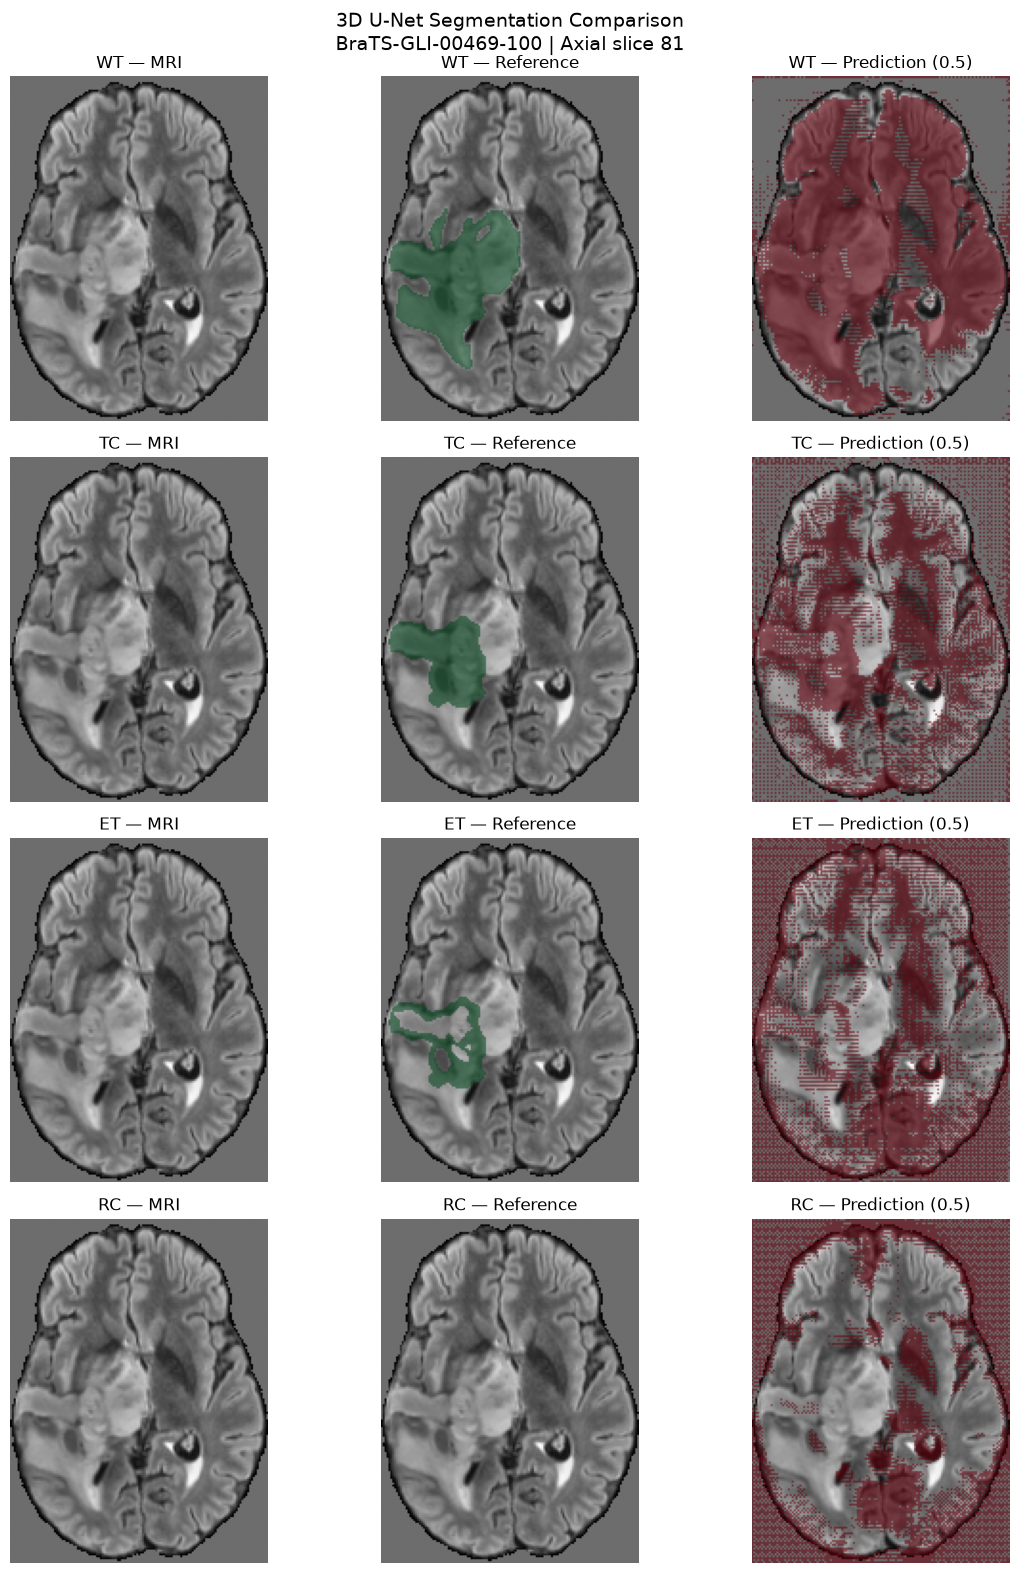


Segmentation visualisation PASSED.


In [61]:
# -------------------------------------------------------------
# SECTION 32.9 — VISUALISE SEGMENTATION PREDICTIONS
# -------------------------------------------------------------
#
# Compare reference and predicted masks on an axial MRI slice.
#
# Rows:
#   WT, TC, ET, RC
#
# Columns:
#   T2-FLAIR MRI
#   MRI + reference segmentation
#   MRI + predicted segmentation
#
# No model inference or files saved.

import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# STEP 1 — TRANSFER TENSORS TO CPU
# -------------------------------------------------------------

# MRI channel order:
#   0 = T1 native
#   1 = T1 contrast
#   2 = T2 weighted
#   3 = T2 FLAIR

flair_volume = (
    selected_image[0, 3]
    .detach()
    .cpu()
    .numpy()
)

reference_masks = (
    selected_label[0]
    .detach()
    .cpu()
    .numpy()
)

predicted_masks = (
    selected_prediction[0]
    .detach()
    .cpu()
    .numpy()
)

# -------------------------------------------------------------
# STEP 2 — SELECT AN AXIAL SLICE
# -------------------------------------------------------------
#
# Choose the slice containing the greatest number of
# reference whole-tumour voxels.
#
# After RAS orientation, the third spatial axis is superior-
# inferior, so indexing [:, :, slice_index] is axial.

wt_reference = reference_masks[0]

slice_index = int(
    np.argmax(
        wt_reference.sum(axis=(0, 1))
    )
)

print("Selected axial slice:", slice_index)
print("Case ID:", selected_case_id)

# -------------------------------------------------------------
# STEP 3 — PREPARE DISPLAY
# -------------------------------------------------------------

region_names = ["WT", "TC", "ET", "RC"]

fig, axes = plt.subplots(
    nrows=4,
    ncols=3,
    figsize=(12, 16),
)

for region_index, region_name in enumerate(region_names):

    # Rotate for a consistent visual display.
    flair_slice = np.rot90(
        flair_volume[:, :, slice_index]
    )

    reference_slice = np.rot90(
        reference_masks[
            region_index, :, :, slice_index
        ]
    )

    prediction_slice = np.rot90(
        predicted_masks[
            region_index, :, :, slice_index
        ]
    )

    # Column 1: Original MRI
    axes[region_index, 0].imshow(
        flair_slice,
        cmap="gray",
    )

    axes[region_index, 0].set_title(
        f"{region_name} — MRI"
    )

    # Column 2: Reference overlay
    axes[region_index, 1].imshow(
        flair_slice,
        cmap="gray",
    )

    axes[region_index, 1].imshow(
        np.ma.masked_where(
            reference_slice == 0,
            reference_slice,
        ),
        cmap="Greens",
        alpha=0.55,
        vmin=0,
        vmax=1,
    )

    axes[region_index, 1].set_title(
        f"{region_name} — Reference"
    )

    # Column 3: Predicted overlay
    axes[region_index, 2].imshow(
        flair_slice,
        cmap="gray",
    )

    axes[region_index, 2].imshow(
        np.ma.masked_where(
            prediction_slice == 0,
            prediction_slice,
        ),
        cmap="Reds",
        alpha=0.55,
        vmin=0,
        vmax=1,
    )

    axes[region_index, 2].set_title(
        f"{region_name} — Prediction (0.5)"
    )

    # Remove axes for cleaner presentation.
    for column_index in range(3):
        axes[region_index, column_index].axis("off")

plt.suptitle(
    f"3D U-Net Segmentation Comparison\n"
    f"{selected_case_id} | Axial slice {slice_index}",
    fontsize=14,
)

plt.tight_layout()
plt.show()

print("\nSegmentation visualisation PASSED.")

In [62]:
# -------------------------------------------------------------
# SECTION 33.1 — AUDIT TRAINING PATCH COMPOSITION
# -------------------------------------------------------------
#
# Examine the segmentation labels in a small number of
# randomly sampled training patches.
#
# Determine:
#   - Which regions are present
#   - How many positive voxels each region contains
#   - What fraction of each patch is positive
#
# This is a diagnostic check of our existing training
# transform, not a change to the training pipeline.

import pandas as pd

region_names = ["WT", "TC", "ET", "RC"]

patch_records = []

# Sample five training cases using the existing transforms.
# Each case produces two randomly selected patches.

for case_index in range(5):

    sampled_patches = pilot_training_dataset[
        case_index
    ]

    # RandCropByPosNegLabeld with num_samples=2 returns
    # a list of dictionaries, one for each sampled patch.
    assert isinstance(sampled_patches, list)

    for patch_index, patch in enumerate(sampled_patches):

        label = patch["label"]

        assert label.shape[0] == 4

        spatial_voxels = int(
            label.shape[1]
            * label.shape[2]
            * label.shape[3]
        )

        record = {
            "Case ID": pilot_training_cases[
                case_index
            ]["case_id"],
            "Patch": patch_index + 1,
        }

        for region_index, region_name in enumerate(
            region_names
        ):

            positive_voxels = int(
                label[region_index].sum().item()
            )

            record[
                f"{region_name} %"
            ] = round(
                100 * positive_voxels / spatial_voxels,
                3,
            )

        patch_records.append(record)

patch_audit_table = pd.DataFrame(
    patch_records
)

display(patch_audit_table)

print("\nMean percentage of positive voxels:")

percentage_columns = [
    f"{region_name} %"
    for region_name in region_names
]

display(
    patch_audit_table[
        percentage_columns
    ].mean().round(3)
)

print("\nTraining patch composition audit PASSED.")

,Case ID,Patch,WT %,TC %,ET %,RC %
0,BraTS-GLI-00006-100,1,1.745,0.000,0.000,2.307
1,BraTS-GLI-00006-100,2,0.000,0.000,0.000,0.000
2,BraTS-GLI-00006-101,1,2.119,0.000,0.000,2.090
3,BraTS-GLI-00006-101,2,2.079,0.000,0.000,2.090
4,BraTS-GLI-00009-100,1,8.061,0.732,0.712,0.328
5,BraTS-GLI-00009-100,2,7.666,0.572,0.555,0.337
6,BraTS-GLI-00009-101,1,9.581,1.344,1.281,0.082
7,BraTS-GLI-00009-101,2,4.794,0.000,0.000,0.000
8,BraTS-GLI-00020-100,1,13.106,2.641,2.478,0.188
9,BraTS-GLI-00020-100,2,0.733,0.000,0.000,0.000



Mean percentage of positive voxels:


WT %    4.988
TC %    0.529
ET %    0.503
RC %    0.742
dtype: float64


Training patch composition audit PASSED.


In [66]:
# -------------------------------------------------------------
# SECTION 33.2 — INSPECT MONAI'S INTERNAL LOSS COMPONENTS
# -------------------------------------------------------------
#
# Compare:
#   1. MONAI's internal Dice component
#   2. MONAI's internal BCE component
#   3. Standalone PyTorch BCE
#   4. MONAI's complete DiceCE loss
#
# Use MONAI's own methods to avoid assuming how it reduces
# the channel dimension.
#
# No training, GPU inference, or file modifications.

import torch
import torch.nn.functional as F
import monai

from monai.losses import DiceCELoss

# -------------------------------------------------------------
# STEP 1 — RECREATE THE ORIGINAL TRAINING LOSS
# -------------------------------------------------------------

diagnostic_loss = DiceCELoss(
    include_background=True,
    to_onehot_y=False,
    sigmoid=True,
    softmax=False,
    squared_pred=False,
    smooth_nr=1e-5,
    smooth_dr=1e-5,
    lambda_dice=1.0,
    lambda_ce=1.0,
)

# -------------------------------------------------------------
# STEP 2 — CALCULATE COMPONENTS USING MONAI'S OWN METHODS
# -------------------------------------------------------------

with torch.inference_mode():

    # Internal Dice component.
    monai_dice = diagnostic_loss.dice(
        selected_logits,
        selected_label,
    )

    # Internal cross-entropy component.
    # DiceCELoss handles multichannel sigmoid predictions
    # through its BCE calculation.
    monai_bce = diagnostic_loss.ce(
        selected_logits,
        selected_label,
    )

    # Standard PyTorch BCE for comparison.
    pytorch_bce = F.binary_cross_entropy_with_logits(
        selected_logits,
        selected_label.float(),
        reduction="mean",
    )

    # Full MONAI loss.
    monai_total = diagnostic_loss(
        selected_logits,
        selected_label,
    )

    # Reconstruct using MONAI's own components.
    reconstructed_total = monai_dice + monai_bce

# -------------------------------------------------------------
# STEP 3 — DISPLAY THE RESULTS
# -------------------------------------------------------------

print("MONAI version:", monai.__version__)
print("Output shape:", tuple(selected_logits.shape))

print(f"\nMONAI Dice component:    {monai_dice.item():.8f}")
print(f"MONAI BCE component:     {monai_bce.item():.8f}")
print(f"PyTorch BCE mean:        {pytorch_bce.item():.8f}")

print(f"\nReconstructed total:     {reconstructed_total.item():.8f}")
print(f"MONAI DiceCE total:      {monai_total.item():.8f}")

print(
    "Difference:",
    abs(
        reconstructed_total.item()
        - monai_total.item()
    ),
)

print("\nLoss component inspection completed.")

MONAI version: 1.6.1
Output shape: (1, 4, 135, 180, 150)

MONAI Dice component:    0.95074117
MONAI BCE component:     0.04731169
PyTorch BCE mean:        0.81300533

Reconstructed total:     0.99805284
MONAI DiceCE total:      0.99805284
Difference: 0.0

Loss component inspection completed.


In [67]:
# -------------------------------------------------------------
# SECTION 33.3 — INSPECT MONAI DICECE IMPLEMENTATION
# -------------------------------------------------------------
#
# Examine the installed MONAI source code for:
#   1. DiceCELoss.forward()
#   2. DiceCELoss.ce()
#
# This will help explain why calling ce() directly produced
# a different result from standalone PyTorch BCE.
#
# No model execution or training.

import inspect
import monai

from monai.losses import DiceCELoss

print("MONAI version:", monai.__version__)

print("\n" + "=" * 60)
print("DiceCELoss.forward()")
print("=" * 60)

print(
    inspect.getsource(
        DiceCELoss.forward
    )
)

print("\n" + "=" * 60)
print("DiceCELoss.ce()")
print("=" * 60)

print(
    inspect.getsource(
        DiceCELoss.ce
    )
)

print("\nMONAI loss implementation inspection PASSED.")

MONAI version: 1.6.1

DiceCELoss.forward()
    def forward(self, input: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        """
        Args:
            input: the shape should be BNH[WD].
            target: the shape should be BNH[WD] or B1H[WD].

        Raises:
            ValueError: When number of dimensions for input and target are different.
            ValueError: When number of channels for target is neither 1 (without one-hot encoding) nor the same as input.

        Returns:
            torch.Tensor: value of the loss.

        """
        if input.dim() != target.dim():
            raise ValueError(
                "the number of dimensions for input and target should be the same, "
                f"got shape {input.shape} (nb dims: {len(input.shape)}) and {target.shape} (nb dims: {len(target.shape)}). "
                "if target is not one-hot encoded, please provide a tensor with shape B1H[WD]."
            )

        if target.shape[1] != 1 and target.shape[

## Section 33.4 — Identification and Correction of a Multi-Label Loss Function Error

### Background

The initial pilot employed a 3D U-Net with four sigmoid output channels representing overlapping BraTS segmentation regions:

- **WT:** Whole tumour
- **TC:** Tumour core
- **ET:** Enhancing tissue
- **RC:** Resection cavity

These regions are not mutually exclusive. For example, an enhancing tumour voxel may simultaneously belong to WT, TC and ET.

The initial training configuration used MONAI's `DiceCELoss` with `sigmoid=True`, under the assumption that its cross-entropy component would perform independent binary classification across all four channels.

### Identification of the issue

Following the pilot, quantitative evaluation demonstrated extensive oversegmentation despite decreasing training and validation losses.

Inspection of the installed MONAI 1.6.1 implementation revealed that `DiceCELoss` selects its cross-entropy calculation according to the number of output channels:

- **Single-channel output:** Binary cross-entropy
- **Multichannel output:** Categorical cross-entropy

Setting `sigmoid=True` configures the Dice component but does not change this cross-entropy selection.

Because the model produces four overlapping binary segmentation channels, categorical cross-entropy is not appropriate for the intended multi-label formulation.

### Diagnostic findings

For validation case `BraTS-GLI-00469-100`, the original loss was decomposed into:

| Component | Loss |
|---|---:|
| MONAI Dice loss | 0.950741 |
| MONAI categorical cross-entropy | 0.047312 |
| Combined DiceCE loss | 0.998053 |
| Standalone binary cross-entropy (comparison) | 0.813005 |

The combined loss was successfully reconstructed using MONAI's internal methods, confirming the behaviour of the installed implementation.

These results demonstrate a mismatch between the intended loss formulation and the implementation used during pilot training. They do not, by themselves, establish that the loss configuration was the sole cause of poor segmentation.

### Proposed correction

The revised loss will explicitly combine:

\[
\mathcal{L}_{total}
=
\mathcal{L}_{Dice}
+
\mathcal{L}_{BCEWithLogits}
\]

The Dice component will use independent sigmoid activation for each segmentation channel. Binary cross-entropy with logits will independently evaluate the four overlapping regions.

### Experimental implications

The original pilot will be retained as a documented baseline rather than overwritten.

A controlled repeat experiment will use the corrected loss while keeping the dataset split, model architecture, patch sampling strategy and training duration unchanged.

The two experiments will be compared using region-specific Dice coefficients, precision, recall and qualitative MRI overlays. Raw loss values will not be treated as directly comparable because the objective functions differ.

**Status:** Methodological issue identified; corrected loss verification and repeat training pending.

In [68]:
# -------------------------------------------------------------
# SECTION 33.4 — CORRECT MULTI-LABEL SEGMENTATION LOSS
# -------------------------------------------------------------
#
# Our segmentation targets contain four overlapping regions:
#   WT, TC, ET, RC
#
# Each output channel is an independent binary prediction.
#
# Therefore, use:
#   1. Sigmoid Dice loss
#   2. Binary cross-entropy with logits
#
# Do not use categorical cross-entropy for these targets.
#
# This cell evaluates the corrected loss without training.

import torch
import torch.nn as nn

from monai.losses import DiceLoss

# -------------------------------------------------------------
# STEP 1 — DEFINE CORRECTED LOSS COMPONENTS
# -------------------------------------------------------------

multilabel_dice_loss = DiceLoss(
    include_background=True,
    to_onehot_y=False,
    sigmoid=True,
    softmax=False,
    squared_pred=False,
    smooth_nr=1e-5,
    smooth_dr=1e-5,
    reduction="mean",
)

multilabel_bce_loss = nn.BCEWithLogitsLoss(
    reduction="mean"
)

# -------------------------------------------------------------
# STEP 2 — CALCULATE CORRECTED LOSS
# -------------------------------------------------------------

with torch.inference_mode():

    corrected_dice = multilabel_dice_loss(
        selected_logits,
        selected_label,
    )

    corrected_bce = multilabel_bce_loss(
        selected_logits,
        selected_label.float(),
    )

    corrected_total = corrected_dice + corrected_bce

# -------------------------------------------------------------
# STEP 3 — VALIDATE
# -------------------------------------------------------------

assert torch.isfinite(corrected_dice)
assert torch.isfinite(corrected_bce)
assert torch.isfinite(corrected_total)

print("Selected case:", selected_case_id)

print(f"Corrected Dice loss: {corrected_dice.item():.6f}")
print(f"Corrected BCE loss:  {corrected_bce.item():.6f}")
print(f"Corrected total:     {corrected_total.item():.6f}")

print("\nCorrected multi-label loss verification PASSED.")

Selected case: BraTS-GLI-00469-100
Corrected Dice loss: 0.950741
Corrected BCE loss:  0.813005
Corrected total:     1.763747

Corrected multi-label loss verification PASSED.


## Section 33.5 — Implementing a Reusable Multi-Label Loss Function

### Objective

Following the identification of an inappropriate categorical cross-entropy component in the original pilot training configuration, a corrected loss function was developed for the four overlapping BraTS segmentation regions: whole tumour (WT), tumour core (TC), enhancing tissue (ET), and resection cavity (RC).

The corrected objective combines sigmoid Dice loss with binary cross-entropy calculated independently for each output channel:

\[
\mathcal{L}_{total}
=
\lambda_{Dice}\mathcal{L}_{Dice}
+
\lambda_{BCE}\mathcal{L}_{BCEWithLogits}
\]

Both loss weights are initially set to 1.0.

### Implementation

The corrected loss is implemented as a reusable PyTorch `nn.Module` named `MultiLabelDiceBCELoss`, stored in `src/losses.py`.

The implementation:

- Accepts raw model logits and corresponding multi-label segmentation targets.
- Applies sigmoid internally through MONAI's Dice loss.
- Uses PyTorch's `BCEWithLogitsLoss` for independent binary classification of each segmentation region.
- Supports configurable Dice and BCE weights.
- Checks that prediction and target tensor shapes match.

Separating the loss implementation from the development notebook improves code reuse, reproducibility and maintainability.

### Verification plan

Before using the corrected loss for training, its numerical output will be compared against the independently calculated Dice and BCE components. Gradient propagation will also be tested to confirm compatibility with model optimisation.

The original pilot checkpoints will be preserved for comparison with a subsequent controlled experiment using the corrected objective.

**Status:** Corrected loss formulation verified; reusable module implementation and gradient testing pending.

In [70]:
# -------------------------------------------------------------
# SECTION 33.5 — CREATE REUSABLE MULTI-LABEL LOSS MODULE
# -------------------------------------------------------------
#
# Write a reusable loss implementation to src/losses.py.
#
# The loss combines:
#   1. MONAI sigmoid Dice loss
#   2. PyTorch binary cross-entropy with logits
#
# Designed for four overlapping BraTS segmentation regions.
#
# No model training or GPU inference.

from pathlib import Path
import textwrap

# Locate the repository root from the notebook directory.
repository_root = Path.cwd().resolve()

if repository_root.name == "notebooks":
    repository_root = repository_root.parent

assert (repository_root / "src").is_dir(), (
    "Could not locate the repository's src directory."
)

loss_module_path = repository_root / "src" / "losses.py"

# Avoid silently overwriting existing source code.
assert not loss_module_path.exists(), (
    f"File already exists: {loss_module_path}"
)

loss_module_source = textwrap.dedent('''
    """Loss functions for multi-label glioma MRI segmentation."""

    import torch
    from torch import nn
    from monai.losses import DiceLoss


    class MultiLabelDiceBCELoss(nn.Module):
        """
        Combine sigmoid Dice loss and binary cross-entropy.

        Intended for overlapping binary segmentation regions,
        such as WT, TC, ET and RC.

        Inputs:
            logits: Tensor of shape (B, C, H, W, D).
            targets: Binary tensor with the same shape.

        The input must contain raw logits, not probabilities.
        """

        def __init__(self, dice_weight=1.0, bce_weight=1.0):
            super().__init__()

            self.dice_weight = dice_weight
            self.bce_weight = bce_weight

            self.dice_loss = DiceLoss(
                include_background=True,
                to_onehot_y=False,
                sigmoid=True,
                softmax=False,
                squared_pred=False,
                smooth_nr=1e-5,
                smooth_dr=1e-5,
                reduction="mean",
            )

            self.bce_loss = nn.BCEWithLogitsLoss(
                reduction="mean"
            )

        def forward(self, logits, targets):
            """Return the weighted Dice + BCE loss."""

            if logits.shape != targets.shape:
                raise ValueError(
                    "Logits and targets must have matching shapes. "
                    f"Received {logits.shape} and {targets.shape}."
                )

            targets = targets.to(dtype=logits.dtype)

            dice = self.dice_loss(logits, targets)
            bce = self.bce_loss(logits, targets)

            return (
                self.dice_weight * dice
                + self.bce_weight * bce
            )
''').lstrip()

loss_module_path.write_text(
    loss_module_source,
    encoding="utf-8",
)

print("Created:", loss_module_path)
print("File size:", loss_module_path.stat().st_size, "bytes")
print("\nReusable multi-label loss module created successfully.")

Created: /mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/src/losses.py
File size: 1592 bytes

Reusable multi-label loss module created successfully.


In [71]:
# -------------------------------------------------------------
# SECTION 33.6 — VERIFY REUSABLE MULTI-LABEL LOSS MODULE
# -------------------------------------------------------------
#
# Verify that src/losses.py:
#   1. Can be imported successfully
#   2. Reproduces our independently calculated loss
#   3. Supports gradient backpropagation
#
# No model training or checkpoint modifications.

import sys
import torch

from pathlib import Path

# -------------------------------------------------------------
# STEP 1 — LOCATE THE REPOSITORY
# -------------------------------------------------------------

repository_root = Path.cwd().resolve()

if repository_root.name == "notebooks":
    repository_root = repository_root.parent

# Make the repository's src directory importable.
source_directory = repository_root / "src"

assert source_directory.is_dir(), (
    f"Source directory not found: {source_directory}"
)

if str(source_directory) not in sys.path:
    sys.path.insert(0, str(source_directory))

# Import the corrected loss implementation.
from losses import MultiLabelDiceBCELoss

print("Imported MultiLabelDiceBCELoss successfully.")

# -------------------------------------------------------------
# STEP 2 — REPRODUCE PREVIOUS VALIDATION LOSS
# -------------------------------------------------------------

reusable_loss = MultiLabelDiceBCELoss(
    dice_weight=1.0,
    bce_weight=1.0,
).to(evaluation_device)

with torch.inference_mode():

    reusable_total = reusable_loss(
        selected_logits,
        selected_label,
    )

print(
    "\nReusable loss:",
    round(reusable_total.item(), 6),
)

print(
    "Previous corrected loss:",
    round(corrected_total.item(), 6),
)

assert torch.allclose(
    reusable_total,
    corrected_total,
    atol=1e-6,
), "Reusable loss does not match the previous calculation."

print("Numerical equivalence: PASSED")

# -------------------------------------------------------------
# STEP 3 — TEST GRADIENT PROPAGATION
# -------------------------------------------------------------
#
# Use a small synthetic example rather than a full MRI volume.
#
# The logits require gradients so we can confirm that the
# corrected loss supports backpropagation.

test_logits = torch.randn(
    (1, 4, 16, 16, 16),
    dtype=torch.float32,
    requires_grad=True,
)

# Create synthetic overlapping binary segmentation targets.
# Multiple channels can be positive at the same voxel.
test_targets = torch.zeros_like(test_logits)

test_targets[:, 0, 4:12, 4:12, 4:12] = 1.0
test_targets[:, 1, 6:10, 6:10, 6:10] = 1.0
test_targets[:, 2, 7:9, 7:9, 7:9] = 1.0
test_targets[:, 3, 2:5, 2:5, 2:5] = 1.0

# Create a CPU loss instance for this lightweight test.
test_loss_function = MultiLabelDiceBCELoss()

test_loss = test_loss_function(
    test_logits,
    test_targets,
)

# Compute gradients with respect to the logits.
test_loss.backward()

# -------------------------------------------------------------
# STEP 4 — VERIFY GRADIENTS
# -------------------------------------------------------------

assert test_logits.grad is not None, (
    "No gradients were generated."
)

assert torch.isfinite(test_logits.grad).all(), (
    "Gradients contain NaN or infinity."
)

assert test_logits.grad.abs().sum() > 0, (
    "All gradients are zero."
)

print(
    "\nSynthetic test loss:",
    round(test_loss.item(), 6),
)

print(
    "Mean absolute gradient:",
    test_logits.grad.abs().mean().item(),
)

print("Gradient propagation: PASSED")

print("\nReusable multi-label loss verification PASSED.")

Imported MultiLabelDiceBCELoss successfully.

Reusable loss: 1.763747
Previous corrected loss: 1.763747
Numerical equivalence: PASSED

Synthetic test loss: 1.7412
Mean absolute gradient: 3.307575389044359e-05
Gradient propagation: PASSED

Reusable multi-label loss verification PASSED.


## Section 34 — Controlled Repeat Pilot Using Corrected Multi-Label Loss

In [72]:
# -------------------------------------------------------------
# SECTION 34.1 — PREPARE CORRECTED LOSS EXPERIMENT
# -------------------------------------------------------------
#
# Create a new experiment directory on the WSL filesystem.
#
# Preserve the original pilot experiment and its checkpoints.
#
# This cell does not start training or allocate GPU memory.

from pathlib import Path
from datetime import datetime
import json

# -------------------------------------------------------------
# STEP 1 — DEFINE EXPERIMENT LOCATION
# -------------------------------------------------------------

experiment_root = (
    Path.home()
    / "experiments"
    / "glioma-mri-segmentation"
)

# Create a unique identifier for the corrected experiment.
corrected_experiment_id = (
    "pilot_multilabel_dice_bce_"
    + datetime.now().strftime("%Y%m%d_%H%M%S")
)

corrected_experiment_directory = (
    experiment_root / corrected_experiment_id
)

corrected_checkpoint_directory = (
    corrected_experiment_directory / "checkpoints"
)

corrected_log_directory = (
    corrected_experiment_directory / "logs"
)

# Refuse to reuse an existing experiment directory.
assert not corrected_experiment_directory.exists(), (
    "Experiment directory already exists."
)

corrected_checkpoint_directory.mkdir(
    parents=True,
    exist_ok=False,
)

corrected_log_directory.mkdir(
    parents=True,
    exist_ok=False,
)

# -------------------------------------------------------------
# STEP 2 — DOCUMENT EXPERIMENT CONFIGURATION
# -------------------------------------------------------------

corrected_pilot_config = {
    "experiment_id": corrected_experiment_id,
    "experiment_type": "corrected_loss_pilot",
    "training_cases": 24,
    "validation_cases": 4,
    "epochs": 10,
    "patch_size": [96, 96, 96],
    "patches_per_case": 2,
    "batch_size": 1,
    "optimizer": "AdamW",
    "learning_rate": 1e-4,
    "weight_decay": 1e-5,
    "loss": "MultiLabelDiceBCELoss",
    "dice_weight": 1.0,
    "bce_weight": 1.0,
    "random_seed": 42,
    "baseline_experiment": str(experiment_directory),
}

corrected_config_path = (
    corrected_experiment_directory / "config.json"
)

with corrected_config_path.open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        corrected_pilot_config,
        file,
        indent=2,
    )

# -------------------------------------------------------------
# STEP 3 — VERIFY EXPERIMENT DIRECTORY
# -------------------------------------------------------------

assert corrected_config_path.is_file()
assert corrected_checkpoint_directory.is_dir()
assert corrected_log_directory.is_dir()

print("Corrected experiment:", corrected_experiment_id)
print("Experiment directory:", corrected_experiment_directory)
print("Checkpoint directory:", corrected_checkpoint_directory)
print("Log directory:", corrected_log_directory)
print("Configuration saved:", corrected_config_path)

print("\nCorrected pilot experiment preparation PASSED.")

Corrected experiment: pilot_multilabel_dice_bce_20261013_010546
Experiment directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546
Checkpoint directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/checkpoints
Log directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs
Configuration saved: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/config.json

Corrected pilot experiment preparation PASSED.


In [73]:
# -------------------------------------------------------------
# SECTION 34.2 — VERIFY CORRECTED PILOT CONFIGURATION
# -------------------------------------------------------------
#
# Check that the corrected experiment is ready for training.
#
# This cell:
#   - Verifies the dataset sizes
#   - Confirms subject-level separation
#   - Checks the corrected loss class
#   - Verifies experiment directories
#   - Checks GPU availability
#
# No training or GPU-intensive inference is performed.

import torch

from losses import MultiLabelDiceBCELoss

# -------------------------------------------------------------
# STEP 1 — VERIFY DATASET SIZES
# -------------------------------------------------------------

assert len(pilot_training_cases) == 24
assert len(pilot_validation_cases) == 4

assert len(pilot_training_dataset) == 24
assert len(pilot_validation_dataset) == 4

print("Training cases:", len(pilot_training_cases))
print("Validation cases:", len(pilot_validation_cases))

# -------------------------------------------------------------
# STEP 2 — VERIFY SUBJECT-LEVEL SEPARATION
# -------------------------------------------------------------

training_subjects = {
    case["subject_id"]
    for case in pilot_training_cases
}

validation_subjects = {
    case["subject_id"]
    for case in pilot_validation_cases
}

overlapping_subjects = (
    training_subjects & validation_subjects
)

assert len(overlapping_subjects) == 0, (
    f"Subject leakage detected: {overlapping_subjects}"
)

print("Subject-level overlap:", len(overlapping_subjects))

# -------------------------------------------------------------
# STEP 3 — VERIFY LOSS FUNCTION
# -------------------------------------------------------------

corrected_loss_function = MultiLabelDiceBCELoss(
    dice_weight=1.0,
    bce_weight=1.0,
)

assert isinstance(
    corrected_loss_function,
    torch.nn.Module,
)

print(
    "Corrected loss:",
    type(corrected_loss_function).__name__,
)

# -------------------------------------------------------------
# STEP 4 — VERIFY EXPERIMENT PATHS
# -------------------------------------------------------------

assert corrected_experiment_directory.is_dir()
assert corrected_checkpoint_directory.is_dir()
assert corrected_log_directory.is_dir()
assert corrected_config_path.is_file()

print("Experiment directory:", corrected_experiment_directory)

# -------------------------------------------------------------
# STEP 5 — VERIFY COMPUTE DEVICE
# -------------------------------------------------------------

assert torch.cuda.is_available(), (
    "CUDA is unavailable. Check the glioma-ml environment."
)

print("GPU:", torch.cuda.get_device_name(0))

# -------------------------------------------------------------
# STEP 6 — VERIFY CONFIGURATION
# -------------------------------------------------------------

assert corrected_pilot_config["loss"] == (
    "MultiLabelDiceBCELoss"
)

assert corrected_pilot_config["epochs"] == 10
assert corrected_pilot_config["random_seed"] == 42

print("Configured epochs:", corrected_pilot_config["epochs"])
print("Configured random seed:", corrected_pilot_config["random_seed"])

print("\nCorrected pilot pre-training verification PASSED.")

Training cases: 24
Validation cases: 4
Subject-level overlap: 0
Corrected loss: MultiLabelDiceBCELoss
Experiment directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546
GPU: NVIDIA GeForce RTX 4080 SUPER
Configured epochs: 10
Configured random seed: 42

Corrected pilot pre-training verification PASSED.


In [74]:
# -------------------------------------------------------------
# SECTION 34.3 — INITIALISE CORRECTED PILOT
# -------------------------------------------------------------
#
# Prepare a fresh 3D U-Net for the corrected-loss experiment.
#
# Keep the original pilot architecture and optimiser settings.
#
# Changes from the original pilot:
#   - Explicit random seed
#   - Corrected MultiLabelDiceBCELoss
#
# This cell does not start training or save checkpoints.

import random
import numpy as np
import torch

from monai.networks.nets import UNet
from monai.utils import set_determinism

from losses import MultiLabelDiceBCELoss

# -------------------------------------------------------------
# STEP 1 — SET RANDOM SEEDS
# -------------------------------------------------------------
#
# Set seeds before initialising the new network.
#
# MONAI's set_determinism also configures deterministic
# behaviour where supported. Some GPU operations may still
# have platform-dependent limitations.

training_seed = corrected_pilot_config["random_seed"]

random.seed(training_seed)
np.random.seed(training_seed)
torch.manual_seed(training_seed)
torch.cuda.manual_seed_all(training_seed)

set_determinism(seed=training_seed)

print("Random seed:", training_seed)

# -------------------------------------------------------------
# STEP 2 — INITIALISE FRESH 3D U-NET
# -------------------------------------------------------------

corrected_model = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=4,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    num_res_units=2,
).to(evaluation_device)

# -------------------------------------------------------------
# STEP 3 — INITIALISE CORRECTED LOSS
# -------------------------------------------------------------

corrected_training_loss = MultiLabelDiceBCELoss(
    dice_weight=1.0,
    bce_weight=1.0,
).to(evaluation_device)

# -------------------------------------------------------------
# STEP 4 — INITIALISE OPTIMISER
# -------------------------------------------------------------

corrected_optimizer = torch.optim.AdamW(
    corrected_model.parameters(),
    lr=corrected_pilot_config["learning_rate"],
    weight_decay=corrected_pilot_config["weight_decay"],
)

# -------------------------------------------------------------
# STEP 5 — VERIFY MODEL CONFIGURATION
# -------------------------------------------------------------

corrected_parameter_count = sum(
    parameter.numel()
    for parameter in corrected_model.parameters()
    if parameter.requires_grad
)

assert corrected_parameter_count == 4_811_129, (
    "Corrected model architecture differs from original pilot."
)

assert corrected_model.training, (
    "Model should be in training mode."
)

print("Model:", type(corrected_model).__name__)
print("Trainable parameters:", f"{corrected_parameter_count:,}")
print("Device:", next(corrected_model.parameters()).device)
print("Loss:", type(corrected_training_loss).__name__)
print("Optimiser:", type(corrected_optimizer).__name__)

print("\nCorrected pilot initialisation PASSED.")

Random seed: 42
Model: UNet
Trainable parameters: 4,811,129
Device: cuda:0
Loss: MultiLabelDiceBCELoss
Optimiser: AdamW

Corrected pilot initialisation PASSED.


In [75]:
# -------------------------------------------------------------
# SECTION 34.4 — CORRECTED MULTI-LABEL PILOT TRAINING
# -------------------------------------------------------------
#
# Train a fresh 3D U-Net using the corrected Dice + BCE loss.
#
# Features:
#   - 10 training epochs
#   - Full-volume sliding-window validation
#   - CSV training history
#   - Checkpoint after every epoch
#   - Rolling recovery checkpoint every 5 batches
#   - Maximum runtime safeguard
#
# This is a GPU-intensive operation.
#
# IMPORTANT:
# Do not rerun Cell 57 after training begins.
# Do not rerun this cell without deciding whether to resume
# or restart, as the model and optimiser retain their state.

import csv
import json
import time
from datetime import datetime

import torch

from monai.inferers import sliding_window_inference

# -------------------------------------------------------------
# STEP 1 — CONFIGURATION
# -------------------------------------------------------------

maximum_epochs = corrected_pilot_config["epochs"]
maximum_runtime_seconds = 150 * 60

validation_roi_size = tuple(
    corrected_pilot_config["patch_size"]
)

training_history_path = (
    corrected_log_directory / "training_history.csv"
)

training_summary_path = (
    corrected_experiment_directory / "training_summary.json"
)

recovery_checkpoint_path = (
    corrected_checkpoint_directory / "recovery_latest.pt"
)

final_checkpoint_path_corrected = (
    corrected_checkpoint_directory / "final_latest.pt"
)

# Prevent accidental overwriting of a completed experiment.
assert not training_history_path.exists(), (
    "Training history already exists. "
    "Do not restart without reviewing the existing experiment."
)

assert not final_checkpoint_path_corrected.exists(), (
    "Final checkpoint already exists."
)

# -------------------------------------------------------------
# STEP 2 — CHECKPOINT HELPER
# -------------------------------------------------------------

def save_corrected_checkpoint(path, epoch, batch, status):
    """
    Save the complete training state for reproducibility
    and possible recovery.
    """

    checkpoint = {
        "epoch": epoch,
        "batch": batch,
        "status": status,
        "model_state_dict": corrected_model.state_dict(),
        "optimizer_state_dict": corrected_optimizer.state_dict(),
        "experiment_id": corrected_experiment_id,
        "loss_name": "MultiLabelDiceBCELoss",
        "saved_at": datetime.now().isoformat(),
    }

    # Write to a temporary file before replacing the target.
    temporary_path = path.with_suffix(".tmp")

    torch.save(checkpoint, temporary_path)
    temporary_path.replace(path)


# -------------------------------------------------------------
# STEP 3 — PREPARE TRAINING HISTORY
# -------------------------------------------------------------

history_fields = [
    "epoch",
    "training_loss",
    "validation_loss",
    "elapsed_minutes",
]

with training_history_path.open(
    "w",
    newline="",
    encoding="utf-8",
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=history_fields,
    )

    writer.writeheader()

# -------------------------------------------------------------
# STEP 4 — TRAINING LOOP
# -------------------------------------------------------------

experiment_start = time.monotonic()

completed_epochs = 0
stop_reason = "maximum_epochs_completed"

print("Starting corrected pilot training...")
print("Experiment:", corrected_experiment_id)
print("Device:", evaluation_device)

for epoch in range(1, maximum_epochs + 1):

    # ---------------------------------------------------------
    # TRAINING PHASE
    # ---------------------------------------------------------

    corrected_model.train()

    epoch_training_loss = 0.0
    training_batches = 0

    for batch_index, batch in enumerate(
        pilot_training_loader,
        start=1,
    ):

        # The training transform generates two patches
        # per case. The DataLoader combines them into
        # a batch of shape (2, 4, 96, 96, 96).

        images = batch["image"].to(evaluation_device)
        labels = batch["label"].to(evaluation_device)

        corrected_optimizer.zero_grad(set_to_none=True)

        logits = corrected_model(images)

        loss = corrected_training_loss(
            logits,
            labels,
        )

        if not bool(torch.isfinite(loss)):
            raise RuntimeError(
                f"Non-finite training loss at "
                f"epoch {epoch}, batch {batch_index}."
            )

        loss.backward()
        corrected_optimizer.step()

        epoch_training_loss += loss.item()
        training_batches += 1

        # Save a recovery checkpoint every five batches.
        if batch_index % 5 == 0:

            save_corrected_checkpoint(
                recovery_checkpoint_path,
                epoch,
                batch_index,
                "training_in_progress",
            )

        # Stop cooperatively if runtime is exceeded.
        if (
            time.monotonic() - experiment_start
            >= maximum_runtime_seconds
        ):
            stop_reason = "runtime_limit_reached"
            break

    if training_batches == 0:
        raise RuntimeError("No training batches processed.")

    mean_training_loss = (
        epoch_training_loss / training_batches
    )

    # ---------------------------------------------------------
    # VALIDATION PHASE
    # ---------------------------------------------------------

    corrected_model.eval()

    validation_loss_total = 0.0
    validation_batches = 0

    with torch.inference_mode():

        for validation_batch in pilot_validation_loader:

            validation_images = (
                validation_batch["image"]
                .to(evaluation_device)
            )

            validation_labels = (
                validation_batch["label"]
                .to(evaluation_device)
            )

            validation_logits = sliding_window_inference(
                inputs=validation_images,
                roi_size=validation_roi_size,
                sw_batch_size=1,
                predictor=corrected_model,
                overlap=0.25,
                mode="constant",
            )

            validation_loss = corrected_training_loss(
                validation_logits,
                validation_labels,
            )

            if not bool(torch.isfinite(validation_loss)):
                raise RuntimeError(
                    f"Non-finite validation loss "
                    f"at epoch {epoch}."
                )

            validation_loss_total += validation_loss.item()
            validation_batches += 1

    mean_validation_loss = (
        validation_loss_total / validation_batches
    )

    completed_epochs = epoch

    elapsed_minutes = (
        time.monotonic() - experiment_start
    ) / 60

    # ---------------------------------------------------------
    # LOG EPOCH RESULTS
    # ---------------------------------------------------------

    history_record = {
        "epoch": epoch,
        "training_loss": mean_training_loss,
        "validation_loss": mean_validation_loss,
        "elapsed_minutes": elapsed_minutes,
    }

    with training_history_path.open(
        "a",
        newline="",
        encoding="utf-8",
    ) as file:

        writer = csv.DictWriter(
            file,
            fieldnames=history_fields,
        )

        writer.writerow(history_record)

    # ---------------------------------------------------------
    # SAVE EPOCH CHECKPOINT
    # ---------------------------------------------------------

    epoch_checkpoint_path = (
        corrected_checkpoint_directory
        / f"epoch_{epoch:03d}.pt"
    )

    save_corrected_checkpoint(
        epoch_checkpoint_path,
        epoch,
        training_batches,
        "epoch_completed",
    )

    print(
        f"Epoch {epoch:02d}/{maximum_epochs} | "
        f"Train: {mean_training_loss:.4f} | "
        f"Val: {mean_validation_loss:.4f} | "
        f"Elapsed: {elapsed_minutes:.2f} min"
    )

    if (
        time.monotonic() - experiment_start
        >= maximum_runtime_seconds
    ):
        stop_reason = "runtime_limit_reached"

    if stop_reason == "runtime_limit_reached":
        break

# -------------------------------------------------------------
# STEP 5 — SAVE FINAL CHECKPOINT
# -------------------------------------------------------------

save_corrected_checkpoint(
    final_checkpoint_path_corrected,
    completed_epochs,
    training_batches,
    stop_reason,
)

# -------------------------------------------------------------
# STEP 6 — SAVE EXPERIMENT SUMMARY
# -------------------------------------------------------------

training_summary = {
    "experiment_id": corrected_experiment_id,
    "completed_epochs": completed_epochs,
    "requested_epochs": maximum_epochs,
    "stop_reason": stop_reason,
    "elapsed_minutes": (
        time.monotonic() - experiment_start
    ) / 60,
    "loss": "MultiLabelDiceBCELoss",
    "final_checkpoint": str(final_checkpoint_path_corrected),
}

with training_summary_path.open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        training_summary,
        file,
        indent=2,
    )

print("\nCorrected pilot training finished.")
print("Completed epochs:", completed_epochs)
print("Stop reason:", stop_reason)
print("Final checkpoint:", final_checkpoint_path_corrected)
print("Summary:", training_summary_path)

Starting corrected pilot training...
Experiment: pilot_multilabel_dice_bce_20261013_010546
Device: cuda:0
Epoch 01/10 | Train: 1.8059 | Val: 1.7435 | Elapsed: 0.25 min
Epoch 02/10 | Train: 1.7371 | Val: 1.7145 | Elapsed: 0.50 min
Epoch 03/10 | Train: 1.7016 | Val: 1.6964 | Elapsed: 0.75 min
Epoch 04/10 | Train: 1.6843 | Val: 1.6837 | Elapsed: 0.98 min
Epoch 05/10 | Train: 1.6622 | Val: 1.6702 | Elapsed: 1.21 min
Epoch 06/10 | Train: 1.6535 | Val: 1.6517 | Elapsed: 1.45 min
Epoch 07/10 | Train: 1.6234 | Val: 1.6205 | Elapsed: 1.68 min
Epoch 08/10 | Train: 1.5986 | Val: 1.5752 | Elapsed: 1.91 min
Epoch 09/10 | Train: 1.5663 | Val: 1.5275 | Elapsed: 2.15 min
Epoch 10/10 | Train: 1.5251 | Val: 1.4854 | Elapsed: 2.38 min

Corrected pilot training finished.
Completed epochs: 10
Stop reason: maximum_epochs_completed
Final checkpoint: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/checkpoints/final_latest.pt
Summary: /home/corvus_splendens/

In [76]:
# -------------------------------------------------------------
# SECTION 34.5 — VERIFY CORRECTED PILOT OUTPUTS
# -------------------------------------------------------------
#
# Confirm that training completed successfully and that
# checkpoints, history and experiment metadata were saved.
#
# This cell does not run model training or inference.

import csv
import json
from pathlib import Path

# -------------------------------------------------------------
# STEP 1 — VERIFY EXPECTED OUTPUT FILES
# -------------------------------------------------------------

corrected_final_checkpoint = (
    corrected_checkpoint_directory / "final_latest.pt"
)

corrected_history_file = (
    corrected_log_directory / "training_history.csv"
)

corrected_summary_file = (
    corrected_experiment_directory / "training_summary.json"
)

expected_files = [
    corrected_final_checkpoint,
    corrected_history_file,
    corrected_summary_file,
    corrected_config_path,
]

for file_path in expected_files:
    assert file_path.is_file(), (
        f"Missing experiment file: {file_path}"
    )

    print(
        f"{file_path.name}: "
        f"{file_path.stat().st_size / (1024 ** 2):.3f} MiB"
    )

# -------------------------------------------------------------
# STEP 2 — VERIFY TRAINING SUMMARY
# -------------------------------------------------------------

with corrected_summary_file.open(
    "r",
    encoding="utf-8",
) as file:
    corrected_summary = json.load(file)

assert corrected_summary["completed_epochs"] == 10
assert corrected_summary["stop_reason"] == (
    "maximum_epochs_completed"
)

assert corrected_summary["loss"] == (
    "MultiLabelDiceBCELoss"
)

print(
    "\nCompleted epochs:",
    corrected_summary["completed_epochs"],
)

print(
    "Stop reason:",
    corrected_summary["stop_reason"],
)

# -------------------------------------------------------------
# STEP 3 — VERIFY TRAINING HISTORY
# -------------------------------------------------------------

with corrected_history_file.open(
    "r",
    newline="",
    encoding="utf-8",
) as file:

    corrected_history = list(
        csv.DictReader(file)
    )

assert len(corrected_history) == 10, (
    "Expected 10 epoch history records."
)

first_epoch = corrected_history[0]
last_epoch = corrected_history[-1]

assert int(first_epoch["epoch"]) == 1
assert int(last_epoch["epoch"]) == 10

print("\nLogged epochs:", len(corrected_history))

print(
    "First validation loss:",
    round(float(first_epoch["validation_loss"]), 6),
)

print(
    "Final validation loss:",
    round(float(last_epoch["validation_loss"]), 6),
)

# -------------------------------------------------------------
# STEP 4 — VERIFY EPOCH CHECKPOINT COUNT
# -------------------------------------------------------------

epoch_checkpoints = sorted(
    corrected_checkpoint_directory.glob("epoch_*.pt")
)

assert len(epoch_checkpoints) == 10, (
    "Expected one checkpoint per completed epoch."
)

print(
    "\nEpoch checkpoints:",
    len(epoch_checkpoints),
)

print(
    "Final checkpoint:",
    corrected_final_checkpoint,
)

print("\nCorrected pilot output verification PASSED.")

final_latest.pt: 55.141 MiB
training_history.csv: 0.001 MiB
training_summary.json: 0.000 MiB
config.json: 0.001 MiB

Completed epochs: 10
Stop reason: maximum_epochs_completed

Logged epochs: 10
First validation loss: 1.743531
Final validation loss: 1.485445

Epoch checkpoints: 10
Final checkpoint: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/checkpoints/final_latest.pt

Corrected pilot output verification PASSED.


## Section 35 — Comparative Evaluation of Original and Corrected Loss Functions

In [77]:
# -------------------------------------------------------------
# SECTION 35.1 — LOAD CORRECTED PILOT MODEL
# -------------------------------------------------------------
#
# Load the corrected model from its saved final checkpoint.
#
# Verify:
#   1. Checkpoint metadata
#   2. Model architecture compatibility
#   3. Parameter integrity
#   4. Evaluation mode
#
# This cell does not run training or full-volume inference.

import torch

from monai.networks.nets import UNet

# -------------------------------------------------------------
# STEP 1 — LOAD CHECKPOINT
# -------------------------------------------------------------
#
# Load onto CPU first to avoid unnecessary GPU memory use.

corrected_checkpoint = torch.load(
    corrected_final_checkpoint,
    map_location="cpu",
    weights_only=True,
)

assert corrected_checkpoint["epoch"] == 10

assert corrected_checkpoint["loss_name"] == (
    "MultiLabelDiceBCELoss"
)

assert corrected_checkpoint["status"] == (
    "maximum_epochs_completed"
)

print("Checkpoint epoch:", corrected_checkpoint["epoch"])
print("Checkpoint loss:", corrected_checkpoint["loss_name"])
print("Checkpoint status:", corrected_checkpoint["status"])

# -------------------------------------------------------------
# STEP 2 — RECONSTRUCT MODEL ARCHITECTURE
# -------------------------------------------------------------
#
# Use exactly the same architecture as both pilot runs.

corrected_evaluation_model = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=4,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    num_res_units=2,
)

# Strict loading verifies that parameter names and tensor
# dimensions match the saved checkpoint.

corrected_evaluation_model.load_state_dict(
    corrected_checkpoint["model_state_dict"],
    strict=True,
)

# -------------------------------------------------------------
# STEP 3 — VERIFY PARAMETER INTEGRITY
# -------------------------------------------------------------

for parameter_name, parameter in (
    corrected_evaluation_model.named_parameters()
):

    assert torch.isfinite(parameter).all(), (
        f"Non-finite parameters detected: {parameter_name}"
    )

# -------------------------------------------------------------
# STEP 4 — MOVE MODEL TO EVALUATION DEVICE
# -------------------------------------------------------------

corrected_evaluation_model = (
    corrected_evaluation_model.to(evaluation_device)
)

corrected_evaluation_model.eval()

assert not corrected_evaluation_model.training

corrected_parameter_count = sum(
    parameter.numel()
    for parameter in corrected_evaluation_model.parameters()
    if parameter.requires_grad
)

assert corrected_parameter_count == 4_811_129

print("\nEvaluation device:", evaluation_device)
print("Trainable parameters:", f"{corrected_parameter_count:,}")
print("Evaluation mode:", not corrected_evaluation_model.training)

print("\nCorrected model checkpoint verification PASSED.")

Checkpoint epoch: 10
Checkpoint loss: MultiLabelDiceBCELoss
Checkpoint status: maximum_epochs_completed

Evaluation device: cuda:0
Trainable parameters: 4,811,129
Evaluation mode: True

Corrected model checkpoint verification PASSED.


In [78]:
# -------------------------------------------------------------
# SECTION 35.2 — COMPARE ORIGINAL AND CORRECTED MODELS
# -------------------------------------------------------------
#
# Evaluate both trained models on the same four validation
# cases using identical inference and segmentation settings.
#
# Metrics:
#   - Dice similarity coefficient
#   - Precision
#   - Recall
#   - Predicted voxel count
#   - Reference voxel count
#
# For absent reference regions, Dice and recall are NaN.
#
# This cell performs GPU inference but NO training.

import csv
import math
import time

import numpy as np
import torch

from monai.inferers import sliding_window_inference

# -------------------------------------------------------------
# STEP 1 — VERIFY EVALUATION MODELS
# -------------------------------------------------------------

assert not evaluation_model.training
assert not corrected_evaluation_model.training

evaluation_models = {
    "original_dice_ce": evaluation_model,
    "corrected_dice_bce": corrected_evaluation_model,
}

region_names = ("WT", "TC", "ET", "RC")
probability_threshold = 0.5

comparison_results = []

# -------------------------------------------------------------
# STEP 2 — DEFINE METRIC CALCULATION
# -------------------------------------------------------------

def calculate_binary_metrics(prediction, reference):
    """
    Calculate binary segmentation metrics.

    When the reference is empty, Dice and recall are NaN
    because the target region is absent.

    Precision is NaN when there are no predicted positives.
    """

    prediction = prediction.astype(bool)
    reference = reference.astype(bool)

    true_positive = np.logical_and(
        prediction, reference
    ).sum()

    false_positive = np.logical_and(
        prediction, ~reference
    ).sum()

    false_negative = np.logical_and(
        ~prediction, reference
    ).sum()

    predicted_voxels = int(prediction.sum())
    reference_voxels = int(reference.sum())

    if reference_voxels == 0:
        dice = float("nan")
        recall = float("nan")
    else:
        dice = (
            2 * true_positive
            / (2 * true_positive + false_positive + false_negative)
        )

        recall = true_positive / reference_voxels

    if predicted_voxels == 0:
        precision = float("nan")
    else:
        precision = true_positive / predicted_voxels

    return {
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall),
        "predicted_voxels": predicted_voxels,
        "reference_voxels": reference_voxels,
    }


# -------------------------------------------------------------
# STEP 3 — RUN FULL-VOLUME INFERENCE
# -------------------------------------------------------------

comparison_start = time.monotonic()

for case_index, validation_case in enumerate(
    pilot_validation_cases
):

    case_id = validation_case["case_id"]

    # Use the same validation preprocessing as the pilot.
    validation_sample = pilot_validation_dataset[
        case_index
    ]

    image = validation_sample["image"].unsqueeze(0)
    reference = validation_sample["label"]

    # Keep the reference masks on CPU for metric calculation.
    reference_np = reference.cpu().numpy()

    print(
        f"\nCase {case_index + 1}/4: {case_id}"
    )

    for model_name, model in evaluation_models.items():

        model.eval()

        with torch.inference_mode():

            image_gpu = image.to(evaluation_device)

            logits = sliding_window_inference(
                inputs=image_gpu,
                roi_size=(96, 96, 96),
                sw_batch_size=1,
                predictor=model,
                overlap=0.25,
                mode="constant",
            )

            probabilities = torch.sigmoid(logits)

            prediction = (
                probabilities >= probability_threshold
            )

            prediction_np = (
                prediction[0]
                .cpu()
                .numpy()
            )

        # Calculate metrics for each binary region.
        for region_index, region_name in enumerate(
            region_names
        ):

            metrics = calculate_binary_metrics(
                prediction_np[region_index],
                reference_np[region_index],
            )

            comparison_results.append({
                "case_id": case_id,
                "model": model_name,
                "region": region_name,
                **metrics,
            })

        print(
            f"  {model_name}: inference completed"
        )

# -------------------------------------------------------------
# STEP 4 — SAVE COMPARISON RESULTS
# -------------------------------------------------------------

comparison_csv_path = (
    corrected_log_directory
    / "original_vs_corrected_metrics.csv"
)

comparison_fields = [
    "case_id",
    "model",
    "region",
    "dice",
    "precision",
    "recall",
    "predicted_voxels",
    "reference_voxels",
]

with comparison_csv_path.open(
    "w",
    newline="",
    encoding="utf-8",
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=comparison_fields,
    )

    writer.writeheader()
    writer.writerows(comparison_results)

# -------------------------------------------------------------
# STEP 5 — SUMMARISE REGION-SPECIFIC DICE
# -------------------------------------------------------------

print("\n" + "=" * 65)
print("MEAN DICE — CASES WITH REGION PRESENT")
print("=" * 65)

for region_name in region_names:

    print(f"\n{region_name}")

    for model_name in evaluation_models:

        region_dice = [
            result["dice"]
            for result in comparison_results
            if result["region"] == region_name
            and result["model"] == model_name
            and math.isfinite(result["dice"])
        ]

        mean_dice = (
            float(np.mean(region_dice))
            if region_dice
            else float("nan")
        )

        print(
            f"  {model_name}: "
            f"{mean_dice:.4f} "
            f"(n={len(region_dice)})"
        )

elapsed_minutes = (
    time.monotonic() - comparison_start
) / 60

print("\nTotal evaluation time:", round(elapsed_minutes, 2), "min")
print("Results saved:", comparison_csv_path)
print("\nComparative evaluation completed.")


Case 1/4: BraTS-GLI-00033-100
  original_dice_ce: inference completed
  corrected_dice_bce: inference completed

Case 2/4: BraTS-GLI-00033-101
  original_dice_ce: inference completed
  corrected_dice_bce: inference completed

Case 3/4: BraTS-GLI-00469-100
  original_dice_ce: inference completed
  corrected_dice_bce: inference completed

Case 4/4: BraTS-GLI-00469-101
  original_dice_ce: inference completed
  corrected_dice_bce: inference completed

MEAN DICE — CASES WITH REGION PRESENT

WT
  original_dice_ce: 0.0906 (n=4)
  corrected_dice_bce: 0.1315 (n=4)

TC
  original_dice_ce: 0.0242 (n=2)
  corrected_dice_bce: 0.0935 (n=2)

ET
  original_dice_ce: 0.0091 (n=2)
  corrected_dice_bce: 0.0553 (n=2)

RC
  original_dice_ce: 0.0394 (n=3)
  corrected_dice_bce: 0.1411 (n=3)

Total evaluation time: 0.05 min
Results saved: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/original_vs_corrected_metrics.csv

Comparative evaluation completed

In [79]:
# -------------------------------------------------------------
# SECTION 35.3 — PRECISION, RECALL AND VOLUME ANALYSIS
# -------------------------------------------------------------
#
# Investigate whether the corrected model reduces the
# excessive positive predictions seen in the original pilot.
#
# Only cases with a reference region present are included
# in the volume-ratio and precision/recall summaries.
#
# No GPU operations are performed.

import math
import numpy as np
import pandas as pd

# -------------------------------------------------------------
# STEP 1 — LOAD SAVED COMPARISON RESULTS
# -------------------------------------------------------------

comparison_df = pd.read_csv(
    comparison_csv_path
)

expected_columns = {
    "case_id",
    "model",
    "region",
    "dice",
    "precision",
    "recall",
    "predicted_voxels",
    "reference_voxels",
}

assert expected_columns.issubset(
    comparison_df.columns
)

print(
    "Comparison records:",
    len(comparison_df)
)

# -------------------------------------------------------------
# STEP 2 — CALCULATE PREDICTED/REFERENCE VOLUME RATIO
# -------------------------------------------------------------

comparison_df["volume_ratio"] = np.where(
    comparison_df["reference_voxels"] > 0,
    comparison_df["predicted_voxels"]
    / comparison_df["reference_voxels"].replace(0, np.nan),
    np.nan,
)

# -------------------------------------------------------------
# STEP 3 — SUMMARISE CASES WITH PRESENT REGIONS
# -------------------------------------------------------------

present_region_df = comparison_df[
    comparison_df["reference_voxels"] > 0
].copy()

summary_df = (
    present_region_df
    .groupby(["region", "model"], as_index=False)
    .agg(
        cases=("case_id", "count"),
        mean_dice=("dice", "mean"),
        mean_precision=("precision", "mean"),
        mean_recall=("recall", "mean"),
        mean_volume_ratio=("volume_ratio", "mean"),
    )
)

# Order the results consistently.
summary_df["region"] = pd.Categorical(
    summary_df["region"],
    categories=["WT", "TC", "ET", "RC"],
    ordered=True,
)

summary_df = summary_df.sort_values(
    ["region", "model"]
)

print("\nREGION-SPECIFIC COMPARISON")
print(
    summary_df.to_string(
        index=False,
        float_format=lambda value: f"{value:.4f}",
    )
)

# -------------------------------------------------------------
# STEP 4 — INSPECT ABSENT REGIONS
# -------------------------------------------------------------
#
# A region absent from the reference should ideally also
# be absent from the prediction.
#
# These cases were excluded from mean Dice calculations,
# so we examine their false-positive voxel counts separately.

absent_region_df = comparison_df[
    comparison_df["reference_voxels"] == 0
].copy()

print("\nFALSE POSITIVES IN ABSENT REGIONS")

print(
    absent_region_df[
        [
            "case_id",
            "model",
            "region",
            "predicted_voxels",
        ]
    ].to_string(index=False)
)

# -------------------------------------------------------------
# STEP 5 — SAVE ANALYSIS
# -------------------------------------------------------------

summary_path = (
    corrected_log_directory
    / "region_precision_recall_volume_summary.csv"
)

summary_df.to_csv(
    summary_path,
    index=False,
)

print("\nSummary saved:", summary_path)
print("Precision, recall and volume analysis PASSED.")

Comparison records: 32

REGION-SPECIFIC COMPARISON
region              model  cases  mean_dice  mean_precision  mean_recall  mean_volume_ratio
    WT corrected_dice_bce      4     0.1315          0.0751       0.9905            31.2861
    WT   original_dice_ce      4     0.0906          0.0496       0.9968            45.9656
    TC corrected_dice_bce      2     0.0935          0.0523       0.4524            15.5424
    TC   original_dice_ce      2     0.0242          0.0124       0.5052            67.6246
    ET corrected_dice_bce      2     0.0553          0.0291       0.7303            55.7167
    ET   original_dice_ce      2     0.0091          0.0046       0.4098           232.6018
    RC corrected_dice_bce      3     0.1411          0.0811       0.8219           142.1694
    RC   original_dice_ce      3     0.0394          0.0203       0.7628           674.5426

FALSE POSITIVES IN ABSENT REGIONS
            case_id              model region  predicted_voxels
BraTS-GLI-00033-100   

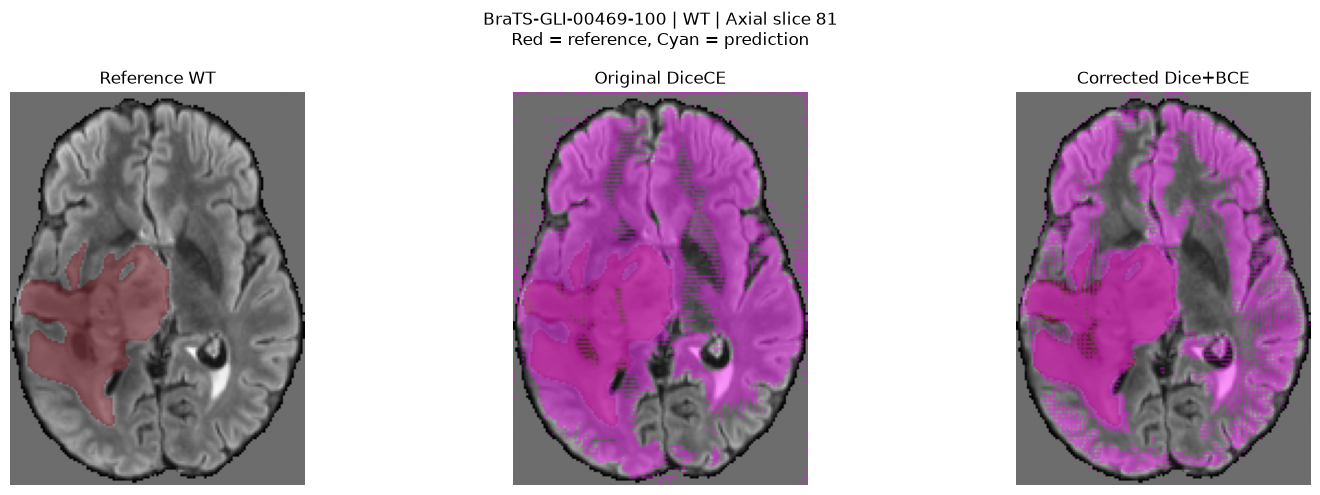

Case: BraTS-GLI-00469-100
Axial slice: 81
WT reference voxels: 143884
Original DiceCE predicted WT voxels: 1099199
Corrected Dice+BCE predicted WT voxels: 725347

WT visual comparison completed.


In [80]:
# -------------------------------------------------------------
# SECTION 35.4 — VISUAL COMPARISON OF WT SEGMENTATION
# -------------------------------------------------------------
#
# Compare the original and corrected model predictions
# on the same MRI slice.
#
# Case: BraTS-GLI-00469-100
# Region: WT (whole tumour)
#
# Red: reference WT
# Cyan: predicted WT
#
# GPU inference only; no training.

import numpy as np
import matplotlib.pyplot as plt
import torch

from monai.inferers import sliding_window_inference

# -------------------------------------------------------------
# STEP 1 — SELECT THE SAME VALIDATION CASE
# -------------------------------------------------------------

visual_case_id = "BraTS-GLI-00469-100"

visual_case_index = next(
    index
    for index, case in enumerate(pilot_validation_cases)
    if case["case_id"] == visual_case_id
)

visual_sample = pilot_validation_dataset[
    visual_case_index
]

visual_image = visual_sample["image"].unsqueeze(0)
visual_reference = visual_sample["label"].cpu().numpy()

# -------------------------------------------------------------
# STEP 2 — GENERATE PREDICTIONS FROM BOTH MODELS
# -------------------------------------------------------------

visual_predictions = {}

for model_name, model in {
    "Original DiceCE": evaluation_model,
    "Corrected Dice+BCE": corrected_evaluation_model,
}.items():

    model.eval()

    with torch.inference_mode():

        visual_logits = sliding_window_inference(
            inputs=visual_image.to(evaluation_device),
            roi_size=(96, 96, 96),
            sw_batch_size=1,
            predictor=model,
            overlap=0.25,
            mode="constant",
        )

        visual_predictions[model_name] = (
            (torch.sigmoid(visual_logits) >= 0.5)
            [0]
            .cpu()
            .numpy()
        )

# -------------------------------------------------------------
# STEP 3 — SELECT AN AXIAL SLICE WITH MAXIMUM REFERENCE WT
# -------------------------------------------------------------

wt_reference = visual_reference[0]

slice_index = int(
    np.argmax(wt_reference.sum(axis=(0, 1)))
)

# T2-FLAIR is channel 3 in our four-modality ordering.
flair_slice = visual_image[0, 3, :, :, slice_index].numpy()

reference_slice = wt_reference[:, :, slice_index]

# -------------------------------------------------------------
# STEP 4 — PLOT SIDE-BY-SIDE OVERLAYS
# -------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5),
)

panels = [
    ("Reference WT", None),
    (
        "Original DiceCE",
        visual_predictions["Original DiceCE"][0],
    ),
    (
        "Corrected Dice+BCE",
        visual_predictions["Corrected Dice+BCE"][0],
    ),
]

for ax, (title, prediction_volume) in zip(
    axes, panels
):

    ax.imshow(
        flair_slice.T,
        cmap="gray",
        origin="lower",
    )

    # Reference WT: red.
    reference_overlay = np.ma.masked_where(
        ~reference_slice.astype(bool),
        reference_slice,
    )

    ax.imshow(
        reference_overlay.T,
        cmap="Reds",
        alpha=0.45,
        origin="lower",
        vmin=0,
        vmax=1,
    )

    # Predicted WT: cyan.
    if prediction_volume is not None:

        prediction_slice = (
            prediction_volume[:, :, slice_index]
        )

        prediction_overlay = np.ma.masked_where(
            ~prediction_slice.astype(bool),
            prediction_slice,
        )

        ax.imshow(
            prediction_overlay.T,
            cmap="cool",
            alpha=0.40,
            origin="lower",
            vmin=0,
            vmax=1,
        )

    ax.set_title(title)
    ax.axis("off")

plt.suptitle(
    f"{visual_case_id} | WT | Axial slice {slice_index}\n"
    "Red = reference, Cyan = prediction",
    fontsize=12,
)

plt.tight_layout()
plt.show()

print("Case:", visual_case_id)
print("Axial slice:", slice_index)
print("WT reference voxels:", int(wt_reference.sum()))

for model_name, prediction in visual_predictions.items():
    print(
        f"{model_name} predicted WT voxels:",
        int(prediction[0].sum()),
    )

print("\nWT visual comparison completed.")

In [81]:
# -------------------------------------------------------------
# SECTION 35.5 — CORRECTED WT PROBABILITY DISTRIBUTIONS
# -------------------------------------------------------------
#
# Investigate whether false-positive WT predictions have
# probabilities close to the default threshold of 0.5.
#
# Case: BraTS-GLI-00469-100
#
# GPU inference only; no training.

import numpy as np
import torch

from monai.inferers import sliding_window_inference

# -------------------------------------------------------------
# STEP 1 — RUN CORRECTED MODEL INFERENCE
# -------------------------------------------------------------

corrected_evaluation_model.eval()

with torch.inference_mode():

    probability_logits = sliding_window_inference(
        inputs=visual_image.to(evaluation_device),
        roi_size=(96, 96, 96),
        sw_batch_size=1,
        predictor=corrected_evaluation_model,
        overlap=0.25,
        mode="constant",
    )

    corrected_wt_probabilities = (
        torch.sigmoid(probability_logits)[0, 0]
        .cpu()
        .numpy()
    )

# -------------------------------------------------------------
# STEP 2 — IDENTIFY REFERENCE WT AND BACKGROUND
# -------------------------------------------------------------

reference_wt_mask = (
    visual_reference[0] > 0
)

# Define brain/foreground from the nonzero MRI signal.
# This excludes most of the zero-padded image background.
mri_foreground_mask = (
    np.any(
        visual_image[0].cpu().numpy() != 0,
        axis=0,
    )
)

inside_wt = corrected_wt_probabilities[
    reference_wt_mask
]

outside_wt_in_brain = corrected_wt_probabilities[
    (~reference_wt_mask) & mri_foreground_mask
]

outside_brain = corrected_wt_probabilities[
    ~mri_foreground_mask
]

# -------------------------------------------------------------
# STEP 3 — SUMMARISE PROBABILITIES
# -------------------------------------------------------------

def summarise_probabilities(name, values):

    print(f"\n{name}")
    print("Voxels:", len(values))
    print("Mean:", round(float(np.mean(values)), 4))
    print("Median:", round(float(np.median(values)), 4))
    print("90th percentile:", round(float(np.percentile(values, 90)), 4))
    print("99th percentile:", round(float(np.percentile(values, 99)), 4))

    for threshold in (0.5, 0.7, 0.9, 0.99):

        fraction = np.mean(values >= threshold)

        print(
            f"Fraction >= {threshold:.2f}: "
            f"{fraction:.4f}"
        )


summarise_probabilities(
    "Reference WT",
    inside_wt,
)

summarise_probabilities(
    "Non-WT MRI foreground",
    outside_wt_in_brain,
)

summarise_probabilities(
    "Outside MRI foreground",
    outside_brain,
)

print("\nCorrected WT probability analysis completed.")


Reference WT
Voxels: 143884
Mean: 0.7317
Median: 0.7333
90th percentile: 0.8925
99th percentile: 0.9525
Fraction >= 0.50: 0.9784
Fraction >= 0.70: 0.5892
Fraction >= 0.90: 0.0836
Fraction >= 0.99: 0.0000

Non-WT MRI foreground
Voxels: 1402572
Mean: 0.4729
Median: 0.4696
90th percentile: 0.6558
99th percentile: 0.8049
Fraction >= 0.50: 0.4149
Fraction >= 0.70: 0.0580
Fraction >= 0.90: 0.0008
Fraction >= 0.99: 0.0000

Outside MRI foreground
Voxels: 2098544
Mean: 0.318
Median: 0.3164
90th percentile: 0.3944
99th percentile: 0.4579
Fraction >= 0.50: 0.0013
Fraction >= 0.70: 0.0000
Fraction >= 0.90: 0.0000
Fraction >= 0.99: 0.0000

Corrected WT probability analysis completed.


WT THRESHOLD SENSITIVITY
 threshold   dice  precision  recall  volume_ratio
    0.3000 0.1013     0.0533  1.0000       18.7441
    0.3500 0.1432     0.0771  0.9998       12.9676
    0.4000 0.2015     0.1121  0.9989        8.9128
    0.4500 0.2620     0.1509  0.9943        6.5891
    0.5000 0.3239     0.1941  0.9784        5.0412
    0.5500 0.3959     0.2515  0.9302        3.6990
    0.6000 0.4671     0.3234  0.8407        2.5997
    0.6500 0.5221     0.4091  0.7214        1.7634
    0.7000 0.5467     0.5099  0.5892        1.1555
    0.7500 0.5289     0.6282  0.4567        0.7269
    0.8000 0.4564     0.7524  0.3276        0.4354
    0.8500 0.3249     0.8563  0.2005        0.2341
    0.9000 0.1533     0.9181  0.0836        0.0911
    0.9500 0.0232     0.9467  0.0117        0.0124

Highest observed Dice (exploratory):
Threshold: 0.7
Dice: 0.5467
Precision: 0.5099
Recall: 0.5892
Volume ratio: 1.16


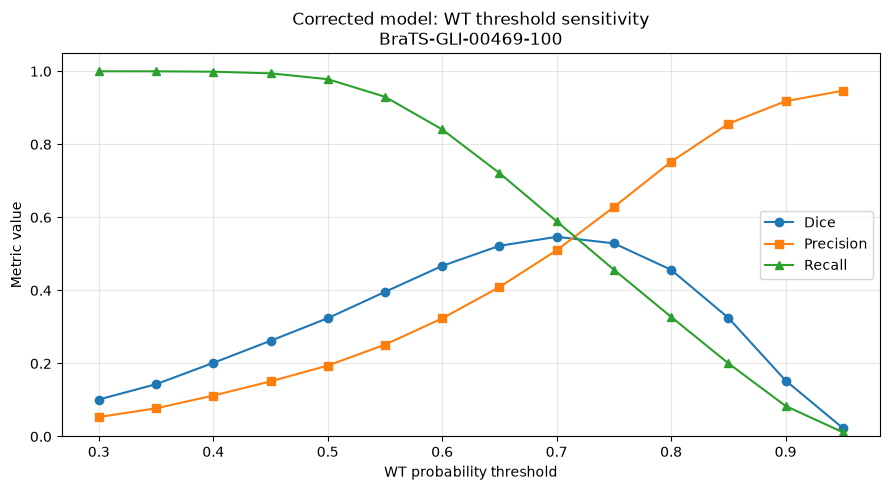


WT threshold sensitivity analysis PASSED.


In [82]:
# -------------------------------------------------------------
# SECTION 35.6 — WT THRESHOLD SENSITIVITY ANALYSIS
# -------------------------------------------------------------
#
# Evaluate how different probability thresholds affect:
#   - Dice similarity
#   - Precision
#   - Recall
#   - Predicted/reference volume ratio
#
# Uses the corrected model's probability volume from Cell 64.
#
# No GPU inference or training is performed.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# STEP 1 — VERIFY EXISTING PROBABILITY AND REFERENCE MASKS
# -------------------------------------------------------------

assert corrected_wt_probabilities.shape == (
    reference_wt_mask.shape
)

assert np.isfinite(corrected_wt_probabilities).all()

assert reference_wt_mask.sum() > 0

# -------------------------------------------------------------
# STEP 2 — DEFINE THRESHOLDS
# -------------------------------------------------------------

wt_thresholds = np.round(
    np.arange(0.30, 0.951, 0.05),
    2,
)

threshold_results = []

reference_voxels = int(reference_wt_mask.sum())

# -------------------------------------------------------------
# STEP 3 — CALCULATE METRICS AT EACH THRESHOLD
# -------------------------------------------------------------

for threshold in wt_thresholds:

    predicted_mask = (
        corrected_wt_probabilities >= threshold
    )

    predicted_voxels = int(predicted_mask.sum())

    true_positive = int(
        np.logical_and(
            predicted_mask,
            reference_wt_mask,
        ).sum()
    )

    false_positive = predicted_voxels - true_positive
    false_negative = reference_voxels - true_positive

    dice_denominator = (
        2 * true_positive
        + false_positive
        + false_negative
    )

    dice = (
        2 * true_positive / dice_denominator
        if dice_denominator > 0
        else np.nan
    )

    precision = (
        true_positive / predicted_voxels
        if predicted_voxels > 0
        else np.nan
    )

    recall = true_positive / reference_voxels

    volume_ratio = (
        predicted_voxels / reference_voxels
    )

    threshold_results.append({
        "threshold": float(threshold),
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall),
        "volume_ratio": float(volume_ratio),
    })

threshold_df = pd.DataFrame(threshold_results)

# -------------------------------------------------------------
# STEP 4 — IDENTIFY HIGHEST OBSERVED DICE
# -------------------------------------------------------------

best_row = threshold_df.loc[
    threshold_df["dice"].idxmax()
]

print("WT THRESHOLD SENSITIVITY")
print(
    threshold_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}",
    )
)

print("\nHighest observed Dice (exploratory):")
print("Threshold:", round(best_row["threshold"], 2))
print("Dice:", round(best_row["dice"], 4))
print("Precision:", round(best_row["precision"], 4))
print("Recall:", round(best_row["recall"], 4))
print("Volume ratio:", round(best_row["volume_ratio"], 2))

# -------------------------------------------------------------
# STEP 5 — VISUALISE METRIC TRADE-OFFS
# -------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["threshold"],
    threshold_df["dice"],
    marker="o",
    label="Dice",
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="s",
    label="Precision",
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="^",
    label="Recall",
)

plt.xlabel("WT probability threshold")
plt.ylabel("Metric value")
plt.title(
    "Corrected model: WT threshold sensitivity\n"
    "BraTS-GLI-00469-100"
)

plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("\nWT threshold sensitivity analysis PASSED.")

Completed: BraTS-GLI-00033-100
Completed: BraTS-GLI-00033-101
Completed: BraTS-GLI-00469-100
Completed: BraTS-GLI-00469-101

MEAN WT METRICS ACROSS FOUR CASES
 threshold  mean_dice  mean_precision  mean_recall
    0.3000     0.0390          0.0202       1.0000
    0.3500     0.0559          0.0295       0.9999
    0.4000     0.0789          0.0426       0.9995
    0.4500     0.1036          0.0575       0.9975
    0.5000     0.1315          0.0751       0.9905
    0.5500     0.1674          0.0996       0.9708
    0.6000     0.2119          0.1335       0.9330
    0.6500     0.2650          0.1803       0.8748
    0.7000     0.3268          0.2461       0.7955
    0.7500     0.3972          0.3419       0.6948
    0.8000     0.4637          0.4787       0.5737
    0.8500     0.4828          0.6600       0.4309
    0.9000     0.3843          0.8324       0.2662
    0.9500     0.1785          0.9348       0.1016

Highest observed mean WT Dice:
Threshold: 0.85
Mean Dice: 0.4828
Mean preci

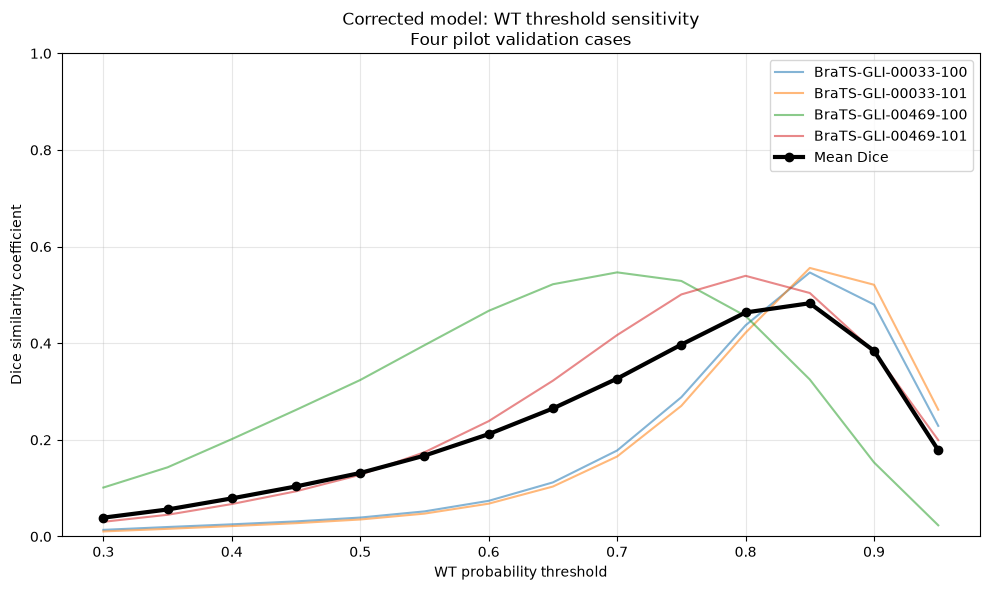


Multi-case WT threshold analysis PASSED.


In [83]:
# -------------------------------------------------------------
# SECTION 35.7 — MULTI-CASE WT THRESHOLD ANALYSIS
# -------------------------------------------------------------
#
# Evaluate WT segmentation at different thresholds across
# all four pilot validation cases.
#
# This helps determine whether the threshold behaviour
# observed in one case generalises to the small pilot subset.
#
# No training or checkpoint modifications.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from monai.inferers import sliding_window_inference

# -------------------------------------------------------------
# STEP 1 — DEFINE THRESHOLDS
# -------------------------------------------------------------

multi_case_thresholds = np.round(
    np.arange(0.30, 0.951, 0.05),
    2,
)

multi_case_results = []

corrected_evaluation_model.eval()

# -------------------------------------------------------------
# STEP 2 — EVALUATE EACH VALIDATION CASE
# -------------------------------------------------------------

for case_index, case in enumerate(
    pilot_validation_cases
):

    case_id = case["case_id"]

    sample = pilot_validation_dataset[case_index]

    image = sample["image"].unsqueeze(0)
    reference_wt = (
        sample["label"][0].cpu().numpy() > 0
    )

    assert reference_wt.sum() > 0

    # Run full-volume inference once per case.
    with torch.inference_mode():

        logits = sliding_window_inference(
            inputs=image.to(evaluation_device),
            roi_size=(96, 96, 96),
            sw_batch_size=1,
            predictor=corrected_evaluation_model,
            overlap=0.25,
            mode="constant",
        )

        wt_probabilities = (
            torch.sigmoid(logits)[0, 0]
            .cpu()
            .numpy()
        )

    # Calculate Dice for every threshold without
    # repeating inference.
    for threshold in multi_case_thresholds:

        prediction = (
            wt_probabilities >= threshold
        )

        true_positive = np.logical_and(
            prediction,
            reference_wt,
        ).sum()

        predicted_voxels = prediction.sum()
        reference_voxels = reference_wt.sum()

        dice = (
            2 * true_positive
            / (predicted_voxels + reference_voxels)
        )

        precision = (
            true_positive / predicted_voxels
            if predicted_voxels > 0
            else np.nan
        )

        recall = (
            true_positive / reference_voxels
        )

        multi_case_results.append({
            "case_id": case_id,
            "threshold": float(threshold),
            "dice": float(dice),
            "precision": float(precision),
            "recall": float(recall),
        })

    print("Completed:", case_id)

# -------------------------------------------------------------
# STEP 3 — AGGREGATE MEAN METRICS
# -------------------------------------------------------------

multi_case_df = pd.DataFrame(
    multi_case_results
)

threshold_summary = (
    multi_case_df
    .groupby("threshold", as_index=False)
    .agg(
        mean_dice=("dice", "mean"),
        mean_precision=("precision", "mean"),
        mean_recall=("recall", "mean"),
    )
)

print("\nMEAN WT METRICS ACROSS FOUR CASES")
print(
    threshold_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}",
    )
)

# -------------------------------------------------------------
# STEP 4 — IDENTIFY EXPLORATORY BEST THRESHOLD
# -------------------------------------------------------------

best_threshold_row = threshold_summary.loc[
    threshold_summary["mean_dice"].idxmax()
]

print("\nHighest observed mean WT Dice:")
print("Threshold:", best_threshold_row["threshold"])
print("Mean Dice:", round(best_threshold_row["mean_dice"], 4))
print("Mean precision:", round(best_threshold_row["mean_precision"], 4))
print("Mean recall:", round(best_threshold_row["mean_recall"], 4))

# -------------------------------------------------------------
# STEP 5 — VISUALISE PER-CASE AND MEAN DICE
# -------------------------------------------------------------

plt.figure(figsize=(10, 6))

for case_id, case_df in multi_case_df.groupby("case_id"):

    plt.plot(
        case_df["threshold"],
        case_df["dice"],
        alpha=0.55,
        label=case_id,
    )

plt.plot(
    threshold_summary["threshold"],
    threshold_summary["mean_dice"],
    color="black",
    linewidth=3,
    marker="o",
    label="Mean Dice",
)

plt.xlabel("WT probability threshold")
plt.ylabel("Dice similarity coefficient")
plt.title(
    "Corrected model: WT threshold sensitivity\n"
    "Four pilot validation cases"
)

plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# STEP 6 — SAVE RESULTS
# -------------------------------------------------------------

multi_case_df.to_csv(
    corrected_log_directory
    / "wt_threshold_per_case.csv",
    index=False,
)

threshold_summary.to_csv(
    corrected_log_directory
    / "wt_threshold_summary.csv",
    index=False,
)

print("\nMulti-case WT threshold analysis PASSED.")

In [84]:
# -------------------------------------------------------------
# SECTION 35.8 — DOCUMENT THRESHOLD SENSITIVITY
# -------------------------------------------------------------
#
# Save the exploratory best WT threshold for each case
# and the best threshold based on mean Dice.
#
# These thresholds are exploratory, not independently
# validated operating thresholds.
#
# No GPU operations are performed.

import json
import pandas as pd

# -------------------------------------------------------------
# STEP 1 — IDENTIFY BEST THRESHOLD PER CASE
# -------------------------------------------------------------

best_case_indices = (
    multi_case_df
    .groupby("case_id")["dice"]
    .idxmax()
)

best_per_case = (
    multi_case_df
    .loc[
        best_case_indices,
        ["case_id", "threshold", "dice", "precision", "recall"]
    ]
    .sort_values("case_id")
    .reset_index(drop=True)
)

print("BEST OBSERVED WT THRESHOLD PER CASE")

print(
    best_per_case.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}",
    )
)

# -------------------------------------------------------------
# STEP 2 — IDENTIFY BEST MEAN THRESHOLD
# -------------------------------------------------------------

best_mean_row = threshold_summary.loc[
    threshold_summary["mean_dice"].idxmax()
]

print("\nBEST OBSERVED MEAN WT THRESHOLD")

print("Threshold:", float(best_mean_row["threshold"]))
print("Mean Dice:", round(float(best_mean_row["mean_dice"]), 4))
print(
    "Mean precision:",
    round(float(best_mean_row["mean_precision"]), 4),
)
print(
    "Mean recall:",
    round(float(best_mean_row["mean_recall"]), 4),
)

# -------------------------------------------------------------
# STEP 3 — SAVE SUMMARY
# -------------------------------------------------------------

threshold_report = {
    "experiment_id": corrected_experiment_id,
    "region": "WT",
    "validation_cases": len(pilot_validation_cases),
    "independent_validation_subjects": len({
        case["subject_id"]
        for case in pilot_validation_cases
    }),
    "threshold_selection": "exploratory_validation_only",
    "best_mean_threshold": float(
        best_mean_row["threshold"]
    ),
    "best_mean_dice": float(
        best_mean_row["mean_dice"]
    ),
    "per_case_results": best_per_case.to_dict(
        orient="records"
    ),
    "limitations": [
        "Only four validation cases from two subjects.",
        "Thresholds selected and evaluated on the same cases.",
        "Results are not independently validated.",
        "WT only; TC, ET and RC thresholds not evaluated.",
    ],
}

threshold_report_path = (
    corrected_log_directory
    / "wt_threshold_exploratory_summary.json"
)

with threshold_report_path.open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        threshold_report,
        file,
        indent=2,
    )

assert threshold_report_path.is_file()

print("\nSaved:", threshold_report_path)
print("WT threshold experiment documentation PASSED.")

BEST OBSERVED WT THRESHOLD PER CASE
            case_id  threshold   dice  precision  recall
BraTS-GLI-00033-100     0.8500 0.5464     0.5469  0.5459
BraTS-GLI-00033-101     0.8500 0.5558     0.5286  0.5861
BraTS-GLI-00469-100     0.7000 0.5467     0.5099  0.5892
BraTS-GLI-00469-101     0.8000 0.5395     0.5499  0.5295

BEST OBSERVED MEAN WT THRESHOLD
Threshold: 0.85
Mean Dice: 0.4828
Mean precision: 0.66
Mean recall: 0.4309

Saved: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/wt_threshold_exploratory_summary.json
WT threshold experiment documentation PASSED.


### Section 35.9 — Segmentation Model Troubleshooting and Hyperparameter Investigation

Following the initial 3D U-Net training pilot, segmentation performance was evaluated to identify potential causes of poor tumour delineation and determine which modelling parameters required adjustment.

#### 1. Initial segmentation problems

The original model demonstrated very low Dice scores across WT, TC, ET and RC, despite decreasing training and validation losses.

Visual inspection revealed extensive **oversegmentation**, with predicted masks extending into normal brain tissue and occasionally outside the brain. Some predictions also exhibited grid-like patterns.

Quantitative evaluation confirmed that the model frequently achieved high recall but extremely low precision, indicating that it identified many genuine tumour voxels while simultaneously producing excessive false-positive predictions.

#### 2. Investigation and correction of the loss function

The original training configuration used MONAI's `DiceCELoss` for four overlapping binary segmentation channels.

Inspection of the underlying implementation revealed that the cross-entropy component was categorical rather than binary, making it unsuitable for the multi-label segmentation targets.

The loss function was therefore replaced with a custom `MultiLabelDiceBCELoss`, combining sigmoid Dice loss and `BCEWithLogitsLoss` with equal weighting.

A second 10-epoch pilot was trained using the same architecture, dataset subsets, patch dimensions, optimiser and learning rate.

**The corrected model improved mean Dice scores across all four regions**, although oversegmentation persisted.

| Region | Original Dice | Corrected Dice |
|---|---:|---:|
| WT | 0.0906 | 0.1315 |
| TC | 0.0242 | 0.0935 |
| ET | 0.0091 | 0.0553 |
| RC | 0.0394 | 0.1411 |

This demonstrated that the loss formulation was an important contributor to poor performance, but was not the only limitation.

#### 3. Probability threshold optimisation

The corrected model continued to generate excessive false positives at the default sigmoid probability threshold of **0.50**.

Analysis of the predicted probability distributions showed that reference tumour voxels generally received higher probabilities than non-tumour voxels, suggesting that the network had learned some useful discriminative features.

A threshold sensitivity analysis was therefore performed, varying the WT classification threshold from 0.30 to 0.95.

Increasing the threshold improved precision and reduced oversegmentation, but also decreased recall.

The best observed WT thresholds differed between validation cases:

| Case | Best observed threshold | WT Dice |
|---|---:|---:|
| BraTS-GLI-00033-100 | 0.85 | 0.5464 |
| BraTS-GLI-00033-101 | 0.85 | 0.5558 |
| BraTS-GLI-00469-100 | 0.70 | 0.5467 |
| BraTS-GLI-00469-101 | 0.80 | 0.5395 |

A common threshold of **0.85** produced the highest mean WT Dice across the four cases, increasing it from approximately **0.13 at threshold 0.50 to 0.48**.

However, this improvement came at the expense of sensitivity, with mean recall falling to approximately 0.43.

These thresholds were explored on only four validation cases from two subjects and must not be regarded as independently validated operating thresholds.

#### 4. Remaining issues and proposed hyperparameter adjustments

The investigations identified several potential areas for further optimisation:

| Parameter or component | Current configuration | Proposed investigation |
|---|---|---|
| Loss function | Corrected sigmoid Dice + BCE | Retain as baseline; investigate alternative loss weighting if necessary |
| Probability threshold | 0.50 initially | Evaluate region-specific thresholds on a larger validation cohort |
| Training dataset | 24 cases | Increase training cases and subject diversity |
| Training duration | 10 epochs | Increase epochs and monitor validation performance |
| Patch sampling | Positive/negative random crops | Investigate better representation of small TC, ET and RC regions |
| Sliding-window inference | 25% overlap, constant blending | Investigate possible boundary artefacts and Gaussian blending |
| Network architecture | 3D U-Net | Retain initially; reconsider only after training and sampling improvements |

These are **proposed investigations**, not changes already tested. In particular, the effects of longer training, alternative patch sampling and Gaussian blending have not yet been established.

#### 5. Overall interpretation

The troubleshooting process identified two important contributors to poor segmentation:

1. **An inappropriate loss formulation**, which was corrected and resulted in improved segmentation performance.
2. **Excessive false-positive classification at the default probability threshold**, which could be partially mitigated through threshold adjustment.

The results suggest that the network has begun learning meaningful imaging features but has not yet developed sufficiently reliable spatial discrimination.

The next priority is to train the corrected model on a larger and more representative dataset, while investigating class imbalance, sampling strategies and inference artefacts.

**The objective of subsequent experiments will be to improve genuine segmentation accuracy and generalisation, rather than simply minimise training loss or maximise Dice on the small pilot validation subset.**

In [85]:
# -------------------------------------------------------------
# SECTION 36.1 — VERIFY FULL DATASET SPLIT
# -------------------------------------------------------------
#
# Review the subject-level training, validation and test
# partitions before designing a larger training experiment.
#
# This cell:
#   - Checks the number of cases in each partition
#   - Counts independent subjects
#   - Verifies that subjects do not cross partitions
#   - Checks for duplicate case IDs
#
# No MRI files are loaded.
# No GPU operations are performed.

# -------------------------------------------------------------
# STEP 1 — COLLECT DATASET PARTITIONS
# -------------------------------------------------------------

dataset_partitions = {
    "Training": train_cases,
    "Validation": validation_cases,
    "Test": test_cases,
}

partition_subjects = {}
all_case_ids = []

# -------------------------------------------------------------
# STEP 2 — INSPECT EACH PARTITION
# -------------------------------------------------------------

print("FULL DATASET SPLIT")
print("-" * 55)

for partition_name, cases in dataset_partitions.items():

    case_ids = [
        case["case_id"]
        for case in cases
    ]

    subject_ids = {
        case["subject_id"]
        for case in cases
    }

    # Check that cases are unique within each partition.
    assert len(case_ids) == len(set(case_ids)), (
        f"Duplicate case IDs in {partition_name}."
    )

    partition_subjects[partition_name] = subject_ids
    all_case_ids.extend(case_ids)

    print(
        f"{partition_name:12s} "
        f"Cases: {len(cases):4d} | "
        f"Subjects: {len(subject_ids):4d}"
    )

# -------------------------------------------------------------
# STEP 3 — VERIFY SUBJECT-LEVEL INDEPENDENCE
# -------------------------------------------------------------

assert partition_subjects["Training"].isdisjoint(
    partition_subjects["Validation"]
)

assert partition_subjects["Training"].isdisjoint(
    partition_subjects["Test"]
)

assert partition_subjects["Validation"].isdisjoint(
    partition_subjects["Test"]
)

print("\nSubject-level separation: PASSED")

# -------------------------------------------------------------
# STEP 4 — VERIFY DATASET TOTALS
# -------------------------------------------------------------

assert len(train_cases) == 936
assert len(validation_cases) == 216
assert len(test_cases) == 198

assert len(all_case_ids) == 1350

assert len(all_case_ids) == len(set(all_case_ids)), (
    "Duplicate case IDs detected across partitions."
)

total_subjects = len(
    set().union(*partition_subjects.values())
)

print("\nTotal cases:", len(all_case_ids))
print("Total independent subjects:", total_subjects)

print("\nFull dataset split verification PASSED.")

FULL DATASET SPLIT
-------------------------------------------------------
Training     Cases:  936 | Subjects:  429
Validation   Cases:  216 | Subjects:   92
Test         Cases:  198 | Subjects:   92

Subject-level separation: PASSED

Total cases: 1350
Total independent subjects: 613

Full dataset split verification PASSED.


In [86]:
# -------------------------------------------------------------
# SECTION 36.2 — ANALYSE CASE DISTRIBUTION PER SUBJECT
# -------------------------------------------------------------
#
# Determine how many longitudinal MRI cases each subject
# contributes to the training, validation and test datasets.
#
# This will inform subject-diverse sampling for the next
# larger-scale training experiment.
#
# No MRI loading or GPU operations.

from collections import Counter
import numpy as np
import pandas as pd

# -------------------------------------------------------------
# STEP 1 — COUNT CASES PER SUBJECT
# -------------------------------------------------------------

subject_distribution_records = []

for partition_name, cases in dataset_partitions.items():

    subject_counts = Counter(
        case["subject_id"]
        for case in cases
    )

    for subject_id, case_count in subject_counts.items():

        subject_distribution_records.append({
            "partition": partition_name,
            "subject_id": subject_id,
            "case_count": case_count,
        })

subject_distribution_df = pd.DataFrame(
    subject_distribution_records
)

# -------------------------------------------------------------
# STEP 2 — SUMMARISE EACH PARTITION
# -------------------------------------------------------------

distribution_summary = (
    subject_distribution_df
    .groupby("partition")["case_count"]
    .agg(
        subjects="count",
        minimum_cases="min",
        median_cases="median",
        mean_cases="mean",
        maximum_cases="max",
    )
    .reset_index()
)

print("CASES PER SUBJECT — DATASET SUMMARY")

print(
    distribution_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}",
    )
)

# -------------------------------------------------------------
# STEP 3 — SHOW TRAINING SUBJECT DISTRIBUTION
# -------------------------------------------------------------

training_subject_distribution = (
    subject_distribution_df[
        subject_distribution_df["partition"] == "Training"
    ]
)

training_case_frequency = (
    training_subject_distribution["case_count"]
    .value_counts()
    .sort_index()
)

print("\nTRAINING SUBJECTS BY NUMBER OF CASES")

for case_count, number_of_subjects in (
    training_case_frequency.items()
):

    print(
        f"{case_count} case(s): "
        f"{number_of_subjects} subjects"
    )

# -------------------------------------------------------------
# STEP 4 — CHECK CONSISTENCY
# -------------------------------------------------------------

assert (
    training_subject_distribution["case_count"].sum()
    == len(train_cases)
)

assert (
    len(training_subject_distribution)
    == 429
)

print("\nSubject distribution analysis PASSED.")

CASES PER SUBJECT — DATASET SUMMARY
 partition  subjects  minimum_cases  median_cases  mean_cases  maximum_cases
      Test        92              1          2.00        2.15              7
  Training       429              1          2.00        2.18             10
Validation        92              1          2.00        2.35              8

TRAINING SUBJECTS BY NUMBER OF CASES
1 case(s): 87 subjects
2 case(s): 268 subjects
3 case(s): 28 subjects
4 case(s): 21 subjects
5 case(s): 13 subjects
6 case(s): 8 subjects
7 case(s): 2 subjects
8 case(s): 1 subjects
10 case(s): 1 subjects

Subject distribution analysis PASSED.


In [87]:
# -------------------------------------------------------------
# SECTION 36.3 — ANALYSE SEGMENTATION REGION PREVALENCE
# -------------------------------------------------------------
#
# Examine WT, TC, ET and RC prevalence across the complete
# training partition.
#
# Uses raw BraTS segmentation labels:
#   WT = labels 1, 2, 3
#   TC = labels 1, 3
#   ET = label 3
#   RC = label 4
#
# Only segmentation files are loaded.
# No MRI modalities or GPU operations are required.

from pathlib import Path
import nibabel as nib
import numpy as np
import pandas as pd
import time

# -------------------------------------------------------------
# STEP 1 — DEFINE OUTPUT PATH
# -------------------------------------------------------------

region_prevalence_path = (
    corrected_log_directory
    / "training_region_prevalence.csv"
)

# Avoid silently overwriting previous analysis.
assert not region_prevalence_path.exists(), (
    f"Output already exists: {region_prevalence_path}"
)

# -------------------------------------------------------------
# STEP 2 — DEFINE REGION LABELS
# -------------------------------------------------------------

region_label_values = {
    "WT": (1, 2, 3),
    "TC": (1, 3),
    "ET": (3,),
    "RC": (4,),
}

region_prevalence_records = []

analysis_start = time.monotonic()

# -------------------------------------------------------------
# STEP 3 — INSPECT EACH TRAINING CASE
# -------------------------------------------------------------

for case_index, case in enumerate(train_cases, start=1):

    segmentation_path = Path(case["label"])

    assert segmentation_path.is_file(), (
        f"Missing segmentation: {segmentation_path}"
    )

    # Load only the segmentation label volume.
    segmentation_image = nib.load(
        str(segmentation_path)
    )

    segmentation = np.asarray(
        segmentation_image.dataobj
    )

    # Check that the raw labels match our expected mapping.
    observed_labels = set(
        np.unique(segmentation).tolist()
    )

    assert observed_labels.issubset({0, 1, 2, 3, 4}), (
        f"Unexpected labels in {case['case_id']}: "
        f"{observed_labels}"
    )

    record = {
        "case_id": case["case_id"],
        "subject_id": case["subject_id"],
    }

    # Count voxels for each overlapping binary region.
    for region_name, label_values in (
        region_label_values.items()
    ):

        voxel_count = int(
            np.isin(
                segmentation,
                label_values
            ).sum()
        )

        record[f"{region_name}_voxels"] = voxel_count
        record[f"{region_name}_present"] = (
            voxel_count > 0
        )

    region_prevalence_records.append(record)

    if case_index % 100 == 0:
        print(
            f"Processed {case_index}/{len(train_cases)} cases"
        )

# -------------------------------------------------------------
# STEP 4 — CREATE RESULTS DATAFRAME
# -------------------------------------------------------------

region_prevalence_df = pd.DataFrame(
    region_prevalence_records
)

assert len(region_prevalence_df) == len(train_cases)

assert region_prevalence_df["case_id"].is_unique

# -------------------------------------------------------------
# STEP 5 — SUMMARISE REGION PREVALENCE
# -------------------------------------------------------------

print("\nTRAINING REGION PREVALENCE")
print("-" * 55)

for region_name in region_label_values:

    present_count = int(
        region_prevalence_df[
            f"{region_name}_present"
        ].sum()
    )

    prevalence_percent = (
        100 * present_count / len(region_prevalence_df)
    )

    print(
        f"{region_name}: "
        f"{present_count}/{len(region_prevalence_df)} cases "
        f"({prevalence_percent:.1f}%)"
    )

# -------------------------------------------------------------
# STEP 6 — SAVE RESULTS
# -------------------------------------------------------------

region_prevalence_df.to_csv(
    region_prevalence_path,
    index=False,
)

elapsed_minutes = (
    time.monotonic() - analysis_start
) / 60

print(
    "\nAnalysis time:",
    round(elapsed_minutes, 2),
    "minutes"
)

print("Saved:", region_prevalence_path)

print("\nTraining region prevalence analysis PASSED.")

Processed 100/936 cases
Processed 200/936 cases
Processed 300/936 cases
Processed 400/936 cases
Processed 500/936 cases
Processed 600/936 cases
Processed 700/936 cases
Processed 800/936 cases
Processed 900/936 cases

TRAINING REGION PREVALENCE
-------------------------------------------------------
WT: 936/936 cases (100.0%)
TC: 682/936 cases (72.9%)
ET: 679/936 cases (72.5%)
RC: 812/936 cases (86.8%)

Analysis time: 2.61 minutes
Saved: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/training_region_prevalence.csv

Training region prevalence analysis PASSED.


In [88]:
# -------------------------------------------------------------
# SECTION 36.4 — ANALYSE SEGMENTATION REGION SIZES
# -------------------------------------------------------------
#
# Examine the distribution of WT, TC, ET and RC voxel counts
# across the complete training partition.
#
# Important:
#   - Exclude absent regions from size statistics.
#   - Report absence separately.
#   - Use voxel counts rather than assuming physical volumes,
#     because voxel spacing has not been checked here.
#
# This cell uses the existing region_prevalence_df.
# No MRI loading or GPU operations.

import numpy as np
import pandas as pd

# -------------------------------------------------------------
# STEP 1 — SUMMARISE NONZERO REGION SIZES
# -------------------------------------------------------------

region_volume_records = []

for region_name in ("WT", "TC", "ET", "RC"):

    voxel_counts = region_prevalence_df[
        f"{region_name}_voxels"
    ]

    # Region size statistics should exclude cases where
    # the reference region is absent.
    nonzero_counts = voxel_counts[
        voxel_counts > 0
    ]

    region_volume_records.append({
        "region": region_name,
        "present_cases": len(nonzero_counts),
        "absent_cases": int((voxel_counts == 0).sum()),
        "minimum_voxels": int(nonzero_counts.min()),
        "p10_voxels": float(nonzero_counts.quantile(0.10)),
        "median_voxels": float(nonzero_counts.median()),
        "p90_voxels": float(nonzero_counts.quantile(0.90)),
        "maximum_voxels": int(nonzero_counts.max()),
    })

region_volume_summary = pd.DataFrame(
    region_volume_records
)

# -------------------------------------------------------------
# STEP 2 — DISPLAY RESULTS
# -------------------------------------------------------------

print("SEGMENTATION REGION SIZE DISTRIBUTION")
print("(Voxel counts among cases where region is present)")
print("-" * 75)

print(
    region_volume_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:,.0f}",
    )
)

# -------------------------------------------------------------
# STEP 3 — COMPARE MEDIAN REGION SIZES
# -------------------------------------------------------------

wt_median = region_volume_summary.loc[
    region_volume_summary["region"] == "WT",
    "median_voxels"
].iloc[0]

print("\nMEDIAN SIZE RELATIVE TO WT")
print("-" * 40)

for _, row in region_volume_summary.iterrows():

    relative_size = (
        row["median_voxels"] / wt_median
    )

    print(
        f"{row['region']}: "
        f"{relative_size:.3f} × WT median"
    )

# -------------------------------------------------------------
# STEP 4 — VERIFY RESULTS
# -------------------------------------------------------------

assert (
    region_volume_summary["present_cases"]
    + region_volume_summary["absent_cases"]
    == len(train_cases)
).all()

assert (
    region_volume_summary["minimum_voxels"] > 0
).all()

print("\nRegion size analysis PASSED.")

SEGMENTATION REGION SIZE DISTRIBUTION
(Voxel counts among cases where region is present)
---------------------------------------------------------------------------
region  present_cases  absent_cases  minimum_voxels  p10_voxels  median_voxels  p90_voxels  maximum_voxels
    WT            936             0             511      11,229         41,362     131,917          327711
    TC            682           254               1         208          5,337      34,527          171479
    ET            679           257               1         201          4,837      28,450          150383
    RC            812           124               1         655          8,830      42,877          165848

MEDIAN SIZE RELATIVE TO WT
----------------------------------------
WT: 1.000 × WT median
TC: 0.129 × WT median
ET: 0.117 × WT median
RC: 0.213 × WT median

Region size analysis PASSED.


In [89]:
# -------------------------------------------------------------
# SECTION 36.5 — AUDIT CURRENT TRAINING PATCH SAMPLING
# -------------------------------------------------------------
#
# Examine which segmentation regions are represented in
# patches generated by our existing training transforms.
#
# Uses:
#   - 8 training cases
#   - 2 patches per case
#   - Existing train_transforms
#
# This is a diagnostic sample, not a definitive estimate of
# patch sampling performance across the complete dataset.
#
# No GPU training or inference is performed.

import random
import numpy as np
import pandas as pd

# -------------------------------------------------------------
# STEP 1 — SELECT REPRODUCIBLE CASES
# -------------------------------------------------------------

sampling_rng = random.Random(42)

audit_cases = sampling_rng.sample(
    train_cases,
    k=8,
)

print("Selected cases for patch sampling audit:")

for case in audit_cases:
    print(
        case["case_id"],
        "| Subject:",
        case["subject_id"]
    )

# -------------------------------------------------------------
# STEP 2 — GENERATE PATCHES
# -------------------------------------------------------------

patch_audit_records = []

for case_index, case in enumerate(audit_cases, start=1):

    # Existing transforms include MRI preprocessing,
    # random patch selection and conversion to four
    # binary segmentation channels.
    #
    # RandCropByPosNegLabeld(num_samples=2) returns
    # a list of two transformed patch dictionaries.

    sampled_patches = train_transforms(case)

    assert isinstance(sampled_patches, list)
    assert len(sampled_patches) == 2

    for patch_index, patch in enumerate(
        sampled_patches,
        start=1
    ):

        label = patch["label"]

        # Convert the small label patch to NumPy for
        # voxel-count analysis.
        if hasattr(label, "detach"):
            label = label.detach().cpu().numpy()
        else:
            label = np.asarray(label)

        assert label.shape[0] == 4, (
            f"Unexpected label shape: {label.shape}"
        )

        record = {
            "case_id": case["case_id"],
            "subject_id": case["subject_id"],
            "patch_index": patch_index,
        }

        for channel_index, region_name in enumerate(
            ("WT", "TC", "ET", "RC")
        ):

            voxel_count = int(
                np.count_nonzero(
                    label[channel_index]
                )
            )

            record[f"{region_name}_voxels"] = voxel_count
            record[f"{region_name}_present"] = (
                voxel_count > 0
            )

        patch_audit_records.append(record)

    print(
        f"Processed {case_index}/{len(audit_cases)} cases"
    )

# -------------------------------------------------------------
# STEP 3 — SUMMARISE PATCH CONTENTS
# -------------------------------------------------------------

patch_audit_df = pd.DataFrame(
    patch_audit_records
)

print("\nREGION REPRESENTATION IN SAMPLED PATCHES")
print("-" * 60)

for region_name in ("WT", "TC", "ET", "RC"):

    present_count = int(
        patch_audit_df[
            f"{region_name}_present"
        ].sum()
    )

    percentage = (
        100 * present_count / len(patch_audit_df)
    )

    median_voxels = (
        patch_audit_df[
            f"{region_name}_voxels"
        ].median()
    )

    print(
        f"{region_name}: "
        f"{present_count}/{len(patch_audit_df)} patches "
        f"({percentage:.1f}%) | "
        f"Median voxels: {median_voxels:,.0f}"
    )

# -------------------------------------------------------------
# STEP 4 — VERIFY RESULTS
# -------------------------------------------------------------

assert len(patch_audit_df) == 16

assert (
    patch_audit_df[
        [f"{region}_voxels"
         for region in ("WT", "TC", "ET", "RC")]
    ].to_numpy() >= 0
).all()

print("\nPatch sampling audit PASSED.")

Selected cases for patch sampling audit:
BraTS-GLI-02830-101 | Subject: BraTS-GLI-02830
BraTS-GLI-02085-102 | Subject: BraTS-GLI-02085
BraTS-GLI-00498-101 | Subject: BraTS-GLI-00498
BraTS-GLI-02900-100 | Subject: BraTS-GLI-02900
BraTS-GLI-02206-102 | Subject: BraTS-GLI-02206
BraTS-GLI-02186-101 | Subject: BraTS-GLI-02186
BraTS-GLI-02174-100 | Subject: BraTS-GLI-02174
BraTS-GLI-02099-101 | Subject: BraTS-GLI-02099
Processed 1/8 cases
Processed 2/8 cases
Processed 3/8 cases
Processed 4/8 cases
Processed 5/8 cases
Processed 6/8 cases
Processed 7/8 cases
Processed 8/8 cases

REGION REPRESENTATION IN SAMPLED PATCHES
------------------------------------------------------------
WT: 16/16 patches (100.0%) | Median voxels: 54,312
TC: 10/16 patches (62.5%) | Median voxels: 789
ET: 10/16 patches (62.5%) | Median voxels: 789
RC: 14/16 patches (87.5%) | Median voxels: 3,178

Patch sampling audit PASSED.


In [90]:
# -------------------------------------------------------------
# SECTION 36.6 — COMPARE SOURCE AND PATCH REGION PRESENCE
# -------------------------------------------------------------
#
# Determine whether the current training patch sampler
# misses regions that are present in the original MRI case.
#
# Uses:
#   - region_prevalence_df from Section 36.3
#   - patch_audit_df from Section 36.5
#
# No MRI loading or GPU operations.

import pandas as pd

# -------------------------------------------------------------
# STEP 1 — JOIN PATCH DATA WITH SOURCE-CASE LABEL DATA
# -------------------------------------------------------------

source_region_columns = [
    "case_id",
    "WT_present",
    "TC_present",
    "ET_present",
    "RC_present",
]

patch_source_comparison = patch_audit_df.merge(
    region_prevalence_df[source_region_columns],
    on="case_id",
    how="left",
    suffixes=("_patch", "_source"),
    validate="many_to_one",
)

assert len(patch_source_comparison) == len(patch_audit_df)

# -------------------------------------------------------------
# STEP 2 — MEASURE REGION CAPTURE
# -------------------------------------------------------------

capture_records = []

for region_name in ("WT", "TC", "ET", "RC"):

    source_present = patch_source_comparison[
        f"{region_name}_present_source"
    ].astype(bool)

    patch_present = patch_source_comparison[
        f"{region_name}_present_patch"
    ].astype(bool)

    # Count patches drawn from cases where the region exists.
    eligible_patches = int(source_present.sum())

    # Among eligible patches, count how often the sampler
    # actually included the region.
    captured_patches = int(
        (source_present & patch_present).sum()
    )

    missed_patches = int(
        (source_present & ~patch_present).sum()
    )

    capture_rate = (
        100 * captured_patches / eligible_patches
        if eligible_patches > 0
        else float("nan")
    )

    capture_records.append({
        "region": region_name,
        "eligible_patches": eligible_patches,
        "captured_patches": captured_patches,
        "missed_patches": missed_patches,
        "capture_rate_percent": capture_rate,
    })

capture_summary_df = pd.DataFrame(
    capture_records
)

# -------------------------------------------------------------
# STEP 3 — DISPLAY RESULTS
# -------------------------------------------------------------

print("REGION CAPTURE WHEN PRESENT IN SOURCE CASE")
print("-" * 75)

print(
    capture_summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.1f}",
    )
)

# -------------------------------------------------------------
# STEP 4 — VERIFY RESULTS
# -------------------------------------------------------------

assert (
    capture_summary_df["captured_patches"]
    + capture_summary_df["missed_patches"]
    == capture_summary_df["eligible_patches"]
).all()

# A patch cannot contain a labelled region that is absent
# from its source case.
for region_name in ("WT", "TC", "ET", "RC"):

    invalid_patches = (
        patch_source_comparison[
            f"{region_name}_present_patch"
        ].astype(bool)
        &
        ~patch_source_comparison[
            f"{region_name}_present_source"
        ].astype(bool)
    )

    assert not invalid_patches.any(), (
        f"Unexpected {region_name} in a source-negative case."
    )

print("\nSource-to-patch region capture analysis PASSED.")

REGION CAPTURE WHEN PRESENT IN SOURCE CASE
---------------------------------------------------------------------------
region  eligible_patches  captured_patches  missed_patches  capture_rate_percent
    WT                16                16               0                 100.0
    TC                12                10               2                  83.3
    ET                12                10               2                  83.3
    RC                16                14               2                  87.5

Source-to-patch region capture analysis PASSED.


### Sections 36.1–36.6 — Dataset Characteristics and Training Patch Sampling Analysis

Before expanding model training, we investigated the dataset composition, segmentation-region sizes and effectiveness of the existing patch sampling strategy.

**1. Dataset composition and subject diversity**

The BraTS 2024 GLI dataset contains **1,350 MRI cases from 613 independent subjects**, divided into 936 training, 216 validation and 198 test cases. Subject-level separation was verified with no overlap between partitions.

Within the training partition, 355 of 429 subjects (82.8%) contribute only one or two scans, while some contribute up to 10. This supports selecting a subject-diverse subset for subsequent experiments to avoid disproportionately representing patients with multiple longitudinal scans.

**2. Segmentation-region prevalence and size**

| Region | Cases containing region | Median region size |
|---|---:|---:|
| WT | 936/936 (100.0%) | 41,362 voxels |
| TC | 682/936 (72.9%) | 5,337 voxels |
| ET | 679/936 (72.5%) | 4,837 voxels |
| RC | 812/936 (86.8%) | 8,830 voxels |

Although TC, ET and RC are present in most cases, their median sizes are considerably smaller than WT. TC and ET have median volumes equivalent to approximately 13% and 12% of the WT median, respectively.

This demonstrates substantial **region-size imbalance**, even though the smaller regions are not particularly rare at the case level. The median comparisons are across separate region distributions, not paired within individual cases.

**3. Evaluation of the existing patch sampler**

Our current `RandCropByPosNegLabeld` configuration generates two 96 × 96 × 96 patches per training case using positive/negative foreground sampling.

An exploratory audit of 16 patches from eight randomly selected training cases produced:

| Region | Patches containing region | Capture when present in source case |
|---|---:|---:|
| WT | 16/16 (100%) | 16/16 (100%) |
| TC | 10/16 (62.5%) | 10/12 (83.3%) |
| ET | 10/16 (62.5%) | 10/12 (83.3%) |
| RC | 14/16 (87.5%) | 14/16 (87.5%) |

The sampler successfully captured WT in every examined patch. However, TC, ET and RC were occasionally missed despite being present in the source MRI.

The audit also showed that smaller regions occupied substantially fewer voxels within sampled patches, potentially limiting their contribution to model training.

**4. Interpretation and next steps**

The findings suggest that region-aware patch sampling could improve representation of smaller segmentation targets. However, the audit involved only 16 patches from eight cases and is insufficient to establish a systematic sampling problem or demonstrate that a different sampler would improve performance.

We will therefore **retain the existing sampler for the next baseline experiment**, while increasing training data and subject diversity. This allows us to evaluate the effects of dataset expansion without simultaneously modifying multiple training parameters.

The next phase will construct a reproducible, approximately 180-case subject-diverse training subset, assess its representativeness and prepare a larger-scale training experiment using the corrected Dice+BCE loss function.

In [91]:
# -------------------------------------------------------------
# SECTION 36.7 — CREATE SUBJECT-DIVERSE TRAINING SUBSET
# -------------------------------------------------------------
#
# Construct a reproducible training subset with:
#
#   - Target: 180 MRI cases
#   - Maximum: 2 cases per subject
#   - Fixed random seed: 42
#   - No validation or test cases
#
# The subset will be evaluated for region prevalence
# before being approved for model training.
#
# No MRI loading or GPU operations.

import random
from collections import defaultdict
import pandas as pd

# -------------------------------------------------------------
# STEP 1 — CONFIGURE SUBSET SELECTION
# -------------------------------------------------------------

target_training_cases = 180
maximum_cases_per_subject = 2
subset_seed = 42

subset_rng = random.Random(subset_seed)

# -------------------------------------------------------------
# STEP 2 — GROUP TRAINING CASES BY SUBJECT
# -------------------------------------------------------------

cases_by_subject = defaultdict(list)

for case in train_cases:

    cases_by_subject[
        case["subject_id"]
    ].append(case)

# Randomise subject order to avoid dataset ordering bias.
subject_ids = list(cases_by_subject.keys())

subset_rng.shuffle(subject_ids)

# -------------------------------------------------------------
# STEP 3 — SELECT CASES
# -------------------------------------------------------------
#
# First select one case per subject to maximise diversity.
# Since there are 429 training subjects, we can reach the
# target of 180 without needing multiple cases per subject.
#
# This produces a particularly subject-diverse baseline.

selected_training_cases = []

for subject_id in subject_ids:

    subject_cases = cases_by_subject[subject_id].copy()

    subset_rng.shuffle(subject_cases)

    selected_training_cases.append(
        subject_cases[0]
    )

    if len(selected_training_cases) >= target_training_cases:
        break

# -------------------------------------------------------------
# STEP 4 — VERIFY SUBSET
# -------------------------------------------------------------

selected_case_ids = {
    case["case_id"]
    for case in selected_training_cases
}

selected_subject_ids = {
    case["subject_id"]
    for case in selected_training_cases
}

assert len(selected_training_cases) == 180

assert len(selected_case_ids) == 180

assert len(selected_subject_ids) == 180

assert selected_subject_ids.isdisjoint(
    partition_subjects["Validation"]
)

assert selected_subject_ids.isdisjoint(
    partition_subjects["Test"]
)

# -------------------------------------------------------------
# STEP 5 — COMPARE REGION PREVALENCE
# -------------------------------------------------------------

selected_region_df = region_prevalence_df[
    region_prevalence_df["case_id"].isin(
        selected_case_ids
    )
].copy()

assert len(selected_region_df) == 180

print("SELECTED TRAINING SUBSET")
print("-" * 55)

print("Cases:", len(selected_training_cases))
print("Independent subjects:", len(selected_subject_ids))
print("Maximum cases per subject: 1")
print("Random seed:", subset_seed)

print("\nREGION PREVALENCE COMPARISON")
print("-" * 55)

for region_name in ("WT", "TC", "ET", "RC"):

    full_prevalence = (
        region_prevalence_df[
            f"{region_name}_present"
        ].mean() * 100
    )

    subset_prevalence = (
        selected_region_df[
            f"{region_name}_present"
        ].mean() * 100
    )

    print(
        f"{region_name}: "
        f"Full = {full_prevalence:.1f}% | "
        f"Subset = {subset_prevalence:.1f}% | "
        f"Difference = "
        f"{subset_prevalence - full_prevalence:+.1f} pp"
    )

print("\nSubject-diverse subset construction PASSED.")

SELECTED TRAINING SUBSET
-------------------------------------------------------
Cases: 180
Independent subjects: 180
Maximum cases per subject: 1
Random seed: 42

REGION PREVALENCE COMPARISON
-------------------------------------------------------
WT: Full = 100.0% | Subset = 100.0% | Difference = +0.0 pp
TC: Full = 72.9% | Subset = 75.0% | Difference = +2.1 pp
ET: Full = 72.5% | Subset = 74.4% | Difference = +1.9 pp
RC: Full = 86.8% | Subset = 85.6% | Difference = -1.2 pp

Subject-diverse subset construction PASSED.


In [1]:
# -------------------------------------------------------------
# SECTION 36.7 — SESSION RESTORATION CHECK
# -------------------------------------------------------------
#
# Check whether the variables required for dataset selection
# are available in the current Jupyter session.
#
# This cell does not load MRI files or use the GPU.

required_variables = [
    "train_cases",
    "validation_cases",
    "test_cases",
    "region_prevalence_df",
    "partition_subjects",
]

print("SESSION RESTORATION CHECK")
print("-" * 45)

for variable_name in required_variables:

    available = variable_name in globals()

    print(
        f"{variable_name:25s} "
        f"{'AVAILABLE' if available else 'NOT LOADED'}"
    )

SESSION RESTORATION CHECK
---------------------------------------------
train_cases               NOT LOADED
validation_cases          NOT LOADED
test_cases                NOT LOADED
region_prevalence_df      NOT LOADED
partition_subjects        NOT LOADED


In [3]:
# -------------------------------------------------------------
# SECTION 36.7 — RESTORE SAVED DATASET INFORMATION
# CELL 75: VERIFY SAVED FILES AND INSPECT SPLIT STRUCTURE
# -------------------------------------------------------------
#
# Locate the subject-level split manifest and previously
# calculated segmentation-region prevalence results.
#
# This cell does not load MRI volumes, train models,
# or use the GPU.

from pathlib import Path
import json

# The notebook is inside the repository's notebooks folder.
project_directory = Path.cwd().resolve().parent

split_manifest_path = (
    project_directory
    / "data"
    / "processed"
    / "subject_level_splits.json"
)

region_prevalence_path = Path(
    "/home/corvus_splendens/experiments/"
    "glioma-mri-segmentation/"
    "pilot_multilabel_dice_bce_20261013_010546/"
    "logs/training_region_prevalence.csv"
)

# -------------------------------------------------------------
# VERIFY SAVED FILES
# -------------------------------------------------------------

print("Project directory:", project_directory)

print("\nSaved file verification:")

for file_path in (
    split_manifest_path,
    region_prevalence_path,
):
    print(
        "FOUND" if file_path.is_file() else "MISSING",
        "|",
        file_path,
    )

assert split_manifest_path.is_file()
assert region_prevalence_path.is_file()

# -------------------------------------------------------------
# INSPECT THE SPLIT MANIFEST
# -------------------------------------------------------------

with split_manifest_path.open(
    "r",
    encoding="utf-8",
) as file:
    saved_splits = json.load(file)

print("\nSplit manifest type:", type(saved_splits).__name__)

if isinstance(saved_splits, dict):
    print("Top-level keys:", list(saved_splits.keys()))

    for key, value in saved_splits.items():
        print(
            f"{key}: {type(value).__name__}",
            f"| Length: {len(value)}"
            if hasattr(value, "__len__")
            else "",
        )

print("\nSaved dataset files verified successfully.")

Project directory: /mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation

Saved file verification:
FOUND | /mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/data/processed/subject_level_splits.json
FOUND | /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/training_region_prevalence.csv

Split manifest type: dict
Top-level keys: ['dataset', 'random_seed', 'split_unit', 'modality_order', 'train', 'validation', 'test']
dataset: str | Length: 26
random_seed: int 
split_unit: str | Length: 7
modality_order: list | Length: 4
train: list | Length: 936
validation: list | Length: 216
test: list | Length: 198

Saved dataset files verified successfully.


In [5]:
# -------------------------------------------------------------
# SECTION 36.7 — RESTORE DATASET VARIABLES
# CELL 76
# -------------------------------------------------------------
#
# Restore the dataset information required for the next
# training experiment from previously saved files.
#
# No MRI volumes are loaded.
# No GPU operations or model training are performed.

import pandas as pd

# -------------------------------------------------------------
# STEP 1 — RESTORE SUBJECT-LEVEL DATASET SPLITS
# -------------------------------------------------------------

train_cases = saved_splits["train"]
validation_cases = saved_splits["validation"]
test_cases = saved_splits["test"]

dataset_partitions = {
    "Training": train_cases,
    "Validation": validation_cases,
    "Test": test_cases,
}

# -------------------------------------------------------------
# STEP 2 — RESTORE SEGMENTATION REGION PREVALENCE
# -------------------------------------------------------------

region_prevalence_df = pd.read_csv(
    region_prevalence_path
)

# -------------------------------------------------------------
# STEP 3 — RECONSTRUCT SUBJECT SETS
# -------------------------------------------------------------

partition_subjects = {}

for partition_name, cases in dataset_partitions.items():

    partition_subjects[partition_name] = {
        case["subject_id"]
        for case in cases
    }

# -------------------------------------------------------------
# STEP 4 — VERIFY DATASET INTEGRITY
# -------------------------------------------------------------

assert len(train_cases) == 936
assert len(validation_cases) == 216
assert len(test_cases) == 198

assert len(region_prevalence_df) == 936

assert region_prevalence_df["case_id"].is_unique

# Verify that the saved prevalence records correspond
# exactly to the training partition.
assert set(region_prevalence_df["case_id"]) == {
    case["case_id"]
    for case in train_cases
}

# Verify subject-level independence.
assert partition_subjects["Training"].isdisjoint(
    partition_subjects["Validation"]
)

assert partition_subjects["Training"].isdisjoint(
    partition_subjects["Test"]
)

assert partition_subjects["Validation"].isdisjoint(
    partition_subjects["Test"]
)

# -------------------------------------------------------------
# STEP 5 — DISPLAY RESTORED DATASET SUMMARY
# -------------------------------------------------------------

print("RESTORED DATASET PARTITIONS")
print("-" * 55)

for partition_name, cases in dataset_partitions.items():

    print(
        f"{partition_name:12s} "
        f"Cases: {len(cases):4d} | "
        f"Subjects: "
        f"{len(partition_subjects[partition_name]):4d}"
    )

print("\nRestored region prevalence records:",
      len(region_prevalence_df))

print("\nSaved dataset restoration PASSED.")

RESTORED DATASET PARTITIONS
-------------------------------------------------------
Training     Cases:  936 | Subjects:  429
Validation   Cases:  216 | Subjects:   92
Test         Cases:  198 | Subjects:   92

Restored region prevalence records: 936

Saved dataset restoration PASSED.


In [8]:
# -------------------------------------------------------------
# SECTION 36.7 — SUBJECT-DIVERSE TRAINING SUBSET
# CELL 77
# -------------------------------------------------------------
#
# Select 180 MRI cases from 180 independent subjects.
#
# Selection strategy:
#   - Random seed: 42
#   - One case per subject
#   - Training partition only
#   - No validation or test subjects
#
# Compare segmentation-region prevalence against the
# complete training dataset.
#
# No MRI loading or GPU operations.

import random
from collections import defaultdict

import pandas as pd

# -------------------------------------------------------------
# STEP 1 — CONFIGURE SUBSET SELECTION
# -------------------------------------------------------------

target_training_cases = 180
subset_seed = 42

subset_rng = random.Random(subset_seed)

# -------------------------------------------------------------
# STEP 2 — GROUP CASES BY SUBJECT
# -------------------------------------------------------------

cases_by_subject = defaultdict(list)

for case in train_cases:
    cases_by_subject[case["subject_id"]].append(case)

# Sort before shuffling so selection is reproducible
# even if the manifest order changes.
subject_ids = sorted(cases_by_subject.keys())

subset_rng.shuffle(subject_ids)

# -------------------------------------------------------------
# STEP 3 — SELECT ONE CASE PER SUBJECT
# -------------------------------------------------------------

selected_training_cases = []

for subject_id in subject_ids[:target_training_cases]:

    # Randomly choose one longitudinal scan from the subject.
    subject_cases = sorted(
        cases_by_subject[subject_id],
        key=lambda case: case["case_id"],
    )

    selected_case = subset_rng.choice(subject_cases)

    selected_training_cases.append(selected_case)

# -------------------------------------------------------------
# STEP 4 — VERIFY SUBJECT INDEPENDENCE
# -------------------------------------------------------------

selected_case_ids = {
    case["case_id"]
    for case in selected_training_cases
}

selected_subject_ids = {
    case["subject_id"]
    for case in selected_training_cases
}

assert len(selected_training_cases) == 180
assert len(selected_case_ids) == 180
assert len(selected_subject_ids) == 180

assert selected_subject_ids.issubset(
    partition_subjects["Training"]
)

assert selected_subject_ids.isdisjoint(
    partition_subjects["Validation"]
)

assert selected_subject_ids.isdisjoint(
    partition_subjects["Test"]
)

# -------------------------------------------------------------
# STEP 5 — COMPARE REGION PREVALENCE
# -------------------------------------------------------------

selected_region_df = region_prevalence_df[
    region_prevalence_df["case_id"].isin(selected_case_ids)
].copy()

assert len(selected_region_df) == 180

print("SELECTED TRAINING SUBSET")
print("-" * 55)

print("Cases:", len(selected_training_cases))
print("Independent subjects:", len(selected_subject_ids))
print("Maximum cases per subject: 1")
print("Random seed:", subset_seed)

print("\nREGION PREVALENCE COMPARISON")
print("-" * 65)

for region_name in ("WT", "TC", "ET", "RC"):

    full_prevalence = (
        region_prevalence_df[
            f"{region_name}_present"
        ].mean() * 100
    )

    subset_prevalence = (
        selected_region_df[
            f"{region_name}_present"
        ].mean() * 100
    )

    difference = subset_prevalence - full_prevalence

    print(
        f"{region_name}: "
        f"Full = {full_prevalence:.1f}% | "
        f"Subset = {subset_prevalence:.1f}% | "
        f"Difference = {difference:+.1f} pp"
    )

print("\nSubject-diverse subset selection PASSED.")

SELECTED TRAINING SUBSET
-------------------------------------------------------
Cases: 180
Independent subjects: 180
Maximum cases per subject: 1
Random seed: 42

REGION PREVALENCE COMPARISON
-----------------------------------------------------------------
WT: Full = 100.0% | Subset = 100.0% | Difference = +0.0 pp
TC: Full = 72.9% | Subset = 75.0% | Difference = +2.1 pp
ET: Full = 72.5% | Subset = 74.4% | Difference = +1.9 pp
RC: Full = 86.8% | Subset = 83.9% | Difference = -2.9 pp

Subject-diverse subset selection PASSED.


In [9]:
# -------------------------------------------------------------
# SECTION 36.8 — SAVE SUBJECT-DIVERSE TRAINING SUBSET
# CELL 78
# -------------------------------------------------------------
#
# Save the exact 180 selected cases to a JSON manifest.
#
# This allows future experiments to reuse the same subjects
# and MRI scans without repeating random selection.
#
# The manifest is saved outside the GitHub repository
# because it contains local absolute file paths.
#
# No MRI loading or GPU operations.

import json
from pathlib import Path

# -------------------------------------------------------------
# STEP 1 — DEFINE MANIFEST LOCATION
# -------------------------------------------------------------

subset_manifest_path = (
    region_prevalence_path.parent
    / "training_subset_180_seed42.json"
)

# -------------------------------------------------------------
# STEP 2 — CONSTRUCT MANIFEST
# -------------------------------------------------------------

subset_manifest = {
    "description": (
        "Subject-diverse training subset for larger-scale "
        "3D U-Net glioma segmentation experiments."
    ),
    "source_partition": "train",
    "random_seed": subset_seed,
    "selection_method": (
        "Randomly select 180 training subjects and "
        "one MRI case per selected subject."
    ),
    "number_of_cases": len(selected_training_cases),
    "number_of_subjects": len(selected_subject_ids),
    "cases": selected_training_cases,
}

# -------------------------------------------------------------
# STEP 3 — SAVE MANIFEST
# -------------------------------------------------------------

# Do not silently overwrite an existing experiment manifest.
assert not subset_manifest_path.exists(), (
    f"Manifest already exists: {subset_manifest_path}"
)

with subset_manifest_path.open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        subset_manifest,
        file,
        indent=2,
    )

# -------------------------------------------------------------
# STEP 4 — RELOAD AND VERIFY
# -------------------------------------------------------------

with subset_manifest_path.open(
    "r",
    encoding="utf-8",
) as file:

    restored_subset_manifest = json.load(file)

restored_training_cases = restored_subset_manifest["cases"]

assert len(restored_training_cases) == 180

assert {
    case["case_id"]
    for case in restored_training_cases
} == selected_case_ids

assert {
    case["subject_id"]
    for case in restored_training_cases
} == selected_subject_ids

# -------------------------------------------------------------
# STEP 5 — DISPLAY RESULT
# -------------------------------------------------------------

print("TRAINING SUBSET MANIFEST")
print("-" * 55)

print("Saved:", subset_manifest_path)
print("Cases:", len(restored_training_cases))
print("Independent subjects:", len(selected_subject_ids))
print("Random seed:", subset_seed)

print("\nTraining subset manifest verification PASSED.")

TRAINING SUBSET MANIFEST
-------------------------------------------------------
Saved: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/training_subset_180_seed42.json
Cases: 180
Independent subjects: 180
Random seed: 42

Training subset manifest verification PASSED.


In [10]:
# -------------------------------------------------------------
# SECTION 36.9 — SELECT SUBJECT-DIVERSE VALIDATION COHORT
# CELL 79
# -------------------------------------------------------------
#
# Select 24 validation cases from 24 independent subjects.
#
# Selection:
#   - Validation partition only
#   - One case per subject
#   - Fixed random seed: 42
#
# This is a representative random subset, not a
# region-enriched validation sample.
#
# No MRI loading or GPU operations.

import random
from collections import defaultdict

# -------------------------------------------------------------
# STEP 1 — CONFIGURE VALIDATION SELECTION
# -------------------------------------------------------------

target_validation_cases = 24
validation_subset_seed = 42

validation_rng = random.Random(validation_subset_seed)

# -------------------------------------------------------------
# STEP 2 — GROUP VALIDATION CASES BY SUBJECT
# -------------------------------------------------------------

validation_cases_by_subject = defaultdict(list)

for case in validation_cases:
    validation_cases_by_subject[
        case["subject_id"]
    ].append(case)

validation_subject_ids = sorted(
    validation_cases_by_subject.keys()
)

validation_rng.shuffle(validation_subject_ids)

# -------------------------------------------------------------
# STEP 3 — SELECT ONE CASE PER SUBJECT
# -------------------------------------------------------------

selected_validation_cases = []

for subject_id in validation_subject_ids[
    :target_validation_cases
]:

    subject_cases = sorted(
        validation_cases_by_subject[subject_id],
        key=lambda case: case["case_id"],
    )

    selected_validation_cases.append(
        validation_rng.choice(subject_cases)
    )

# -------------------------------------------------------------
# STEP 4 — VERIFY SUBJECT INDEPENDENCE
# -------------------------------------------------------------

selected_validation_subject_ids = {
    case["subject_id"]
    for case in selected_validation_cases
}

selected_validation_case_ids = {
    case["case_id"]
    for case in selected_validation_cases
}

assert len(selected_validation_cases) == 24
assert len(selected_validation_subject_ids) == 24
assert len(selected_validation_case_ids) == 24

assert selected_validation_subject_ids.issubset(
    partition_subjects["Validation"]
)

assert selected_validation_subject_ids.isdisjoint(
    partition_subjects["Training"]
)

assert selected_validation_subject_ids.isdisjoint(
    partition_subjects["Test"]
)

# -------------------------------------------------------------
# STEP 5 — DISPLAY COHORT SUMMARY
# -------------------------------------------------------------

print("SELECTED VALIDATION COHORT")
print("-" * 55)

print("Cases:", len(selected_validation_cases))
print(
    "Independent subjects:",
    len(selected_validation_subject_ids)
)
print("Random seed:", validation_subset_seed)

print("\nSelected case IDs:")

for case in selected_validation_cases:
    print(case["case_id"])

print("\nValidation cohort selection PASSED.")

SELECTED VALIDATION COHORT
-------------------------------------------------------
Cases: 24
Independent subjects: 24
Random seed: 42

Selected case IDs:
BraTS-GLI-02736-101
BraTS-GLI-02105-104
BraTS-GLI-02382-100
BraTS-GLI-00469-100
BraTS-GLI-02796-101
BraTS-GLI-02726-100
BraTS-GLI-02116-101
BraTS-GLI-02217-103
BraTS-GLI-02375-101
BraTS-GLI-02260-100
BraTS-GLI-02553-101
BraTS-GLI-02609-101
BraTS-GLI-02817-100
BraTS-GLI-02158-101
BraTS-GLI-02752-101
BraTS-GLI-02813-101
BraTS-GLI-02394-100
BraTS-GLI-02863-100
BraTS-GLI-02828-100
BraTS-GLI-02632-104
BraTS-GLI-02634-101
BraTS-GLI-03019-100
BraTS-GLI-02905-100
BraTS-GLI-02880-100

Validation cohort selection PASSED.


In [11]:
# -------------------------------------------------------------
# SECTION 36.10 — SAVE AND INSPECT VALIDATION COHORT
# CELL 80
# -------------------------------------------------------------
#
# Save the fixed 24-case validation cohort and inspect
# segmentation-region prevalence.
#
# The validation cohort will remain fixed during subsequent
# model development and checkpoint selection.
#
# No GPU operations or model training.

import json
from pathlib import Path

import nibabel as nib
import numpy as np
import pandas as pd

# -------------------------------------------------------------
# STEP 1 — DEFINE MANIFEST LOCATION
# -------------------------------------------------------------

validation_manifest_path = (
    region_prevalence_path.parent
    / "validation_subset_24_seed42.json"
)

assert not validation_manifest_path.exists(), (
    f"Manifest already exists: {validation_manifest_path}"
)

# -------------------------------------------------------------
# STEP 2 — EXAMINE REGION PRESENCE
# -------------------------------------------------------------

validation_region_records = []

region_label_values = {
    "WT": (1, 2, 3),
    "TC": (1, 3),
    "ET": (3,),
    "RC": (4,),
}

for case in selected_validation_cases:

    # Load only the segmentation label file.
    segmentation = np.asarray(
        nib.load(case["label"]).dataobj
    )

    observed_labels = set(
        np.unique(segmentation).tolist()
    )

    assert observed_labels.issubset({0, 1, 2, 3, 4}), (
        f"Unexpected labels in {case['case_id']}"
    )

    record = {
        "case_id": case["case_id"],
        "subject_id": case["subject_id"],
    }

    for region_name, label_values in (
        region_label_values.items()
    ):

        record[f"{region_name}_present"] = bool(
            np.isin(segmentation, label_values).any()
        )

    validation_region_records.append(record)

validation_region_df = pd.DataFrame(
    validation_region_records
)

# -------------------------------------------------------------
# STEP 3 — DISPLAY REGION PREVALENCE
# -------------------------------------------------------------

print("VALIDATION COHORT REGION PREVALENCE")
print("-" * 65)

for region_name in region_label_values:

    validation_count = int(
        validation_region_df[
            f"{region_name}_present"
        ].sum()
    )

    validation_percentage = (
        100 * validation_count
        / len(validation_region_df)
    )

    training_percentage = (
        100 * region_prevalence_df[
            f"{region_name}_present"
        ].mean()
    )

    print(
        f"{region_name}: "
        f"Validation = {validation_count}/24 "
        f"({validation_percentage:.1f}%) | "
        f"Training = {training_percentage:.1f}%"
    )

# -------------------------------------------------------------
# STEP 4 — SAVE THE VALIDATION MANIFEST
# -------------------------------------------------------------

validation_manifest = {
    "description": (
        "Fixed subject-diverse validation cohort for "
        "larger-scale 3D U-Net development."
    ),
    "source_partition": "validation",
    "random_seed": validation_subset_seed,
    "number_of_cases": len(selected_validation_cases),
    "number_of_subjects": len(selected_validation_subject_ids),
    "selection_method": (
        "Randomly select 24 validation subjects and "
        "one MRI case per selected subject."
    ),
    "cases": selected_validation_cases,
}

with validation_manifest_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(validation_manifest, file, indent=2)

# -------------------------------------------------------------
# STEP 5 — VERIFY SAVED MANIFEST
# -------------------------------------------------------------

with validation_manifest_path.open(
    "r",
    encoding="utf-8",
) as file:
    restored_validation_manifest = json.load(file)

assert {
    case["case_id"]
    for case in restored_validation_manifest["cases"]
} == selected_validation_case_ids

assert len(validation_region_df) == 24

print("\nSaved:", validation_manifest_path)
print("Validation cohort manifest verification PASSED.")

VALIDATION COHORT REGION PREVALENCE
-----------------------------------------------------------------
WT: Validation = 24/24 (100.0%) | Training = 100.0%
TC: Validation = 19/24 (79.2%) | Training = 72.9%
ET: Validation = 19/24 (79.2%) | Training = 72.5%
RC: Validation = 19/24 (79.2%) | Training = 86.8%

Saved: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/validation_subset_24_seed42.json
Validation cohort manifest verification PASSED.


In [12]:
# -------------------------------------------------------------
# SECTION 37.1 — CREATE LARGER-SCALE EXPERIMENT
# CELL 81
# -------------------------------------------------------------
#
# Create an independent experiment directory for training
# a 3D U-Net on 180 training cases, with 24 validation cases.
#
# Previous pilot experiments and checkpoints are preserved.
#
# No GPU operations or model training.

from pathlib import Path
from datetime import datetime

# -------------------------------------------------------------
# STEP 1 — DEFINE EXPERIMENT STORAGE
# -------------------------------------------------------------

experiment_root = Path(
    "/home/corvus_splendens/experiments/"
    "glioma-mri-segmentation"
)

assert experiment_root.is_dir(), (
    f"Experiment root not found: {experiment_root}"
)

# -------------------------------------------------------------
# STEP 2 — GENERATE A UNIQUE EXPERIMENT ID
# -------------------------------------------------------------

large_experiment_id = (
    "unet_180train_24val_"
    + datetime.now().strftime("%Y%m%d_%H%M%S")
)

large_experiment_directory = (
    experiment_root / large_experiment_id
)

assert not large_experiment_directory.exists(), (
    "Experiment directory already exists."
)

# -------------------------------------------------------------
# STEP 3 — CREATE EXPERIMENT SUBDIRECTORIES
# -------------------------------------------------------------

large_checkpoint_directory = (
    large_experiment_directory / "checkpoints"
)

large_log_directory = (
    large_experiment_directory / "logs"
)

large_output_directory = (
    large_experiment_directory / "outputs"
)

for directory in (
    large_checkpoint_directory,
    large_log_directory,
    large_output_directory,
):
    directory.mkdir(parents=True, exist_ok=False)

# -------------------------------------------------------------
# STEP 4 — VERIFY INPUT MANIFESTS
# -------------------------------------------------------------

assert subset_manifest_path.is_file(), (
    "Training subset manifest not found."
)

assert validation_manifest_path.is_file(), (
    "Validation subset manifest not found."
)

# -------------------------------------------------------------
# STEP 5 — DISPLAY EXPERIMENT STRUCTURE
# -------------------------------------------------------------

print("LARGER-SCALE 3D U-NET EXPERIMENT")
print("-" * 65)

print("Experiment ID:", large_experiment_id)
print("\nExperiment directory:")
print(large_experiment_directory)

print("\nSubdirectories:")
print("Checkpoints:", large_checkpoint_directory)
print("Logs:       ", large_log_directory)
print("Outputs:    ", large_output_directory)

print("\nInput manifests:")
print("Training:  ", subset_manifest_path)
print("Validation:", validation_manifest_path)

print("\nExperiment directory creation PASSED.")

LARGER-SCALE 3D U-NET EXPERIMENT
-----------------------------------------------------------------
Experiment ID: unet_180train_24val_20261013_203139

Experiment directory:
/home/corvus_splendens/experiments/glioma-mri-segmentation/unet_180train_24val_20261013_203139

Subdirectories:
Checkpoints: /home/corvus_splendens/experiments/glioma-mri-segmentation/unet_180train_24val_20261013_203139/checkpoints
Logs:        /home/corvus_splendens/experiments/glioma-mri-segmentation/unet_180train_24val_20261013_203139/logs
Outputs:     /home/corvus_splendens/experiments/glioma-mri-segmentation/unet_180train_24val_20261013_203139/outputs

Input manifests:
Training:   /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/training_subset_180_seed42.json
Validation: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/validation_subset_24_seed42.json

Experiment directory creation PASSED.


In [13]:
# -------------------------------------------------------------
# SECTION 37.2 — EXPERIMENT CONFIGURATION
# CELL 82
# -------------------------------------------------------------
#
# Record the dataset, architecture, loss function,
# optimisation settings and validation strategy.
#
# This configuration is specific to the new experiment.
#
# No model loading, GPU operations or training.

import json

# -------------------------------------------------------------
# STEP 1 — DEFINE CONFIGURATION
# -------------------------------------------------------------

large_experiment_config = {

    "experiment_id": large_experiment_id,

    "description": (
        "Larger-scale 3D U-Net training using 180 independent "
        "training subjects and 24 independent validation subjects."
    ),

    "random_seed": 42,

    "dataset": {
        "name": "BraTS 2024 GLI",
        "training_manifest": str(subset_manifest_path),
        "validation_manifest": str(validation_manifest_path),
        "training_cases": 180,
        "validation_cases": 24,
        "modality_order": ["t1n", "t1c", "t2w", "t2f"],
        "output_regions": ["WT", "TC", "ET", "RC"],
    },

    "model": {
        "architecture": "MONAI UNet",
        "spatial_dims": 3,
        "in_channels": 4,
        "out_channels": 4,
        "channels": [16, 32, 64, 128, 256],
        "strides": [2, 2, 2, 2],
        "num_res_units": 2,
        "output_activation": "sigmoid",
    },

    "loss": {
        "name": "MultiLabelDiceBCELoss",
        "dice_weight": 1.0,
        "bce_weight": 1.0,
        "dice_smooth_nr": 1e-5,
        "dice_smooth_dr": 1e-5,
    },

    "training": {
        "maximum_epochs": 40,
        "patch_size": [96, 96, 96],
        "patches_per_case": 2,
        "batch_size_cases": 1,
        "optimizer": "AdamW",
        "learning_rate": 1e-4,
        "weight_decay": 1e-5,
        "num_workers": 0,
        "checkpoint_every_epochs": 5,
    },

    "validation": {
        "method": "full_volume_sliding_window",
        "roi_size": [96, 96, 96],
        "sw_batch_size": 1,
        "overlap": 0.25,
        "probability_threshold": 0.5,
        "metric": "region_specific_dice",
        "absent_region_handling": (
            "Report absent-region false positives separately; "
            "exclude absent ground-truth regions from "
            "present-region mean Dice."
        ),
    },

    "hardware": {
        "device": "cuda",
        "gpu": "NVIDIA RTX 4080 SUPER",
    },
}

# -------------------------------------------------------------
# STEP 2 — SAVE CONFIGURATION
# -------------------------------------------------------------

large_config_path = (
    large_experiment_directory / "config.json"
)

assert not large_config_path.exists(), (
    f"Configuration already exists: {large_config_path}"
)

with large_config_path.open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        large_experiment_config,
        file,
        indent=2,
    )

# -------------------------------------------------------------
# STEP 3 — RELOAD AND VERIFY
# -------------------------------------------------------------

with large_config_path.open(
    "r",
    encoding="utf-8",
) as file:

    restored_large_config = json.load(file)

assert restored_large_config == large_experiment_config

assert (
    restored_large_config["dataset"]["training_cases"]
    == len(selected_training_cases)
)

assert (
    restored_large_config["dataset"]["validation_cases"]
    == len(selected_validation_cases)
)

# -------------------------------------------------------------
# STEP 4 — DISPLAY SUMMARY
# -------------------------------------------------------------

print("LARGER-SCALE EXPERIMENT CONFIGURATION")
print("-" * 60)

print("Experiment:", large_experiment_id)
print("Training cases:", large_experiment_config["dataset"]["training_cases"])
print("Validation cases:", large_experiment_config["dataset"]["validation_cases"])
print("Maximum epochs:", large_experiment_config["training"]["maximum_epochs"])
print("Patch size:", large_experiment_config["training"]["patch_size"])
print("Loss:", large_experiment_config["loss"]["name"])
print("Learning rate:", large_experiment_config["training"]["learning_rate"])

print("\nSaved configuration:")
print(large_config_path)

print("\nExperiment configuration verification PASSED.")

LARGER-SCALE EXPERIMENT CONFIGURATION
------------------------------------------------------------
Experiment: unet_180train_24val_20261013_203139
Training cases: 180
Validation cases: 24
Maximum epochs: 40
Patch size: [96, 96, 96]
Loss: MultiLabelDiceBCELoss
Learning rate: 0.0001

Saved configuration:
/home/corvus_splendens/experiments/glioma-mri-segmentation/unet_180train_24val_20261013_203139/config.json

Experiment configuration verification PASSED.


In [14]:
# -------------------------------------------------------------
# SECTION 37.3 — VERIFY REUSABLE TRAINING COMPONENTS
# CELL 83
# -------------------------------------------------------------
#
# Verify that the repository's preprocessing and loss
# implementations are available in the current session.
#
# Also confirm the required MONAI components can be imported.
#
# No MRI loading or GPU training.

import sys
from pathlib import Path

import torch
import monai

from monai.networks.nets import UNet
from monai.data import Dataset, DataLoader
from monai.transforms import (
    Compose,
    RandCropByPosNegLabeld,
    RandFlipd,
    RandScaleIntensityd,
)
from monai.inferers import sliding_window_inference

# -------------------------------------------------------------
# STEP 1 — LOCATE REPOSITORY
# -------------------------------------------------------------

repository_directory = Path(
    "/mnt/c/Users/USER/OneDrive/Documents/"
    "GitHub/glioma-mri-segmentation"
)

assert repository_directory.is_dir(), (
    f"Repository not found: {repository_directory}"
)

assert (
    repository_directory / "src" / "preprocessing.py"
).is_file()

assert (
    repository_directory / "src" / "losses.py"
).is_file()

# Make the repository importable in this notebook.
if str(repository_directory) not in sys.path:
    sys.path.insert(0, str(repository_directory))

# -------------------------------------------------------------
# STEP 2 — IMPORT OUR REUSABLE MODULES
# -------------------------------------------------------------

from src import preprocessing
from src.losses import MultiLabelDiceBCELoss

# -------------------------------------------------------------
# STEP 3 — VERIFY IMPORTANT COMPONENTS
# -------------------------------------------------------------

assert callable(
    preprocessing.create_validation_transforms
)

assert callable(
    preprocessing.ConvertBraTSLabelsd
)

assert callable(MultiLabelDiceBCELoss)

# -------------------------------------------------------------
# STEP 4 — DISPLAY ENVIRONMENT INFORMATION
# -------------------------------------------------------------

print("TRAINING COMPONENT VERIFICATION")
print("-" * 60)

print("PyTorch version:", torch.__version__)
print("MONAI version:", monai.__version__)

print("\nRepository:")
print(repository_directory)

print("\nReusable components:")
print("Validation preprocessing: AVAILABLE")
print("BraTS region conversion: AVAILABLE")
print("Multilabel Dice+BCE loss: AVAILABLE")
print("MONAI 3D U-Net: AVAILABLE")
print("MONAI sliding-window inference: AVAILABLE")

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nTraining component verification PASSED.")

TRAINING COMPONENT VERIFICATION
------------------------------------------------------------
PyTorch version: 2.14.1+cu130
MONAI version: 1.6.1

Repository:
/mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation

Reusable components:
Validation preprocessing: AVAILABLE
BraTS region conversion: AVAILABLE
Multilabel Dice+BCE loss: AVAILABLE
MONAI 3D U-Net: AVAILABLE
MONAI sliding-window inference: AVAILABLE

CUDA available: True
GPU: NVIDIA GeForce RTX 4080 SUPER

Training component verification PASSED.


In [15]:
# -------------------------------------------------------------
# SECTION 37.4 — INITIALISE PREPROCESSING TRANSFORMS
# CELL 84
# -------------------------------------------------------------
#
# Reconstruct the validated preprocessing pipelines.
#
# Training:
#   1. Load MRI and segmentation
#   2. Reorient to RAS
#   3. Normalise MRI intensities
#   4. Crop nonzero foreground
#   5. Sample two 96³ patches
#   6. Apply random augmentation
#   7. Convert segmentation to WT, TC, ET, RC channels
#
# Validation:
#   - Deterministic full-volume preprocessing
#   - No random patch sampling or augmentation
#
# No MRI loading or GPU operations.

# -------------------------------------------------------------
# STEP 1 — CREATE VALIDATION TRANSFORMS
# -------------------------------------------------------------

large_validation_transforms = (
    preprocessing.create_validation_transforms()
)

# -------------------------------------------------------------
# STEP 2 — REUSE SHARED PREPROCESSING STEPS
# -------------------------------------------------------------

# The final transform converts the original segmentation
# labels into four overlapping binary tumour-region masks.
#
# For training, this conversion must occur AFTER patch
# sampling because the sampler expects the original
# single-channel segmentation label.

shared_preprocessing_steps = list(
    large_validation_transforms.transforms[:-1]
)

# -------------------------------------------------------------
# STEP 3 — CONSTRUCT TRAINING TRANSFORMS
# -------------------------------------------------------------

large_training_transforms = Compose(

    shared_preprocessing_steps + [

        RandCropByPosNegLabeld(
            keys=("image", "label"),
            label_key="label",
            spatial_size=(96, 96, 96),
            pos=1,
            neg=1,
            num_samples=2,
        ),

        RandFlipd(
            keys=("image", "label"),
            prob=0.5,
            spatial_axis=0,
        ),

        RandScaleIntensityd(
            keys="image",
            factors=0.10,
            prob=0.5,
            channel_wise=True,
        ),

        preprocessing.ConvertBraTSLabelsd(
            keys=("label",)
        ),
    ]
)

# -------------------------------------------------------------
# STEP 4 — VERIFY TRANSFORM STRUCTURE
# -------------------------------------------------------------

assert len(large_training_transforms.transforms) > len(
    large_validation_transforms.transforms
)

assert isinstance(
    large_training_transforms.transforms[-1],
    preprocessing.ConvertBraTSLabelsd,
)

assert isinstance(
    large_validation_transforms.transforms[-1],
    preprocessing.ConvertBraTSLabelsd,
)

# -------------------------------------------------------------
# STEP 5 — DISPLAY TRANSFORM PIPELINES
# -------------------------------------------------------------

print("TRAINING TRANSFORMS")
print("-" * 60)

for index, transform in enumerate(
    large_training_transforms.transforms,
    start=1,
):
    print(f"{index:2d}. {type(transform).__name__}")

print("\nVALIDATION TRANSFORMS")
print("-" * 60)

for index, transform in enumerate(
    large_validation_transforms.transforms,
    start=1,
):
    print(f"{index:2d}. {type(transform).__name__}")

print("\nPreprocessing transform verification PASSED.")

TRAINING TRANSFORMS
------------------------------------------------------------
 1. LoadImaged
 2. EnsureChannelFirstd
 3. Orientationd
 4. NormalizeIntensityd
 5. CropForegroundd
 6. EnsureTyped
 7. EnsureTyped
 8. RandCropByPosNegLabeld
 9. RandFlipd
10. RandScaleIntensityd
11. ConvertBraTSLabelsd

VALIDATION TRANSFORMS
------------------------------------------------------------
 1. LoadImaged
 2. EnsureChannelFirstd
 3. Orientationd
 4. NormalizeIntensityd
 5. CropForegroundd
 6. EnsureTyped
 7. EnsureTyped
 8. ConvertBraTSLabelsd

Preprocessing transform verification PASSED.


/home/corvus_splendens/miniconda3/envs/glioma-ml/lib/python3.11/site-packages/monai/utils/deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


In [16]:
# -------------------------------------------------------------
# SECTION 37.5 — INITIALISE DATASETS AND DATA LOADERS
# CELL 85
# -------------------------------------------------------------
#
# Connect the fixed training and validation cohorts
# to their respective preprocessing pipelines.
#
# Training:
#   180 cases, two random patches per case.
#
# Validation:
#   24 independent full-volume MRI examinations.
#
# Dataset construction is lazy: MRI volumes are not loaded
# until a sample is requested.
#
# No GPU operations or training.

# -------------------------------------------------------------
# STEP 1 — CONSTRUCT TRAINING DATASET
# -------------------------------------------------------------

large_training_dataset = Dataset(
    data=selected_training_cases,
    transform=large_training_transforms,
)

# -------------------------------------------------------------
# STEP 2 — CONSTRUCT VALIDATION DATASET
# -------------------------------------------------------------

large_validation_dataset = Dataset(
    data=selected_validation_cases,
    transform=large_validation_transforms,
)

# -------------------------------------------------------------
# STEP 3 — CONSTRUCT TRAINING DATA LOADER
# -------------------------------------------------------------

large_training_loader = DataLoader(
    large_training_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
)

# -------------------------------------------------------------
# STEP 4 — CONSTRUCT VALIDATION DATA LOADER
# -------------------------------------------------------------

large_validation_loader = DataLoader(
    large_validation_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
)

# -------------------------------------------------------------
# STEP 5 — VERIFY DATASET SIZES
# -------------------------------------------------------------

assert len(large_training_dataset) == 180
assert len(large_validation_dataset) == 24

assert len(large_training_loader) == 180
assert len(large_validation_loader) == 24

# -------------------------------------------------------------
# STEP 6 — DISPLAY SUMMARY
# -------------------------------------------------------------

print("DATASET AND DATA LOADER VERIFICATION")
print("-" * 60)

print("Training cases:", len(large_training_dataset))
print("Validation cases:", len(large_validation_dataset))

print("\nTraining batches per epoch:", len(large_training_loader))
print("Validation batches per evaluation:", len(large_validation_loader))

print("\nTraining patches per case: 2")
print("Training batch size (cases): 1")
print("Validation batch size (cases): 1")
print("Data-loading workers: 0")

print("\nDataset and data loader verification PASSED.")

DATASET AND DATA LOADER VERIFICATION
------------------------------------------------------------
Training cases: 180
Validation cases: 24

Training batches per epoch: 180
Validation batches per evaluation: 24

Training patches per case: 2
Training batch size (cases): 1
Validation batch size (cases): 1
Data-loading workers: 0

Dataset and data loader verification PASSED.


In [17]:
# -------------------------------------------------------------
# SECTION 37.6 — VERIFY ONE TRAINING BATCH
# CELL 86
# -------------------------------------------------------------
#
# Load one training case and inspect its two sampled patches.
#
# Verify:
#   - Image and label tensor shapes
#   - Tensor data types
#   - Finite MRI intensity values
#   - Binary segmentation channels
#   - Anatomical consistency of the region labels
#
# No GPU operations or model training.

import torch

# -------------------------------------------------------------
# STEP 1 — LOAD ONE TRAINING BATCH
# -------------------------------------------------------------

training_batch = next(iter(large_training_loader))

training_images = training_batch["image"]
training_labels = training_batch["label"]

# -------------------------------------------------------------
# STEP 2 — VERIFY SHAPES AND DATA TYPES
# -------------------------------------------------------------

expected_shape = (2, 4, 96, 96, 96)

assert tuple(training_images.shape) == expected_shape
assert tuple(training_labels.shape) == expected_shape

assert training_images.dtype == torch.float32
assert training_labels.dtype == torch.float32

assert torch.isfinite(training_images).all()
assert torch.isfinite(training_labels).all()

# -------------------------------------------------------------
# STEP 3 — VERIFY BINARY SEGMENTATION MASKS
# -------------------------------------------------------------

unique_label_values = torch.unique(training_labels)

assert torch.all(
    (unique_label_values == 0)
    | (unique_label_values == 1)
)

# -------------------------------------------------------------
# STEP 4 — VERIFY REGION RELATIONSHIPS
# -------------------------------------------------------------

# WT must contain TC and ET.
# TC must contain ET.
#
# RC is a separate segmentation region and is not
# included in the WT/TC/ET definitions.

wt = training_labels[:, 0]
tc = training_labels[:, 1]
et = training_labels[:, 2]
rc = training_labels[:, 3]

assert torch.all(tc <= wt)
assert torch.all(et <= tc)

# -------------------------------------------------------------
# STEP 5 — DISPLAY RESULTS
# -------------------------------------------------------------

print("TRAINING BATCH VERIFICATION")
print("-" * 60)

print("Image shape:", tuple(training_images.shape))
print("Label shape:", tuple(training_labels.shape))

print("\nImage dtype:", training_images.dtype)
print("Label dtype:", training_labels.dtype)

print("\nMRI intensity range:")
print("Minimum:", float(training_images.min()))
print("Maximum:", float(training_images.max()))

print("\nUnique label values:")
print(unique_label_values.tolist())

print("\nREGION VOXEL COUNTS")
print("-" * 60)

for index, region_name in enumerate(
    ("WT", "TC", "ET", "RC")
):
    voxel_count = int(
        training_labels[:, index].sum().item()
    )

    print(f"{region_name}: {voxel_count:,}")

print("\nTraining batch verification PASSED.")

TRAINING BATCH VERIFICATION
------------------------------------------------------------
Image shape: (2, 4, 96, 96, 96)
Label shape: (2, 4, 96, 96, 96)

Image dtype: torch.float32
Label dtype: torch.float32

MRI intensity range:
Minimum: -2.495309829711914
Maximum: 10.440342903137207

Unique label values:
[0.0, 1.0]

REGION VOXEL COUNTS
------------------------------------------------------------
WT: 172,865
TC: 0
ET: 0
RC: 27,549

Training batch verification PASSED.


In [18]:
# -------------------------------------------------------------
# SECTION 37.7 — INITIALISE FRESH 3D U-NET
# CELL 87
# -------------------------------------------------------------
#
# Construct a new MONAI 3D U-Net using the same architecture
# as the corrected pilot experiment.
#
# The model starts with randomly initialised weights.
# No previous checkpoint is loaded.
#
# No training or MRI inference.

import random
import numpy as np
import torch

from monai.networks.nets import UNet

# -------------------------------------------------------------
# STEP 1 — SET RANDOM SEEDS
# -------------------------------------------------------------

experiment_seed = large_experiment_config["random_seed"]

random.seed(experiment_seed)
np.random.seed(experiment_seed)
torch.manual_seed(experiment_seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(experiment_seed)

# -------------------------------------------------------------
# STEP 2 — SELECT COMPUTE DEVICE
# -------------------------------------------------------------

large_device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

# -------------------------------------------------------------
# STEP 3 — CONSTRUCT FRESH MODEL
# -------------------------------------------------------------

model_config = large_experiment_config["model"]

large_model = UNet(
    spatial_dims=model_config["spatial_dims"],
    in_channels=model_config["in_channels"],
    out_channels=model_config["out_channels"],
    channels=tuple(model_config["channels"]),
    strides=tuple(model_config["strides"]),
    num_res_units=model_config["num_res_units"],
)

large_model = large_model.to(large_device)

# -------------------------------------------------------------
# STEP 4 — VERIFY MODEL PARAMETERS
# -------------------------------------------------------------

total_parameters = sum(
    parameter.numel()
    for parameter in large_model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in large_model.parameters()
    if parameter.requires_grad
)

assert total_parameters == 4_811_129
assert trainable_parameters == total_parameters

assert next(large_model.parameters()).device == large_device

# -------------------------------------------------------------
# STEP 5 — DISPLAY MODEL SUMMARY
# -------------------------------------------------------------

print("LARGER-SCALE 3D U-NET INITIALISATION")
print("-" * 60)

print("Device:", large_device)
print("Architecture:", type(large_model).__name__)

print("\nInput channels:", model_config["in_channels"])
print("Output channels:", model_config["out_channels"])

print("Feature channels:", model_config["channels"])
print("Residual units:", model_config["num_res_units"])

print("\nTotal parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")

print("\nRandom seed:", experiment_seed)
print("Pretrained checkpoint loaded: No")

if large_device.type == "cuda":
    allocated_memory = (
        torch.cuda.memory_allocated(large_device) / 1024**2
    )

    print(
        "\nCurrent GPU memory allocated:",
        f"{allocated_memory:.1f} MiB"
    )

print("\nFresh 3D U-Net initialisation PASSED.")

LARGER-SCALE 3D U-NET INITIALISATION
------------------------------------------------------------
Device: cuda:0
Architecture: UNet

Input channels: 4
Output channels: 4
Feature channels: [16, 32, 64, 128, 256]
Residual units: 2

Total parameters: 4,811,129
Trainable parameters: 4,811,129

Random seed: 42
Pretrained checkpoint loaded: No

Current GPU memory allocated: 18.4 MiB

Fresh 3D U-Net initialisation PASSED.


In [19]:
# -------------------------------------------------------------
# SECTION 37.8 — INITIALISE LOSS FUNCTION AND OPTIMISER
# CELL 88
# -------------------------------------------------------------
#
# Configure the corrected multilabel segmentation loss
# and AdamW optimiser for the larger-scale experiment.
#
# Loss:
#   Dice + Binary Cross-Entropy with Logits
#
# Optimiser:
#   AdamW, learning rate 1e-4, weight decay 1e-5
#
# No forward pass, backpropagation or training.

import torch

# -------------------------------------------------------------
# STEP 1 — INITIALISE CORRECTED LOSS FUNCTION
# -------------------------------------------------------------

large_loss_function = MultiLabelDiceBCELoss()

# -------------------------------------------------------------
# STEP 2 — INITIALISE ADAMW OPTIMISER
# -------------------------------------------------------------

training_config = large_experiment_config["training"]

large_optimizer = torch.optim.AdamW(
    large_model.parameters(),
    lr=training_config["learning_rate"],
    weight_decay=training_config["weight_decay"],
)

# -------------------------------------------------------------
# STEP 3 — VERIFY OPTIMISER CONFIGURATION
# -------------------------------------------------------------

assert len(large_optimizer.param_groups) == 1

optimizer_group = large_optimizer.param_groups[0]

assert (
    optimizer_group["lr"]
    == training_config["learning_rate"]
)

assert (
    optimizer_group["weight_decay"]
    == training_config["weight_decay"]
)

# Confirm that the optimiser references our new model.
model_parameter_ids = {
    id(parameter)
    for parameter in large_model.parameters()
}

optimizer_parameter_ids = {
    id(parameter)
    for parameter in optimizer_group["params"]
}

assert model_parameter_ids == optimizer_parameter_ids

# -------------------------------------------------------------
# STEP 4 — DISPLAY CONFIGURATION
# -------------------------------------------------------------

print("TRAINING OBJECTIVE VERIFICATION")
print("-" * 60)

print("Loss function:", type(large_loss_function).__name__)
print("Optimiser:", type(large_optimizer).__name__)

print("\nLearning rate:", optimizer_group["lr"])
print("Weight decay:", optimizer_group["weight_decay"])

print("\nOptimised parameters:", f"{total_parameters:,}")

print("\nLoss function and optimiser verification PASSED.")

TRAINING OBJECTIVE VERIFICATION
------------------------------------------------------------
Loss function: MultiLabelDiceBCELoss
Optimiser: AdamW

Learning rate: 0.0001
Weight decay: 1e-05

Optimised parameters: 4,811,129

Loss function and optimiser verification PASSED.


In [20]:
# -------------------------------------------------------------
# SECTION 37.9 — GPU TRAINING-STEP BENCHMARK
# CELL 89
# -------------------------------------------------------------
#
# Measure one forward and backward pass using the verified
# training batch from Cell 86.
#
# IMPORTANT:
#   - No optimiser step is performed.
#   - Model weights remain unchanged.
#   - No training epoch is started.
#
# This measures model computation only, not MRI loading
# or preprocessing time.

import time
import torch

# -------------------------------------------------------------
# STEP 1 — PREPARE BENCHMARK DATA
# -------------------------------------------------------------

assert large_device.type == "cuda", (
    "This benchmark expects the NVIDIA GPU."
)

benchmark_images = training_images.to(large_device)
benchmark_labels = training_labels.to(large_device)

large_model.train()

# Clear any existing gradients.
large_optimizer.zero_grad(set_to_none=True)

# -------------------------------------------------------------
# STEP 2 — RESET GPU MEMORY STATISTICS
# -------------------------------------------------------------

torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats(large_device)

# -------------------------------------------------------------
# STEP 3 — TIME FORWARD AND BACKWARD PASSES
# -------------------------------------------------------------

start_time = time.perf_counter()

# Forward pass: predict four segmentation channels.
benchmark_logits = large_model(benchmark_images)

assert benchmark_logits.shape == benchmark_labels.shape

# Compute corrected multilabel segmentation loss.
benchmark_loss = large_loss_function(
    benchmark_logits,
    benchmark_labels,
)

assert torch.isfinite(benchmark_loss).item()

# Backward pass: calculate parameter gradients.
benchmark_loss.backward()

# Wait until GPU computations have completed.
torch.cuda.synchronize()

elapsed_seconds = time.perf_counter() - start_time

# -------------------------------------------------------------
# STEP 4 — RECORD GPU MEMORY
# -------------------------------------------------------------

peak_gpu_memory_gib = (
    torch.cuda.max_memory_allocated(large_device)
    / 1024**3
)

# -------------------------------------------------------------
# STEP 5 — CLEAR BENCHMARK GRADIENTS
# -------------------------------------------------------------

# Do not call large_optimizer.step().
# This ensures that model weights remain unchanged.

large_optimizer.zero_grad(set_to_none=True)

# Release temporary tensors.
del benchmark_logits, benchmark_loss
del benchmark_images, benchmark_labels

# -------------------------------------------------------------
# STEP 6 — DISPLAY BENCHMARK RESULTS
# -------------------------------------------------------------

print("GPU TRAINING-STEP BENCHMARK")
print("-" * 60)

print("GPU:", torch.cuda.get_device_name(large_device))
print("Training patches:", training_images.shape[0])
print("Patch dimensions:", tuple(training_images.shape[2:]))

print(
    "\nForward + backward time:",
    f"{elapsed_seconds:.3f} seconds"
)

print(
    "Peak allocated GPU memory:",
    f"{peak_gpu_memory_gib:.2f} GiB"
)

print("\nOptimiser step performed: No")
print("Model weights updated: No")

print("\nGPU training-step benchmark PASSED.")

GPU TRAINING-STEP BENCHMARK
------------------------------------------------------------
GPU: NVIDIA GeForce RTX 4080 SUPER
Training patches: 2
Patch dimensions: (96, 96, 96)

Forward + backward time: 1.012 seconds
Peak allocated GPU memory: 0.52 GiB

Optimiser step performed: No
Model weights updated: No

GPU training-step benchmark PASSED.


In [21]:
# -------------------------------------------------------------
# SECTION 37.10 — DATA-LOADING PERFORMANCE BENCHMARK
# CELL 90
# -------------------------------------------------------------
#
# Measure the time required to load and preprocess five
# training batches.
#
# Each batch contains two randomly sampled 96³ patches.
#
# No model inference, backpropagation or GPU operations.

import time
import statistics

# -------------------------------------------------------------
# STEP 1 — CONFIGURE BENCHMARK
# -------------------------------------------------------------

benchmark_batch_count = 5

data_loading_times = []

# Create an iterator without modifying model weights.
training_iterator = iter(large_training_loader)

# -------------------------------------------------------------
# STEP 2 — TIME DATA LOADING
# -------------------------------------------------------------

print("DATA-LOADING BENCHMARK")
print("-" * 60)

for batch_index in range(benchmark_batch_count):

    start_time = time.perf_counter()

    batch = next(training_iterator)

    elapsed_time = time.perf_counter() - start_time

    data_loading_times.append(elapsed_time)

    # Verify expected tensor dimensions.
    assert tuple(batch["image"].shape) == (
        2, 4, 96, 96, 96
    )

    assert tuple(batch["label"].shape) == (
        2, 4, 96, 96, 96
    )

    print(
        f"Batch {batch_index + 1}: "
        f"{elapsed_time:.3f} seconds"
    )

# -------------------------------------------------------------
# STEP 3 — CALCULATE SUMMARY STATISTICS
# -------------------------------------------------------------

mean_loading_time = statistics.mean(
    data_loading_times
)

median_loading_time = statistics.median(
    data_loading_times
)

estimated_loading_minutes_per_epoch = (
    mean_loading_time
    * len(large_training_loader)
    / 60
)

# -------------------------------------------------------------
# STEP 4 — DISPLAY RESULTS
# -------------------------------------------------------------

print("\nDATA-LOADING SUMMARY")
print("-" * 60)

print(
    "Mean loading time per batch:",
    f"{mean_loading_time:.3f} seconds"
)

print(
    "Median loading time per batch:",
    f"{median_loading_time:.3f} seconds"
)

print(
    "Estimated data-loading time per epoch:",
    f"{estimated_loading_minutes_per_epoch:.2f} minutes"
)

print("\nModel weights updated: No")
print("GPU training performed: No")

print("\nData-loading benchmark PASSED.")

DATA-LOADING BENCHMARK
------------------------------------------------------------
Batch 1: 0.572 seconds
Batch 2: 0.424 seconds
Batch 3: 0.384 seconds
Batch 4: 0.663 seconds
Batch 5: 0.379 seconds

DATA-LOADING SUMMARY
------------------------------------------------------------
Mean loading time per batch: 0.484 seconds
Median loading time per batch: 0.424 seconds
Estimated data-loading time per epoch: 1.45 minutes

Model weights updated: No
GPU training performed: No

Data-loading benchmark PASSED.


In [22]:
# -------------------------------------------------------------
# SECTION 37.11 — FULL-VOLUME VALIDATION BENCHMARK
# CELL 91
# -------------------------------------------------------------
#
# Measure preprocessing and sliding-window inference time
# for one validation MRI examination.
#
# This benchmark uses the freshly initialised model.
# Predictions are not yet clinically meaningful.
#
# No training, optimiser updates or checkpoint saving.

import time
import torch

from monai.inferers import sliding_window_inference

# -------------------------------------------------------------
# STEP 1 — LOAD ONE VALIDATION CASE
# -------------------------------------------------------------

validation_start = time.perf_counter()

validation_batch = next(iter(large_validation_loader))

validation_loading_seconds = (
    time.perf_counter() - validation_start
)

validation_images = validation_batch["image"]
validation_labels = validation_batch["label"]

assert validation_images.shape[0] == 1
assert validation_images.shape[1] == 4

assert validation_labels.shape[0] == 1
assert validation_labels.shape[1] == 4

print("FULL-VOLUME VALIDATION BENCHMARK")
print("-" * 60)

print("MRI shape:", tuple(validation_images.shape))
print("Label shape:", tuple(validation_labels.shape))

print(
    "Preprocessing time:",
    f"{validation_loading_seconds:.2f} seconds"
)

# -------------------------------------------------------------
# STEP 2 — PREPARE GPU INFERENCE
# -------------------------------------------------------------

large_model.eval()

validation_images_gpu = validation_images.to(large_device)

torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats(large_device)

# -------------------------------------------------------------
# STEP 3 — RUN SLIDING-WINDOW INFERENCE
# -------------------------------------------------------------

inference_start = time.perf_counter()

with torch.inference_mode():

    validation_logits = sliding_window_inference(
        inputs=validation_images_gpu,
        roi_size=(96, 96, 96),
        sw_batch_size=1,
        predictor=large_model,
        overlap=0.25,
        mode="constant",
    )

torch.cuda.synchronize()

validation_inference_seconds = (
    time.perf_counter() - inference_start
)

# -------------------------------------------------------------
# STEP 4 — VERIFY OUTPUT
# -------------------------------------------------------------

assert validation_logits.shape == validation_labels.shape

assert torch.isfinite(validation_logits).all().item()

validation_peak_memory_gib = (
    torch.cuda.max_memory_allocated(large_device)
    / 1024**3
)

# -------------------------------------------------------------
# STEP 5 — DISPLAY BENCHMARK
# -------------------------------------------------------------

print("\nINFERENCE RESULTS")
print("-" * 60)

print("Output shape:", tuple(validation_logits.shape))

print(
    "Sliding-window inference time:",
    f"{validation_inference_seconds:.2f} seconds"
)

print(
    "Peak allocated GPU memory:",
    f"{validation_peak_memory_gib:.2f} GiB"
)

estimated_validation_minutes = (
    (
        validation_loading_seconds
        + validation_inference_seconds
    )
    * len(large_validation_loader)
    / 60
)

print(
    "\nEstimated 24-case validation time:",
    f"{estimated_validation_minutes:.2f} minutes"
)

# -------------------------------------------------------------
# STEP 6 — RELEASE TEMPORARY GPU TENSORS
# -------------------------------------------------------------

del validation_images_gpu
del validation_logits

large_model.train()

print("\nModel weights updated: No")
print("Full-volume validation benchmark PASSED.")

FULL-VOLUME VALIDATION BENCHMARK
------------------------------------------------------------
MRI shape: (1, 4, 132, 157, 142)
Label shape: (1, 4, 132, 157, 142)
Preprocessing time: 0.55 seconds

INFERENCE RESULTS
------------------------------------------------------------
Output shape: (1, 4, 132, 157, 142)
Sliding-window inference time: 0.30 seconds
Peak allocated GPU memory: 0.20 GiB

Estimated 24-case validation time: 0.34 minutes

Model weights updated: No
Full-volume validation benchmark PASSED.


In [24]:
# -------------------------------------------------------------
# SECTION 37.12 — VALIDATION METRIC VERIFICATION
# CELL 92
# -------------------------------------------------------------
#
# Define and test binary segmentation metrics.
#
# For regions present in the ground truth:
#   - Dice coefficient
#   - Precision
#   - Recall
#
# For regions absent in the ground truth:
#   - Dice is reported as NaN
#   - False-positive voxel count is recorded
#
# No MRI loading, GPU operations or training.

import numpy as np


def calculate_binary_region_metrics(
    prediction,
    ground_truth,
):
    """
    Calculate binary segmentation metrics for one region.

    Parameters
    ----------
    prediction : array-like
        Binary predicted segmentation mask.

    ground_truth : array-like
        Binary ground-truth segmentation mask.

    Returns
    -------
    dict
        Dice, precision, recall, voxel counts and
        ground-truth presence.

    Notes
    -----
    Dice is undefined (NaN) when the ground-truth
    region is absent. False-positive voxels are
    still recorded in those cases.
    """

    prediction = np.asarray(prediction, dtype=bool)
    ground_truth = np.asarray(ground_truth, dtype=bool)

    assert prediction.shape == ground_truth.shape

    predicted_voxels = int(prediction.sum())
    ground_truth_voxels = int(ground_truth.sum())

    true_positive_voxels = int(
        np.logical_and(prediction, ground_truth).sum()
    )

    false_positive_voxels = (
        predicted_voxels - true_positive_voxels
    )

    false_negative_voxels = (
        ground_truth_voxels - true_positive_voxels
    )

    # Dice and recall are not defined when the
    # ground-truth region is absent.
    if ground_truth_voxels == 0:

        dice = np.nan
        recall = np.nan

    else:

        dice = (
            2 * true_positive_voxels
            / (predicted_voxels + ground_truth_voxels)
        )

        recall = (
            true_positive_voxels / ground_truth_voxels
        )

    # Precision is undefined if no voxels are predicted.
    precision = (
        true_positive_voxels / predicted_voxels
        if predicted_voxels > 0
        else np.nan
    )

    return {
        "dice": dice,
        "precision": precision,
        "recall": recall,
        "ground_truth_present": ground_truth_voxels > 0,
        "predicted_voxels": predicted_voxels,
        "ground_truth_voxels": ground_truth_voxels,
        "true_positive_voxels": true_positive_voxels,
        "false_positive_voxels": false_positive_voxels,
        "false_negative_voxels": false_negative_voxels,
    }


# -------------------------------------------------------------
# TEST 1 — PERFECT SEGMENTATION
# -------------------------------------------------------------

ground_truth = np.array([1, 1, 0, 0])
prediction = np.array([1, 1, 0, 0])

perfect_result = calculate_binary_region_metrics(
    prediction,
    ground_truth,
)

assert perfect_result["dice"] == 1.0
assert perfect_result["precision"] == 1.0
assert perfect_result["recall"] == 1.0


# -------------------------------------------------------------
# TEST 2 — PARTIAL OVERLAP
# -------------------------------------------------------------

ground_truth = np.array([1, 1, 0, 0])
prediction = np.array([1, 0, 1, 0])

partial_result = calculate_binary_region_metrics(
    prediction,
    ground_truth,
)

assert partial_result["dice"] == 0.5
assert partial_result["precision"] == 0.5
assert partial_result["recall"] == 0.5


# -------------------------------------------------------------
# TEST 3 — ABSENT REGION WITH FALSE POSITIVES
# -------------------------------------------------------------

ground_truth = np.array([0, 0, 0, 0])
prediction = np.array([0, 1, 1, 0])

absent_result = calculate_binary_region_metrics(
    prediction,
    ground_truth,
)

assert np.isnan(absent_result["dice"])
assert absent_result["false_positive_voxels"] == 2
assert absent_result["ground_truth_present"] is False


# -------------------------------------------------------------
# TEST 4 — ABSENT REGION WITH NO PREDICTIONS
# -------------------------------------------------------------

ground_truth = np.array([0, 0, 0, 0])
prediction = np.array([0, 0, 0, 0])

empty_result = calculate_binary_region_metrics(
    prediction,
    ground_truth,
)

assert np.isnan(empty_result["dice"])
assert empty_result["false_positive_voxels"] == 0


# -------------------------------------------------------------
# DISPLAY RESULTS
# -------------------------------------------------------------

print("VALIDATION METRIC VERIFICATION")
print("-" * 60)

print("Perfect segmentation Dice:", perfect_result["dice"])
print("Partial overlap Dice:", partial_result["dice"])

print(
    "Absent-region Dice:",
    absent_result["dice"]
)

print(
    "Absent-region false-positive voxels:",
    absent_result["false_positive_voxels"]
)

print(
    "Empty prediction false-positive voxels:",
    empty_result["false_positive_voxels"]
)

print("\nValidation metric verification PASSED.")

VALIDATION METRIC VERIFICATION
------------------------------------------------------------
Perfect segmentation Dice: 1.0
Partial overlap Dice: 0.5
Absent-region Dice: nan
Absent-region false-positive voxels: 2
Empty prediction false-positive voxels: 0

Validation metric verification PASSED.


In [26]:
# -------------------------------------------------------------
# SECTION 37.13 — FULL-VOLUME VALIDATION FUNCTION
# CELL 93
# -------------------------------------------------------------
#
# Evaluate a 3D U-Net on a fixed validation cohort.
#
# For each case:
#   - Perform full-volume sliding-window inference
#   - Convert logits to sigmoid probabilities
#   - Apply a fixed probability threshold
#   - Calculate region-specific segmentation metrics
#
# The function does not modify model weights.
#
# IMPORTANT:
# Defining this function does not execute validation.

import time

import numpy as np
import pandas as pd
import torch

from monai.inferers import sliding_window_inference


def evaluate_segmentation_model(
    model,
    validation_loader,
    device,
    threshold=0.5,
    roi_size=(96, 96, 96),
    sw_batch_size=1,
    overlap=0.25,
):
    """
    Evaluate a multilabel 3D segmentation model.

    Returns
    -------
    metrics_df : pandas.DataFrame
        One row per case and segmentation region.

    summary_df : pandas.DataFrame
        Region-level mean Dice, precision, recall and
        absent-region false-positive statistics.

    elapsed_seconds : float
        Total validation runtime.
    """

    region_names = ("WT", "TC", "ET", "RC")

    records = []

    # Preserve the model's original training/evaluation state.
    was_training = model.training

    model.eval()

    start_time = time.perf_counter()

    try:

        with torch.inference_mode():

            for batch_index, batch in enumerate(
                validation_loader,
                start=1,
            ):

                # ---------------------------------------------
                # LOAD CASE IDENTIFIER AND TENSORS
                # ---------------------------------------------

                case_id = batch["case_id"][0]
                subject_id = batch["subject_id"][0]

                images = batch["image"].to(device)
                labels = batch["label"]

                assert images.shape[0] == 1
                assert labels.shape[0] == 1

                # ---------------------------------------------
                # FULL-VOLUME INFERENCE
                # ---------------------------------------------

                logits = sliding_window_inference(
                    inputs=images,
                    roi_size=roi_size,
                    sw_batch_size=sw_batch_size,
                    predictor=model,
                    overlap=overlap,
                    mode="constant",
                )

                probabilities = torch.sigmoid(logits)

                predictions = (
                    probabilities >= threshold
                )

                # ---------------------------------------------
                # MOVE BINARY MASKS TO CPU
                # ---------------------------------------------

                predicted_masks = (
                    predictions[0].cpu().numpy()
                )

                ground_truth_masks = (
                    labels[0].cpu().numpy()
                )

                assert predicted_masks.shape == (
                    ground_truth_masks.shape
                )

                assert predicted_masks.shape[0] == 4

                # ---------------------------------------------
                # CALCULATE REGION-SPECIFIC METRICS
                # ---------------------------------------------

                for region_index, region_name in enumerate(
                    region_names
                ):

                    metrics = calculate_binary_region_metrics(
                        prediction=predicted_masks[region_index],
                        ground_truth=ground_truth_masks[region_index],
                    )

                    records.append({
                        "case_id": case_id,
                        "subject_id": subject_id,
                        "region": region_name,
                        **metrics,
                    })

                # Release GPU tensors before the next case.
                del images, logits, probabilities, predictions

    finally:

        # Restore the model's original mode even if an
        # exception occurs during validation.
        model.train(was_training)

    elapsed_seconds = time.perf_counter() - start_time

    # ---------------------------------------------------------
    # BUILD CASE-LEVEL METRICS TABLE
    # ---------------------------------------------------------

    metrics_df = pd.DataFrame(records)

    # ---------------------------------------------------------
    # BUILD REGION-LEVEL SUMMARY
    # ---------------------------------------------------------

    summary_records = []

    for region_name in region_names:

        region_df = metrics_df[
            metrics_df["region"] == region_name
        ]

        present_df = region_df[
            region_df["ground_truth_present"]
        ]

        absent_df = region_df[
            ~region_df["ground_truth_present"]
        ]

        summary_records.append({

            "region": region_name,

            "present_cases": len(present_df),

            "absent_cases": len(absent_df),

            "mean_dice_present": (
                present_df["dice"].mean()
            ),

            "mean_precision_present": (
                present_df["precision"].mean()
            ),

            "mean_recall_present": (
                present_df["recall"].mean()
            ),

            "absent_cases_with_false_positives": int(
                (
                    absent_df["false_positive_voxels"] > 0
                ).sum()
            ),

            "total_false_positive_voxels_absent": int(
                absent_df["false_positive_voxels"].sum()
            ),
        })

    summary_df = pd.DataFrame(summary_records)

    return metrics_df, summary_df, elapsed_seconds


# -------------------------------------------------------------
# VERIFY FUNCTION DEFINITION
# -------------------------------------------------------------

assert callable(evaluate_segmentation_model)

print("FULL-VOLUME VALIDATION FUNCTION")
print("-" * 60)

print("Function defined successfully.")
print("Regions: WT, TC, ET, RC")
print("Default probability threshold: 0.5")
print("Sliding-window ROI: 96 × 96 × 96")
print("Absent ground-truth regions: excluded from mean Dice")
print("False-positive voxels: tracked separately")

print("\nFull-volume validation function definition PASSED.")

FULL-VOLUME VALIDATION FUNCTION
------------------------------------------------------------
Function defined successfully.
Regions: WT, TC, ET, RC
Default probability threshold: 0.5
Sliding-window ROI: 96 × 96 × 96
Absent ground-truth regions: excluded from mean Dice
False-positive voxels: tracked separately

Full-volume validation function definition PASSED.


In [27]:
# -------------------------------------------------------------
# SECTION 37.14 — SINGLE-CASE VALIDATION TEST
# CELL 94
# -------------------------------------------------------------
#
# Test the complete validation function on one MRI case.
#
# This verifies:
#   - Case and subject identifier retrieval
#   - Sliding-window inference
#   - Sigmoid thresholding
#   - Region-specific metric calculation
#   - Summary table generation
#
# The model is randomly initialised.
# These scores are NOT meaningful model-performance results.
#
# No training or model weight updates.

from monai.data import Dataset, DataLoader

# -------------------------------------------------------------
# STEP 1 — CONSTRUCT SINGLE-CASE VALIDATION LOADER
# -------------------------------------------------------------

single_validation_dataset = Dataset(
    data=selected_validation_cases[:1],
    transform=large_validation_transforms,
)

single_validation_loader = DataLoader(
    single_validation_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
)

# -------------------------------------------------------------
# STEP 2 — RUN VALIDATION FUNCTION
# -------------------------------------------------------------

(
    single_case_metrics_df,
    single_case_summary_df,
    single_case_validation_seconds,
) = evaluate_segmentation_model(
    model=large_model,
    validation_loader=single_validation_loader,
    device=large_device,
    threshold=0.5,
    roi_size=(96, 96, 96),
    sw_batch_size=1,
    overlap=0.25,
)

# -------------------------------------------------------------
# STEP 3 — VERIFY OUTPUT
# -------------------------------------------------------------

assert len(single_case_metrics_df) == 4
assert len(single_case_summary_df) == 4

assert set(single_case_metrics_df["region"]) == {
    "WT", "TC", "ET", "RC"
}

assert single_case_metrics_df["case_id"].nunique() == 1
assert single_case_metrics_df["subject_id"].nunique() == 1

assert all(
    single_case_metrics_df["false_positive_voxels"] >= 0
)

# -------------------------------------------------------------
# STEP 4 — DISPLAY RESULTS
# -------------------------------------------------------------

print("SINGLE-CASE VALIDATION TEST")
print("-" * 65)

print(
    "Case ID:",
    single_case_metrics_df["case_id"].iloc[0]
)

print(
    "Subject ID:",
    single_case_metrics_df["subject_id"].iloc[0]
)

print(
    "\nValidation runtime:",
    f"{single_case_validation_seconds:.2f} seconds"
)

print("\nREGION-SPECIFIC METRICS")
print("-" * 65)

print(
    single_case_metrics_df[
        [
            "region",
            "ground_truth_present",
            "dice",
            "precision",
            "recall",
            "false_positive_voxels",
        ]
    ].to_string(index=False)
)

print("\nREGION SUMMARY")
print("-" * 65)

print(
    single_case_summary_df[
        [
            "region",
            "present_cases",
            "absent_cases",
            "mean_dice_present",
            "total_false_positive_voxels_absent",
        ]
    ].to_string(index=False)
)

print("\nSingle-case validation test PASSED.")

SINGLE-CASE VALIDATION TEST
-----------------------------------------------------------------
Case ID: BraTS-GLI-02736-101
Subject ID: BraTS-GLI-02736

Validation runtime: 0.79 seconds

REGION-SPECIFIC METRICS
-----------------------------------------------------------------
region  ground_truth_present     dice  precision   recall  false_positive_voxels
    WT                  True 0.006299   0.003165 0.631441                1663387
    TC                 False      NaN   0.000000      NaN                1782560
    ET                 False      NaN   0.000000      NaN                2327651
    RC                 False      NaN   0.000000      NaN                1769497

REGION SUMMARY
-----------------------------------------------------------------
region  present_cases  absent_cases  mean_dice_present  total_false_positive_voxels_absent
    WT              1             0           0.006299                                   0
    TC              0             1                NaN 

In [28]:
# -------------------------------------------------------------
# SECTION 37.15 — CHECKPOINT SELECTION METRIC
# CELL 95
# -------------------------------------------------------------
#
# Calculate a macro-average Dice score across WT, TC,
# ET and RC using the region-specific validation summary.
#
# Absent ground-truth regions are excluded from Dice
# calculations, but their false positives remain available
# as separate metrics.
#
# No GPU operations or model training.

import numpy as np
import pandas as pd


def calculate_checkpoint_selection_score(summary_df):
    """
    Calculate macro-average Dice across segmentation regions.

    The score is the unweighted average of the four
    region-specific mean Dice values.

    A region with no ground-truth-positive cases has
    undefined mean Dice and is excluded from averaging.

    Returns
    -------
    float
        Macro-average Dice, or NaN if no region has
        a valid Dice score.
    """

    required_regions = {"WT", "TC", "ET", "RC"}

    assert set(summary_df["region"]) == required_regions

    region_scores = pd.to_numeric(
        summary_df["mean_dice_present"],
        errors="coerce",
    )

    valid_scores = region_scores.dropna()

    if len(valid_scores) == 0:
        return float("nan")

    return float(valid_scores.mean())


# -------------------------------------------------------------
# TEST 1 — USE OUR REAL SINGLE-CASE VALIDATION RESULTS
# -------------------------------------------------------------

single_case_selection_score = (
    calculate_checkpoint_selection_score(
        single_case_summary_df
    )
)

# Only WT is present in this particular case.
assert np.isclose(
    single_case_selection_score,
    single_case_summary_df.loc[
        single_case_summary_df["region"] == "WT",
        "mean_dice_present",
    ].iloc[0],
)


# -------------------------------------------------------------
# TEST 2 — VERIFY FOUR-REGION MACRO-AVERAGING
# -------------------------------------------------------------

synthetic_summary = pd.DataFrame({
    "region": ["WT", "TC", "ET", "RC"],
    "mean_dice_present": [0.8, 0.6, 0.4, 0.2],
})

synthetic_score = calculate_checkpoint_selection_score(
    synthetic_summary
)

assert np.isclose(synthetic_score, 0.5)


# -------------------------------------------------------------
# TEST 3 — VERIFY MISSING-REGION HANDLING
# -------------------------------------------------------------

missing_region_summary = pd.DataFrame({
    "region": ["WT", "TC", "ET", "RC"],
    "mean_dice_present": [0.8, np.nan, 0.4, np.nan],
})

missing_region_score = calculate_checkpoint_selection_score(
    missing_region_summary
)

assert np.isclose(missing_region_score, 0.6)


# -------------------------------------------------------------
# DISPLAY RESULTS
# -------------------------------------------------------------

print("CHECKPOINT SELECTION METRIC VERIFICATION")
print("-" * 60)

print(
    "Single-case selection score:",
    f"{single_case_selection_score:.6f}"
)

print(
    "Synthetic four-region score:",
    f"{synthetic_score:.6f}"
)

print(
    "Missing-region test score:",
    f"{missing_region_score:.6f}"
)

print("\nCheckpoint selection metric verification PASSED.")

CHECKPOINT SELECTION METRIC VERIFICATION
------------------------------------------------------------
Single-case selection score: 0.006299
Synthetic four-region score: 0.500000
Missing-region test score: 0.600000

Checkpoint selection metric verification PASSED.


In [29]:
# -------------------------------------------------------------
# SECTION 37.16 — CHECKPOINT SAVING
# CELL 96
# -------------------------------------------------------------
#
# Define a reusable function for saving training checkpoints.
#
# Each checkpoint contains:
#   - Model weights
#   - Optimiser state
#   - Completed epoch
#   - Training loss
#   - Validation selection score
#   - Experiment configuration
#
# Test the function using a small synthetic model.
#
# No GPU training or model weight updates.

import os
import tempfile
from pathlib import Path

import torch


def save_training_checkpoint(
    checkpoint_path,
    model,
    optimizer,
    epoch,
    training_loss,
    validation_score,
    experiment_config,
):
    """
    Save a recoverable PyTorch training checkpoint.

    The checkpoint is first written to a temporary file,
    then atomically moved to its final destination.

    This reduces the risk of leaving a partially written
    checkpoint if saving is interrupted.
    """

    checkpoint_path = Path(checkpoint_path)

    checkpoint_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    checkpoint_data = {
        "epoch": int(epoch),
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "training_loss": float(training_loss),
        "validation_score": float(validation_score),
        "experiment_config": experiment_config,
    }

    # Write into the same directory so os.replace()
    # can perform an atomic rename on the filesystem.
    temporary_path = (
        checkpoint_path.parent
        / f".{checkpoint_path.name}.tmp"
    )

    try:

        torch.save(
            checkpoint_data,
            temporary_path,
        )

        os.replace(
            temporary_path,
            checkpoint_path,
        )

    finally:

        # Remove a leftover temporary file if saving fails.
        if temporary_path.exists():
            temporary_path.unlink()


# -------------------------------------------------------------
# TEST 1 — CREATE A SMALL SYNTHETIC MODEL
# -------------------------------------------------------------

test_model = torch.nn.Linear(4, 2)

test_optimizer = torch.optim.AdamW(
    test_model.parameters(),
    lr=1e-4,
)

# -------------------------------------------------------------
# TEST 2 — SAVE CHECKPOINT TO TEMPORARY DIRECTORY
# -------------------------------------------------------------

with tempfile.TemporaryDirectory() as temporary_directory:

    test_checkpoint_path = (
        Path(temporary_directory)
        / "test_checkpoint.pt"
    )

    save_training_checkpoint(
        checkpoint_path=test_checkpoint_path,
        model=test_model,
        optimizer=test_optimizer,
        epoch=3,
        training_loss=1.25,
        validation_score=0.42,
        experiment_config={"test": True},
    )

    assert test_checkpoint_path.is_file()

    # ---------------------------------------------------------
    # TEST 3 — RELOAD CHECKPOINT
    # ---------------------------------------------------------

    restored_checkpoint = torch.load(
        test_checkpoint_path,
        map_location="cpu",
        weights_only=True,
    )

    assert restored_checkpoint["epoch"] == 3
    assert restored_checkpoint["training_loss"] == 1.25
    assert restored_checkpoint["validation_score"] == 0.42

    assert "model_state_dict" in restored_checkpoint
    assert "optimizer_state_dict" in restored_checkpoint

    # Verify that saved weights match the original model.
    for parameter_name, parameter_value in (
        test_model.state_dict().items()
    ):

        assert torch.equal(
            parameter_value,
            restored_checkpoint[
                "model_state_dict"
            ][parameter_name],
        )


# -------------------------------------------------------------
# DISPLAY RESULTS
# -------------------------------------------------------------

print("CHECKPOINT SAVING VERIFICATION")
print("-" * 60)

print("Checkpoint function: DEFINED")
print("Synthetic checkpoint: SAVED")
print("Checkpoint reload: PASSED")
print("Model weights verification: PASSED")
print("Temporary test files: CLEANED UP")

print("\nExisting experiment checkpoints modified: No")

print("\nCheckpoint saving verification PASSED.")

CHECKPOINT SAVING VERIFICATION
------------------------------------------------------------
Checkpoint function: DEFINED
Synthetic checkpoint: SAVED
Checkpoint reload: PASSED
Model weights verification: PASSED
Temporary test files: CLEANED UP

Existing experiment checkpoints modified: No

Checkpoint saving verification PASSED.


In [30]:
# -------------------------------------------------------------
# SECTION 37.17 — REUSABLE TRAINING EPOCH
# CELL 97
# -------------------------------------------------------------
#
# Train the model for exactly one epoch.
#
# Reuses:
#   - Existing model
#   - Existing training DataLoader
#   - Existing Dice + BCE loss
#   - Existing AdamW optimiser
#
# This function deliberately does NOT:
#   - Create a new model
#   - Rebuild the preprocessing pipeline
#   - Create a new optimiser
#   - Perform validation
#   - Save checkpoints
#
# Those responsibilities remain separate, allowing us to
# modify individual experimental variables independently.
#
# Defining the function does not start training.

import time

import numpy as np
import torch


def train_one_epoch(
    model,
    training_loader,
    optimizer,
    loss_function,
    device,
    epoch_number,
):
    """
    Train an existing segmentation model for one epoch.

    Returns
    -------
    dict
        Epoch number, mean training loss, number of
        batches and elapsed training time.
    """

    model.train()

    batch_losses = []

    epoch_start = time.perf_counter()

    for batch_index, batch in enumerate(
        training_loader,
        start=1,
    ):

        # -----------------------------------------------------
        # MOVE TRAINING PATCHES TO THE SELECTED DEVICE
        # -----------------------------------------------------

        images = batch["image"].to(
            device,
            non_blocking=True,
        )

        labels = batch["label"].to(
            device,
            non_blocking=True,
        )

        # -----------------------------------------------------
        # FORWARD PASS
        # -----------------------------------------------------

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)

        loss = loss_function(
            logits,
            labels,
        )

        # Stop if training produces an invalid loss.
        if not torch.isfinite(loss).item():
            raise FloatingPointError(
                f"Non-finite loss at epoch {epoch_number}, "
                f"batch {batch_index}: {loss.item()}"
            )

        # -----------------------------------------------------
        # BACKPROPAGATION AND OPTIMISER UPDATE
        # -----------------------------------------------------

        loss.backward()

        optimizer.step()

        batch_losses.append(
            float(loss.detach().item())
        )

        # -----------------------------------------------------
        # PERIODIC PROGRESS REPORT
        # -----------------------------------------------------

        if (
            batch_index == 1
            or batch_index % 30 == 0
            or batch_index == len(training_loader)
        ):

            print(
                f"Epoch {epoch_number} | "
                f"Batch {batch_index}/{len(training_loader)} | "
                f"Loss: {batch_losses[-1]:.4f}",
                flush=True,
            )

    # Ensure queued GPU operations are complete before timing.
    if device.type == "cuda":
        torch.cuda.synchronize(device)

    elapsed_seconds = (
        time.perf_counter() - epoch_start
    )

    mean_training_loss = float(
        np.mean(batch_losses)
    )

    return {
        "epoch": int(epoch_number),
        "training_loss": mean_training_loss,
        "training_batches": len(batch_losses),
        "training_seconds": elapsed_seconds,
    }


# -------------------------------------------------------------
# VERIFY FUNCTION DEFINITION
# -------------------------------------------------------------

assert callable(train_one_epoch)

print("REUSABLE TRAINING EPOCH")
print("-" * 60)

print("Training function: DEFINED")
print("Model reconstruction: No")
print("Data pipeline reconstruction: No")
print("Optimiser reconstruction: No")
print("Validation and checkpointing: Separate functions")
print("Model weights updated: No")

print("\nTraining-epoch function definition PASSED.")

REUSABLE TRAINING EPOCH
------------------------------------------------------------
Training function: DEFINED
Model reconstruction: No
Data pipeline reconstruction: No
Optimiser reconstruction: No
Validation and checkpointing: Separate functions
Model weights updated: No

Training-epoch function definition PASSED.


In [31]:
# -------------------------------------------------------------
# SECTION 37.18 — PRE-TRAINING INTEGRITY CHECK
# CELL 98
# -------------------------------------------------------------
#
# Confirm that the 180-case experiment is ready for training.
#
# Verify:
#   1. Training and validation cohort sizes
#   2. Subject-level independence
#   3. Model, optimiser and loss are available
#   4. Required functions are available
#   5. Experiment directories exist
#   6. No checkpoints will be overwritten accidentally
#
# No model training or inference occurs.

from pathlib import Path
import torch


# -------------------------------------------------------------
# 1. VERIFY DATASET SIZES
# -------------------------------------------------------------

assert len(large_training_dataset) == 180
assert len(large_validation_dataset) == 24

assert len(large_training_loader) == 180
assert len(large_validation_loader) == 24


# -------------------------------------------------------------
# 2. VERIFY SUBJECT-LEVEL INDEPENDENCE
# -------------------------------------------------------------

training_subjects = {
    case["subject_id"]
    for case in selected_training_cases
}

validation_subjects = {
    case["subject_id"]
    for case in selected_validation_cases
}

assert len(training_subjects) == 180
assert len(validation_subjects) == 24

assert training_subjects.isdisjoint(validation_subjects)


# -------------------------------------------------------------
# 3. VERIFY MODEL AND OPTIMISER
# -------------------------------------------------------------

assert isinstance(
    large_model,
    torch.nn.Module,
)

assert isinstance(
    large_optimizer,
    torch.optim.Optimizer,
)

assert callable(large_loss_function)

# Ensure optimiser parameters belong to the current model.
model_parameter_ids = {
    id(parameter)
    for parameter in large_model.parameters()
}

optimizer_parameter_ids = {
    id(parameter)
    for group in large_optimizer.param_groups
    for parameter in group["params"]
}

assert model_parameter_ids == optimizer_parameter_ids

# Confirm that the model is on the intended device.
assert all(
    parameter.device == large_device
    for parameter in large_model.parameters()
)


# -------------------------------------------------------------
# 4. VERIFY REUSABLE FUNCTIONS
# -------------------------------------------------------------

required_functions = {
    "train_one_epoch": train_one_epoch,
    "evaluate_segmentation_model": evaluate_segmentation_model,
    "calculate_checkpoint_selection_score":
        calculate_checkpoint_selection_score,
    "save_training_checkpoint": save_training_checkpoint,
}

assert all(
    callable(function)
    for function in required_functions.values()
)


# -------------------------------------------------------------
# 5. VERIFY EXPERIMENT DIRECTORIES
# -------------------------------------------------------------

assert large_experiment_directory.is_dir()
assert large_checkpoint_directory.is_dir()
assert large_log_directory.is_dir()

assert large_config_path.is_file()


# -------------------------------------------------------------
# 6. PROTECT EXISTING CHECKPOINTS
# -------------------------------------------------------------

checkpoint_paths = {
    "latest": large_checkpoint_directory / "final_latest.pt",
    "best": large_checkpoint_directory / "best_model.pt",
    "epoch_001": large_checkpoint_directory / "epoch_001.pt",
}

existing_checkpoints = [
    str(path)
    for path in checkpoint_paths.values()
    if path.exists()
]

if existing_checkpoints:
    raise FileExistsError(
        "Existing checkpoints detected. "
        "Do not start a fresh training run without "
        "checking whether this experiment should be resumed:\n"
        + "\n".join(existing_checkpoints)
    )


# -------------------------------------------------------------
# 7. DISPLAY RESULTS
# -------------------------------------------------------------

print("PRE-TRAINING INTEGRITY CHECK")
print("-" * 60)

print("Training cases:", len(large_training_dataset))
print("Training subjects:", len(training_subjects))

print("Validation cases:", len(large_validation_dataset))
print("Validation subjects:", len(validation_subjects))

print("Subject overlap:", len(
    training_subjects.intersection(validation_subjects)
))

print("Model device:", large_device)

print("Model/optimiser parameter match: PASSED")
print("Reusable functions: AVAILABLE")
print("Experiment configuration: FOUND")
print("Existing protected checkpoints: NONE")

print("\nModel weights updated: No")
print("Training started: No")

print("\nPre-training integrity check PASSED.")

PRE-TRAINING INTEGRITY CHECK
------------------------------------------------------------
Training cases: 180
Training subjects: 180
Validation cases: 24
Validation subjects: 24
Subject overlap: 0
Model device: cuda:0
Model/optimiser parameter match: PASSED
Reusable functions: AVAILABLE
Experiment configuration: FOUND
Existing protected checkpoints: NONE

Model weights updated: No
Training started: No

Pre-training integrity check PASSED.


In [33]:
# -------------------------------------------------------------
# SECTION 37.19 — REUSABLE EXPERIMENT CONTROLLER
# CELL 99
# -------------------------------------------------------------
#
# Coordinate existing training, validation and checkpoint
# functions without rebuilding the underlying pipeline.
#
# Features:
#   - Training for a specified number of epochs
#   - Full-volume validation after each epoch
#   - Region-specific Dice and false-positive reporting
#   - Best-model checkpoint selection
#   - Periodic checkpoints every five epochs
#   - Latest checkpoint after each completed epoch
#   - CSV logging
#   - Resume from a previously completed epoch
#
# IMPORTANT:
# Defining this function does NOT start training.

import math
import time
from pathlib import Path

import pandas as pd
import torch


def run_segmentation_experiment(
    model,
    optimizer,
    loss_function,
    training_loader,
    validation_loader,
    device,
    experiment_directory,
    experiment_config,
    start_epoch=1,
    end_epoch=40,
    checkpoint_interval=5,
):
    """
    Run or resume a segmentation training experiment.

    start_epoch:
        First epoch to execute.

    end_epoch:
        Final epoch to execute, inclusive.

    The caller is responsible for restoring model and
    optimiser states before using start_epoch > 1.
    """

    experiment_directory = Path(experiment_directory)

    checkpoint_directory = (
        experiment_directory / "checkpoints"
    )

    log_directory = (
        experiment_directory / "logs"
    )

    checkpoint_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    log_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    history_path = (
        log_directory / "training_history.csv"
    )

    region_history_path = (
        log_directory / "validation_region_history.csv"
    )

    latest_checkpoint_path = (
        checkpoint_directory / "final_latest.pt"
    )

    best_checkpoint_path = (
        checkpoint_directory / "best_model.pt"
    )

    # ---------------------------------------------------------
    # SAFEGUARD AGAINST ACCIDENTAL OVERWRITING
    # ---------------------------------------------------------

    if start_epoch == 1:

        protected_paths = [
            history_path,
            region_history_path,
            latest_checkpoint_path,
            best_checkpoint_path,
        ]

        if any(path.exists() for path in protected_paths):
            raise FileExistsError(
                "Experiment outputs already exist. "
                "Resume the existing experiment rather "
                "than starting from epoch 1."
            )

        history_records = []
        region_records = []
        best_score = -math.inf

    else:

        if not history_path.exists():
            raise FileNotFoundError(
                "Cannot resume: training history not found."
            )

        history_records = (
            pd.read_csv(history_path)
            .to_dict("records")
        )

        region_records = (
            pd.read_csv(region_history_path)
            .to_dict("records")
        )

        # Recover the best validation score from history.
        valid_scores = [
            float(record["validation_score"])
            for record in history_records
            if pd.notna(record["validation_score"])
        ]

        best_score = (
            max(valid_scores)
            if valid_scores
            else -math.inf
        )

        last_logged_epoch = int(
            history_records[-1]["epoch"]
        )

        if start_epoch != last_logged_epoch + 1:
            raise ValueError(
                "Resume epoch does not match training history."
            )

    # ---------------------------------------------------------
    # TRAINING AND VALIDATION LOOP
    # ---------------------------------------------------------

    for epoch in range(start_epoch, end_epoch + 1):

        print(
            f"\n{'=' * 65}\n"
            f"EPOCH {epoch}/{end_epoch}\n"
            f"{'=' * 65}",
            flush=True,
        )

        # Reuse the previously verified training function.
        training_result = train_one_epoch(
            model=model,
            training_loader=training_loader,
            optimizer=optimizer,
            loss_function=loss_function,
            device=device,
            epoch_number=epoch,
        )

        # Reuse the previously verified validation function.
        (
            case_metrics,
            region_summary,
            validation_seconds,
        ) = evaluate_segmentation_model(
            model=model,
            validation_loader=validation_loader,
            device=device,
            threshold=0.5,
            roi_size=(96, 96, 96),
            sw_batch_size=1,
            overlap=0.25,
        )

        validation_score = (
            calculate_checkpoint_selection_score(
                region_summary
            )
        )

        if not math.isfinite(validation_score):
            raise FloatingPointError(
                f"Invalid validation score at epoch {epoch}"
            )

        # -----------------------------------------------------
        # RECORD TRAINING HISTORY
        # -----------------------------------------------------

        history_records.append({
            "epoch": epoch,
            "training_loss": training_result["training_loss"],
            "training_seconds": training_result["training_seconds"],
            "validation_score": validation_score,
            "validation_seconds": validation_seconds,
        })

        for _, region_row in region_summary.iterrows():

            region_records.append({
                "epoch": epoch,
                **region_row.to_dict(),
            })

        # -----------------------------------------------------
        # SAVE BEST CHECKPOINT
        # -----------------------------------------------------

        if validation_score > best_score:

            best_score = validation_score

            save_training_checkpoint(
                checkpoint_path=best_checkpoint_path,
                model=model,
                optimizer=optimizer,
                epoch=epoch,
                training_loss=training_result["training_loss"],
                validation_score=validation_score,
                experiment_config=experiment_config,
            )

            print(
                f"New best validation Dice: "
                f"{best_score:.4f}",
                flush=True,
            )

        # -----------------------------------------------------
        # SAVE PERIODIC CHECKPOINT
        # -----------------------------------------------------

        if epoch % checkpoint_interval == 0:

            periodic_path = (
                checkpoint_directory
                / f"epoch_{epoch:03d}.pt"
            )

            save_training_checkpoint(
                checkpoint_path=periodic_path,
                model=model,
                optimizer=optimizer,
                epoch=epoch,
                training_loss=training_result["training_loss"],
                validation_score=validation_score,
                experiment_config=experiment_config,
            )

        # -----------------------------------------------------
        # SAVE LATEST CHECKPOINT
        # -----------------------------------------------------

        save_training_checkpoint(
            checkpoint_path=latest_checkpoint_path,
            model=model,
            optimizer=optimizer,
            epoch=epoch,
            training_loss=training_result["training_loss"],
            validation_score=validation_score,
            experiment_config=experiment_config,
        )

        # -----------------------------------------------------
        # SAVE TRAINING AND REGION LOGS
        # -----------------------------------------------------

        pd.DataFrame(history_records).to_csv(
            history_path,
            index=False,
        )

        pd.DataFrame(region_records).to_csv(
            region_history_path,
            index=False,
        )

        # -----------------------------------------------------
        # DISPLAY EPOCH SUMMARY
        # -----------------------------------------------------

        print(
            f"\nEpoch {epoch} complete | "
            f"Train loss: {training_result['training_loss']:.4f} | "
            f"Validation Dice: {validation_score:.4f} | "
            f"Best Dice: {best_score:.4f}",
            flush=True,
        )

        print(
            region_summary[
                [
                    "region",
                    "mean_dice_present",
                    "absent_cases_with_false_positives",
                ]
            ].to_string(index=False),
            flush=True,
        )

    return pd.DataFrame(history_records)


# -------------------------------------------------------------
# VERIFY FUNCTION DEFINITION
# -------------------------------------------------------------

assert callable(run_segmentation_experiment)

print("EXPERIMENT CONTROLLER")
print("-" * 60)

print("Training function: REUSED")
print("Validation function: REUSED")
print("Checkpoint function: REUSED")
print("Checkpoint selection metric: REUSED")
print("Validation frequency: Every epoch")
print("Periodic checkpoints: Every 5 epochs")
print("Latest checkpoint: Every completed epoch")
print("CSV training history: ENABLED")
print("Resume support: ENABLED")

print("\nTraining started: No")
print("Model weights updated: No")

print("\nExperiment controller definition PASSED.")

EXPERIMENT CONTROLLER
------------------------------------------------------------
Training function: REUSED
Validation function: REUSED
Checkpoint function: REUSED
Checkpoint selection metric: REUSED
Validation frequency: Every epoch
Periodic checkpoints: Every 5 epochs
Latest checkpoint: Every completed epoch
CSV training history: ENABLED
Resume support: ENABLED

Training started: No
Model weights updated: No

Experiment controller definition PASSED.


In [34]:
# -------------------------------------------------------------
# SECTION 37.20 — FIRST TRAINING EPOCH
# CELL 100
# -------------------------------------------------------------
#
# Execute epoch 1 of the 180-case experiment.
#
# Reuse the verified experiment controller.
#
# After training, verify:
#   - One epoch was completed
#   - Training loss and validation score are finite
#   - Checkpoints were saved
#   - Checkpoint epoch matches CSV history
#   - Checkpoint weights match the current model
#
# This is a genuine training epoch.
# Its results will be retained for subsequent training.

import math

import pandas as pd
import torch


# -------------------------------------------------------------
# 1. RUN EXACTLY ONE EPOCH
# -------------------------------------------------------------

epoch_1_history = run_segmentation_experiment(
    model=large_model,
    optimizer=large_optimizer,
    loss_function=large_loss_function,
    training_loader=large_training_loader,
    validation_loader=large_validation_loader,
    device=large_device,
    experiment_directory=large_experiment_directory,
    experiment_config=large_experiment_config,
    start_epoch=1,
    end_epoch=1,
    checkpoint_interval=5,
)


# -------------------------------------------------------------
# 2. VERIFY TRAINING HISTORY
# -------------------------------------------------------------

assert len(epoch_1_history) == 1

epoch_1_record = epoch_1_history.iloc[0]

assert int(epoch_1_record["epoch"]) == 1

assert math.isfinite(
    float(epoch_1_record["training_loss"])
)

assert math.isfinite(
    float(epoch_1_record["validation_score"])
)


# -------------------------------------------------------------
# 3. VERIFY CHECKPOINT FILES
# -------------------------------------------------------------

latest_checkpoint_path = (
    large_checkpoint_directory / "final_latest.pt"
)

best_checkpoint_path = (
    large_checkpoint_directory / "best_model.pt"
)

history_path = (
    large_log_directory / "training_history.csv"
)

region_history_path = (
    large_log_directory / "validation_region_history.csv"
)

assert latest_checkpoint_path.is_file()
assert best_checkpoint_path.is_file()
assert history_path.is_file()
assert region_history_path.is_file()


# -------------------------------------------------------------
# 4. VERIFY SAVED EPOCH AND METRICS
# -------------------------------------------------------------

saved_checkpoint = torch.load(
    latest_checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

saved_history = pd.read_csv(history_path)

assert saved_checkpoint["epoch"] == 1

assert len(saved_history) == 1

assert int(saved_history.iloc[-1]["epoch"]) == 1

assert math.isclose(
    float(saved_checkpoint["validation_score"]),
    float(saved_history.iloc[-1]["validation_score"]),
    rel_tol=1e-6,
)


# -------------------------------------------------------------
# 5. VERIFY CHECKPOINT WEIGHTS
# -------------------------------------------------------------

# Confirm that the checkpoint contains the exact weights
# currently held by our trained model.

for parameter_name, parameter_value in (
    large_model.state_dict().items()
):

    assert torch.equal(
        parameter_value.detach().cpu(),
        saved_checkpoint["model_state_dict"][
            parameter_name
        ],
    )


# -------------------------------------------------------------
# 6. DISPLAY RESULTS
# -------------------------------------------------------------

print("\nFIRST-EPOCH INTEGRATION VERIFICATION")
print("-" * 65)

print("Completed epoch:", saved_checkpoint["epoch"])

print(
    "Mean training loss:",
    f"{epoch_1_record['training_loss']:.6f}"
)

print(
    "Validation macro Dice:",
    f"{epoch_1_record['validation_score']:.6f}"
)

print(
    "Training time:",
    f"{epoch_1_record['training_seconds'] / 60:.2f} minutes"
)

print(
    "Validation time:",
    f"{epoch_1_record['validation_seconds']:.2f} seconds"
)

print("Latest checkpoint: VERIFIED")
print("Best checkpoint: VERIFIED")
print("Training history: VERIFIED")
print("Region metrics history: FOUND")
print("Saved weights match trained model: YES")

print("\nEpoch 1 integration test PASSED.")


EPOCH 1/1
Epoch 1 | Batch 1/180 | Loss: 1.8649
Epoch 1 | Batch 30/180 | Loss: 1.7011
Epoch 1 | Batch 60/180 | Loss: 1.7196
Epoch 1 | Batch 90/180 | Loss: 1.6276
Epoch 1 | Batch 120/180 | Loss: 1.5801
Epoch 1 | Batch 150/180 | Loss: 1.6332
Epoch 1 | Batch 180/180 | Loss: 1.6094
New best validation Dice: 0.0545

Epoch 1 complete | Train loss: 1.6869 | Validation Dice: 0.0545 | Best Dice: 0.0545
region  mean_dice_present  absent_cases_with_false_positives
    WT           0.148319                                  0
    TC           0.006214                                  5
    ET           0.023332                                  5
    RC           0.040237                                  5

FIRST-EPOCH INTEGRATION VERIFICATION
-----------------------------------------------------------------
Completed epoch: 1
Mean training loss: 1.686909
Validation macro Dice: 0.054526
Training time: 1.80 minutes
Validation time: 14.62 seconds
Latest checkpoint: VERIFIED
Best checkpoint: VERIFIED
T

In [35]:
# -------------------------------------------------------------
# CELL 101 — INSPECT SAVED EPOCH-1 CHECKPOINT
# -------------------------------------------------------------
#
# Purpose:
# Confirm that the latest checkpoint exists and contains the
# model, optimizer, and training information needed to resume.
#
# This cell does NOT modify the model, optimizer, or checkpoint.
# It does NOT perform GPU training.
# -------------------------------------------------------------

from pathlib import Path
import pandas as pd
import torch

# Locate the latest checkpoint and training history.
checkpoint_path = (
    large_checkpoint_directory / "final_latest.pt"
)

history_path = (
    large_log_directory / "training_history.csv"
)

# Verify both files exist before attempting restoration.
assert checkpoint_path.is_file(), (
    f"Checkpoint not found: {checkpoint_path}"
)

assert history_path.is_file(), (
    f"Training history not found: {history_path}"
)

# Load checkpoint onto CPU for inspection only.
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

# Load the saved training history.
history = pd.read_csv(history_path)

# Inspect the checkpoint and the latest recorded epoch.
print("CHECKPOINT INSPECTION")
print("-" * 60)

print("Saved checkpoint epoch:", checkpoint["epoch"])
print("Checkpoint contains model:", "model_state_dict" in checkpoint)
print("Checkpoint contains optimizer:", "optimizer_state_dict" in checkpoint)

print("\nCheckpoint keys:")
print(list(checkpoint.keys()))

print("\nLatest training history:")
print(history.tail(3).to_string(index=False))

# Verify that the checkpoint corresponds to the latest
# completed epoch recorded in the experiment history.
assert int(checkpoint["epoch"]) == int(history["epoch"].iloc[-1]), (
    "Checkpoint epoch does not match training history."
)

print("\nCheckpoint and training history agree.")
print("Inspection PASSED.")

CHECKPOINT INSPECTION
------------------------------------------------------------
Saved checkpoint epoch: 1
Checkpoint contains model: True
Checkpoint contains optimizer: True

Checkpoint keys:
['epoch', 'model_state_dict', 'optimizer_state_dict', 'training_loss', 'validation_score', 'experiment_config']

Latest training history:
 epoch  training_loss  training_seconds  validation_score  validation_seconds
     1       1.686909        107.882137          0.054526           14.617131

Checkpoint and training history agree.
Inspection PASSED.


In [36]:
# -------------------------------------------------------------
# CELL 102 — RESTORE MODEL AND OPTIMIZER FROM CHECKPOINT
# -------------------------------------------------------------
#
# Purpose:
# Restore the model and AdamW optimizer to their saved state
# after epoch 1.
#
# This allows training to resume from epoch 2 without repeating
# the first epoch or rebuilding the established pipeline.
#
# No training or validation is performed in this cell.
# -------------------------------------------------------------

import torch

# -------------------------------------------------------------
# 1. Restore the model weights
# -------------------------------------------------------------

large_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

# Move the model to the previously configured training device.
large_model.to(large_device)

# -------------------------------------------------------------
# 2. Restore the AdamW optimizer state
# -------------------------------------------------------------

large_optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

# -------------------------------------------------------------
# 3. Verify model parameters
# -------------------------------------------------------------

# Compare restored parameters against the saved checkpoint.
model_parameters_match = all(
    torch.equal(
        parameter.detach().cpu(),
        checkpoint["model_state_dict"][name].cpu()
    )
    for name, parameter in large_model.named_parameters()
)

assert model_parameters_match, (
    "Restored model parameters do not match the checkpoint."
)

# -------------------------------------------------------------
# 4. Verify optimizer restoration
# -------------------------------------------------------------

# AdamW maintains moving averages of gradients and squared
# gradients. These must be restored for proper continuation.
optimizer_state = large_optimizer.state_dict()

assert len(optimizer_state["state"]) > 0, (
    "Optimizer state is empty."
)

assert (
    len(optimizer_state["state"])
    == len(checkpoint["optimizer_state_dict"]["state"])
), "Optimizer state entry count does not match checkpoint."

# Verify that every restored optimizer tensor matches the
# corresponding tensor stored in the checkpoint.
for parameter_id, saved_state in checkpoint[
    "optimizer_state_dict"
]["state"].items():

    restored_state = optimizer_state["state"][parameter_id]

    for key, saved_value in saved_state.items():

        restored_value = restored_state[key]

        if torch.is_tensor(saved_value):
            assert torch.equal(
                restored_value.detach().cpu(),
                saved_value.detach().cpu()
            ), f"Optimizer state mismatch: {key}"

        else:
            assert restored_value == saved_value

# -------------------------------------------------------------
# 5. Confirm the next training epoch
# -------------------------------------------------------------

last_completed_epoch = int(checkpoint["epoch"])
next_training_epoch = last_completed_epoch + 1

assert next_training_epoch == 2

print("CHECKPOINT RESTORATION")
print("-" * 60)

print("Model parameters restored:", model_parameters_match)
print("Optimizer state entries:", len(optimizer_state["state"]))
print("Saved epoch:", last_completed_epoch)
print("Next training epoch:", next_training_epoch)
print("Training device:", large_device)

print("\nModel and optimizer restoration PASSED.")
print("Ready to resume from epoch 2.")

CHECKPOINT RESTORATION
------------------------------------------------------------
Model parameters restored: True
Optimizer state entries: 63
Saved epoch: 1
Next training epoch: 2
Training device: cuda:0

Model and optimizer restoration PASSED.
Ready to resume from epoch 2.


In [37]:
# -------------------------------------------------------------
# CELL 103 — RESUME TRAINING FROM EPOCH 2 TO EPOCH 5
# -------------------------------------------------------------
#
# Purpose:
# Continue the existing experiment using the restored model
# and optimizer, without repeating epoch 1.
#
# This will:
# 1. Train epochs 2, 3, 4 and 5.
# 2. Validate on all 24 selected validation cases each epoch.
# 3. Update training and validation CSV histories.
# 4. Save the latest checkpoint after every epoch.
# 5. Save a periodic checkpoint at epoch 5.
# 6. Update the best checkpoint if validation Dice improves.
#
# WARNING:
# This performs actual GPU training and may take 8–12 minutes.
# -------------------------------------------------------------

# Confirm that the restored checkpoint represents epoch 1.
assert last_completed_epoch == 1

# Confirm that we are continuing from the correct epoch.
assert next_training_epoch == 2

# Resume the existing experiment.
run_segmentation_experiment(
    model=large_model,
    optimizer=large_optimizer,
    loss_function=large_loss_function,
    training_loader=large_training_loader,
    validation_loader=large_validation_loader,
    device=large_device,
    experiment_directory=large_experiment_directory,
    experiment_config=large_experiment_config,
    start_epoch=2,
    end_epoch=5,
    checkpoint_interval=5,
)

print("\nEpochs 2–5 training call completed.")


EPOCH 2/5
Epoch 2 | Batch 1/180 | Loss: 1.5335
Epoch 2 | Batch 30/180 | Loss: 1.4491
Epoch 2 | Batch 60/180 | Loss: 1.4712
Epoch 2 | Batch 90/180 | Loss: 1.4600
Epoch 2 | Batch 120/180 | Loss: 1.4061
Epoch 2 | Batch 150/180 | Loss: 1.3294
Epoch 2 | Batch 180/180 | Loss: 1.2817
New best validation Dice: 0.1996

Epoch 2 complete | Train loss: 1.4559 | Validation Dice: 0.1996 | Best Dice: 0.1996
region  mean_dice_present  absent_cases_with_false_positives
    WT           0.325471                                  0
    TC           0.210273                                  5
    ET           0.158891                                  5
    RC           0.103922                                  5

EPOCH 3/5
Epoch 3 | Batch 1/180 | Loss: 1.3885
Epoch 3 | Batch 30/180 | Loss: 1.2743
Epoch 3 | Batch 60/180 | Loss: 1.2576
Epoch 3 | Batch 90/180 | Loss: 1.0134
Epoch 3 | Batch 120/180 | Loss: 1.2259
Epoch 3 | Batch 150/180 | Loss: 1.0232
Epoch 3 | Batch 180/180 | Loss: 1.1047
New best validation

In [38]:
# -------------------------------------------------------------
# CELL 104 — VERIFY EPOCH-5 CHECKPOINT AND TRAINING HISTORY
# -------------------------------------------------------------
#
# Confirm that epochs 1–5 have been recorded correctly and
# that the latest checkpoint contains the epoch-5 model
# and optimizer states.
#
# This cell does not change the model or perform training.
# -------------------------------------------------------------

import pandas as pd
import torch

# Read the existing experiment history.
history = pd.read_csv(
    large_log_directory / "training_history.csv"
)

# Read the latest checkpoint onto CPU.
latest_checkpoint = torch.load(
    large_checkpoint_directory / "final_latest.pt",
    map_location="cpu",
    weights_only=True
)

# Verify the expected completed epochs.
assert history["epoch"].tolist() == [1, 2, 3, 4, 5], (
    "Training history does not contain exactly epochs 1–5."
)

assert latest_checkpoint["epoch"] == 5, (
    "Latest checkpoint is not from epoch 5."
)

# Confirm that the checkpoint matches the logged metrics.
last_row = history.iloc[-1]

assert abs(
    latest_checkpoint["training_loss"]
    - last_row["training_loss"]
) < 1e-6

assert abs(
    latest_checkpoint["validation_score"]
    - last_row["validation_score"]
) < 1e-6

# Confirm that optimizer state is present.
assert len(
    latest_checkpoint["optimizer_state_dict"]["state"]
) > 0

print("EPOCH-5 VERIFICATION")
print("-" * 60)

print("Completed epochs:", history["epoch"].tolist())
print("Latest checkpoint epoch:", latest_checkpoint["epoch"])
print("Latest validation Dice:", round(last_row["validation_score"], 4))
print("Latest training loss:", round(last_row["training_loss"], 4))

print("\nCheckpoint and history verification PASSED.")
print("Ready to prepare continuation from epoch 6.")

EPOCH-5 VERIFICATION
------------------------------------------------------------
Completed epochs: [1, 2, 3, 4, 5]
Latest checkpoint epoch: 5
Latest validation Dice: 0.4798
Latest training loss: 0.9751

Checkpoint and history verification PASSED.
Ready to prepare continuation from epoch 6.


In [39]:
# -------------------------------------------------------------
# CELL 105 — CONTINUE TRAINING FROM EPOCH 6 TO EPOCH 15
# -------------------------------------------------------------
#
# Purpose:
# Continue the existing 180-case training experiment.
#
# Before training, verify that:
# 1. The latest checkpoint represents epoch 5.
# 2. The in-memory model matches the saved checkpoint.
# 3. The in-memory optimizer matches the saved optimizer.
#
# Then train epochs 6–15 without repeating previous epochs.
#
# WARNING:
# This cell performs GPU-intensive training (~22–27 minutes).
# -------------------------------------------------------------

import torch

# -------------------------------------------------------------
# 1. Verify the saved checkpoint
# -------------------------------------------------------------

assert int(latest_checkpoint["epoch"]) == 5, (
    "Expected an epoch-5 checkpoint."
)

# -------------------------------------------------------------
# 2. Verify the in-memory model weights
# -------------------------------------------------------------

current_model_state = large_model.state_dict()
saved_model_state = latest_checkpoint["model_state_dict"]

assert current_model_state.keys() == saved_model_state.keys()

for name, saved_tensor in saved_model_state.items():
    assert torch.equal(
        current_model_state[name].detach().cpu(),
        saved_tensor.detach().cpu()
    ), f"Model state mismatch: {name}"

# -------------------------------------------------------------
# 3. Verify the in-memory optimizer state
# -------------------------------------------------------------

current_optimizer_state = large_optimizer.state_dict()
saved_optimizer_state = latest_checkpoint["optimizer_state_dict"]

assert (
    current_optimizer_state["param_groups"]
    == saved_optimizer_state["param_groups"]
), "Optimizer parameter groups differ."

assert (
    current_optimizer_state["state"].keys()
    == saved_optimizer_state["state"].keys()
), "Optimizer state entries differ."

for parameter_id, saved_state in saved_optimizer_state["state"].items():

    current_state = current_optimizer_state["state"][parameter_id]

    assert current_state.keys() == saved_state.keys()

    for key, saved_value in saved_state.items():

        current_value = current_state[key]

        if torch.is_tensor(saved_value):
            assert torch.equal(
                current_value.detach().cpu(),
                saved_value.detach().cpu()
            ), f"Optimizer state mismatch: {parameter_id}, {key}"
        else:
            assert current_value == saved_value

print("PRE-TRAINING VERIFICATION PASSED")
print("Model and optimizer match the saved epoch-5 checkpoint.")
print("Continuing from epoch 6.\n")

# -------------------------------------------------------------
# 4. Resume the existing training experiment
# -------------------------------------------------------------

run_segmentation_experiment(
    model=large_model,
    optimizer=large_optimizer,
    loss_function=large_loss_function,
    training_loader=large_training_loader,
    validation_loader=large_validation_loader,
    device=large_device,
    experiment_directory=large_experiment_directory,
    experiment_config=large_experiment_config,
    start_epoch=6,
    end_epoch=15,
    checkpoint_interval=5,
)

print("\nEpochs 6–15 training call completed.")

PRE-TRAINING VERIFICATION PASSED
Model and optimizer match the saved epoch-5 checkpoint.
Continuing from epoch 6.


EPOCH 6/15
Epoch 6 | Batch 1/180 | Loss: 1.0058
Epoch 6 | Batch 30/180 | Loss: 0.7352
Epoch 6 | Batch 60/180 | Loss: 0.9643
Epoch 6 | Batch 90/180 | Loss: 0.8483
Epoch 6 | Batch 120/180 | Loss: 0.9242
Epoch 6 | Batch 150/180 | Loss: 0.9819
Epoch 6 | Batch 180/180 | Loss: 0.9458

Epoch 6 complete | Train loss: 0.9209 | Validation Dice: 0.4599 | Best Dice: 0.4798
region  mean_dice_present  absent_cases_with_false_positives
    WT           0.744855                                  0
    TC           0.434972                                  5
    ET           0.414458                                  5
    RC           0.245126                                  5

EPOCH 7/15
Epoch 7 | Batch 1/180 | Loss: 0.9131
Epoch 7 | Batch 30/180 | Loss: 0.8595
Epoch 7 | Batch 60/180 | Loss: 1.0034
Epoch 7 | Batch 90/180 | Loss: 0.8841
Epoch 7 | Batch 120/180 | Loss: 0.8522
Epoch 7 | Bat

In [40]:
# -------------------------------------------------------------
# CELL 106 — VERIFY EPOCH-15 CHECKPOINT BEFORE SHUTDOWN
# -------------------------------------------------------------
#
# Confirm that:
# 1. All 15 epochs are recorded.
# 2. The latest checkpoint represents epoch 15.
# 3. Model and optimizer states are present.
# 4. The saved metrics match the training history.
# 5. The best checkpoint is available.
#
# No training or checkpoint modifications occur.
# -------------------------------------------------------------

import pandas as pd
import torch

history_path = large_log_directory / "training_history.csv"
latest_path = large_checkpoint_directory / "final_latest.pt"
best_path = large_checkpoint_directory / "best_model.pt"

assert history_path.is_file(), "Training history missing."
assert latest_path.is_file(), "Latest checkpoint missing."

history = pd.read_csv(history_path)

latest = torch.load(
    latest_path,
    map_location="cpu",
    weights_only=True,
)

assert history["epoch"].tolist() == list(range(1, 16)), (
    "Training history does not contain exactly epochs 1–15."
)

assert int(latest["epoch"]) == 15, (
    "Latest checkpoint is not from epoch 15."
)

assert "model_state_dict" in latest
assert "optimizer_state_dict" in latest
assert len(latest["optimizer_state_dict"]["state"]) > 0

last_row = history.iloc[-1]

assert abs(
    float(latest["training_loss"])
    - float(last_row["training_loss"])
) < 1e-6

assert abs(
    float(latest["validation_score"])
    - float(last_row["validation_score"])
) < 1e-6

print("EPOCH-15 SHUTDOWN VERIFICATION")
print("-" * 60)

print("Completed epochs:", len(history))
print("Latest checkpoint epoch:", latest["epoch"])
print("Latest training loss:", round(last_row["training_loss"], 4))
print("Latest validation Dice:", round(last_row["validation_score"], 4))
print("Best recorded Dice:", round(history["validation_score"].max(), 4))
print("Best checkpoint exists:", best_path.is_file())

assert best_path.is_file(), "Best-model checkpoint missing."

print("\nEpoch-15 checkpoint verification PASSED.")
print("Training can resume from epoch 16.")

EPOCH-15 SHUTDOWN VERIFICATION
------------------------------------------------------------
Completed epochs: 15
Latest checkpoint epoch: 15
Latest training loss: 0.6899
Latest validation Dice: 0.6014
Best recorded Dice: 0.6014
Best checkpoint exists: True

Epoch-15 checkpoint verification PASSED.
Training can resume from epoch 16.


In [1]:
# -------------------------------------------------------------
# CELL 107 — VERIFY ENVIRONMENT AND SAVED CHECKPOINT
# -------------------------------------------------------------
#
# This cell checks:
# 1. The notebook is using the correct Python environment.
# 2. PyTorch can access the GPU.
# 3. The epoch-15 checkpoint and training history still exist.
#
# It does not load the model or perform any GPU training.
# -------------------------------------------------------------

from pathlib import Path
import sys
import torch

# Confirm which Python environment is running.
print("Python executable:", sys.executable)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Locate the existing experiment.
experiment_directory = Path(
    "/home/corvus_splendens/experiments/"
    "glioma-mri-segmentation/"
    "unet_180train_24val_20261013_203139"
)

# Locate the saved checkpoint and training history.
checkpoint_path = experiment_directory / "checkpoints" / "final_latest.pt"
history_path = experiment_directory / "logs" / "training_history.csv"

print("\nExperiment directory exists:", experiment_directory.is_dir())
print("Epoch-15 checkpoint exists:", checkpoint_path.is_file())
print("Training history exists:", history_path.is_file())

# Stop if the required files are missing.
assert torch.cuda.is_available(), "CUDA GPU is unavailable."
assert checkpoint_path.is_file(), "Saved checkpoint not found."
assert history_path.is_file(), "Training history not found."

print("\nEnvironment and checkpoint location verified.")

Python executable: /home/corvus_splendens/miniconda3/envs/glioma-ml/bin/python
PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4080 SUPER

Experiment directory exists: True
Epoch-15 checkpoint exists: True
Training history exists: True

Environment and checkpoint location verified.


In [3]:
# -------------------------------------------------------------
# CELL 108 — INSPECT SAVED EXPERIMENT STATE
# -------------------------------------------------------------
#
# Confirm:
# 1. The checkpoint contains epoch-15 training state.
# 2. Model and optimizer states are available.
# 3. The recorded training history ends at epoch 15.
# 4. The experiment configuration can be recovered.
#
# This avoids repeating the earlier notebook setup blindly.
# -------------------------------------------------------------

import json
import pandas as pd
import torch

# Load the saved checkpoint onto CPU to avoid unnecessary
# GPU memory allocation during inspection.
saved_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

# Read the training history.
saved_history = pd.read_csv(history_path)

# Display the checkpoint's available fields.
print("CHECKPOINT CONTENTS")
print("-" * 60)
print("Available keys:", list(saved_checkpoint.keys()))
print("Saved epoch:", saved_checkpoint["epoch"])
print("Model parameters stored:", len(saved_checkpoint["model_state_dict"]))
print(
    "Optimizer state entries:",
    len(saved_checkpoint["optimizer_state_dict"]["state"])
)

# Confirm that training history and checkpoint agree.
print("\nTRAINING HISTORY")
print("-" * 60)
print(saved_history.tail(5).to_string(index=False))

assert int(saved_checkpoint["epoch"]) == 15
assert int(saved_history["epoch"].iloc[-1]) == 15

# Inspect the saved experiment configuration.
config_path = experiment_directory / "config.json"

print("\nEXPERIMENT CONFIGURATION")
print("-" * 60)
print("Config file exists:", config_path.is_file())

if config_path.is_file():
    with open(config_path, "r") as file:
        saved_config = json.load(file)

    print(json.dumps(saved_config, indent=2))
else:
    print("Configuration will need to be recovered from the checkpoint.")

print("\nEpoch-15 checkpoint and history verified.")

CHECKPOINT CONTENTS
------------------------------------------------------------
Available keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'training_loss', 'validation_score', 'experiment_config']
Saved epoch: 15
Model parameters stored: 63
Optimizer state entries: 63

TRAINING HISTORY
------------------------------------------------------------
 epoch  training_loss  training_seconds  validation_score  validation_seconds
    11       0.747542        107.534107          0.542671           14.960856
    12       0.733443        109.994090          0.527761           14.312090
    13       0.722093        106.549786          0.543481           13.919940
    14       0.685116        107.608286          0.599831           15.375679
    15       0.689865        108.590399          0.601412           14.657271

EXPERIMENT CONFIGURATION
------------------------------------------------------------
Config file exists: True
{
  "experiment_id": "unet_180train_24val_20261013_203139",


In [4]:
# -------------------------------------------------------------
# CELL 109 — INSPECT ESSENTIAL TRAINING CONFIGURATION
# -------------------------------------------------------------
#
# Inspect the configuration without printing excessive output.
# Also confirm that the checkpoint and JSON configuration agree.
#
# Read-only: no GPU training or file modifications.
# -------------------------------------------------------------

import json

# Recover the configuration embedded in the checkpoint.
saved_experiment_config = saved_checkpoint["experiment_config"]

# Load the configuration saved separately as JSON.
with open(config_path, "r") as file:
    json_experiment_config = json.load(file)

# Verify both copies describe the same experiment.
assert saved_experiment_config == json_experiment_config, (
    "Checkpoint and JSON experiment configurations differ."
)

print("CONFIGURATION VERIFIED")
print("-" * 60)

print("Experiment ID:", saved_experiment_config["experiment_id"])
print("Checkpoint epoch:", saved_checkpoint["epoch"])

print("\nConfiguration sections:")
for key, value in saved_experiment_config.items():
    if isinstance(value, dict):
        print(f"  {key}: {list(value.keys())}")
    else:
        print(f"  {key}: {value}")

print("\nCheckpoint and JSON configurations match.")

CONFIGURATION VERIFIED
------------------------------------------------------------
Experiment ID: unet_180train_24val_20261013_203139
Checkpoint epoch: 15

Configuration sections:
  experiment_id: unet_180train_24val_20261013_203139
  description: Larger-scale 3D U-Net training using 180 independent training subjects and 24 independent validation subjects.
  random_seed: 42
  dataset: ['name', 'training_manifest', 'validation_manifest', 'training_cases', 'validation_cases', 'modality_order', 'output_regions']
  model: ['architecture', 'spatial_dims', 'in_channels', 'out_channels', 'channels', 'strides', 'num_res_units', 'output_activation']
  loss: ['name', 'dice_weight', 'bce_weight', 'dice_smooth_nr', 'dice_smooth_dr']
  training: ['maximum_epochs', 'patch_size', 'patches_per_case', 'batch_size_cases', 'optimizer', 'learning_rate', 'weight_decay', 'num_workers', 'checkpoint_every_epochs']
  validation: ['method', 'roi_size', 'sw_batch_size', 'overlap', 'probability_threshold', 'metr

In [5]:
# -------------------------------------------------------------
# CELL 110 — RESTORE EXPERIMENT DATASET MANIFESTS
# -------------------------------------------------------------
#
# Load the exact training and validation case selections used
# for the original 180-case experiment.
#
# This prevents accidental resampling when resuming training.
# -------------------------------------------------------------

import json
from pathlib import Path

# Recover the manifest locations from the verified configuration.
dataset_config = saved_experiment_config["dataset"]

print("SAVED DATASET CONFIGURATION")
print("-" * 60)

print("Training manifest:", dataset_config["training_manifest"])
print("Validation manifest:", dataset_config["validation_manifest"])

# Resolve the saved paths.
training_manifest_path = Path(dataset_config["training_manifest"])
validation_manifest_path = Path(dataset_config["validation_manifest"])

# Confirm both files are available.
assert training_manifest_path.is_file(), (
    "Original training manifest not found."
)

assert validation_manifest_path.is_file(), (
    "Original validation manifest not found."
)

# Load the saved case lists.
with open(training_manifest_path, "r") as file:
    selected_training_cases = json.load(file)

with open(validation_manifest_path, "r") as file:
    selected_validation_cases = json.load(file)

print("\nRESTORED DATASET")
print("-" * 60)

print("Training cases:", len(selected_training_cases))
print("Validation cases:", len(selected_validation_cases))

# Confirm that the original sample sizes are preserved.
assert len(selected_training_cases) == 180
assert len(selected_validation_cases) == 24

# Confirm that no subject appears in both groups.
training_subjects = {
    case["subject_id"] for case in selected_training_cases
}

validation_subjects = {
    case["subject_id"] for case in selected_validation_cases
}

assert training_subjects.isdisjoint(validation_subjects), (
    "Training and validation subjects overlap."
)

print("Unique training subjects:", len(training_subjects))
print("Unique validation subjects:", len(validation_subjects))
print("Subject overlap:", len(training_subjects & validation_subjects))

print("\nDataset restoration verified.")

SAVED DATASET CONFIGURATION
------------------------------------------------------------
Training manifest: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/training_subset_180_seed42.json
Validation manifest: /home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/validation_subset_24_seed42.json

RESTORED DATASET
------------------------------------------------------------
Training cases: 7
Validation cases: 7


AssertionError: 

In [6]:
# -------------------------------------------------------------
# CELL 111 — INSPECT DATASET MANIFEST STRUCTURE
# -------------------------------------------------------------
#
# Determine how the saved training and validation manifests
# organise their case lists and metadata.
#
# Read-only: no GPU operations or file modifications.
# -------------------------------------------------------------

for name, manifest in [
    ("TRAINING", selected_training_cases),
    ("VALIDATION", selected_validation_cases),
]:
    print(f"\n{name} MANIFEST")
    print("-" * 60)

    print("Top-level Python type:", type(manifest).__name__)

    if isinstance(manifest, dict):
        for key, value in manifest.items():
            if isinstance(value, (list, dict)):
                print(
                    f"{key}: "
                    f"{type(value).__name__}, "
                    f"length = {len(value)}"
                )
            else:
                print(
                    f"{key}: "
                    f"{type(value).__name__}"
                )

    elif isinstance(manifest, list):
        print("Number of entries:", len(manifest))

        if manifest:
            print(
                "First entry type:",
                type(manifest[0]).__name__
            )

print("\nManifest structure inspection complete.")


TRAINING MANIFEST
------------------------------------------------------------
Top-level Python type: dict
description: str
source_partition: str
random_seed: int
selection_method: str
number_of_cases: int
number_of_subjects: int
cases: list, length = 180

VALIDATION MANIFEST
------------------------------------------------------------
Top-level Python type: dict
description: str
source_partition: str
random_seed: int
number_of_cases: int
number_of_subjects: int
selection_method: str
cases: list, length = 24

Manifest structure inspection complete.


In [7]:
# -------------------------------------------------------------
# CELL 112 — RESTORE AND VALIDATE ORIGINAL CASE SELECTIONS
# -------------------------------------------------------------
#
# Extract the case lists from the saved manifest dictionaries.
# Verify case counts, subject independence, and file structure.
#
# Read-only: no GPU operations or file modifications.
# -------------------------------------------------------------

# Extract the actual case lists.
training_manifest = selected_training_cases
validation_manifest = selected_validation_cases

selected_training_cases = training_manifest["cases"]
selected_validation_cases = validation_manifest["cases"]

# Verify the case counts against the manifest metadata.
assert len(selected_training_cases) == training_manifest["number_of_cases"]
assert len(selected_validation_cases) == validation_manifest["number_of_cases"]

assert len(selected_training_cases) == 180
assert len(selected_validation_cases) == 24

# Identify unique subjects in each partition.
training_subjects = {
    case["subject_id"] for case in selected_training_cases
}

validation_subjects = {
    case["subject_id"] for case in selected_validation_cases
}

# Check for subject leakage between training and validation.
subject_overlap = training_subjects & validation_subjects

assert not subject_overlap, (
    "Subject overlap detected between training and validation."
)

# Confirm each case has the required fields.
required_keys = {"case_id", "subject_id", "image", "label"}

for case in selected_training_cases + selected_validation_cases:
    assert required_keys.issubset(case), (
        f"Missing required fields in case: {case}"
    )
    assert len(case["image"]) == 4, (
        f"Expected four MRI modalities for {case['case_id']}"
    )

print("ORIGINAL DATASET RESTORED")
print("-" * 60)
print("Training cases:", len(selected_training_cases))
print("Training subjects:", len(training_subjects))
print("Validation cases:", len(selected_validation_cases))
print("Validation subjects:", len(validation_subjects))
print("Subject overlap:", len(subject_overlap))
print("MRI modalities per case: 4")

print("\nDataset restoration PASSED.")

ORIGINAL DATASET RESTORED
------------------------------------------------------------
Training cases: 180
Training subjects: 180
Validation cases: 24
Validation subjects: 24
Subject overlap: 0
MRI modalities per case: 4

Dataset restoration PASSED.


In [8]:
# -------------------------------------------------------------
# CELL 113 — INSPECT EXISTING PREPROCESSING FUNCTIONS
# -------------------------------------------------------------
#
# Identify the functions available in src/preprocessing.py.
# We will use these to reconstruct the original training
# and validation transforms without changing their behaviour.
#
# Read-only: no GPU training or file modifications.
# -------------------------------------------------------------

import ast
from pathlib import Path

preprocessing_path = Path.cwd().parent / "src" / "preprocessing.py"

# Allow for notebooks launched with the repository root
# as their working directory instead.
if not preprocessing_path.is_file():
    preprocessing_path = Path.cwd() / "src" / "preprocessing.py"

assert preprocessing_path.is_file(), (
    f"Preprocessing module not found. Current directory: {Path.cwd()}"
)

# Parse the module to identify its defined functions/classes
# without executing any of its code.
source_code = preprocessing_path.read_text(encoding="utf-8")
module_tree = ast.parse(source_code)

print("PREPROCESSING MODULE")
print("-" * 60)
print("File:", preprocessing_path)

print("\nAvailable functions and classes:")

for node in module_tree.body:
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
        arguments = [arg.arg for arg in node.args.args]
        print(f"Function: {node.name}({', '.join(arguments)})")

    elif isinstance(node, ast.ClassDef):
        print(f"Class: {node.name}")

print("\nModule inspection complete.")

PREPROCESSING MODULE
------------------------------------------------------------
File: /mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/src/preprocessing.py

Available functions and classes:
Function: select_nonzero_foreground(image)
Class: ConvertBraTSLabelsd
Function: create_validation_transforms()

Module inspection complete.


In [9]:
# -------------------------------------------------------------
# CELL 114 — LOCATE ORIGINAL TRANSFORM AND DATA-LOADER CODE
# -------------------------------------------------------------
#
# Search the existing notebook for cells that define training
# transforms, validation transforms, datasets and data loaders.
#
# We will inspect the relevant cells before executing them.
# -------------------------------------------------------------

import json
from pathlib import Path

# Locate the current notebook.
notebook_path = (
    Path.cwd() / "03_unet_model_development.ipynb"
)

if not notebook_path.is_file():
    notebook_path = (
        Path.cwd()
        / "notebooks"
        / "03_unet_model_development.ipynb"
    )

assert notebook_path.is_file(), (
    f"Notebook not found. Working directory: {Path.cwd()}"
)

with open(notebook_path, "r", encoding="utf-8") as file:
    notebook_data = json.load(file)

# Search for the relevant original variable names and functions.
search_terms = [
    "RandCropByPosNegLabeld",
    "RandFlipd",
    "RandScaleIntensityd",
    "create_validation_transforms",
    "large_training_dataset",
    "large_training_loader",
    "large_validation_loader",
]

print("ORIGINAL PIPELINE CELL LOCATIONS")
print("-" * 60)

for index, cell in enumerate(notebook_data["cells"], start=1):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])
    matches = [
        term for term in search_terms
        if term in source
    ]

    if matches:
        print(f"\nNotebook cell position: {index}")
        print("Matches:", ", ".join(matches))

        # Show only the first few lines to keep output manageable.
        preview = source.splitlines()[:8]

        for line in preview:
            print(" ", line)

print("\nPipeline search complete.")

ORIGINAL PIPELINE CELL LOCATIONS
------------------------------------------------------------

Notebook cell position: 26
Matches: create_validation_transforms
  # -------------------------------------------------------------
  # SECTION 31.1 — VERIFY REUSABLE PREPROCESSING
  # -------------------------------------------------------------
  #
  # Confirm that the shared preprocessing module produces
  # the same MRI and segmentation tensors as our previously
  # validated preprocessing pipeline.
  #

Notebook cell position: 30
Matches: RandCropByPosNegLabeld, RandFlipd, RandScaleIntensityd, create_validation_transforms
  # -------------------------------------------------------------
  # SECTION 31.5 — CREATE SMALL TRAINING DATALOADER
  # -------------------------------------------------------------
  #
  # Build a training pipeline using our shared preprocessing
  # utilities and the augmentation settings from Notebook 02.
  #
  # We use only two cases and load one batch to check that

In [10]:
# -------------------------------------------------------------
# CELL 115 — INSPECT ORIGINAL PIPELINE SETUP
# -------------------------------------------------------------
#
# Display the original imports, transforms, datasets and
# data loaders so we can restore them in the correct order.
#
# Read-only: no MRI loading, GPU operations or training.
# -------------------------------------------------------------

for position in [87, 88, 89]:

    cell = notebook_data["cells"][position - 1]
    source = "".join(cell["source"])

    print("\n" + "=" * 70)
    print(f"NOTEBOOK CELL POSITION {position}")
    print("=" * 70)

    print(source)

print("\nOriginal pipeline source inspection complete.")


NOTEBOOK CELL POSITION 87
# -------------------------------------------------------------
# SECTION 37.3 — VERIFY REUSABLE TRAINING COMPONENTS
# CELL 83
# -------------------------------------------------------------
#
# Verify that the repository's preprocessing and loss
# implementations are available in the current session.
#
# Also confirm the required MONAI components can be imported.
#
# No MRI loading or GPU training.

import sys
from pathlib import Path

import torch
import monai

from monai.networks.nets import UNet
from monai.data import Dataset, DataLoader
from monai.transforms import (
    Compose,
    RandCropByPosNegLabeld,
    RandFlipd,
    RandScaleIntensityd,
)
from monai.inferers import sliding_window_inference

# -------------------------------------------------------------
# STEP 1 — LOCATE REPOSITORY
# -------------------------------------------------------------

repository_directory = Path(
    "/mnt/c/Users/USER/OneDrive/Documents/"
    "GitHub/glioma-mri-segm

In [11]:
# -------------------------------------------------------------
# CELL 117 — RESTORE ORIGINAL DATA-LOADING PIPELINE
# -------------------------------------------------------------
#
# Reuse the original, inspected setup code from:
#   Notebook position 87: Imports and reusable components
#   Notebook position 88: Preprocessing transforms
#   Notebook position 89: Datasets and data loaders
#
# The case lists were already restored in Cell 112.
#
# IMPORTANT:
# No model training, checkpoint loading, or GPU operations.
# -------------------------------------------------------------

setup_positions = [87, 88, 89]

# Confirm that the original case selections remain available.
assert len(selected_training_cases) == 180
assert len(selected_validation_cases) == 24

# Execute only the three inspected setup cells.
for position in setup_positions:

    print(f"\n{'=' * 60}")
    print(f"RESTORING NOTEBOOK POSITION {position}")
    print("=" * 60)

    source = "".join(
        notebook_data["cells"][position - 1]["source"]
    )

    exec(
        compile(
            source,
            f"original_notebook_cell_{position}",
            "exec"
        ),
        globals()
    )

# Final verification.
assert len(large_training_loader) == 180
assert len(large_validation_loader) == 24

print("\n" + "=" * 60)
print("ORIGINAL DATA-LOADING PIPELINE RESTORED")
print("=" * 60)

print("Training cases:", len(large_training_dataset))
print("Validation cases:", len(large_validation_dataset))
print("Training batches:", len(large_training_loader))
print("Validation batches:", len(large_validation_loader))

print("\nReady to restore the epoch-15 model.")


RESTORING NOTEBOOK POSITION 87
TRAINING COMPONENT VERIFICATION
------------------------------------------------------------
PyTorch version: 2.14.1+cu130
MONAI version: 1.6.1

Repository:
/mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation

Reusable components:
Validation preprocessing: AVAILABLE
BraTS region conversion: AVAILABLE
Multilabel Dice+BCE loss: AVAILABLE
MONAI 3D U-Net: AVAILABLE
MONAI sliding-window inference: AVAILABLE

CUDA available: True
GPU: NVIDIA GeForce RTX 4080 SUPER

Training component verification PASSED.

RESTORING NOTEBOOK POSITION 88
TRAINING TRANSFORMS
------------------------------------------------------------
 1. LoadImaged
 2. EnsureChannelFirstd
 3. Orientationd
 4. NormalizeIntensityd
 5. CropForegroundd
 6. EnsureTyped
 7. EnsureTyped
 8. RandCropByPosNegLabeld
 9. RandFlipd
10. RandScaleIntensityd
11. ConvertBraTSLabelsd

VALIDATION TRANSFORMS
------------------------------------------------------------
 1. LoadImaged
 2. EnsureChann

/home/corvus_splendens/miniconda3/envs/glioma-ml/lib/python3.11/site-packages/monai/utils/deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


In [12]:
# -------------------------------------------------------------
# CELL 118 — RECONSTRUCT MODEL AND OPTIMIZER
# -------------------------------------------------------------
#
# Recreate the original 3D U-Net and AdamW optimizer using
# the settings saved in the epoch-15 checkpoint.
#
# IMPORTANT:
# The model is newly initialised in this cell.
# We will restore its trained weights and optimizer state
# from the checkpoint in the NEXT cell.
#
# No MRI loading or training occurs here.
# -------------------------------------------------------------

import torch

from monai.networks.nets import UNet
from src.losses import MultiLabelDiceBCELoss

# -------------------------------------------------------------
# STEP 1 — RECOVER ORIGINAL CONFIGURATION
# -------------------------------------------------------------

model_config = saved_experiment_config["model"]
training_config = saved_experiment_config["training"]
loss_config = saved_experiment_config["loss"]

large_device = torch.device("cuda")

# -------------------------------------------------------------
# STEP 2 — RECONSTRUCT ORIGINAL MODEL
# -------------------------------------------------------------

large_model = UNet(
    spatial_dims=int(model_config["spatial_dims"]),
    in_channels=int(model_config["in_channels"]),
    out_channels=int(model_config["out_channels"]),
    channels=tuple(model_config["channels"]),
    strides=tuple(model_config["strides"]),
    num_res_units=int(model_config["num_res_units"]),
).to(large_device)

# -------------------------------------------------------------
# STEP 3 — RECONSTRUCT ORIGINAL OPTIMIZER
# -------------------------------------------------------------

assert training_config["optimizer"].lower() == "adamw"

large_optimizer = torch.optim.AdamW(
    large_model.parameters(),
    lr=float(training_config["learning_rate"]),
    weight_decay=float(training_config["weight_decay"]),
)

# -------------------------------------------------------------
# STEP 4 — RECONSTRUCT ORIGINAL LOSS FUNCTION
# -------------------------------------------------------------

large_loss_function = MultiLabelDiceBCELoss(
    dice_weight=float(loss_config["dice_weight"]),
    bce_weight=float(loss_config["bce_weight"]),
    smooth_nr=float(loss_config["dice_smooth_nr"]),
    smooth_dr=float(loss_config["dice_smooth_dr"]),
)

# -------------------------------------------------------------
# STEP 5 — VERIFY MODEL ARCHITECTURE
# -------------------------------------------------------------

parameter_count = sum(
    parameter.numel()
    for parameter in large_model.parameters()
)

assert parameter_count == 4_811_129, (
    f"Unexpected model parameter count: {parameter_count}"
)

print("MODEL AND OPTIMIZER RECONSTRUCTION")
print("-" * 60)

print("Device:", large_device)
print("Architecture:", type(large_model).__name__)
print("Input channels:", model_config["in_channels"])
print("Output channels:", model_config["out_channels"])
print("Model parameters:", f"{parameter_count:,}")

print("\nOptimizer:", type(large_optimizer).__name__)
print("Learning rate:", large_optimizer.param_groups[0]["lr"])
print("Weight decay:", large_optimizer.param_groups[0]["weight_decay"])

print("\nLoss function:", type(large_loss_function).__name__)

print("\nModel reconstruction PASSED.")
print("Checkpoint weights have NOT yet been restored.")

TypeError: MultiLabelDiceBCELoss.__init__() got an unexpected keyword argument 'smooth_nr'

In [13]:
# -------------------------------------------------------------
# CELL 119 — INSPECT CUSTOM LOSS FUNCTION SIGNATURE
# -------------------------------------------------------------
#
# Identify the arguments accepted by our existing loss class.
# This avoids modifying the validated loss implementation.
#
# No training, MRI loading or checkpoint modifications.
# -------------------------------------------------------------

import inspect

from src.losses import MultiLabelDiceBCELoss

print("CUSTOM LOSS FUNCTION")
print("-" * 60)

print("Constructor signature:")
print(inspect.signature(MultiLabelDiceBCELoss.__init__))

print("\nConstructor source code:")
print(inspect.getsource(MultiLabelDiceBCELoss.__init__))

print("\nSaved loss configuration:")
for key, value in loss_config.items():
    print(f"  {key}: {value}")

CUSTOM LOSS FUNCTION
------------------------------------------------------------
Constructor signature:
(self, dice_weight=1.0, bce_weight=1.0)

Constructor source code:
    def __init__(self, dice_weight=1.0, bce_weight=1.0):
        super().__init__()

        self.dice_weight = dice_weight
        self.bce_weight = bce_weight

        self.dice_loss = DiceLoss(
            include_background=True,
            to_onehot_y=False,
            sigmoid=True,
            softmax=False,
            squared_pred=False,
            smooth_nr=1e-5,
            smooth_dr=1e-5,
            reduction="mean",
        )

        self.bce_loss = nn.BCEWithLogitsLoss(
            reduction="mean"
        )


Saved loss configuration:
  name: MultiLabelDiceBCELoss
  dice_weight: 1.0
  bce_weight: 1.0
  dice_smooth_nr: 1e-05
  dice_smooth_dr: 1e-05


In [14]:
# -------------------------------------------------------------
# CELL 120 — RESTORE EPOCH-15 TRAINING STATE
# -------------------------------------------------------------
#
# 1. Initialise the original Dice + BCE loss.
# 2. Restore the trained 3D U-Net parameters.
# 3. Restore AdamW's accumulated optimizer state.
# 4. Verify the restored epoch and optimizer settings.
#
# No MRI loading or training occurs in this cell.
# -------------------------------------------------------------

# STEP 1 — Initialise the original loss function.
# Dice smoothing is already fixed at 1e-5 inside the class.

large_loss_function = MultiLabelDiceBCELoss(
    dice_weight=float(loss_config["dice_weight"]),
    bce_weight=float(loss_config["bce_weight"]),
)

# STEP 2 — Verify the model architecture before loading weights.

parameter_count = sum(
    parameter.numel()
    for parameter in large_model.parameters()
)

assert parameter_count == 4_811_129, (
    f"Unexpected parameter count: {parameter_count}"
)

# STEP 3 — Restore model weights and optimizer state.

assert saved_checkpoint["epoch"] == 15

large_model.load_state_dict(
    saved_checkpoint["model_state_dict"],
    strict=True,
)

large_optimizer.load_state_dict(
    saved_checkpoint["optimizer_state_dict"]
)

# STEP 4 — Confirm the optimizer state was restored.

assert len(large_optimizer.state) == 63

assert (
    large_optimizer.param_groups[0]["lr"]
    == float(training_config["learning_rate"])
)

assert (
    large_optimizer.param_groups[0]["weight_decay"]
    == float(training_config["weight_decay"])
)

# STEP 5 — Set up the model for the next training epoch.
# The experiment controller will also manage train/eval modes.

large_model.train()

print("EPOCH-15 CHECKPOINT RESTORATION")
print("-" * 60)

print("Restored epoch:", saved_checkpoint["epoch"])
print("Next epoch:", saved_checkpoint["epoch"] + 1)
print("Model parameters:", f"{parameter_count:,}")
print("Model device:", next(large_model.parameters()).device)

print("\nOptimizer:", type(large_optimizer).__name__)
print("Optimizer state entries:", len(large_optimizer.state))
print("Learning rate:", large_optimizer.param_groups[0]["lr"])
print("Weight decay:", large_optimizer.param_groups[0]["weight_decay"])

print("\nLoss:", type(large_loss_function).__name__)
print("Dice weight:", large_loss_function.dice_weight)
print("BCE weight:", large_loss_function.bce_weight)

print("\nSaved validation Dice:", saved_checkpoint["validation_score"])

print("\nEpoch-15 training state restored successfully.")

EPOCH-15 CHECKPOINT RESTORATION
------------------------------------------------------------
Restored epoch: 15
Next epoch: 16
Model parameters: 4,811,129
Model device: cuda:0

Optimizer: AdamW
Optimizer state entries: 63
Learning rate: 0.0001
Weight decay: 1e-05

Loss: MultiLabelDiceBCELoss
Dice weight: 1.0
BCE weight: 1.0

Saved validation Dice: 0.6014115967507847

Epoch-15 training state restored successfully.


In [15]:
# -------------------------------------------------------------
# CELL 121 — LOCATE ORIGINAL EXPERIMENT CONTROLLER
# -------------------------------------------------------------
#
# Find the notebook cells containing the functions used for:
# - Training one epoch
# - Full-volume validation
# - Selecting the best checkpoint
# - Saving checkpoints
# - Running the multi-epoch experiment
#
# This cell only inspects notebook source code.
# -------------------------------------------------------------

import ast

required_functions = {
    "train_one_epoch",
    "evaluate_segmentation_model",
    "calculate_binary_region_metrics",
    "calculate_checkpoint_selection_score",
    "save_training_checkpoint",
    "run_segmentation_experiment",
}

found_functions = {}

for position, cell in enumerate(
    notebook_data["cells"],
    start=1,
):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    # Inspect top-level function definitions only.
    # We do not execute any notebook code.
    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            if node.name in required_functions:
                found_functions[node.name] = position

print("EXPERIMENT CONTROLLER FUNCTIONS")
print("-" * 60)

for function_name in sorted(required_functions):
    position = found_functions.get(function_name)

    if position is None:
        print(f"{function_name}: NOT FOUND")
    else:
        print(
            f"{function_name}: "
            f"notebook position {position}"
        )

print("\nFunctions located:", len(found_functions), "/", len(required_functions))

assert required_functions == set(found_functions), (
    "Some experiment controller functions could not be located."
)

print("\nExperiment controller locations verified.")

EXPERIMENT CONTROLLER FUNCTIONS
------------------------------------------------------------
calculate_binary_region_metrics: notebook position 96
calculate_checkpoint_selection_score: notebook position 99
evaluate_segmentation_model: notebook position 97
run_segmentation_experiment: notebook position 103
save_training_checkpoint: notebook position 100
train_one_epoch: notebook position 101

Functions located: 6 / 6

Experiment controller locations verified.


In [16]:
# -------------------------------------------------------------
# CELL 122 — RESTORE EXPERIMENT CONTROLLER FUNCTIONS
# -------------------------------------------------------------
#
# Restore only the six original function definitions.
#
# We extract function definitions using Python's AST rather
# than executing entire notebook cells, which may contain
# previous training commands.
#
# No MRI loading, GPU training, or file modifications.
# -------------------------------------------------------------

import ast

# Functions required to continue the original experiment.
required_functions = [
    "calculate_binary_region_metrics",
    "evaluate_segmentation_model",
    "calculate_checkpoint_selection_score",
    "save_training_checkpoint",
    "train_one_epoch",
    "run_segmentation_experiment",
]

restored_functions = []

for function_name in required_functions:

    # Locate the notebook cell containing this function.
    position = found_functions[function_name]

    source = "".join(
        notebook_data["cells"][position - 1]["source"]
    )

    # Parse the cell without executing it.
    tree = ast.parse(source)

    # Select only the requested top-level function definition.
    matching_nodes = [
        node
        for node in tree.body
        if isinstance(node, ast.FunctionDef)
        and node.name == function_name
    ]

    assert len(matching_nodes) == 1, (
        f"Could not uniquely locate {function_name}"
    )

    # Construct a module containing only this function.
    function_module = ast.Module(
        body=matching_nodes,
        type_ignores=[],
    )

    ast.fix_missing_locations(function_module)

    # Define the function in the current notebook session.
    # Its body is not executed until the function is called.
    exec(
        compile(
            function_module,
            f"restored_{function_name}",
            "exec",
        ),
        globals(),
    )

    assert callable(globals()[function_name])

    restored_functions.append(function_name)

# Verify all six functions were restored.
assert len(restored_functions) == 6

print("EXPERIMENT CONTROLLER RESTORATION")
print("-" * 60)

for function_name in restored_functions:
    print("Restored:", function_name)

print("\nFunctions restored:", len(restored_functions), "/ 6")
print("Current checkpoint epoch:", saved_checkpoint["epoch"])
print("Next training epoch:", saved_checkpoint["epoch"] + 1)

print("\nExperiment controller functions restored successfully.")
print("No training or validation has been executed.")

EXPERIMENT CONTROLLER RESTORATION
------------------------------------------------------------
Restored: calculate_binary_region_metrics
Restored: evaluate_segmentation_model
Restored: calculate_checkpoint_selection_score
Restored: save_training_checkpoint
Restored: train_one_epoch
Restored: run_segmentation_experiment

Functions restored: 6 / 6
Current checkpoint epoch: 15
Next training epoch: 16

Experiment controller functions restored successfully.
No training or validation has been executed.


In [17]:
# -------------------------------------------------------------
# CELL 123 — FINAL PRE-TRAINING INTEGRITY CHECK
# -------------------------------------------------------------
#
# Verify that all components required for resumed training
# are available and that the checkpoint/history are consistent.
#
# No MRI loading, training, or file modifications.
# -------------------------------------------------------------

import inspect
import pandas as pd
import torch

# STEP 1 — Confirm the saved training state.
latest_checkpoint_path = (
    experiment_directory / "checkpoints" / "final_latest.pt"
)

checkpoint_on_disk = torch.load(
    latest_checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

history_on_disk = pd.read_csv(history_path)

completed_epoch = int(checkpoint_on_disk["epoch"])
next_epoch = completed_epoch + 1

assert completed_epoch == 15
assert int(history_on_disk["epoch"].iloc[-1]) == 15
assert history_on_disk["epoch"].is_unique

# STEP 2 — Confirm model and optimizer are available.
assert next(large_model.parameters()).device.type == "cuda"
assert len(large_optimizer.state) == 63
assert len(large_training_loader) == 180
assert len(large_validation_loader) == 24

# STEP 3 — Confirm the controller has its required arguments.
controller_signature = inspect.signature(
    run_segmentation_experiment
)

required_arguments = {
    "model",
    "optimizer",
    "loss_function",
    "training_loader",
    "validation_loader",
    "device",
    "experiment_directory",
    "experiment_config",
    "start_epoch",
    "end_epoch",
}

assert required_arguments.issubset(
    controller_signature.parameters
), "Experiment controller signature differs from expectations."

# STEP 4 — Inspect external dependencies referenced by
# the controller functions. This catches missing imports
# before beginning a lengthy training run.
controller_functions = [
    calculate_binary_region_metrics,
    evaluate_segmentation_model,
    calculate_checkpoint_selection_score,
    save_training_checkpoint,
    train_one_epoch,
    run_segmentation_experiment,
]

missing_dependencies = set()

for function in controller_functions:
    closure = inspect.getclosurevars(function)
    missing_dependencies.update(closure.unbound)

print("FINAL PRE-TRAINING CHECK")
print("-" * 60)

print("Completed epoch:", completed_epoch)
print("Next epoch:", next_epoch)
print("Requested training block: 16–25")
print("Existing history rows:", len(history_on_disk))
print("Training cases:", len(large_training_loader))
print("Validation cases:", len(large_validation_loader))
print("Model device:", next(large_model.parameters()).device)
print("Optimizer state entries:", len(large_optimizer.state))

print("\nUnresolved function dependencies:")
print(sorted(missing_dependencies) if missing_dependencies else "None")

assert not missing_dependencies, (
    "Resolve missing function dependencies before training."
)

print("\nPre-training integrity check PASSED.")

FINAL PRE-TRAINING CHECK
------------------------------------------------------------
Completed epoch: 15
Next epoch: 16
Requested training block: 16–25
Existing history rows: 15
Training cases: 180
Validation cases: 24
Model device: cuda:0
Optimizer state entries: 63

Unresolved function dependencies:
['DataFrame', 'append', 'asarray', 'backward', 'cpu', 'cuda', 'detach', 'dropna', 'exists', 'inf', 'inference_mode', 'isfinite', 'item', 'iterrows', 'logical_and', 'math', 'mean', 'mkdir', 'nan', 'np', 'numpy', 'os', 'parent', 'perf_counter', 'read_csv', 'replace', 'save', 'shape', 'sigmoid', 'state_dict', 'step', 'synchronize', 'time', 'to', 'to_csv', 'to_dict', 'to_numeric', 'to_string', 'train', 'training', 'unlink', 'zero_grad']


AssertionError: Resolve missing function dependencies before training.

In [18]:
# -------------------------------------------------------------
# CELL 124 — VERIFY ACTUAL CONTROLLER DEPENDENCIES
# -------------------------------------------------------------
#
# Correct the overly broad dependency check in Cell 123.
#
# LOAD_GLOBAL instructions identify names that Python will
# actually look up in the function's global namespace.
#
# No MRI loading, GPU training, or file modifications.
# -------------------------------------------------------------

import dis
import math
import os
import time
import numpy as np
import pandas as pd

# Functions restored in Cell 122.
controller_functions = [
    calculate_binary_region_metrics,
    evaluate_segmentation_model,
    calculate_checkpoint_selection_score,
    save_training_checkpoint,
    train_one_epoch,
    run_segmentation_experiment,
]

missing_globals = {}

for function in controller_functions:

    # Find names loaded from the global namespace.
    global_names = {
        instruction.argval
        for instruction in dis.get_instructions(function)
        if instruction.opname in ("LOAD_GLOBAL", "LOAD_NAME")
    }

    # Python automatically supplies built-in functions such
    # as len(), range(), print() and isinstance().
    unresolved = sorted(
        name
        for name in global_names
        if name not in function.__globals__
        and name not in vars(__builtins__)
    )

    if unresolved:
        missing_globals[function.__name__] = unresolved

print("CONTROLLER DEPENDENCY VERIFICATION")
print("-" * 60)

if missing_globals:
    for function_name, names in missing_globals.items():
        print(f"{function_name}: {names}")
else:
    print("All direct global dependencies are available.")

print("\nCheckpoint epoch:", saved_checkpoint["epoch"])
print("Next training epoch:", saved_checkpoint["epoch"] + 1)
print("Existing history rows:", len(history_on_disk))

assert not missing_globals, (
    "Some controller dependencies still need to be restored."
)

print("\nController dependency verification PASSED.")

CONTROLLER DEPENDENCY VERIFICATION
------------------------------------------------------------
All direct global dependencies are available.

Checkpoint epoch: 15
Next training epoch: 16
Existing history rows: 15

Controller dependency verification PASSED.


In [19]:
# -------------------------------------------------------------
# CELL 125 — RESUME TRAINING FROM EPOCH 16 TO EPOCH 25
# -------------------------------------------------------------
#
# Continue the original 180-training-case experiment.
#
# Previously completed: epochs 1–15
# Current training block: epochs 16–25
# Final planned epoch: 40
#
# Uses:
# - Restored epoch-15 model weights
# - Restored AdamW optimizer state
# - Original preprocessing and augmentation
# - Original 180 training / 24 validation cases
#
# IMPORTANT:
# This cell performs GPU-intensive training.
# Do not run it more than once without checking the latest
# checkpoint and training history.
# -------------------------------------------------------------

import pandas as pd
import torch

# STEP 1 — Verify the saved experiment state immediately
# before launching training.

current_history = pd.read_csv(history_path)

assert int(current_history["epoch"].iloc[-1]) == 15, (
    "Training history has changed. Check before resuming."
)

assert int(saved_checkpoint["epoch"]) == 15

assert len(large_training_loader) == 180
assert len(large_validation_loader) == 24

assert next(large_model.parameters()).device.type == "cuda"

# STEP 2 — Confirm the experiment directory and settings.

large_experiment_directory = experiment_directory
large_experiment_config = saved_experiment_config

assert (
    large_experiment_config["experiment_id"]
    == large_experiment_directory.name
)

# STEP 3 — Resume the existing experiment.
#
# The controller handles:
# - Training
# - Validation
# - Checkpoint saving
# - Training-history updates

print("RESUMING GLIOMA SEGMENTATION TRAINING")
print("-" * 60)
print("Experiment:", large_experiment_directory.name)
print("Starting epoch: 16")
print("Ending epoch: 25")
print("Training cases: 180")
print("Validation cases: 24")
print("GPU:", torch.cuda.get_device_name(0))
print("\nStarting training...\n")

run_segmentation_experiment(
    model=large_model,
    optimizer=large_optimizer,
    loss_function=large_loss_function,
    training_loader=large_training_loader,
    validation_loader=large_validation_loader,
    device=large_device,
    experiment_directory=large_experiment_directory,
    experiment_config=large_experiment_config,
    start_epoch=16,
    end_epoch=25,
    checkpoint_interval=5,
)

print("\nEPOCHS 16–25 TRAINING BLOCK COMPLETED.")

RESUMING GLIOMA SEGMENTATION TRAINING
------------------------------------------------------------
Experiment: unet_180train_24val_20261013_203139
Starting epoch: 16
Ending epoch: 25
Training cases: 180
Validation cases: 24
GPU: NVIDIA GeForce RTX 4080 SUPER

Starting training...


EPOCH 16/25
Epoch 16 | Batch 1/180 | Loss: 0.7414
Epoch 16 | Batch 30/180 | Loss: 0.7702
Epoch 16 | Batch 60/180 | Loss: 0.8387
Epoch 16 | Batch 90/180 | Loss: 0.4730
Epoch 16 | Batch 120/180 | Loss: 0.4436
Epoch 16 | Batch 150/180 | Loss: 0.5236
Epoch 16 | Batch 180/180 | Loss: 0.7197

Epoch 16 complete | Train loss: 0.6694 | Validation Dice: 0.5460 | Best Dice: 0.6014
region  mean_dice_present  absent_cases_with_false_positives
    WT           0.726229                                  0
    TC           0.511208                                  5
    ET           0.514810                                  5
    RC           0.431912                                  5

EPOCH 17/25
Epoch 17 | Batch 1/180 | L

In [20]:
# -------------------------------------------------------------
# CELL 126 — VERIFY EPOCH-25 CHECKPOINT AND TRAINING HISTORY
# -------------------------------------------------------------
#
# Confirm that epochs 16–25 were saved successfully.
# Verify the latest checkpoint, history and best-model file.
#
# No GPU training or file modifications.
# -------------------------------------------------------------

import pandas as pd
import torch

checkpoint_directory = experiment_directory / "checkpoints"

latest_checkpoint_path = (
    checkpoint_directory / "final_latest.pt"
)

best_checkpoint_path = (
    checkpoint_directory / "best_model.pt"
)

# Read the latest saved checkpoint on CPU.
latest_checkpoint = torch.load(
    latest_checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

# Read the existing training history.
updated_history = pd.read_csv(history_path)

# Confirm that epochs 1–25 are present exactly once.
assert updated_history["epoch"].tolist() == list(range(1, 26))

# Confirm the latest checkpoint corresponds to epoch 25.
assert int(latest_checkpoint["epoch"]) == 25

# Confirm the best-model checkpoint exists.
assert best_checkpoint_path.is_file()

best_checkpoint = torch.load(
    best_checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

print("EPOCH-25 CHECKPOINT VERIFICATION")
print("-" * 60)

print("Completed epochs:", len(updated_history))
print("Latest checkpoint epoch:", latest_checkpoint["epoch"])
print("Latest training loss:", round(latest_checkpoint["training_loss"], 4))
print("Latest validation Dice:", round(latest_checkpoint["validation_score"], 4))

print("\nBest checkpoint epoch:", best_checkpoint["epoch"])
print("Best checkpoint Dice:", round(best_checkpoint["validation_score"], 4))

print("\nLast five epochs:")
print(
    updated_history.tail(5)[
        ["epoch", "training_loss", "validation_score"]
    ].to_string(index=False)
)

print("\nEpoch-25 checkpoint verification PASSED.")

EPOCH-25 CHECKPOINT VERIFICATION
------------------------------------------------------------
Completed epochs: 25
Latest checkpoint epoch: 25
Latest training loss: 0.593
Latest validation Dice: 0.6326

Best checkpoint epoch: 23
Best checkpoint Dice: 0.6492

Last five epochs:
 epoch  training_loss  validation_score
    21       0.635067          0.634553
    22       0.614782          0.584402
    23       0.598545          0.649236
    24       0.598439          0.643211
    25       0.593007          0.632645

Epoch-25 checkpoint verification PASSED.


In [21]:
# -------------------------------------------------------------
# CELL 127 — CONTINUE TRAINING FROM EPOCH 26 TO EPOCH 40
# -------------------------------------------------------------
#
# Complete the original 40-epoch experiment.
#
# Previously completed: epochs 1–25
# Current training block: epochs 26–40
#
# Uses the model and AdamW optimizer already restored and
# updated through epoch 25 in this notebook session.
#
# WARNING:
# This cell performs GPU-intensive training and writes
# checkpoints and training histories to the existing
# experiment directory.
#
# Do not rerun it without checking the latest saved epoch.
# -------------------------------------------------------------

import pandas as pd
import torch

# STEP 1 — Confirm the existing history ends at epoch 25.

current_history = pd.read_csv(history_path)

assert current_history["epoch"].tolist() == list(range(1, 26)), (
    "Training history has changed. Check before resuming."
)

# STEP 2 — Confirm the latest checkpoint is epoch 25.

assert int(latest_checkpoint["epoch"]) == 25

# STEP 3 — Verify the model and optimizer remain available.
# This continuation assumes the notebook kernel has not
# been restarted since Cell 125 finished.

assert next(large_model.parameters()).device.type == "cuda"
assert len(large_optimizer.state) == 63

assert len(large_training_loader) == 180
assert len(large_validation_loader) == 24

# STEP 4 — Verify experiment identity and configuration.

assert (
    large_experiment_config["experiment_id"]
    == large_experiment_directory.name
)

assert int(
    large_experiment_config["training"]["maximum_epochs"]
) == 40

# STEP 5 — Start the final training block.

print("FINAL GLIOMA SEGMENTATION TRAINING BLOCK")
print("-" * 60)

print("Experiment:", large_experiment_directory.name)
print("Completed epochs: 25")
print("Starting epoch: 26")
print("Ending epoch: 40")
print("Training cases:", len(large_training_loader))
print("Validation cases:", len(large_validation_loader))
print("GPU:", torch.cuda.get_device_name(0))

print("\nStarting final training block...\n")

run_segmentation_experiment(
    model=large_model,
    optimizer=large_optimizer,
    loss_function=large_loss_function,
    training_loader=large_training_loader,
    validation_loader=large_validation_loader,
    device=large_device,
    experiment_directory=large_experiment_directory,
    experiment_config=large_experiment_config,
    start_epoch=26,
    end_epoch=40,
    checkpoint_interval=5,
)

print("\nALL 40 TRAINING EPOCHS COMPLETED.")

FINAL GLIOMA SEGMENTATION TRAINING BLOCK
------------------------------------------------------------
Experiment: unet_180train_24val_20261013_203139
Completed epochs: 25
Starting epoch: 26
Ending epoch: 40
Training cases: 180
Validation cases: 24
GPU: NVIDIA GeForce RTX 4080 SUPER

Starting final training block...


EPOCH 26/40
Epoch 26 | Batch 1/180 | Loss: 0.3934
Epoch 26 | Batch 30/180 | Loss: 0.4187
Epoch 26 | Batch 60/180 | Loss: 0.6939
Epoch 26 | Batch 90/180 | Loss: 0.6774
Epoch 26 | Batch 120/180 | Loss: 0.8295
Epoch 26 | Batch 150/180 | Loss: 0.4541
Epoch 26 | Batch 180/180 | Loss: 0.7753

Epoch 26 complete | Train loss: 0.5880 | Validation Dice: 0.6103 | Best Dice: 0.6492
region  mean_dice_present  absent_cases_with_false_positives
    WT           0.775764                                  0
    TC           0.584823                                  2
    ET           0.595029                                  2
    RC           0.485495                                  5

EP

In [22]:
# -------------------------------------------------------------
# CELL 128 — VERIFY COMPLETED 40-EPOCH EXPERIMENT
# -------------------------------------------------------------
#
# Confirm that:
# 1. All 40 epochs are recorded exactly once.
# 2. The latest checkpoint corresponds to epoch 40.
# 3. The best checkpoint corresponds to epoch 38.
# 4. The saved best score matches the training history.
#
# No MRI loading, training or file modifications.
# -------------------------------------------------------------

import numpy as np
import pandas as pd
import torch

# STEP 1 — Load the complete training history.

final_history = pd.read_csv(history_path)

assert final_history["epoch"].tolist() == list(range(1, 41))

# STEP 2 — Read the saved checkpoints onto CPU.

final_checkpoint = torch.load(
    experiment_directory / "checkpoints" / "final_latest.pt",
    map_location="cpu",
    weights_only=True,
)

best_checkpoint = torch.load(
    experiment_directory / "checkpoints" / "best_model.pt",
    map_location="cpu",
    weights_only=True,
)

# STEP 3 — Verify checkpoint epochs.

assert int(final_checkpoint["epoch"]) == 40
assert int(best_checkpoint["epoch"]) == 38

# STEP 4 — Verify that the best checkpoint matches
# the maximum recorded validation Dice.

best_history_row = final_history.loc[
    final_history["validation_score"].idxmax()
]

assert int(best_history_row["epoch"]) == 38

assert np.isclose(
    best_checkpoint["validation_score"],
    best_history_row["validation_score"],
)

# STEP 5 — Display the verified results.

print("FINAL EXPERIMENT VERIFICATION")
print("-" * 60)

print("Recorded epochs:", len(final_history))
print("Latest checkpoint epoch:", final_checkpoint["epoch"])
print("Best checkpoint epoch:", best_checkpoint["epoch"])

print("\nFinal training loss:", round(
    final_checkpoint["training_loss"], 4
))

print("Final validation Dice:", round(
    final_checkpoint["validation_score"], 4
))

print("Best validation Dice:", round(
    best_checkpoint["validation_score"], 4
))

print("\nTraining history:")
print(
    final_history.tail(5)[
        ["epoch", "training_loss", "validation_score"]
    ].to_string(index=False)
)

print("\n40-EPOCH EXPERIMENT VERIFICATION PASSED.")

FINAL EXPERIMENT VERIFICATION
------------------------------------------------------------
Recorded epochs: 40
Latest checkpoint epoch: 40
Best checkpoint epoch: 38

Final training loss: 0.5275
Final validation Dice: 0.6619
Best validation Dice: 0.6809

Training history:
 epoch  training_loss  validation_score
    36       0.534757          0.652349
    37       0.556717          0.679324
    38       0.519235          0.680868
    39       0.517865          0.675565
    40       0.527487          0.661856

40-EPOCH EXPERIMENT VERIFICATION PASSED.


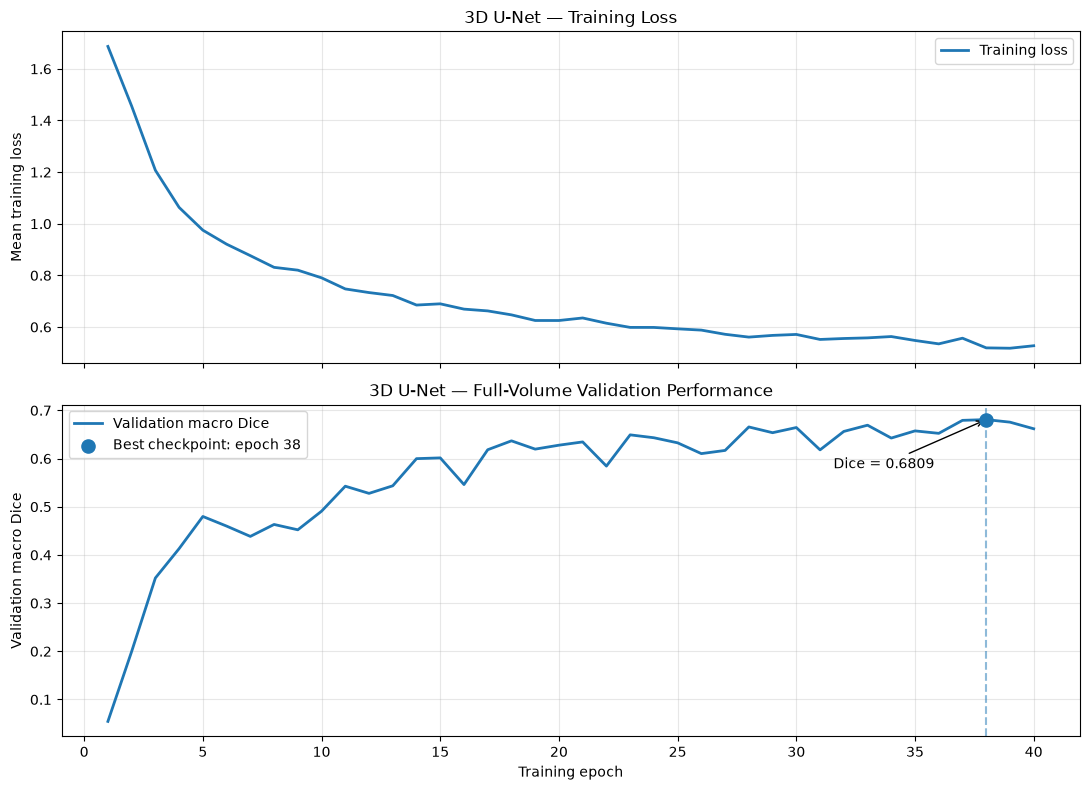

Best checkpoint epoch: 38
Best validation macro Dice: 0.6809
Final training loss: 0.5275


In [23]:
# -------------------------------------------------------------
# CELL 129 — VISUALISE THE COMPLETE TRAINING HISTORY
# -------------------------------------------------------------
#
# Plot:
# 1. Mean training loss across all 40 epochs.
# 2. Full-volume validation macro Dice across all 40 epochs.
#
# Highlight the best checkpoint selected during training.
#
# These plots help identify convergence, instability,
# and potential overfitting.
# -------------------------------------------------------------

import matplotlib.pyplot as plt

# Identify the epoch with the highest validation Dice.
best_row = final_history.loc[
    final_history["validation_score"].idxmax()
]

best_epoch = int(best_row["epoch"])
best_dice = float(best_row["validation_score"])

# Create two plots with a shared epoch axis.
fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 8),
    sharex=True,
)

# -------------------------------------------------------------
# PLOT 1 — TRAINING LOSS
# -------------------------------------------------------------

axes[0].plot(
    final_history["epoch"],
    final_history["training_loss"],
    linewidth=2,
    label="Training loss",
)

axes[0].set_ylabel("Mean training loss")
axes[0].set_title("3D U-Net — Training Loss")
axes[0].grid(alpha=0.3)
axes[0].legend()

# -------------------------------------------------------------
# PLOT 2 — VALIDATION DICE
# -------------------------------------------------------------

axes[1].plot(
    final_history["epoch"],
    final_history["validation_score"],
    linewidth=2,
    label="Validation macro Dice",
)

# Mark the best checkpoint.
axes[1].scatter(
    best_epoch,
    best_dice,
    s=90,
    zorder=5,
    label=f"Best checkpoint: epoch {best_epoch}",
)

axes[1].axvline(
    best_epoch,
    linestyle="--",
    alpha=0.5,
)

axes[1].annotate(
    f"Dice = {best_dice:.4f}",
    xy=(best_epoch, best_dice),
    xytext=(-110, -35),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"},
)

axes[1].set_xlabel("Training epoch")
axes[1].set_ylabel("Validation macro Dice")
axes[1].set_title("3D U-Net — Full-Volume Validation Performance")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

print("Best checkpoint epoch:", best_epoch)
print("Best validation macro Dice:", round(best_dice, 4))
print("Final training loss:", round(
    float(final_history["training_loss"].iloc[-1]), 4
))

# Model evaluation

In [24]:
# -------------------------------------------------------------
# CELL 130 — RESTORE BEST MODEL FOR SEGMENTATION EVALUATION
# -------------------------------------------------------------
#
# Load the epoch-38 checkpoint into the existing U-Net.
#
# We create a separate evaluation model so the epoch-40
# training model remains unchanged in memory.
#
# No training, MRI loading or checkpoint modifications.
# -------------------------------------------------------------

import copy
import torch

# STEP 1 — Create a separate copy of the trained architecture.
# This avoids modifying large_model, which currently contains
# the epoch-40 weights.

evaluation_model = copy.deepcopy(large_model)

# STEP 2 — Load the best saved model weights.

evaluation_model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

# STEP 3 — Move the model to the GPU and disable training mode.
# Evaluation mode ensures inference behaves consistently.

evaluation_model = evaluation_model.to(large_device)
evaluation_model.eval()

# STEP 4 — Verify the selected checkpoint.

assert int(best_checkpoint["epoch"]) == 38

assert next(
    evaluation_model.parameters()
).device.type == "cuda"

print("BEST MODEL RESTORED FOR EVALUATION")
print("-" * 60)

print("Experiment:", experiment_directory.name)
print("Selected epoch:", best_checkpoint["epoch"])
print(
    "Validation macro Dice:",
    round(best_checkpoint["validation_score"], 4)
)
print("Device:", next(evaluation_model.parameters()).device)
print("Evaluation mode:", not evaluation_model.training)

print("\nReady for full-volume MRI segmentation inference.")

BEST MODEL RESTORED FOR EVALUATION
------------------------------------------------------------
Experiment: unet_180train_24val_20261013_203139
Selected epoch: 38
Validation macro Dice: 0.6809
Device: cuda:0
Evaluation mode: True

Ready for full-volume MRI segmentation inference.


In [25]:
# -------------------------------------------------------------
# CELL 131 — SELECT FIRST VALIDATION CASE FOR VISUAL EVALUATION
# -------------------------------------------------------------
#
# Use the existing validation subset without changing its order.
#
# Verify:
# 1. The case belongs to our selected validation cohort.
# 2. All four MRI sequences and the segmentation label exist.
# 3. The MRI and label dimensions are consistent.
#
# No GPU inference or model modifications.
# -------------------------------------------------------------

from pathlib import Path
import nibabel as nib

# STEP 1 — Select the first case in our fixed validation subset.

visualisation_case = selected_validation_cases[0]

print("SELECTED VALIDATION CASE")
print("-" * 60)

print("Case ID:", visualisation_case["case_id"])
print("Subject ID:", visualisation_case["subject_id"])

# STEP 2 — Verify all four MRI modalities are available.

mri_paths = [
    Path(path)
    for path in visualisation_case["image"]
]

label_path = Path(visualisation_case["label"])

assert len(mri_paths) == 4
assert all(path.is_file() for path in mri_paths)
assert label_path.is_file()

# STEP 3 — Inspect NIfTI headers without loading full volumes.

modality_names = ["T1", "T1-contrast", "T2", "T2-FLAIR"]

mri_shapes = []

for modality_name, path in zip(modality_names, mri_paths):

    image_header = nib.load(str(path))

    mri_shapes.append(image_header.shape)

    print(
        f"{modality_name:12s} | "
        f"Shape: {image_header.shape}"
    )

label_header = nib.load(str(label_path))

print(
    f"{'Segmentation':12s} | "
    f"Shape: {label_header.shape}"
)

# STEP 4 — Confirm the four MRI volumes and label align
# in voxel dimensions.

assert all(
    shape == label_header.shape
    for shape in mri_shapes
)

print("\nAll MRI files verified.")
print("MRI and segmentation dimensions match.")
print("Ready to prepare this case for full-volume inference.")

SELECTED VALIDATION CASE
------------------------------------------------------------
Case ID: BraTS-GLI-02736-101
Subject ID: BraTS-GLI-02736
T1           | Shape: (182, 218, 182)
T1-contrast  | Shape: (182, 218, 182)
T2           | Shape: (182, 218, 182)
T2-FLAIR     | Shape: (182, 218, 182)
Segmentation | Shape: (182, 218, 182)

All MRI files verified.
MRI and segmentation dimensions match.
Ready to prepare this case for full-volume inference.


In [26]:
# -------------------------------------------------------------
# CELL 132 — FULL-VOLUME INFERENCE ON FIRST VALIDATION CASE
# -------------------------------------------------------------
#
# Apply the existing validation preprocessing and run
# sliding-window inference with the best epoch-38 U-Net.
#
# The output contains four overlapping binary region masks:
# WT, TC, ET and RC.
#
# This cell does not train the model or modify checkpoints.
# -------------------------------------------------------------

import torch
from monai.inferers import sliding_window_inference

# STEP 1 — Apply exactly the same deterministic transforms
# used for full-volume validation during model training.

processed_case = large_validation_transforms(
    visualisation_case
)

# STEP 2 — Extract the preprocessed MRI and ground-truth masks.
# Expected image shape: (4, H, W, D)
# Expected label shape: (4, H, W, D)

visualisation_image = processed_case["image"]
visualisation_ground_truth = processed_case["label"]

assert visualisation_image.shape[0] == 4
assert visualisation_ground_truth.shape[0] == 4

# STEP 3 — Add a batch dimension and transfer MRI to GPU.

inference_input = (
    visualisation_image.unsqueeze(0)
    .to(large_device)
)

# STEP 4 — Perform full-volume sliding-window inference.
# The 96³ window and 25% overlap match our validation setup.

evaluation_model.eval()

with torch.inference_mode():

    inference_logits = sliding_window_inference(
        inputs=inference_input,
        roi_size=(96, 96, 96),
        sw_batch_size=1,
        predictor=evaluation_model,
        overlap=0.25,
    )

    # Convert logits to independent region probabilities.
    inference_probabilities = torch.sigmoid(
        inference_logits
    )

    # Apply the same 0.5 threshold used in validation.
    inference_predictions = (
        inference_probabilities >= 0.5
    )

# STEP 5 — Transfer results to CPU for subsequent analysis.

visualisation_prediction = (
    inference_predictions[0].cpu()
)

visualisation_probabilities = (
    inference_probabilities[0].cpu()
)

visualisation_ground_truth = (
    visualisation_ground_truth.cpu()
)

visualisation_image = visualisation_image.cpu()

# STEP 6 — Display output dimensions and voxel counts.

region_names = ["WT", "TC", "ET", "RC"]

print("FULL-VOLUME INFERENCE COMPLETED")
print("-" * 60)

print("Case ID:", visualisation_case["case_id"])
print("MRI shape:", tuple(visualisation_image.shape))
print("Prediction shape:", tuple(visualisation_prediction.shape))
print("Ground-truth shape:", tuple(visualisation_ground_truth.shape))

print("\nREGION VOXEL COUNTS")

for index, region_name in enumerate(region_names):

    predicted_voxels = int(
        visualisation_prediction[index].sum().item()
    )

    ground_truth_voxels = int(
        visualisation_ground_truth[index].sum().item()
    )

    print(
        f"{region_name}: "
        f"Predicted = {predicted_voxels:,} | "
        f"Ground truth = {ground_truth_voxels:,}"
    )

print("\nReady for MRI segmentation overlays.")

FULL-VOLUME INFERENCE COMPLETED
------------------------------------------------------------
Case ID: BraTS-GLI-02736-101
MRI shape: (4, 132, 157, 142)
Prediction shape: (4, 132, 157, 142)
Ground-truth shape: (4, 132, 157, 142)

REGION VOXEL COUNTS
WT: Predicted = 9,305 | Ground truth = 8,365
TC: Predicted = 7 | Ground truth = 0
ET: Predicted = 2 | Ground truth = 0
RC: Predicted = 637 | Ground truth = 0

Ready for MRI segmentation overlays.


In [27]:
# -------------------------------------------------------------
# CELL 133 — CASE-SPECIFIC SEGMENTATION METRICS
# -------------------------------------------------------------
#
# Calculate Dice, precision and recall for regions that
# are present in the ground-truth segmentation.
#
# For absent regions, report false-positive voxel counts
# rather than assigning a potentially misleading Dice score.
#
# No GPU inference, training or file modifications.
# -------------------------------------------------------------

import numpy as np
import pandas as pd

region_names = ["WT", "TC", "ET", "RC"]

case_metrics = []

for index, region_name in enumerate(region_names):

    # Convert the predicted and reference masks into
    # Boolean NumPy arrays for voxel-wise comparison.
    prediction = (
        visualisation_prediction[index]
        .numpy()
        .astype(bool)
    )

    ground_truth = (
        visualisation_ground_truth[index]
        .numpy()
        .astype(bool)
    )

    # Count predicted, reference and overlapping voxels.
    predicted_count = int(prediction.sum())
    reference_count = int(ground_truth.sum())

    true_positive = int(
        np.logical_and(prediction, ground_truth).sum()
    )

    false_positive = predicted_count - true_positive
    false_negative = reference_count - true_positive

    # Only calculate overlap metrics when the reference
    # region is present.
    if reference_count > 0:

        dice = (
            2 * true_positive
            / (predicted_count + reference_count)
        )

        precision = (
            true_positive / predicted_count
            if predicted_count > 0 else 0.0
        )

        recall = true_positive / reference_count

    else:
        # An absent reference region has no meaningful
        # positive-class recall. Report FP burden instead.
        dice = np.nan
        precision = np.nan
        recall = np.nan

    case_metrics.append({
        "region": region_name,
        "reference_voxels": reference_count,
        "predicted_voxels": predicted_count,
        "true_positive": true_positive,
        "false_positive": false_positive,
        "false_negative": false_negative,
        "dice": dice,
        "precision": precision,
        "recall": recall,
    })

case_metrics_df = pd.DataFrame(case_metrics)

print("CASE-SPECIFIC SEGMENTATION PERFORMANCE")
print("-" * 60)
print("Case:", visualisation_case["case_id"])

print(
    case_metrics_df.to_string(
        index=False,
        float_format=lambda value: f"{value:.4f}"
    )
)

print(
    "\nNote: NaN overlap metrics indicate a region "
    "absent from the reference segmentation."
)

CASE-SPECIFIC SEGMENTATION PERFORMANCE
------------------------------------------------------------
Case: BraTS-GLI-02736-101
region  reference_voxels  predicted_voxels  true_positive  false_positive  false_negative   dice  precision  recall
    WT              8365              9305           7962            1343             403 0.9012     0.8557  0.9518
    TC                 0                 7              0               7               0    NaN        NaN     NaN
    ET                 0                 2              0               2               0    NaN        NaN     NaN
    RC                 0               637              0             637               0    NaN        NaN     NaN

Note: NaN overlap metrics indicate a region absent from the reference segmentation.


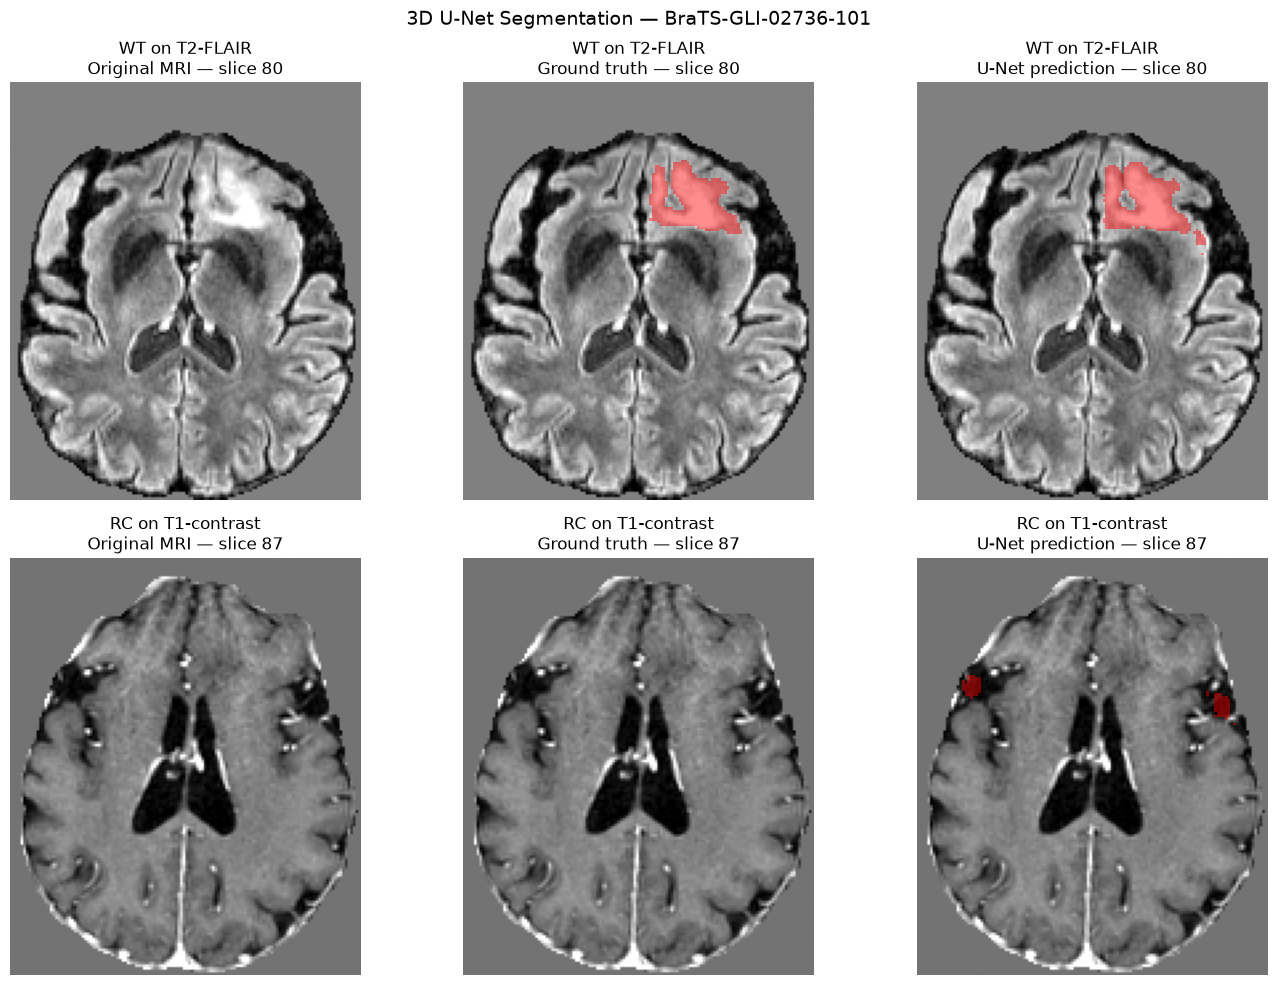

Selected WT slice: 80
Selected RC slice: 87
Ground-truth RC voxels: 0
Predicted RC voxels: 637


In [28]:
# -------------------------------------------------------------
# CELL 134 — VISUALISE WHOLE-TUMOUR AND RESECTION-CAVITY MASKS
# -------------------------------------------------------------
#
# Display two representative axial slices:
#
# Row 1: T2-FLAIR with WT reference and prediction
# Row 2: T1-contrast with RC reference and prediction
#
# Each row shows:
#   1. Original MRI
#   2. Ground-truth segmentation overlay
#   3. U-Net prediction overlay
#
# Slice selection is based on the mask area, not subjective
# visual preference.
#
# No GPU inference, training or file modifications.
# -------------------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt

# Convert tensors to NumPy arrays.
mri = visualisation_image.numpy()
reference = visualisation_ground_truth.numpy().astype(bool)
prediction = visualisation_prediction.numpy().astype(bool)

# Modalities: T1, T1-contrast, T2, T2-FLAIR.
# Regions: WT, TC, ET, RC.
flair_index = 3
t1c_index = 1
wt_index = 0
rc_index = 3

# Select axial slices using the largest mask areas.
wt_slice = int(
    np.argmax(reference[wt_index].sum(axis=(0, 1)))
)

rc_slice = int(
    np.argmax(prediction[rc_index].sum(axis=(0, 1)))
)

# Prepare rows: modality, region, slice and description.
display_rows = [
    (flair_index, wt_index, wt_slice, "WT on T2-FLAIR"),
    (t1c_index, rc_index, rc_slice, "RC on T1-contrast"),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 10))

for row, (modality, region, slice_index, description) in enumerate(
    display_rows
):

    # Transpose for a consistent display orientation.
    image_slice = mri[modality, :, :, slice_index].T
    reference_slice = reference[region, :, :, slice_index].T
    prediction_slice = prediction[region, :, :, slice_index].T

    # Use consistent intensity scaling within each row.
    nonzero = image_slice[image_slice != 0]

    if nonzero.size > 0:
        vmin, vmax = np.percentile(nonzero, [1, 99])
    else:
        vmin, vmax = 0, 1

    images = [
        ("Original MRI", None),
        ("Ground truth", reference_slice),
        ("U-Net prediction", prediction_slice),
    ]

    for col, (title, mask) in enumerate(images):

        ax = axes[row, col]

        ax.imshow(
            image_slice,
            cmap="gray",
            origin="lower",
            vmin=vmin,
            vmax=vmax,
        )

        if mask is not None and mask.any():

            # Masked overlay makes the underlying MRI visible.
            overlay = np.ma.masked_where(~mask, mask)

            ax.imshow(
                overlay,
                cmap="autumn",
                alpha=0.45,
                origin="lower",
                interpolation="nearest",
            )

        ax.set_title(
            f"{description}\n{title} — slice {slice_index}"
        )

        ax.axis("off")

plt.suptitle(
    f"3D U-Net Segmentation — {visualisation_case['case_id']}",
    fontsize=14,
)

plt.tight_layout()
plt.show()

print("Selected WT slice:", wt_slice)
print("Selected RC slice:", rc_slice)
print("Ground-truth RC voxels:", int(reference[rc_index].sum()))
print("Predicted RC voxels:", int(prediction[rc_index].sum()))

### Sylvian fissure is currently classified as resection cavity

In [29]:
# -------------------------------------------------------------
# CELL 135 — ANALYSE FALSE-POSITIVE RESECTION-CAVITY COMPONENTS
# -------------------------------------------------------------
#
# Identify connected components in the predicted RC mask.
#
# For each component, report:
# - Number of voxels
# - Percentage of total predicted RC volume
# - Bounding-box coordinates
#
# Uses 26-connectivity in 3D, including diagonal neighbours.
#
# No training, GPU inference or file modifications.
# -------------------------------------------------------------

import numpy as np
from scipy import ndimage

# STEP 1 — Extract the predicted resection-cavity mask.

rc_prediction = (
    visualisation_prediction[3]
    .numpy()
    .astype(bool)
)

# Confirm that RC is absent from the reference for this case.
rc_reference = (
    visualisation_ground_truth[3]
    .numpy()
    .astype(bool)
)

assert not rc_reference.any(), (
    "This analysis assumes the reference RC region is absent."
)

# STEP 2 — Label all 3D connected components.
# A 3x3x3 connectivity structure includes face, edge
# and corner neighbours.

connectivity = np.ones((3, 3, 3), dtype=bool)

component_labels, component_count = ndimage.label(
    rc_prediction,
    structure=connectivity,
)

# STEP 3 — Calculate the size of each component.

component_sizes = np.bincount(
    component_labels.ravel()
)[1:]

# Sort component IDs by descending voxel count.
sorted_component_ids = (
    np.argsort(component_sizes)[::-1] + 1
)

total_rc_voxels = int(rc_prediction.sum())

print("RESECTION-CAVITY CONNECTED-COMPONENT ANALYSIS")
print("-" * 60)

print("Case:", visualisation_case["case_id"])
print("Total predicted RC voxels:", total_rc_voxels)
print("Connected components:", component_count)

print("\nLARGEST COMPONENTS")

for rank, component_id in enumerate(
    sorted_component_ids[:10],
    start=1,
):

    component_mask = component_labels == component_id

    coordinates = np.argwhere(component_mask)

    minimum = coordinates.min(axis=0)
    maximum = coordinates.max(axis=0)

    voxel_count = int(component_sizes[component_id - 1])

    percentage = (
        100 * voxel_count / total_rc_voxels
        if total_rc_voxels > 0 else 0
    )

    print(
        f"{rank:2d}. "
        f"Voxels: {voxel_count:4d} | "
        f"Share: {percentage:5.1f}% | "
        f"Bounds: {tuple(minimum)} to {tuple(maximum)}"
    )

print("\nConnected-component analysis completed.")

RESECTION-CAVITY CONNECTED-COMPONENT ANALYSIS
------------------------------------------------------------
Case: BraTS-GLI-02736-101
Total predicted RC voxels: 637
Connected components: 8

LARGEST COMPONENTS
 1. Voxels:  343 | Share:  53.8% | Bounds: (np.int64(107), np.int64(91), np.int64(81)) to (np.int64(120), np.int64(108), np.int64(92))
 2. Voxels:  239 | Share:  37.5% | Bounds: (np.int64(17), np.int64(104), np.int64(83)) to (np.int64(24), np.int64(112), np.int64(93))
 3. Voxels:   45 | Share:   7.1% | Bounds: (np.int64(75), np.int64(107), np.int64(92)) to (np.int64(83), np.int64(111), np.int64(96))
 4. Voxels:    5 | Share:   0.8% | Bounds: (np.int64(90), np.int64(114), np.int64(68)) to (np.int64(91), np.int64(115), np.int64(69))
 5. Voxels:    2 | Share:   0.3% | Bounds: (np.int64(73), np.int64(107), np.int64(93)) to (np.int64(73), np.int64(107), np.int64(94))
 6. Voxels:    1 | Share:   0.2% | Bounds: (np.int64(109), np.int64(105), np.int64(91)) to (np.int64(109), np.int64(105),

In [30]:
# -------------------------------------------------------------
# CELL 137 — INSPECT SAVED VALIDATION RESULTS
# -------------------------------------------------------------
#
# Look for existing validation metrics from the 40-epoch
# experiment before repeating full-volume inference.
#
# In particular, we want to determine whether per-case
# false-positive voxel counts were already saved.
#
# Read-only: no training, inference or file modifications.
# -------------------------------------------------------------

from pathlib import Path

# STEP 1 — Identify the experiment's log directory.

validation_log_directory = experiment_directory / "logs"

assert validation_log_directory.is_dir(), (
    "Experiment log directory was not found."
)

print("SAVED VALIDATION RESULTS")
print("-" * 60)

print("Experiment:", experiment_directory.name)
print("Log directory:", validation_log_directory)

# STEP 2 — List available CSV and JSON files.

saved_metric_files = sorted(
    path
    for path in validation_log_directory.rglob("*")
    if path.is_file()
    and path.suffix.lower() in {".csv", ".json"}
)

print("\nAvailable metric files:")

for path in saved_metric_files:
    print(
        "-",
        path.relative_to(experiment_directory),
        f"({path.stat().st_size:,} bytes)"
    )

# STEP 3 — Inspect CSV columns without loading
# potentially large tables into memory.

print("\nCSV FILE STRUCTURES")
print("-" * 60)

import pandas as pd

for path in saved_metric_files:

    if path.suffix.lower() != ".csv":
        continue

    preview = pd.read_csv(path, nrows=3)

    print("\nFile:", path.name)
    print("Columns:", list(preview.columns))
    print("Preview rows:", len(preview))

print("\nSaved validation result inspection completed.")

SAVED VALIDATION RESULTS
------------------------------------------------------------
Experiment: unet_180train_24val_20261013_203139
Log directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/unet_180train_24val_20261013_203139/logs

Available metric files:
- logs/training_history.csv (3,194 bytes)
- logs/validation_region_history.csv (12,054 bytes)

CSV FILE STRUCTURES
------------------------------------------------------------

File: training_history.csv
Columns: ['epoch', 'training_loss', 'training_seconds', 'validation_score', 'validation_seconds']
Preview rows: 3

File: validation_region_history.csv
Columns: ['epoch', 'region', 'present_cases', 'absent_cases', 'mean_dice_present', 'mean_precision_present', 'mean_recall_present', 'absent_cases_with_false_positives', 'total_false_positive_voxels_absent']
Preview rows: 3

Saved validation result inspection completed.


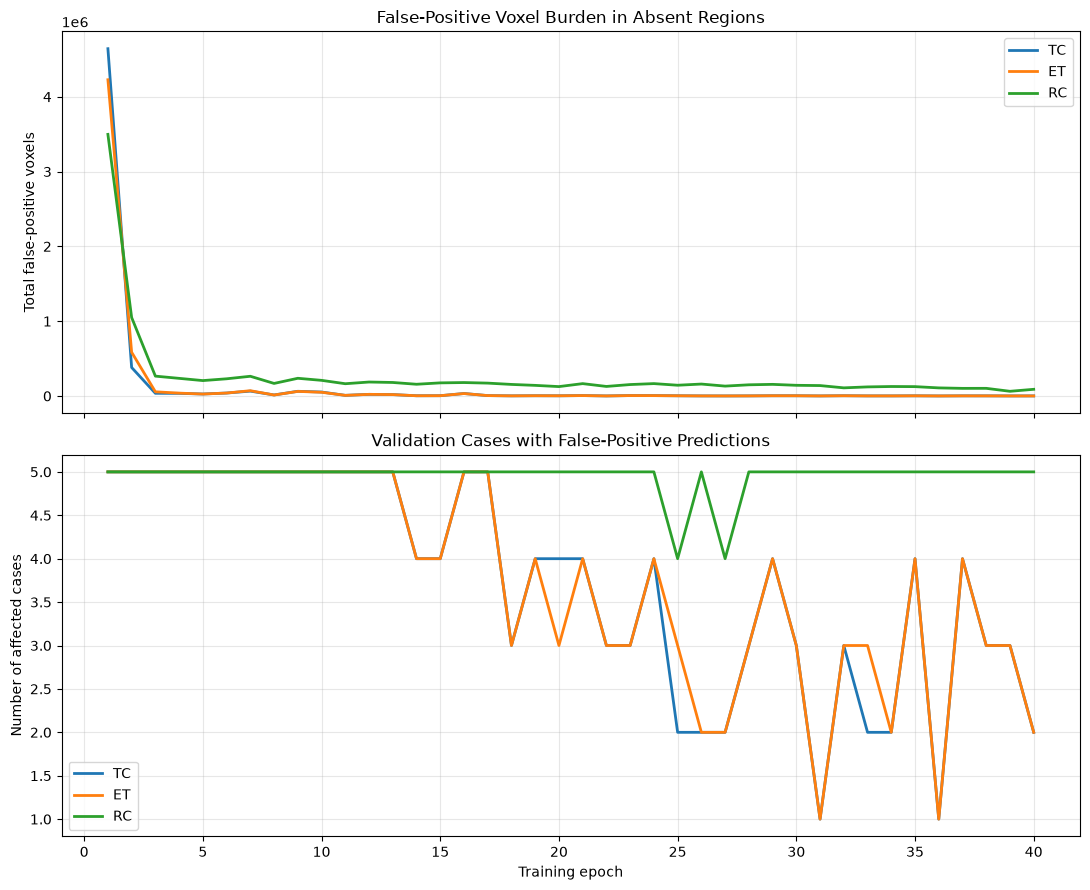

FALSE-POSITIVE SUMMARY
----------------------------------------------------------------------
 epoch region  absent_cases  absent_cases_with_false_positives  total_false_positive_voxels_absent  mean_dice_present
    23     ET             5                                  3                                5618             0.6301
    23     RC             5                                  5                              153013             0.5225
    23     TC             5                                  3                                5823             0.6216
    38     ET             5                                  3                                1635             0.6736
    38     RC             5                                  5                              102425             0.5405
    38     TC             5                                  3                                1869             0.6548
    40     ET             5                                  2                  

In [31]:
# -------------------------------------------------------------
# CELL 138 — ANALYSE VALIDATION FALSE-POSITIVE TRENDS
# -------------------------------------------------------------
#
# Investigate whether improved segmentation Dice was
# accompanied by fewer false-positive predictions.
#
# Focus on:
# - Resection cavity (RC)
# - Tumour core (TC)
# - Enhancing tumour (ET)
#
# Use saved region-level metrics from all 40 epochs.
#
# No GPU inference, training or file modifications.
# -------------------------------------------------------------

import pandas as pd
import matplotlib.pyplot as plt

# STEP 1 — Load the existing region-level validation history.

region_history_path = (
    experiment_directory
    / "logs"
    / "validation_region_history.csv"
)

region_history = pd.read_csv(region_history_path)

# Verify that all 40 epochs and four regions are represented.
assert region_history["epoch"].nunique() == 40

assert set(region_history["region"]) == {
    "WT", "TC", "ET", "RC"
}

# STEP 2 — Focus on the three regions where false positives
# have been observed in examinations with absent annotations.

regions_to_analyse = ["TC", "ET", "RC"]

fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 9),
    sharex=True,
)

for region_name in regions_to_analyse:

    region_data = region_history.loc[
        region_history["region"] == region_name
    ].sort_values("epoch")

    # Plot total false-positive voxels in absent cases.
    axes[0].plot(
        region_data["epoch"],
        region_data["total_false_positive_voxels_absent"],
        label=region_name,
        linewidth=2,
    )

    # Plot the number of absent cases with any false positives.
    axes[1].plot(
        region_data["epoch"],
        region_data["absent_cases_with_false_positives"],
        label=region_name,
        linewidth=2,
    )

axes[0].set_title(
    "False-Positive Voxel Burden in Absent Regions"
)
axes[0].set_ylabel("Total false-positive voxels")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].set_title(
    "Validation Cases with False-Positive Predictions"
)
axes[1].set_xlabel("Training epoch")
axes[1].set_ylabel("Number of affected cases")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

# STEP 3 — Summarise the best checkpoint and final epoch.

print("FALSE-POSITIVE SUMMARY")
print("-" * 70)

summary = region_history.loc[
    region_history["epoch"].isin([23, 38, 40])
    & region_history["region"].isin(regions_to_analyse),
    [
        "epoch",
        "region",
        "absent_cases",
        "absent_cases_with_false_positives",
        "total_false_positive_voxels_absent",
        "mean_dice_present",
    ]
].sort_values(["epoch", "region"])

print(
    summary.to_string(
        index=False,
        float_format=lambda value: f"{value:.4f}"
    )
)

In [32]:
# -------------------------------------------------------------
# CELL 139 — INSPECT CASE-LEVEL EVALUATION OUTPUT STRUCTURE
# -------------------------------------------------------------
#
# Confirm the available evaluation function and its return
# structure before rerunning full-volume validation.
#
# No GPU inference, training or file modifications.
# -------------------------------------------------------------

import inspect

# STEP 1 — Verify the evaluation function is available.

assert callable(evaluate_segmentation_model)

# STEP 2 — Display its signature.

print("EVALUATION FUNCTION")
print("-" * 60)

print(
    inspect.signature(evaluate_segmentation_model)
)

# STEP 3 — Inspect the final portion of the function.
# This reveals how per-case results are assembled and
# what values the function returns.

source_lines = inspect.getsource(
    evaluate_segmentation_model
).splitlines()

print("\nFINAL 65 LINES OF EVALUATION FUNCTION")
print("-" * 60)

for line in source_lines[-65:]:
    print(line)

EVALUATION FUNCTION
------------------------------------------------------------
(model, validation_loader, device, threshold=0.5, roi_size=(96, 96, 96), sw_batch_size=1, overlap=0.25)


OSError: source code not available

In [34]:
# -------------------------------------------------------------
# CELL 140 — RETRIEVE ORIGINAL EVALUATION FUNCTION SOURCE
# -------------------------------------------------------------
#
# The evaluation function was restored dynamically using exec().
# Therefore, inspect.getsource() cannot retrieve its source.
#
# Instead, read its original definition from notebook_data,
# which we loaded earlier during the training resumption.
#
# No GPU inference, training or file modifications.
# -------------------------------------------------------------

import ast

# STEP 1 — Find the original notebook cell containing
# the evaluation function.

function_name = "evaluate_segmentation_model"

cell_position = found_functions[function_name]

# STEP 2 — Retrieve the source code from the notebook.

cell_source = notebook_data["cells"][cell_position]["source"]

if isinstance(cell_source, list):
    cell_source = "".join(cell_source)

# STEP 3 — Parse the source and extract only the requested
# function definition, avoiding unrelated notebook code.

parsed_cell = ast.parse(cell_source)

function_node = next(
    node
    for node in parsed_cell.body
    if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
    and node.name == function_name
)

function_source = ast.get_source_segment(
    cell_source,
    function_node,
)

assert function_source is not None

# STEP 4 — Display the final portion of the function.

source_lines = function_source.splitlines()

print("EVALUATION FUNCTION")
print("-" * 60)
print("Name:", function_name)
print("Original notebook cell position:", cell_position)

print("\nFINAL 65 LINES OF FUNCTION")
print("-" * 60)

for line in source_lines[-65:]:
    print(line)

StopIteration: 

In [35]:
# -------------------------------------------------------------
# CELL 141 — LOCATE ORIGINAL EVALUATION FUNCTION
# -------------------------------------------------------------
#
# Search notebook_data directly for the original definition
# of evaluate_segmentation_model().
#
# Avoid relying on stored cell positions, which may differ
# from the notebook's actual cell indices.
#
# No training, inference or file modifications.
# -------------------------------------------------------------

import ast

target_function = "evaluate_segmentation_model"

matches = []

# STEP 1 — Search every code cell in the saved notebook.

for cell_index, cell in enumerate(notebook_data["cells"]):

    if cell.get("cell_type") != "code":
        continue

    source = cell.get("source", "")

    if isinstance(source, list):
        source = "".join(source)

    if f"def {target_function}" not in source:
        continue

    # STEP 2 — Parse the cell and inspect all function
    # definitions, including nested definitions.

    try:
        parsed = ast.parse(source)
    except SyntaxError:
        continue

    for node in ast.walk(parsed):

        if (
            isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
            and node.name == target_function
        ):
            matches.append({
                "cell_index": cell_index,
                "line_number": node.lineno,
                "source": ast.get_source_segment(source, node),
            })

# STEP 3 — Display matching locations.

print("EVALUATION FUNCTION SOURCE SEARCH")
print("-" * 60)

print("Matching definitions found:", len(matches))

for match in matches:

    print(
        "\nNotebook cell index:",
        match["cell_index"]
    )

    print(
        "Function starts at line:",
        match["line_number"]
    )

    source_lines = (match["source"] or "").splitlines()

    print("\nFinal 65 lines:")

    for line in source_lines[-65:]:
        print(line)

print("\nSource search completed.")

EVALUATION FUNCTION SOURCE SEARCH
------------------------------------------------------------
Matching definitions found: 1

Notebook cell index: 96
Function starts at line: 28

Final 65 lines:
        # exception occurs during validation.
        model.train(was_training)

    elapsed_seconds = time.perf_counter() - start_time

    # ---------------------------------------------------------
    # BUILD CASE-LEVEL METRICS TABLE
    # ---------------------------------------------------------

    metrics_df = pd.DataFrame(records)

    # ---------------------------------------------------------
    # BUILD REGION-LEVEL SUMMARY
    # ---------------------------------------------------------

    summary_records = []

    for region_name in region_names:

        region_df = metrics_df[
            metrics_df["region"] == region_name
        ]

        present_df = region_df[
            region_df["ground_truth_present"]
        ]

        absent_df = region_df[
            ~region_df["g

In [36]:
# -------------------------------------------------------------
# CELL 142 — CASE-LEVEL VALIDATION ERROR ANALYSIS
# -------------------------------------------------------------
#
# Evaluate the selected epoch-38 U-Net on all 24 validation
# examinations using full-volume sliding-window inference.
#
# Save:
# 1. Per-case metrics for all four segmentation regions.
# 2. Region-level summary metrics.
#
# The model is not retrained or modified.
# The held-out test cohort remains untouched.
# -------------------------------------------------------------

import numpy as np
import pandas as pd
import torch

# STEP 1 — Verify that the correct model and validation
# dataset are available.

assert not evaluation_model.training
assert next(evaluation_model.parameters()).device.type == "cuda"
assert len(large_validation_loader.dataset) == 24
assert int(best_checkpoint["epoch"]) == 38

# STEP 2 — Run full-volume validation inference.
# This uses the same 96³ sliding-window size, 0.25 overlap,
# and 0.5 probability threshold as the training evaluation.

print("STARTING CASE-LEVEL VALIDATION ANALYSIS")
print("-" * 60)
print("Model checkpoint: epoch 38")
print("Validation examinations: 24")
print("Probability threshold: 0.5")
print("\nRunning inference...\n")

validation_case_metrics, validation_region_summary, validation_elapsed = (
    evaluate_segmentation_model(
        model=evaluation_model,
        validation_loader=large_validation_loader,
        device=large_device,
        threshold=0.5,
        roi_size=(96, 96, 96),
        sw_batch_size=1,
        overlap=0.25,
    )
)

# STEP 3 — Verify that all 24 cases and four regions
# are represented.

assert len(validation_case_metrics) == 24 * 4

assert set(validation_case_metrics["region"]) == {
    "WT", "TC", "ET", "RC"
}

# STEP 4 — Verify the reproduced validation score.
# Small numerical differences may occur, but the result
# should closely match the saved epoch-38 evaluation.

reproduced_macro_dice = float(
    validation_region_summary["mean_dice_present"].mean()
)

saved_macro_dice = float(
    best_checkpoint["validation_score"]
)

print("VALIDATION REPRODUCIBILITY CHECK")
print("-" * 60)

print("Saved macro Dice:", round(saved_macro_dice, 6))
print("Reproduced macro Dice:", round(reproduced_macro_dice, 6))
print("Absolute difference:", round(
    abs(reproduced_macro_dice - saved_macro_dice), 8
))

assert np.isclose(
    reproduced_macro_dice,
    saved_macro_dice,
    atol=1e-4,
), "Validation score differs from the saved checkpoint."

# STEP 5 — Save case-level results for later analysis.
# These files contain metrics, not MRI image data.

case_metrics_path = (
    experiment_directory
    / "logs"
    / "validation_case_metrics_best_epoch38.csv"
)

region_summary_path = (
    experiment_directory
    / "logs"
    / "validation_region_summary_best_epoch38.csv"
)

validation_case_metrics.to_csv(
    case_metrics_path,
    index=False,
)

validation_region_summary.to_csv(
    region_summary_path,
    index=False,
)

# STEP 6 — Display the region-level results.

print("\nREGION-LEVEL VALIDATION RESULTS")
print("-" * 60)

print(
    validation_region_summary.to_string(
        index=False,
        float_format=lambda value: f"{value:.4f}"
    )
)

print("\nEvaluation time:", round(validation_elapsed, 1), "seconds")
print("Case-level results saved:", case_metrics_path.name)
print("Region summary saved:", region_summary_path.name)

print("\nCASE-LEVEL VALIDATION ANALYSIS COMPLETED.")

STARTING CASE-LEVEL VALIDATION ANALYSIS
------------------------------------------------------------
Model checkpoint: epoch 38
Validation examinations: 24
Probability threshold: 0.5

Running inference...

VALIDATION REPRODUCIBILITY CHECK
------------------------------------------------------------
Saved macro Dice: 0.680868
Reproduced macro Dice: 0.680869
Absolute difference: 3.8e-07

REGION-LEVEL VALIDATION RESULTS
------------------------------------------------------------
region  present_cases  absent_cases  mean_dice_present  mean_precision_present  mean_recall_present  absent_cases_with_false_positives  total_false_positive_voxels_absent
    WT             24             0             0.8546                  0.8705               0.8488                                  0                                   0
    TC             19             5             0.6548                  0.6956               0.6713                                  3                                1869
    E

# Reviewing sources of error in classification

In [37]:
# -------------------------------------------------------------
# CELL 143 — RANK RC-ABSENT CASES BY FALSE-POSITIVE BURDEN
# -------------------------------------------------------------
#
# Identify validation examinations where the reference
# segmentation contains no resection cavity but the U-Net
# predicts one.
#
# Rank cases by false-positive voxel count.
#
# No GPU inference, training or file modifications.
# -------------------------------------------------------------

import pandas as pd

# STEP 1 — Select resection-cavity results for cases
# without an annotated RC region.

rc_absent_cases = validation_case_metrics.loc[
    (validation_case_metrics["region"] == "RC")
    & (~validation_case_metrics["ground_truth_present"])
].copy()

# STEP 2 — Rank by false-positive voxel count.

rc_absent_cases = rc_absent_cases.sort_values(
    "false_positive_voxels",
    ascending=False,
).reset_index(drop=True)

# STEP 3 — Calculate each case's contribution to the
# overall RC false-positive burden.

total_rc_false_positives = int(
    rc_absent_cases["false_positive_voxels"].sum()
)

rc_absent_cases["percentage_of_total"] = (
    100
    * rc_absent_cases["false_positive_voxels"]
    / total_rc_false_positives
)

# STEP 4 — Display the available case-level columns.

print("RC-ABSENT VALIDATION CASES")
print("-" * 70)

print("Cases:", len(rc_absent_cases))
print("Total false-positive RC voxels:", total_rc_false_positives)

print("\nAvailable columns:")
print(list(rc_absent_cases.columns))

print("\nRANKED CASES")
print("-" * 70)

display_columns = [
    column
    for column in [
        "case_id",
        "subject_id",
        "false_positive_voxels",
        "percentage_of_total",
    ]
    if column in rc_absent_cases.columns
]

print(
    rc_absent_cases[display_columns].to_string(
        index=False,
        float_format=lambda value: f"{value:.2f}"
    )
)

# STEP 5 — Verify that the previously inspected case
# appears in this cohort.

assert (
    "BraTS-GLI-02736-101"
    in rc_absent_cases["case_id"].values
)

print("\nRC-absent case ranking completed.")

RC-ABSENT VALIDATION CASES
----------------------------------------------------------------------
Cases: 5
Total false-positive RC voxels: 102424

Available columns:
['case_id', 'subject_id', 'region', 'dice', 'precision', 'recall', 'ground_truth_present', 'predicted_voxels', 'ground_truth_voxels', 'true_positive_voxels', 'false_positive_voxels', 'false_negative_voxels', 'percentage_of_total']

RANKED CASES
----------------------------------------------------------------------
            case_id      subject_id  false_positive_voxels  percentage_of_total
BraTS-GLI-02116-101 BraTS-GLI-02116                  67825                66.22
BraTS-GLI-00469-100 BraTS-GLI-00469                  21765                21.25
BraTS-GLI-02609-101 BraTS-GLI-02609                  11892                11.61
BraTS-GLI-02736-101 BraTS-GLI-02736                    637                 0.62
BraTS-GLI-02217-103 BraTS-GLI-02217                    305                 0.30

RC-absent case ranking completed.


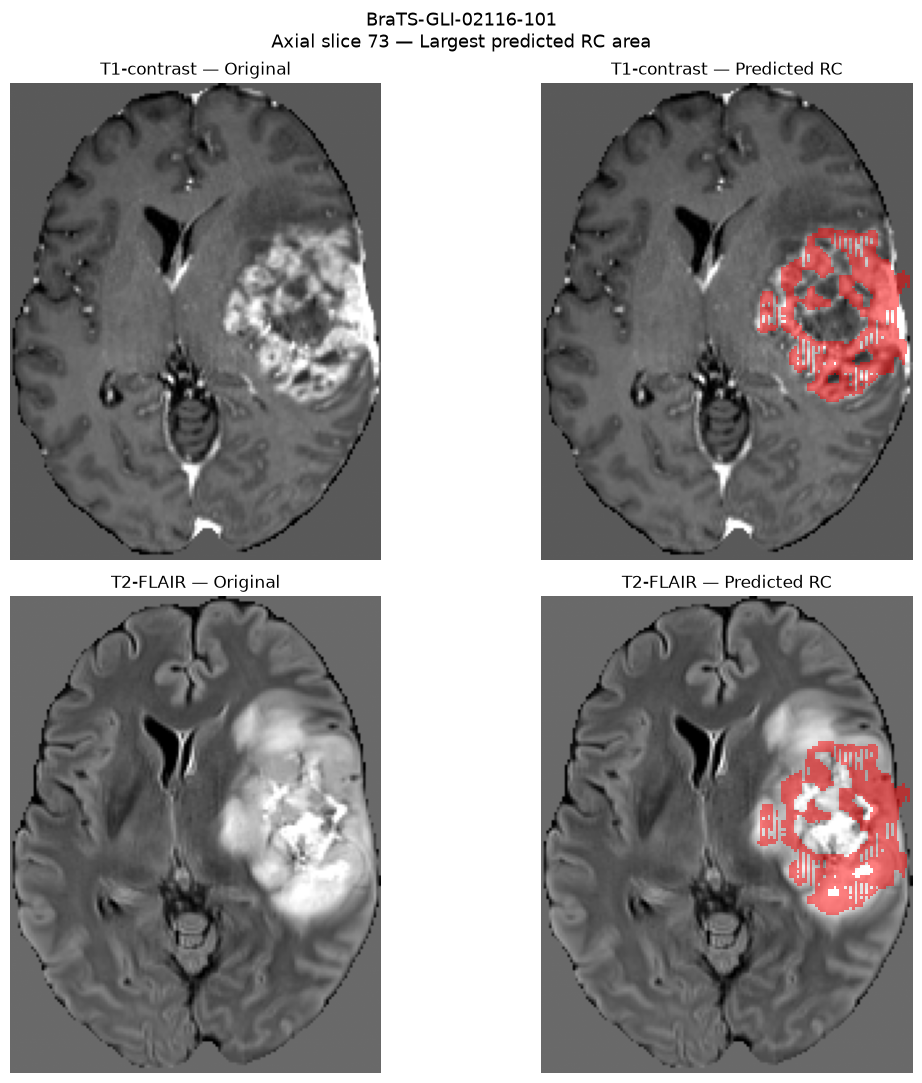

CASE: BraTS-GLI-02116-101
Selected axial slice: 73
Predicted RC voxels: 67825
Reference RC voxels: 0


In [38]:
# -------------------------------------------------------------
# CELL 144 — INSPECT LARGEST RC FALSE-POSITIVE CASE
# -------------------------------------------------------------
#
# Case: BraTS-GLI-02116-101
#
# Apply our established validation preprocessing and run
# full-volume inference with the epoch-38 model.
#
# Display T1-contrast and T2-FLAIR at the axial slice
# containing the largest predicted RC area.
#
# No training or file modifications.
# -------------------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt
import torch
from monai.inferers import sliding_window_inference

# STEP 1 — Retrieve the examination from our fixed
# validation cohort.

target_case_id = "BraTS-GLI-02116-101"

target_case = next(
    case
    for case in selected_validation_cases
    if case["case_id"] == target_case_id
)

# STEP 2 — Apply the original validation preprocessing.

target_processed = large_validation_transforms(target_case)

target_image = target_processed["image"].cpu()
target_reference = target_processed["label"].cpu()

# STEP 3 — Run full-volume sliding-window inference.

evaluation_model.eval()

with torch.inference_mode():

    target_logits = sliding_window_inference(
        inputs=target_image.unsqueeze(0).to(large_device),
        roi_size=(96, 96, 96),
        sw_batch_size=1,
        predictor=evaluation_model,
        overlap=0.25,
    )

    target_prediction = (
        torch.sigmoid(target_logits)[0] >= 0.5
    ).cpu()

# STEP 4 — Identify the axial slice with the largest
# predicted RC area.

rc_mask = target_prediction[3].numpy().astype(bool)

slice_index = int(
    np.argmax(rc_mask.sum(axis=(0, 1)))
)

# STEP 5 — Display both modalities with identical
# slice coordinates.

fig, axes = plt.subplots(2, 2, figsize=(12, 11))

modalities = [
    (1, "T1-contrast"),
    (3, "T2-FLAIR"),
]

for row, (modality_index, modality_name) in enumerate(modalities):

    image_slice = (
        target_image[modality_index, :, :, slice_index]
        .numpy()
        .T
    )

    mask_slice = rc_mask[:, :, slice_index].T

    nonzero = image_slice[image_slice != 0]

    if nonzero.size:
        vmin, vmax = np.percentile(nonzero, [1, 99])
    else:
        vmin, vmax = 0, 1

    for col in range(2):

        ax = axes[row, col]

        ax.imshow(
            image_slice,
            cmap="gray",
            origin="lower",
            vmin=vmin,
            vmax=vmax,
        )

        if col == 1 and mask_slice.any():

            overlay = np.ma.masked_where(
                ~mask_slice,
                mask_slice,
            )

            ax.imshow(
                overlay,
                cmap="autumn",
                alpha=0.5,
                origin="lower",
                interpolation="nearest",
            )

        ax.set_title(
            f"{modality_name} — "
            f"{'Original' if col == 0 else 'Predicted RC'}"
        )

        ax.axis("off")

plt.suptitle(
    f"{target_case_id}\n"
    f"Axial slice {slice_index} — Largest predicted RC area",
    fontsize=13,
)

plt.tight_layout()
plt.show()

# STEP 6 — Report predicted and reference RC voxel counts.

print("CASE:", target_case_id)
print("Selected axial slice:", slice_index)
print("Predicted RC voxels:", int(target_prediction[3].sum()))
print("Reference RC voxels:", int(target_reference[3].sum()))

### From reviewing greatest source of error: enhancing tumour classified as resection cavity

In [39]:
# -------------------------------------------------------------
# CELL 145 — ANALYSE RC FALSE-POSITIVE OVERLAP
# -------------------------------------------------------------
#
# Determine how much of the predicted resection cavity
# overlaps the ground-truth tumour regions:
#
# WT = Whole tumour
# TC = Tumour core
# ET = Enhancing tumour
#
# Also measure predicted RC outside the reference WT.
#
# No inference, training or file modifications.
# -------------------------------------------------------------

import numpy as np

# STEP 1 — Convert the existing masks to Boolean arrays.

predicted_rc = (
    target_prediction[3].cpu().numpy().astype(bool)
)

reference_masks = {
    "WT": target_reference[0].cpu().numpy().astype(bool),
    "TC": target_reference[1].cpu().numpy().astype(bool),
    "ET": target_reference[2].cpu().numpy().astype(bool),
    "RC": target_reference[3].cpu().numpy().astype(bool),
}

# STEP 2 — Confirm this is an RC-absent examination.

assert reference_masks["RC"].sum() == 0

total_predicted_rc = int(predicted_rc.sum())

print("FALSE-POSITIVE RC ANATOMICAL OVERLAP")
print("-" * 65)
print("Case:", target_case_id)
print("Total predicted RC voxels:", total_predicted_rc)

# STEP 3 — Measure overlap with each reference tumour region.

for region_name in ["WT", "TC", "ET"]:

    reference_region = reference_masks[region_name]

    overlap = int(
        np.logical_and(
            predicted_rc,
            reference_region,
        ).sum()
    )

    percentage = (
        100 * overlap / total_predicted_rc
        if total_predicted_rc > 0
        else 0
    )

    print(
        f"\nOverlap with reference {region_name}: "
        f"{overlap:,} voxels ({percentage:.2f}%)"
    )

# STEP 4 — Measure predicted RC outside the reference WT.

outside_wt = int(
    np.logical_and(
        predicted_rc,
        ~reference_masks["WT"],
    ).sum()
)

outside_percentage = (
    100 * outside_wt / total_predicted_rc
    if total_predicted_rc > 0
    else 0
)

print(
    f"\nPredicted RC outside reference WT: "
    f"{outside_wt:,} voxels ({outside_percentage:.2f}%)"
)

print("\nAnatomical overlap analysis completed.")

FALSE-POSITIVE RC ANATOMICAL OVERLAP
-----------------------------------------------------------------
Case: BraTS-GLI-02116-101
Total predicted RC voxels: 67825

Overlap with reference WT: 66,844 voxels (98.55%)

Overlap with reference TC: 66,515 voxels (98.07%)

Overlap with reference ET: 62,320 voxels (91.88%)

Predicted RC outside reference WT: 981 voxels (1.45%)

Anatomical overlap analysis completed.


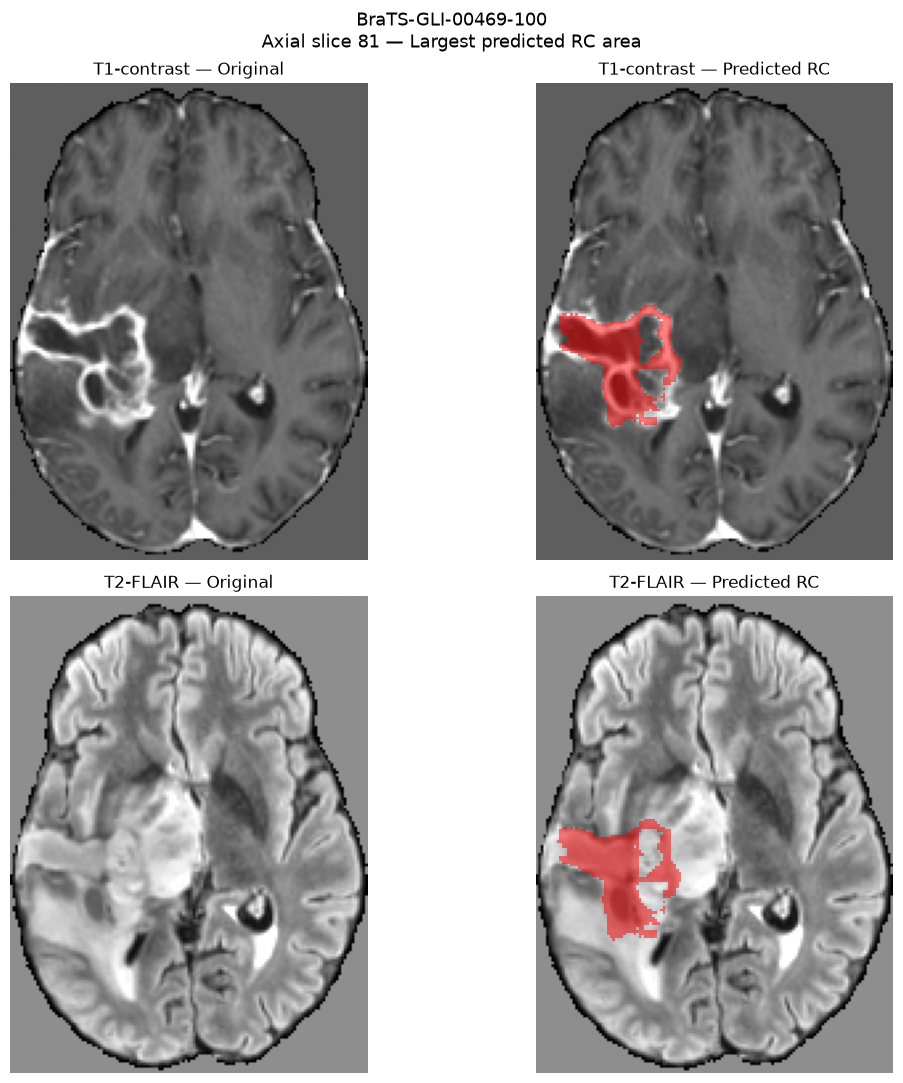

CASE: BraTS-GLI-00469-100
Selected axial slice: 81
Predicted RC voxels: 21765
Reference RC voxels: 0


In [40]:
# -------------------------------------------------------------
# CELL 146 — INSPECT SECOND-LARGEST RC FALSE-POSITIVE CASE
# -------------------------------------------------------------
#
# Case: BraTS-GLI-00469-100
#
# Display T1-contrast and T2-FLAIR images at the axial
# slice with the greatest predicted resection-cavity area.
#
# Uses the existing epoch-38 evaluation model.
# No training or file modifications.
# -------------------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt
import torch
from monai.inferers import sliding_window_inference

# STEP 1 — Select the next validation examination.

target_case_id = "BraTS-GLI-00469-100"

target_case = next(
    case
    for case in selected_validation_cases
    if case["case_id"] == target_case_id
)

# STEP 2 — Apply deterministic validation preprocessing.

target_processed = large_validation_transforms(target_case)

target_image = target_processed["image"].cpu()
target_reference = target_processed["label"].cpu()

# STEP 3 — Generate predictions using the epoch-38 model.

evaluation_model.eval()

with torch.inference_mode():

    target_logits = sliding_window_inference(
        inputs=target_image.unsqueeze(0).to(large_device),
        roi_size=(96, 96, 96),
        sw_batch_size=1,
        predictor=evaluation_model,
        overlap=0.25,
    )

    target_prediction = (
        torch.sigmoid(target_logits)[0] >= 0.5
    ).cpu()

# STEP 4 — Locate the axial slice with the greatest
# predicted RC area.

rc_mask = target_prediction[3].numpy().astype(bool)

slice_index = int(
    np.argmax(rc_mask.sum(axis=(0, 1)))
)

# STEP 5 — Plot original MRI and predicted RC overlays.

fig, axes = plt.subplots(2, 2, figsize=(12, 11))

modalities = [
    (1, "T1-contrast"),
    (3, "T2-FLAIR"),
]

for row, (modality_index, modality_name) in enumerate(modalities):

    image_slice = (
        target_image[modality_index, :, :, slice_index]
        .numpy()
        .T
    )

    mask_slice = rc_mask[:, :, slice_index].T

    nonzero = image_slice[image_slice != 0]

    if nonzero.size:
        vmin, vmax = np.percentile(nonzero, [1, 99])
    else:
        vmin, vmax = 0, 1

    for col in range(2):

        ax = axes[row, col]

        ax.imshow(
            image_slice,
            cmap="gray",
            origin="lower",
            vmin=vmin,
            vmax=vmax,
        )

        if col == 1 and mask_slice.any():

            overlay = np.ma.masked_where(
                ~mask_slice,
                mask_slice,
            )

            ax.imshow(
                overlay,
                cmap="autumn",
                alpha=0.5,
                origin="lower",
                interpolation="nearest",
            )

        ax.set_title(
            f"{modality_name} — "
            f"{'Original' if col == 0 else 'Predicted RC'}"
        )

        ax.axis("off")

plt.suptitle(
    f"{target_case_id}\n"
    f"Axial slice {slice_index} — Largest predicted RC area",
    fontsize=13,
)

plt.tight_layout()
plt.show()

# STEP 6 — Report predicted and reference RC volumes.

print("CASE:", target_case_id)
print("Selected axial slice:", slice_index)
print("Predicted RC voxels:", int(target_prediction[3].sum()))
print("Reference RC voxels:", int(target_reference[3].sum()))

### enhancing tumour is again wrongly classified as resection cavity

In [41]:
# -------------------------------------------------------------
# CELL 147 — RC FALSE-POSITIVE ANATOMICAL DISTRIBUTION
# -------------------------------------------------------------
#
# Case: BraTS-GLI-00469-100
#
# Quantify predicted RC overlap with reference tumour masks.
#
# Additionally partition the predicted RC into mutually
# exclusive anatomical categories so percentages sum to 100%.
#
# No GPU inference, training or file modifications.
# -------------------------------------------------------------

import numpy as np
import pandas as pd

# STEP 1 — Retrieve predictions and reference masks
# from the examination evaluated in Cell 146.

assert target_case_id == "BraTS-GLI-00469-100"

predicted_rc = target_prediction[3].numpy().astype(bool)

reference_wt = target_reference[0].numpy().astype(bool)
reference_tc = target_reference[1].numpy().astype(bool)
reference_et = target_reference[2].numpy().astype(bool)
reference_rc = target_reference[3].numpy().astype(bool)

assert not reference_rc.any(), "This case should be RC-absent."

total_rc = int(predicted_rc.sum())

# STEP 2 — Construct mutually exclusive tumour regions.
#
# ET is contained within TC, and TC within WT.
# Subtracting nested masks avoids double-counting.

exclusive_regions = {
    "Enhancing tumour (ET)": reference_et,
    "TC excluding ET": reference_tc & ~reference_et,
    "WT excluding TC": reference_wt & ~reference_tc,
    "Outside reference WT": ~reference_wt,
}

# STEP 3 — Count predicted RC voxels within each region.

records = []

for region_name, region_mask in exclusive_regions.items():

    overlap = int(np.count_nonzero(predicted_rc & region_mask))

    records.append({
        "reference_region": region_name,
        "rc_voxels": overlap,
        "percentage_of_predicted_rc": (
            100 * overlap / total_rc if total_rc else 0
        ),
    })

overlap_table = pd.DataFrame(records)

# STEP 4 — Confirm that the categories account for
# every predicted RC voxel exactly once.

assert overlap_table["rc_voxels"].sum() == total_rc

# STEP 5 — Display the findings.

print("RC FALSE-POSITIVE ANATOMICAL DISTRIBUTION")
print("-" * 65)
print("Case:", target_case_id)
print("Predicted RC voxels:", f"{total_rc:,}")
print("Reference RC voxels:", int(reference_rc.sum()))

print("\nMUTUALLY EXCLUSIVE REGION BREAKDOWN")
print("-" * 65)

print(
    overlap_table.to_string(
        index=False,
        float_format=lambda value: f"{value:.2f}"
    )
)

print("\nTotal percentage:",
      round(overlap_table["percentage_of_predicted_rc"].sum(), 2))

RC FALSE-POSITIVE ANATOMICAL DISTRIBUTION
-----------------------------------------------------------------
Case: BraTS-GLI-00469-100
Predicted RC voxels: 21,765
Reference RC voxels: 0

MUTUALLY EXCLUSIVE REGION BREAKDOWN
-----------------------------------------------------------------
     reference_region  rc_voxels  percentage_of_predicted_rc
Enhancing tumour (ET)      18350                       84.31
      TC excluding ET       3352                       15.40
      WT excluding TC         32                        0.15
 Outside reference WT         31                        0.14

Total percentage: 100.0


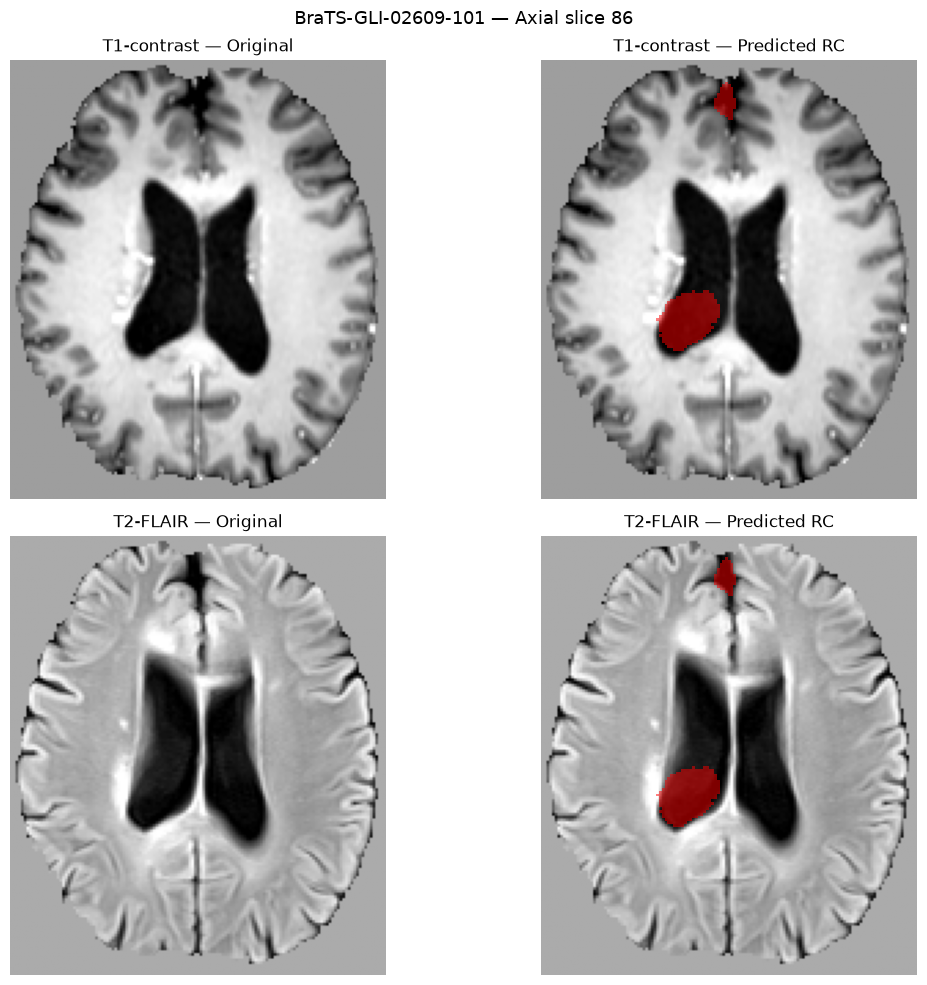

CASE: BraTS-GLI-02609-101
Predicted RC voxels: 11,893
Reference RC voxels: 0

ANATOMICAL DISTRIBUTION
-------------------------------------------------------
Enhancing tumour: 3,577 voxels (30.08%)
TC excluding ET: 24 voxels (0.20%)
WT excluding TC: 93 voxels (0.78%)
Outside WT: 8,199 voxels (68.94%)


In [42]:
# -------------------------------------------------------------
# CELL 148 — THIRD-LARGEST RC FALSE-POSITIVE CASE
# -------------------------------------------------------------
#
# Inspect BraTS-GLI-02609-101 using the epoch-38 U-Net.
#
# Display T1-contrast and T2-FLAIR with predicted RC
# overlays, then quantify overlap with reference tumour.
#
# No training or file modifications.
# -------------------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt
import torch
from monai.inferers import sliding_window_inference

# STEP 1 — Select and preprocess the examination.

target_case_id = "BraTS-GLI-02609-101"

target_case = next(
    case for case in selected_validation_cases
    if case["case_id"] == target_case_id
)

target_processed = large_validation_transforms(target_case)

target_image = target_processed["image"].cpu()
target_reference = target_processed["label"].cpu()

# STEP 2 — Run full-volume inference with the saved
# epoch-38 model.

evaluation_model.eval()

with torch.inference_mode():
    target_logits = sliding_window_inference(
        inputs=target_image.unsqueeze(0).to(large_device),
        roi_size=(96, 96, 96),
        sw_batch_size=1,
        predictor=evaluation_model,
        overlap=0.25,
    )

    target_prediction = (
        torch.sigmoid(target_logits)[0] >= 0.5
    ).cpu()

# STEP 3 — Prepare the predicted RC and reference masks.

predicted_rc = target_prediction[3].numpy().astype(bool)

reference_wt = target_reference[0].numpy().astype(bool)
reference_tc = target_reference[1].numpy().astype(bool)
reference_et = target_reference[2].numpy().astype(bool)
reference_rc = target_reference[3].numpy().astype(bool)

assert not reference_rc.any()

# STEP 4 — Select the axial slice containing the
# greatest predicted RC area.

slice_index = int(
    np.argmax(predicted_rc.sum(axis=(0, 1)))
)

# STEP 5 — Visualise T1-contrast and T2-FLAIR.

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for row, (channel, name) in enumerate([
    (1, "T1-contrast"),
    (3, "T2-FLAIR"),
]):
    image_slice = target_image[channel, :, :, slice_index].numpy().T
    rc_slice = predicted_rc[:, :, slice_index].T

    nonzero = image_slice[image_slice != 0]
    vmin, vmax = (
        np.percentile(nonzero, [1, 99])
        if nonzero.size
        else (0, 1)
    )

    for col in range(2):
        ax = axes[row, col]

        ax.imshow(
            image_slice,
            cmap="gray",
            origin="lower",
            vmin=vmin,
            vmax=vmax,
        )

        if col == 1:
            ax.imshow(
                np.ma.masked_where(~rc_slice, rc_slice),
                cmap="autumn",
                alpha=0.5,
                origin="lower",
                interpolation="nearest",
            )

        ax.set_title(
            f"{name} — {'Original' if col == 0 else 'Predicted RC'}"
        )
        ax.axis("off")

plt.suptitle(
    f"{target_case_id} — Axial slice {slice_index}",
    fontsize=13,
)

plt.tight_layout()
plt.show()

# STEP 6 — Calculate mutually exclusive anatomical
# overlap categories.

total_rc = int(predicted_rc.sum())

regions = {
    "Enhancing tumour": reference_et,
    "TC excluding ET": reference_tc & ~reference_et,
    "WT excluding TC": reference_wt & ~reference_tc,
    "Outside WT": ~reference_wt,
}

print("CASE:", target_case_id)
print("Predicted RC voxels:", f"{total_rc:,}")
print("Reference RC voxels:", int(reference_rc.sum()))
print("\nANATOMICAL DISTRIBUTION")
print("-" * 55)

for name, mask in regions.items():
    count = int(np.count_nonzero(predicted_rc & mask))
    percentage = 100 * count / total_rc if total_rc else 0

    print(f"{name}: {count:,} voxels ({percentage:.2f}%)")

### Ventricles and interhemispheric fissure (normal anatomical structures) wrongly classified as resection cavity

In [43]:
# -------------------------------------------------------------
# CELL 149 — PREDICTED ET–RC OVERLAP AND COUNT CHECK
# -------------------------------------------------------------
#
# Determine whether the model simultaneously predicts
# enhancing tumour (ET) and resection cavity (RC).
#
# Compare the current prediction against the saved
# case-level evaluation count.
#
# No inference, training or file modifications.
# -------------------------------------------------------------

import numpy as np

assert target_case_id == "BraTS-GLI-02609-101"

# STEP 1 — Retrieve the predicted segmentation channels.

predicted_et = target_prediction[2].numpy().astype(bool)
predicted_rc = target_prediction[3].numpy().astype(bool)

# STEP 2 — Calculate simultaneous ET and RC predictions.

et_rc_overlap = predicted_et & predicted_rc

rc_voxels = int(predicted_rc.sum())
et_voxels = int(predicted_et.sum())
overlap_voxels = int(et_rc_overlap.sum())

overlap_percentage = (
    100 * overlap_voxels / rc_voxels
    if rc_voxels
    else 0
)

# STEP 3 — Retrieve the saved RC false-positive count.

saved_row = validation_case_metrics.loc[
    (validation_case_metrics["case_id"] == target_case_id)
    & (validation_case_metrics["region"] == "RC")
]

assert len(saved_row) == 1

saved_rc_voxels = int(
    saved_row.iloc[0]["false_positive_voxels"]
)

# STEP 4 — Display results.

print("PREDICTED ET–RC OVERLAP")
print("-" * 60)
print("Case:", target_case_id)

print("\nPredicted ET voxels:", f"{et_voxels:,}")
print("Predicted RC voxels:", f"{rc_voxels:,}")

print(
    "Simultaneous ET and RC voxels:",
    f"{overlap_voxels:,}"
)

print(
    "Percentage of predicted RC also labelled ET:",
    f"{overlap_percentage:.2f}%"
)

print("\nREPRODUCIBILITY CHECK")
print("-" * 60)

print("Saved evaluation RC voxels:", saved_rc_voxels)
print("Current inference RC voxels:", rc_voxels)
print("Difference:", rc_voxels - saved_rc_voxels)

PREDICTED ET–RC OVERLAP
------------------------------------------------------------
Case: BraTS-GLI-02609-101

Predicted ET voxels: 10,754
Predicted RC voxels: 11,893
Simultaneous ET and RC voxels: 3,682
Percentage of predicted RC also labelled ET: 30.96%

REPRODUCIBILITY CHECK
------------------------------------------------------------
Saved evaluation RC voxels: 11892
Current inference RC voxels: 11893
Difference: 1


In [44]:
# -------------------------------------------------------------
# CELL 150 — INSPECT PER-CASE METRIC CONSTRUCTION
# -------------------------------------------------------------
#
# Examine how evaluate_segmentation_model() constructs
# its individual case-level records.
#
# This will help us determine where ET–RC overlap metrics
# could be added in a future evaluation pass.
#
# Read-only; no GPU inference or training.
# -------------------------------------------------------------

import ast

# STEP 1 — Retrieve the original function source from
# the notebook cell located previously.

source = notebook_data["cells"][96]["source"]

if isinstance(source, list):
    source = "".join(source)

parsed = ast.parse(source)

function_node = next(
    node
    for node in ast.walk(parsed)
    if isinstance(node, ast.FunctionDef)
    and node.name == "evaluate_segmentation_model"
)

function_source = ast.get_source_segment(
    source,
    function_node,
)

assert function_source is not None

# STEP 2 — Find where per-case metric records are appended.

lines = function_source.splitlines()

matching_lines = [
    index
    for index, line in enumerate(lines)
    if "records.append" in line
]

print("PER-CASE METRIC CONSTRUCTION")
print("-" * 65)

print("Record append locations:", matching_lines)

# STEP 3 — Display context around each append operation.

for index in matching_lines:

    start = max(0, index - 30)
    end = min(len(lines), index + 35)

    print(f"\nSOURCE LINES {start + 1}–{end}")
    print("-" * 65)

    for line_number in range(start, end):
        print(
            f"{line_number + 1:>4}: "
            f"{lines[line_number]}"
        )

PER-CASE METRIC CONSTRUCTION
-----------------------------------------------------------------
Record append locations: [108, 152]

SOURCE LINES 79–143
-----------------------------------------------------------------
  79:                 # MOVE BINARY MASKS TO CPU
  80:                 # ---------------------------------------------
  81: 
  82:                 predicted_masks = (
  83:                     predictions[0].cpu().numpy()
  84:                 )
  85: 
  86:                 ground_truth_masks = (
  87:                     labels[0].cpu().numpy()
  88:                 )
  89: 
  90:                 assert predicted_masks.shape == (
  91:                     ground_truth_masks.shape
  92:                 )
  93: 
  94:                 assert predicted_masks.shape[0] == 4
  95: 
  96:                 # ---------------------------------------------
  97:                 # CALCULATE REGION-SPECIFIC METRICS
  98:                 # ---------------------------------------------


In [45]:
# -------------------------------------------------------------
# CELL 151 — VALIDATION-WIDE ET–RC OVERLAP ANALYSIS
# -------------------------------------------------------------
#
# Investigate whether the model simultaneously predicts
# enhancing tumour (ET) and resection cavity (RC).
#
# Compare predicted ET–RC overlap with RC predictions
# occurring inside reference enhancing tumour.
#
# Save a separate diagnostic CSV for reproducibility.
#
# No training or checkpoint modifications.
# -------------------------------------------------------------

import time
import numpy as np
import pandas as pd
import torch
from monai.inferers import sliding_window_inference

# STEP 1 — Verify the evaluation configuration.

assert len(selected_validation_cases) == 24
assert not evaluation_model.training

diagnostic_records = []

start_time = time.perf_counter()

# STEP 2 — Evaluate each validation examination
# independently using deterministic preprocessing.

with torch.inference_mode():

    for case_number, case in enumerate(
        selected_validation_cases, start=1
    ):

        processed = large_validation_transforms(case)

        image = processed["image"].unsqueeze(0).to(
            large_device
        )

        reference = (
            processed["label"].cpu().numpy().astype(bool)
        )

        # Full-volume inference with the established settings.
        logits = sliding_window_inference(
            inputs=image,
            roi_size=(96, 96, 96),
            sw_batch_size=1,
            predictor=evaluation_model,
            overlap=0.25,
        )

        predicted = (
            (torch.sigmoid(logits)[0] >= 0.5)
            .cpu()
            .numpy()
            .astype(bool)
        )

        # Channel order: WT, TC, ET, RC.
        predicted_et = predicted[2]
        predicted_rc = predicted[3]

        reference_et = reference[2]
        reference_rc = reference[3]

        rc_voxels = int(predicted_rc.sum())

        simultaneous_et_rc = int(
            np.count_nonzero(predicted_et & predicted_rc)
        )

        rc_within_reference_et = int(
            np.count_nonzero(predicted_rc & reference_et)
        )

        diagnostic_records.append({
            "case_id": case["case_id"],
            "subject_id": case["subject_id"],
            "reference_rc_present": bool(reference_rc.any()),
            "predicted_rc_voxels": rc_voxels,
            "simultaneous_predicted_et_rc_voxels": simultaneous_et_rc,
            "percentage_rc_also_predicted_et": (
                100 * simultaneous_et_rc / rc_voxels
                if rc_voxels else 0.0
            ),
            "predicted_rc_within_reference_et_voxels": rc_within_reference_et,
            "percentage_rc_within_reference_et": (
                100 * rc_within_reference_et / rc_voxels
                if rc_voxels else 0.0
            ),
        })

        del image, logits

        print(
            f"[{case_number:02d}/24] "
            f"{case['case_id']} completed"
        )

# STEP 3 — Construct and save the diagnostic table.

et_rc_diagnostics = pd.DataFrame(diagnostic_records)

diagnostic_path = (
    experiment_directory
    / "logs"
    / "validation_et_rc_overlap_best_epoch38.csv"
)

et_rc_diagnostics.to_csv(
    diagnostic_path,
    index=False,
)

# STEP 4 — Summarise the RC-absent examinations.

rc_absent_diagnostics = (
    et_rc_diagnostics.loc[
        ~et_rc_diagnostics["reference_rc_present"]
    ]
    .sort_values(
        "predicted_rc_voxels",
        ascending=False,
    )
)

print("\nRC-ABSENT CASES — ET–RC OVERLAP")
print("-" * 75)

print(
    rc_absent_diagnostics[
        [
            "case_id",
            "predicted_rc_voxels",
            "percentage_rc_also_predicted_et",
            "percentage_rc_within_reference_et",
        ]
    ].to_string(
        index=False,
        float_format=lambda value: f"{value:.2f}"
    )
)

# STEP 5 — Report overall completion.

print("\nDIAGNOSTIC SUMMARY")
print("-" * 75)

print("Cases evaluated:", len(et_rc_diagnostics))
print(
    "Cases with simultaneous ET–RC predictions:",
    int(
        (
            et_rc_diagnostics[
                "simultaneous_predicted_et_rc_voxels"
            ] > 0
        ).sum()
    )
)

print(
    "Evaluation time:",
    round(time.perf_counter() - start_time, 1),
    "seconds"
)

print("Saved:", diagnostic_path.name)

[01/24] BraTS-GLI-02736-101 completed
[02/24] BraTS-GLI-02105-104 completed
[03/24] BraTS-GLI-02382-100 completed
[04/24] BraTS-GLI-00469-100 completed
[05/24] BraTS-GLI-02796-101 completed
[06/24] BraTS-GLI-02726-100 completed
[07/24] BraTS-GLI-02116-101 completed
[08/24] BraTS-GLI-02217-103 completed
[09/24] BraTS-GLI-02375-101 completed
[10/24] BraTS-GLI-02260-100 completed
[11/24] BraTS-GLI-02553-101 completed
[12/24] BraTS-GLI-02609-101 completed
[13/24] BraTS-GLI-02817-100 completed
[14/24] BraTS-GLI-02158-101 completed
[15/24] BraTS-GLI-02752-101 completed
[16/24] BraTS-GLI-02813-101 completed
[17/24] BraTS-GLI-02394-100 completed
[18/24] BraTS-GLI-02863-100 completed
[19/24] BraTS-GLI-02828-100 completed
[20/24] BraTS-GLI-02632-104 completed
[21/24] BraTS-GLI-02634-101 completed
[22/24] BraTS-GLI-03019-100 completed
[23/24] BraTS-GLI-02905-100 completed
[24/24] BraTS-GLI-02880-100 completed

RC-ABSENT CASES — ET–RC OVERLAP
-------------------------------------------------------

In [46]:
# -------------------------------------------------------------
# CELL 152 — ET–RC OVERLAP BY REFERENCE RC PRESENCE
# -------------------------------------------------------------
#
# Compare simultaneous ET–RC predictions between:
#
# 1. Examinations containing an annotated resection cavity.
# 2. Examinations without an annotated resection cavity.
#
# Report both case-level frequency and voxel-weighted
# overlap, since small and large predictions should not
# contribute equally to the aggregate voxel burden.
#
# No inference, training or file modifications.
# -------------------------------------------------------------

import pandas as pd

# STEP 1 — Verify the diagnostic data.

assert len(et_rc_diagnostics) == 24

required_columns = [
    "reference_rc_present",
    "predicted_rc_voxels",
    "simultaneous_predicted_et_rc_voxels",
]

assert all(
    column in et_rc_diagnostics.columns
    for column in required_columns
)

# STEP 2 — Summarise RC-present and RC-absent groups.

summary_records = []

for rc_present, group in et_rc_diagnostics.groupby(
    "reference_rc_present"
):

    total_rc = int(group["predicted_rc_voxels"].sum())

    total_overlap = int(
        group["simultaneous_predicted_et_rc_voxels"].sum()
    )

    cases_with_overlap = int(
        (
            group["simultaneous_predicted_et_rc_voxels"] > 0
        ).sum()
    )

    summary_records.append({
        "reference_rc_status": (
            "RC present" if rc_present else "RC absent"
        ),
        "examinations": len(group),
        "cases_with_et_rc_overlap": cases_with_overlap,
        "total_predicted_rc_voxels": total_rc,
        "total_et_rc_overlap_voxels": total_overlap,
        "voxel_weighted_overlap_pct": (
            100 * total_overlap / total_rc
            if total_rc else 0.0
        ),
    })

overlap_group_summary = pd.DataFrame(summary_records)

# STEP 3 — Display the comparison.

print("ET–RC PREDICTION OVERLAP BY REFERENCE RC STATUS")
print("-" * 75)

print(
    overlap_group_summary.to_string(
        index=False,
        float_format=lambda value: f"{value:.2f}"
    )
)

# STEP 4 — Display individual RC-present examinations
# ranked by percentage of RC simultaneously predicted ET.

rc_present_cases = (
    et_rc_diagnostics.loc[
        et_rc_diagnostics["reference_rc_present"]
    ]
    .sort_values(
        "percentage_rc_also_predicted_et",
        ascending=False,
    )
)

print("\nRC-PRESENT EXAMINATIONS — HIGHEST ET–RC OVERLAP")
print("-" * 75)

print(
    rc_present_cases[
        [
            "case_id",
            "predicted_rc_voxels",
            "percentage_rc_also_predicted_et",
        ]
    ].head(10).to_string(
        index=False,
        float_format=lambda value: f"{value:.2f}"
    )
)

ET–RC PREDICTION OVERLAP BY REFERENCE RC STATUS
---------------------------------------------------------------------------
reference_rc_status  examinations  cases_with_et_rc_overlap  total_predicted_rc_voxels  total_et_rc_overlap_voxels  voxel_weighted_overlap_pct
          RC absent             5                         3                     102425                       88647                       86.55
         RC present            19                        17                     486401                       56393                       11.59

RC-PRESENT EXAMINATIONS — HIGHEST ET–RC OVERLAP
---------------------------------------------------------------------------
            case_id  predicted_rc_voxels  percentage_rc_also_predicted_et
BraTS-GLI-02382-100                18164                            77.21
BraTS-GLI-02260-100                 3274                            49.82
BraTS-GLI-02634-101                30522                            41.16
BraTS-GLI-02375-101       

### addressing enhancing tumour and resection cavity overlap to reduce false positives in RC classification

In [47]:
# -------------------------------------------------------------
# CELL 153 — ESTIMATE RC FALSE-POSITIVE REDUCTION
# -------------------------------------------------------------
#
# Simulate excluding predicted RC voxels wherever the model
# simultaneously predicts enhancing tumour.
#
# This analysis is restricted to RC-absent examinations,
# where every predicted RC voxel is a false positive.
#
# IMPORTANT:
# This does not evaluate RC-present case sensitivity or Dice.
# No GPU inference, training or file modifications.
# -------------------------------------------------------------

import pandas as pd

# STEP 1 — Select examinations without reference RC.

rc_absent = et_rc_diagnostics.loc[
    ~et_rc_diagnostics["reference_rc_present"]
].copy()

# STEP 2 — Calculate the number of RC voxels that would
# remain after excluding simultaneous predicted ET–RC voxels.

rc_absent["remaining_rc_voxels"] = (
    rc_absent["predicted_rc_voxels"]
    - rc_absent["simultaneous_predicted_et_rc_voxels"]
)

# STEP 3 — Calculate the percentage reduction in
# false-positive RC volume for each examination.

rc_absent["false_positive_reduction_pct"] = (
    100
    * rc_absent["simultaneous_predicted_et_rc_voxels"]
    / rc_absent["predicted_rc_voxels"].replace(0, float("nan"))
)

# STEP 4 — Display the results.

print("SIMULATED ET–RC EXCLUSION — RC-ABSENT CASES")
print("-" * 75)

print(
    rc_absent[
        [
            "case_id",
            "predicted_rc_voxels",
            "remaining_rc_voxels",
            "false_positive_reduction_pct",
        ]
    ].to_string(
        index=False,
        float_format=lambda value: f"{value:.2f}"
    )
)

# STEP 5 — Calculate the overall reduction.

original_total = int(
    rc_absent["predicted_rc_voxels"].sum()
)

corrected_total = int(
    rc_absent["remaining_rc_voxels"].sum()
)

overall_reduction = (
    100 * (original_total - corrected_total) / original_total
)

print("\nOVERALL RC FALSE-POSITIVE BURDEN")
print("-" * 75)

print("Original:", f"{original_total:,}", "voxels")
print("After exclusion:", f"{corrected_total:,}", "voxels")
print("Reduction:", f"{overall_reduction:.2f}%")

SIMULATED ET–RC EXCLUSION — RC-ABSENT CASES
---------------------------------------------------------------------------
            case_id  predicted_rc_voxels  remaining_rc_voxels  false_positive_reduction_pct
BraTS-GLI-02736-101                  637                  637                          0.00
BraTS-GLI-00469-100                21765                 2520                         88.42
BraTS-GLI-02116-101                67825                 2105                         96.90
BraTS-GLI-02217-103                  305                  305                          0.00
BraTS-GLI-02609-101                11893                 8211                         30.96

OVERALL RC FALSE-POSITIVE BURDEN
---------------------------------------------------------------------------
Original: 102,425 voxels
After exclusion: 13,778 voxels
Reduction: 86.55%


In [48]:
# -------------------------------------------------------------
# CELL 154 — EVALUATE ET–RC EXCLUSION IN RC-PRESENT CASES
# -------------------------------------------------------------
#
# Compare original resection-cavity predictions with a
# post-processing rule that excludes voxels also predicted ET.
#
# Measure Dice, precision and recall for examinations
# containing genuine annotated resection cavities.
#
# The trained model remains unchanged.
# -------------------------------------------------------------

import time
import numpy as np
import pandas as pd
import torch

from monai.inferers import sliding_window_inference

assert not evaluation_model.training

comparison_records = []
start_time = time.perf_counter()

# STEP 1 — Evaluate only cases with a reference cavity.
# The deterministic validation transform preserves the
# same preprocessing used for our previous evaluation.

with torch.inference_mode():

    for case in selected_validation_cases:

        processed = large_validation_transforms(case)

        reference_rc = (
            processed["label"][3].cpu().numpy().astype(bool)
        )

        if not reference_rc.any():
            continue

        image = (
            processed["image"]
            .unsqueeze(0)
            .to(large_device)
        )

        logits = sliding_window_inference(
            inputs=image,
            roi_size=(96, 96, 96),
            sw_batch_size=1,
            predictor=evaluation_model,
            overlap=0.25,
        )

        prediction = (
            (torch.sigmoid(logits)[0] >= 0.5)
            .cpu()
            .numpy()
            .astype(bool)
        )

        predicted_et = prediction[2]
        original_rc = prediction[3]

        # STEP 2 — Apply the proposed exclusion rule.

        corrected_rc = original_rc & ~predicted_et

        # STEP 3 — Calculate region metrics.
        # All selected reference masks contain RC.

        for method, predicted_rc in [
            ("Original", original_rc),
            ("ET–RC exclusion", corrected_rc),
        ]:

            true_positive = np.count_nonzero(
                predicted_rc & reference_rc
            )

            false_positive = np.count_nonzero(
                predicted_rc & ~reference_rc
            )

            false_negative = np.count_nonzero(
                ~predicted_rc & reference_rc
            )

            dice = (
                2 * true_positive
                / (2 * true_positive + false_positive + false_negative)
            )

            precision = (
                true_positive / (true_positive + false_positive)
                if (true_positive + false_positive) else 0.0
            )

            recall = (
                true_positive / (true_positive + false_negative)
                if (true_positive + false_negative) else 0.0
            )

            comparison_records.append({
                "case_id": case["case_id"],
                "method": method,
                "dice": dice,
                "precision": precision,
                "recall": recall,
                "true_positive_voxels": int(true_positive),
                "false_positive_voxels": int(false_positive),
                "false_negative_voxels": int(false_negative),
            })

        del image, logits

        print(f"Completed: {case['case_id']}")

# STEP 4 — Save case-level comparison results.

rc_correction_comparison = pd.DataFrame(comparison_records)

comparison_path = (
    experiment_directory
    / "logs"
    / "rc_et_exclusion_comparison_best_epoch38.csv"
)

rc_correction_comparison.to_csv(
    comparison_path,
    index=False,
)

# STEP 5 — Compare average performance.

summary = (
    rc_correction_comparison
    .groupby("method")[["dice", "precision", "recall"]]
    .mean()
)

print("\nRC-PRESENT EXAMINATIONS — MEAN PERFORMANCE")
print("-" * 65)
print(summary.to_string(float_format=lambda x: f"{x:.4f}"))

# STEP 6 — Show the change relative to the original model.

original = summary.loc["Original"]
corrected = summary.loc["ET–RC exclusion"]

print("\nCHANGE AFTER ET–RC EXCLUSION")
print("-" * 65)

for metric in ["dice", "precision", "recall"]:
    difference = corrected[metric] - original[metric]
    print(f"{metric.capitalize()}: {difference:+.4f}")

print("\nCases evaluated:", len(comparison_records) // 2)
print("Elapsed:", round(time.perf_counter() - start_time, 1), "seconds")
print("Saved:", comparison_path.name)

Completed: BraTS-GLI-02105-104
Completed: BraTS-GLI-02382-100
Completed: BraTS-GLI-02796-101
Completed: BraTS-GLI-02726-100
Completed: BraTS-GLI-02375-101
Completed: BraTS-GLI-02260-100
Completed: BraTS-GLI-02553-101
Completed: BraTS-GLI-02817-100
Completed: BraTS-GLI-02158-101
Completed: BraTS-GLI-02752-101
Completed: BraTS-GLI-02813-101
Completed: BraTS-GLI-02394-100
Completed: BraTS-GLI-02863-100
Completed: BraTS-GLI-02828-100
Completed: BraTS-GLI-02632-104
Completed: BraTS-GLI-02634-101
Completed: BraTS-GLI-03019-100
Completed: BraTS-GLI-02905-100
Completed: BraTS-GLI-02880-100

RC-PRESENT EXAMINATIONS — MEAN PERFORMANCE
-----------------------------------------------------------------
                  dice  precision  recall
method                                   
ET–RC exclusion 0.5748     0.5905  0.6261
Original        0.5405     0.5377  0.6490

CHANGE AFTER ET–RC EXCLUSION
-----------------------------------------------------------------
Dice: +0.0343
Precision: +0.0528
Reca

In [49]:
# -------------------------------------------------------------
# CELL 155 — CASE-LEVEL EFFECT OF ET–RC EXCLUSION
# -------------------------------------------------------------
#
# Examine whether the post-processing improvement is consistent
# across the 19 examinations containing genuine RC.
#
# Identify:
#   - Cases with improved or worsened Dice.
#   - Largest reductions in recall.
#   - Changes in true-positive and false-positive voxels.
#
# No GPU inference or file modifications.
# -------------------------------------------------------------

import pandas as pd
import numpy as np

assert len(rc_correction_comparison) == 38

# STEP 1 — Separate original and corrected results.

original_cases = (
    rc_correction_comparison.loc[
        rc_correction_comparison["method"] == "Original"
    ]
    .set_index("case_id")
)

corrected_cases = (
    rc_correction_comparison.loc[
        rc_correction_comparison["method"] == "ET–RC exclusion"
    ]
    .set_index("case_id")
)

assert set(original_cases.index) == set(corrected_cases.index)

# STEP 2 — Construct a case-level comparison.

case_effects = pd.DataFrame(
    index=original_cases.index
)

for metric in ["dice", "precision", "recall"]:

    case_effects[f"original_{metric}"] = original_cases[metric]

    case_effects[f"corrected_{metric}"] = corrected_cases[metric]

    case_effects[f"change_{metric}"] = (
        corrected_cases[metric] - original_cases[metric]
    )

# STEP 3 — Calculate how many true-positive and false-positive
# RC voxels were removed by the exclusion rule.

case_effects["true_positive_voxels_removed"] = (
    original_cases["true_positive_voxels"]
    - corrected_cases["true_positive_voxels"]
)

case_effects["false_positive_voxels_removed"] = (
    original_cases["false_positive_voxels"]
    - corrected_cases["false_positive_voxels"]
)

# The reference RC volume is TP + FN and does not change
# between original and corrected predictions.

case_effects["reference_rc_voxels"] = (
    original_cases["true_positive_voxels"]
    + original_cases["false_negative_voxels"]
)

# STEP 4 — Summarise improvement and deterioration.

tolerance = 1e-8

improved = int(
    (case_effects["change_dice"] > tolerance).sum()
)

worsened = int(
    (case_effects["change_dice"] < -tolerance).sum()
)

unchanged = len(case_effects) - improved - worsened

print("CASE-LEVEL RC DICE CHANGES")
print("-" * 70)

print("Improved:", improved)
print("Worsened:", worsened)
print("Unchanged:", unchanged)

print("\nTOTAL VOXELS REMOVED")
print("-" * 70)

print(
    "True-positive RC voxels removed:",
    f"{case_effects['true_positive_voxels_removed'].sum():,}"
)

print(
    "False-positive RC voxels removed:",
    f"{case_effects['false_positive_voxels_removed'].sum():,}"
)

# STEP 5 — Display examinations with the largest deterioration.

print("\nLARGEST RC DICE DETERIORATIONS")
print("-" * 70)

print(
    case_effects.sort_values("change_dice")[
        [
            "reference_rc_voxels",
            "original_dice",
            "corrected_dice",
            "change_dice",
            "change_recall",
        ]
    ].head(10).to_string(
        float_format=lambda value: f"{value:.4f}"
    )
)

# STEP 6 — Display examinations with the largest improvement.

print("\nLARGEST RC DICE IMPROVEMENTS")
print("-" * 70)

print(
    case_effects.sort_values(
        "change_dice",
        ascending=False,
    )[
        [
            "reference_rc_voxels",
            "original_dice",
            "corrected_dice",
            "change_dice",
            "change_recall",
        ]
    ].head(10).to_string(
        float_format=lambda value: f"{value:.4f}"
    )
)

CASE-LEVEL RC DICE CHANGES
----------------------------------------------------------------------
Improved: 13
Worsened: 4
Unchanged: 2

TOTAL VOXELS REMOVED
----------------------------------------------------------------------
True-positive RC voxels removed: 2,573
False-positive RC voxels removed: 53,820

LARGEST RC DICE DETERIORATIONS
----------------------------------------------------------------------
                     reference_rc_voxels  original_dice  corrected_dice  change_dice  change_recall
case_id                                                                                            
BraTS-GLI-02817-100                 1046         0.0633          0.0481      -0.0152        -0.1845
BraTS-GLI-02158-101                14962         0.0151          0.0004      -0.0147        -0.0076
BraTS-GLI-02260-100                 8694         0.1355          0.1300      -0.0055        -0.0160
BraTS-GLI-02726-100                10897         0.5861          0.5857      -0.0004    

In [50]:
# -------------------------------------------------------------
# CELL 156 — RESECTION-CAVITY SIZE AND CORRECTION EFFECT
# -------------------------------------------------------------
#
# Determine whether smaller reference cavities tend to
# experience greater Dice or recall deterioration after
# ET–RC exclusion.
#
# Uses the case-level results from Cell 155.
# No GPU inference, training or file modifications.
# -------------------------------------------------------------

import numpy as np
import pandas as pd

assert len(case_effects) == 19

# STEP 1 — Calculate Spearman rank correlations.
#
# Spearman correlation assesses monotonic relationships
# without assuming a linear association.

size_vs_dice = case_effects[
    "reference_rc_voxels"
].corr(
    case_effects["change_dice"],
    method="spearman",
)

size_vs_recall = case_effects[
    "reference_rc_voxels"
].corr(
    case_effects["change_recall"],
    method="spearman",
)

print("CAVITY SIZE VS POST-PROCESSING EFFECT")
print("-" * 65)

print(
    "Spearman correlation — size vs Dice change:",
    f"{size_vs_dice:.4f}"
)

print(
    "Spearman correlation — size vs recall change:",
    f"{size_vs_recall:.4f}"
)

# STEP 2 — Divide examinations into three groups
# based on reference cavity volume.
#
# These are relative size categories within this
# small validation subset, not clinical size thresholds.

size_analysis = case_effects.copy()

size_analysis["size_group"] = pd.qcut(
    size_analysis["reference_rc_voxels"],
    q=3,
    labels=["Small", "Medium", "Large"],
)

# STEP 3 — Summarise performance changes by size group.

size_summary = (
    size_analysis
    .groupby("size_group", observed=True)
    .agg(
        examinations=("change_dice", "size"),
        median_reference_voxels=("reference_rc_voxels", "median"),
        mean_dice_change=("change_dice", "mean"),
        mean_recall_change=("change_recall", "mean"),
        worsened_cases=(
            "change_dice",
            lambda values: int((values < -1e-8).sum()),
        ),
    )
)

print("\nPERFORMANCE BY REFERENCE CAVITY SIZE")
print("-" * 65)

print(
    size_summary.to_string(
        float_format=lambda value: f"{value:.4f}"
    )
)

# STEP 4 — Identify the smallest cavities and
# their corresponding performance changes.

print("\nSMALLEST REFERENCE CAVITIES")
print("-" * 65)

print(
    size_analysis.sort_values(
        "reference_rc_voxels"
    )[
        [
            "reference_rc_voxels",
            "original_dice",
            "corrected_dice",
            "change_dice",
            "change_recall",
        ]
    ].head(8).to_string(
        float_format=lambda value: f"{value:.4f}"
    )
)

CAVITY SIZE VS POST-PROCESSING EFFECT
-----------------------------------------------------------------
Spearman correlation — size vs Dice change: 0.0307
Spearman correlation — size vs recall change: 0.1186

PERFORMANCE BY REFERENCE CAVITY SIZE
-----------------------------------------------------------------
            examinations  median_reference_voxels  mean_dice_change  mean_recall_change  worsened_cases
size_group                                                                                             
Small                  7                2384.0000            0.0645             -0.0520               1
Medium                 6               16225.0000            0.0172             -0.0084               3
Large                  6               42671.0000            0.0161             -0.0034               0

SMALLEST REFERENCE CAVITIES
-----------------------------------------------------------------
                     reference_rc_voxels  original_dice  corrected_dice  

In [51]:
# -------------------------------------------------------------
# CELL 157 — DOCUMENT ET–RC POST-PROCESSING EXPERIMENT
# -------------------------------------------------------------
#
# Update the living GitHub research report with results from
# Cells 152–156.
#
# Preserve existing content, avoid duplicate sections,
# and create a backup before modifying the report.
#
# No GPU inference or model training.
# -------------------------------------------------------------

from pathlib import Path
from shutil import copy2

# STEP 1 — Locate the existing report.

repo_root = Path.cwd().resolve()

if repo_root.name == "notebooks":
    repo_root = repo_root.parent

report_path = (
    repo_root / "reports" / "glioma_segmentation_report.md"
)

assert report_path.exists(), (
    f"Report not found: {report_path}"
)

# STEP 2 — Define the new report section.

section_title = (
    "## Anatomical-Consistency Post-processing Experiment"
)

new_section = """## Anatomical-Consistency Post-processing Experiment

### Rationale

Clinical error analysis identified frequent simultaneous predictions
of enhancing tumour (ET) and resection cavity (RC).

These predictions were particularly prominent in examinations without
an annotated resection cavity.

A simple post-processing intervention was therefore evaluated to
determine whether enforcing ET–RC exclusivity could improve
resection-cavity segmentation.

### Method

The existing epoch-38 model checkpoint was used without retraining.

Predicted RC voxels were removed wherever the model simultaneously
predicted ET:

`RC_corrected = RC_predicted AND NOT ET_predicted`

The intervention was evaluated on the same 24 validation examinations
used for baseline assessment.

### False-positive burden in RC-absent examinations

Among five examinations without an annotated resection cavity:

| Measurement | Original | After ET–RC exclusion |
|---|---:|---:|
| Predicted RC voxels | 102,425 | 13,778 |
| Reduction in false-positive volume | — | 86.55% |

The reduction was particularly substantial in the two largest
tumour-associated false-positive examinations:

- `BraTS-GLI-02116-101`: 96.90% reduction.
- `BraTS-GLI-00469-100`: 88.42% reduction.

The Sylvian fissure-associated error in `BraTS-GLI-02736-101`
was unaffected by this intervention.

This supports the interpretation that different anatomical
error patterns may require different corrective strategies.

### Segmentation performance in RC-present examinations

The intervention was evaluated in 19 examinations containing
annotated resection cavities.

| Metric | Original | Corrected | Change |
|---|---:|---:|---:|
| Mean RC Dice | 0.5405 | 0.5748 | +0.0343 |
| Mean precision | 0.5377 | 0.5905 | +0.0528 |
| Mean recall | 0.6490 | 0.6261 | -0.0229 |

Mean Dice and precision improved, while mean recall decreased.

The correction removed:

- 53,820 false-positive RC voxels.
- 2,573 true-positive RC voxels.

Thus, approximately 95.4% of removed voxels were false positives,
while approximately 4.6% were correctly identified cavity voxels.

### Case-level results

Among the 19 RC-present examinations:

- Dice improved in 13 examinations.
- Dice deteriorated in 4 examinations.
- Dice remained unchanged in 2 examinations.

The largest improvement occurred in `BraTS-GLI-02382-100`,
where Dice increased from 0.2360 to 0.5014.

However, some examinations deteriorated.

In `BraTS-GLI-02817-100`, Dice decreased from 0.0633 to 0.0481,
with recall falling by 0.1845.

In `BraTS-GLI-02158-101`, Dice decreased from 0.0151 to 0.0004.

These findings demonstrate that improved mean performance
does not guarantee improved performance in every examination.

### Effect of reference cavity size

An exploratory analysis divided the 19 RC-present examinations
into three groups based on reference cavity volume.

| Size group | Cases | Mean Dice change | Mean recall change |
|---|---:|---:|---:|
| Small | 7 | +0.0645 | -0.0520 |
| Medium | 6 | +0.0172 | -0.0084 |
| Large | 6 | +0.0161 | -0.0034 |

Spearman correlations were:

- Reference cavity size versus Dice change: 0.0307.
- Reference cavity size versus recall change: 0.1186.

No meaningful monotonic relationship between cavity size
and Dice improvement was demonstrated.

The smallest-cavity group showed the greatest mean recall
reduction, but the limited sample prevents firm conclusions.

### Interpretation

ET–RC exclusion produced a measurable improvement in mean
RC Dice and precision while substantially reducing false-positive
RC predictions in examinations without annotated cavities.

However, the intervention also removed genuine cavity voxels
and worsened segmentation in four RC-present examinations.

The findings support further investigation of anatomically
consistent segmentation outputs, but do not justify unconditional
adoption of this post-processing rule.

The intervention was developed and evaluated on the same limited
validation subset. Its performance on independent examinations
remains unknown.

### Next steps

Future work should investigate:

1. Anatomical characteristics of examinations that deteriorated.
2. Alternative approaches to enforcing segmentation consistency.
3. Whether targeted training improves tumour-associated and
   CSF-space-associated errors without compromising RC sensitivity.
4. Evaluation on a larger validation cohort.
5. Independent assessment on the held-out test cohort.

---

"""

# STEP 3 — Read the existing document.

existing_content = report_path.read_text(
    encoding="utf-8"
)

# STEP 4 — Avoid duplicate insertion.

if section_title in existing_content:

    print("Section already exists; no changes made.")

else:

    # Preserve the original report before modifying it.
    backup_path = report_path.with_suffix(".md.bak")

    copy2(report_path, backup_path)

    # Insert before the limitations section when possible.
    insertion_marker = "## 9. Limitations"

    if insertion_marker in existing_content:

        updated_content = existing_content.replace(
            insertion_marker,
            new_section + insertion_marker,
            1,
        )

    else:

        updated_content = (
            existing_content.rstrip()
            + "\n\n"
            + new_section
        )

    report_path.write_text(
        updated_content,
        encoding="utf-8",
    )

    print("Report updated successfully.")
    print("Backup:", backup_path.name)

# STEP 5 — Verify the report.

final_content = report_path.read_text(
    encoding="utf-8"
)

assert section_title in final_content

print("Report:", report_path)
print("Post-processing section verified.")

Report updated successfully.
Backup: glioma_segmentation_report.md.bak
Report: /mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/reports/glioma_segmentation_report.md
Post-processing section verified.


In [52]:
# -------------------------------------------------------------
# CELL 158 — VERIFY MARKDOWN SECTION LOCATION
# -------------------------------------------------------------
#
# Read the report directly from disk and identify where
# the post-processing section was inserted.
#
# No file modifications or GPU operations.
# -------------------------------------------------------------

from pathlib import Path

report_path = Path(
    "/mnt/c/Users/USER/OneDrive/Documents/GitHub/"
    "glioma-mri-segmentation/reports/"
    "glioma_segmentation_report.md"
)

assert report_path.exists(), "Report file not found."

# STEP 1 — Read the latest version from disk.

report_text = report_path.read_text(encoding="utf-8")
report_lines = report_text.splitlines()

# STEP 2 — Locate the section heading.

search_term = "Anatomical-Consistency Post-processing Experiment"

matching_lines = [
    index
    for index, line in enumerate(report_lines)
    if search_term in line
]

print("REPORT VERIFICATION")
print("-" * 65)

print("File:", report_path)
print("Total lines:", len(report_lines))
print("Section occurrences:", len(matching_lines))

# STEP 3 — Display the section's position and opening lines.

for index in matching_lines:

    print("\nSection starts at line:", index + 1)

    print("\nSECTION PREVIEW")
    print("-" * 65)

    for line in report_lines[index:index + 18]:
        print(line)

# STEP 4 — Show all major report headings to check ordering.

print("\nALL LEVEL-2 HEADINGS")
print("-" * 65)

for index, line in enumerate(report_lines, start=1):

    if line.startswith("## "):
        print(f"Line {index:4d}: {line}")

REPORT VERIFICATION
-----------------------------------------------------------------
File: /mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/reports/glioma_segmentation_report.md
Total lines: 1062
Section occurrences: 1

Section starts at line: 588

SECTION PREVIEW
-----------------------------------------------------------------
## 9. Anatomical-Consistency Post-processing Experiment

### 9.1 Rationale

The clinical error analysis identified frequent simultaneous ET and RC predictions.

These predictions were especially prominent in examinations without annotated resection cavities.

A simple post-processing intervention was therefore investigated to determine whether enforcing ET–RC exclusivity could improve segmentation performance.

### 9.2 Method

The existing epoch-38 model checkpoint was used without retraining.

The proposed rule removes predicted RC voxels wherever the model simultaneously predicts ET:

`RC_corrected = RC_predicted AND NOT ET_predicted`


AL

In [53]:
# -------------------------------------------------------------
# CELL 159 — INSPECT RC POST-PROCESSING FAILURE CASE
# -------------------------------------------------------------
#
# Examine BraTS-GLI-02817-100, which experienced the largest
# reduction in RC recall following ET–RC exclusion.
#
# Load the MRI, run the saved epoch-38 model, and identify
# correctly predicted RC voxels removed by post-processing.
#
# No model training or file modifications.
# -------------------------------------------------------------

import numpy as np
import torch

from monai.inferers import sliding_window_inference

# STEP 1 — Identify the examination.

failure_case_id = "BraTS-GLI-02817-100"

failure_case = next(
    case
    for case in selected_validation_cases
    if case["case_id"] == failure_case_id
)

# STEP 2 — Apply deterministic validation preprocessing.

failure_processed = large_validation_transforms(
    failure_case
)

failure_image = failure_processed["image"].cpu()

failure_reference = (
    failure_processed["label"]
    .cpu()
    .numpy()
    .astype(bool)
)

# STEP 3 — Run the epoch-38 model.

assert not evaluation_model.training

with torch.inference_mode():

    failure_logits = sliding_window_inference(
        inputs=failure_image.unsqueeze(0).to(large_device),
        roi_size=(96, 96, 96),
        sw_batch_size=1,
        predictor=evaluation_model,
        overlap=0.25,
    )

    failure_prediction = (
        (torch.sigmoid(failure_logits)[0] >= 0.5)
        .cpu()
        .numpy()
        .astype(bool)
    )

# STEP 4 — Separate relevant segmentation masks.

failure_reference_rc = failure_reference[3]

failure_original_rc = failure_prediction[3]

failure_predicted_et = failure_prediction[2]

failure_corrected_rc = (
    failure_original_rc & ~failure_predicted_et
)

# STEP 5 — Identify true-positive RC voxels removed.

failure_removed_true_positive_rc = (
    failure_original_rc
    & failure_reference_rc
    & failure_predicted_et
)

failure_removed_false_positive_rc = (
    failure_original_rc
    & ~failure_reference_rc
    & failure_predicted_et
)

# STEP 6 — Display the quantitative findings.

print("EXAMINATION:", failure_case_id)
print("-" * 65)

print(
    "Reference RC voxels:",
    int(failure_reference_rc.sum())
)

print(
    "Original predicted RC voxels:",
    int(failure_original_rc.sum())
)

print(
    "Corrected predicted RC voxels:",
    int(failure_corrected_rc.sum())
)

print(
    "Correctly predicted RC voxels removed:",
    int(failure_removed_true_positive_rc.sum())
)

print(
    "False-positive RC voxels removed:",
    int(failure_removed_false_positive_rc.sum())
)

print(
    "Slices containing removed true-positive RC:",
    np.flatnonzero(
        failure_removed_true_positive_rc.any(axis=(0, 1))
    ).tolist()
)

EXAMINATION: BraTS-GLI-02817-100
-----------------------------------------------------------------
Reference RC voxels: 1046
Original predicted RC voxels: 16462
Corrected predicted RC voxels: 13974
Correctly predicted RC voxels removed: 193
False-positive RC voxels removed: 2295
Slices containing removed true-positive RC: [99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114]


Examination: BraTS-GLI-02817-100
Selected axial slice: 108
Removed true-positive RC voxels on this slice: 43


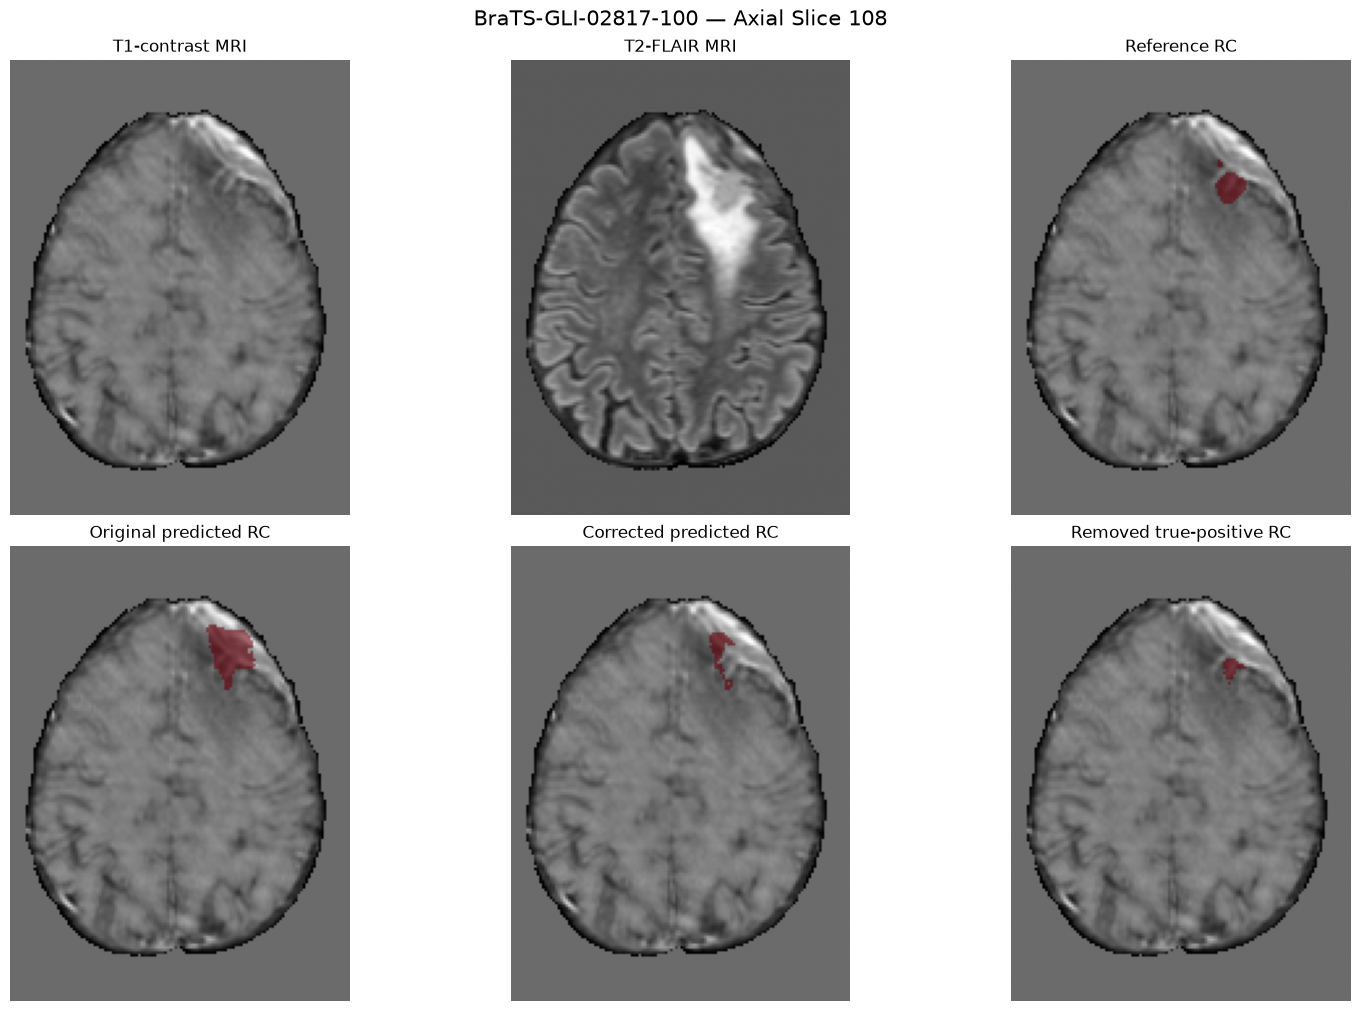

In [54]:
# -------------------------------------------------------------
# CELL 160 — VISUALISE RC VOXELS LOST AFTER ET–RC EXCLUSION
# -------------------------------------------------------------
#
# Identify the axial slice with the greatest number of
# correctly predicted cavity voxels removed by post-processing.
#
# Compare:
#   1. T1c MRI
#   2. T2-FLAIR MRI
#   3. Reference RC
#   4. Original predicted RC
#   5. Corrected predicted RC
#   6. Removed true-positive RC voxels
#
# No GPU inference, training or file modifications.
# -------------------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt

# STEP 1 — Find the axial slice containing the greatest
# number of removed true-positive RC voxels.

removed_voxels_per_slice = (
    failure_removed_true_positive_rc.sum(axis=(0, 1))
)

failure_slice_index = int(
    np.argmax(removed_voxels_per_slice)
)

print("Examination:", failure_case_id)
print("Selected axial slice:", failure_slice_index)
print(
    "Removed true-positive RC voxels on this slice:",
    int(removed_voxels_per_slice[failure_slice_index])
)

# STEP 2 — Extract MRI slices and segmentation masks.

t1c_slice = failure_image[1, :, :, failure_slice_index].numpy()
flair_slice = failure_image[3, :, :, failure_slice_index].numpy()

reference_slice = failure_reference_rc[:, :, failure_slice_index]
original_slice = failure_original_rc[:, :, failure_slice_index]
corrected_slice = failure_corrected_rc[:, :, failure_slice_index]

removed_tp_slice = (
    failure_removed_true_positive_rc[:, :, failure_slice_index]
)

# STEP 3 — Define the panels.

panels = [
    ("T1-contrast MRI", t1c_slice, None),
    ("T2-FLAIR MRI", flair_slice, None),
    ("Reference RC", t1c_slice, reference_slice),
    ("Original predicted RC", t1c_slice, original_slice),
    ("Corrected predicted RC", t1c_slice, corrected_slice),
    ("Removed true-positive RC", t1c_slice, removed_tp_slice),
]

# STEP 4 — Display the comparison.
#
# Use the same orientation for all panels.
# Segmentation masks are shown in red.

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 10),
    constrained_layout=True,
)

for ax, (title, image_slice, mask_slice) in zip(
    axes.flat, panels
):

    ax.imshow(
        image_slice.T,
        cmap="gray",
        origin="lower",
    )

    if mask_slice is not None:

        overlay = np.ma.masked_where(
            ~mask_slice.T,
            mask_slice.T,
        )

        ax.imshow(
            overlay,
            cmap="Reds",
            alpha=0.6,
            origin="lower",
            vmin=0,
            vmax=1,
        )

    ax.set_title(title)
    ax.axis("off")

fig.suptitle(
    f"{failure_case_id} — Axial Slice {failure_slice_index}",
    fontsize=15,
)

plt.show()

EXAMINATION: BraTS-GLI-02817-100
-----------------------------------------------------------------
Reference RC voxels: 1046
Reference RC voxels also predicted as ET: 213
Percentage of reference RC predicted as ET: 20.36 %
Reference RC voxels correctly predicted as RC and simultaneously predicted as ET: 193


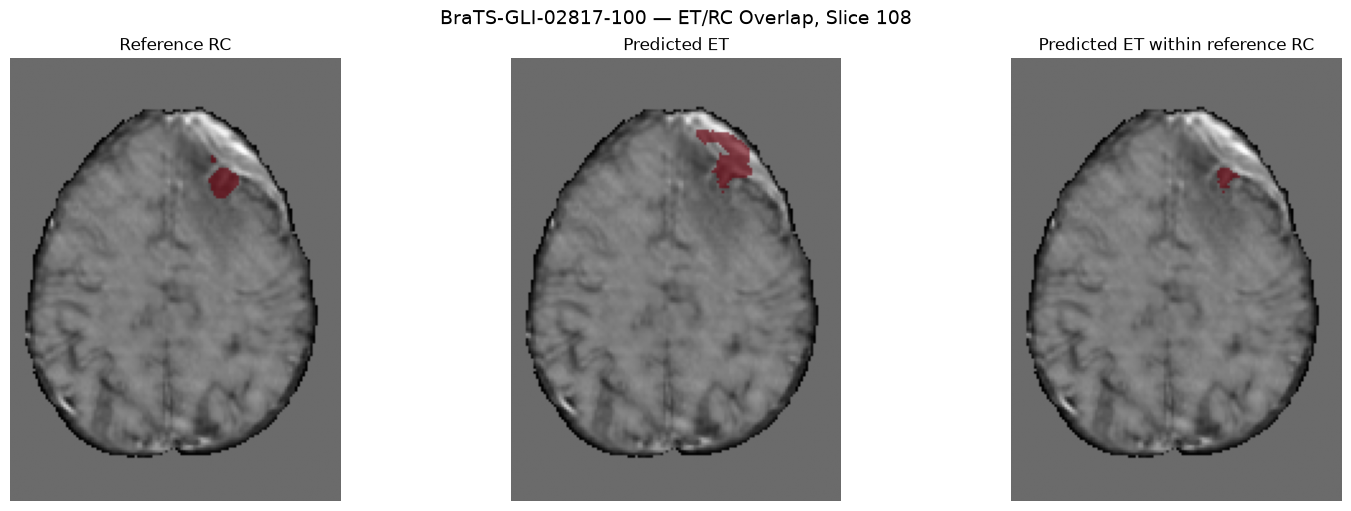

In [55]:
# -------------------------------------------------------------
# CELL 161 — INVESTIGATE ET PREDICTIONS INSIDE THE TRUE CAVITY
# -------------------------------------------------------------
#
# Determine how much of the annotated resection cavity
# is simultaneously classified as enhancing tumour (ET).
#
# Visualise:
#   1. Reference RC
#   2. Predicted ET
#   3. Predicted ET overlapping reference RC
#
# This investigates why ET–RC exclusion removes genuine
# cavity voxels.
# -------------------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt

# STEP 1 — Quantify predicted ET within the reference cavity.

et_inside_reference_rc = (
    failure_predicted_et & failure_reference_rc
)

et_inside_reference_rc_voxels = int(
    et_inside_reference_rc.sum()
)

reference_rc_voxels = int(
    failure_reference_rc.sum()
)

print("EXAMINATION:", failure_case_id)
print("-" * 65)

print(
    "Reference RC voxels:",
    reference_rc_voxels
)

print(
    "Reference RC voxels also predicted as ET:",
    et_inside_reference_rc_voxels
)

print(
    "Percentage of reference RC predicted as ET:",
    round(
        100 * et_inside_reference_rc_voxels
        / reference_rc_voxels,
        2,
    ),
    "%",
)

print(
    "Reference RC voxels correctly predicted as RC "
    "and simultaneously predicted as ET:",
    int(failure_removed_true_positive_rc.sum())
)

# STEP 2 — Display the same axial slice used in Cell 160.

z = failure_slice_index

t1c = failure_image[1, :, :, z].numpy()

masks = [
    ("Reference RC", failure_reference_rc[:, :, z]),
    ("Predicted ET", failure_predicted_et[:, :, z]),
    (
        "Predicted ET within reference RC",
        et_inside_reference_rc[:, :, z],
    ),
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    constrained_layout=True,
)

for ax, (title, mask) in zip(axes, masks):

    ax.imshow(
        t1c.T,
        cmap="gray",
        origin="lower",
    )

    overlay = np.ma.masked_where(
        ~mask.T,
        mask.T,
    )

    ax.imshow(
        overlay,
        cmap="Reds",
        alpha=0.65,
        origin="lower",
        vmin=0,
        vmax=1,
    )

    ax.set_title(title)
    ax.axis("off")

fig.suptitle(
    f"{failure_case_id} — ET/RC Overlap, Slice {z}",
    fontsize=14,
)

plt.show()

In [56]:
# -------------------------------------------------------------
# CELL 162 — ET AND RC CONFIDENCE WITHIN THE REFERENCE CAVITY
# -------------------------------------------------------------
#
# Examine the model's sigmoid probabilities for ET and RC
# inside the annotated resection cavity.
#
# This helps determine whether overlapping ET–RC predictions
# arise from marginal probabilities or confident predictions.
#
# No training or file modifications.
# -------------------------------------------------------------

import numpy as np
import torch

from monai.inferers import sliding_window_inference

# STEP 1 — Re-run inference to obtain probabilities rather
# than only binary predictions.

with torch.inference_mode():

    confidence_logits = sliding_window_inference(
        inputs=failure_image.unsqueeze(0).to(large_device),
        roi_size=(96, 96, 96),
        sw_batch_size=1,
        predictor=evaluation_model,
        overlap=0.25,
    )

    confidence_probabilities = (
        torch.sigmoid(confidence_logits)[0]
        .cpu()
        .numpy()
    )

# STEP 2 — Extract ET and RC probability maps.

et_probabilities = confidence_probabilities[2]
rc_probabilities = confidence_probabilities[3]

# STEP 3 — Focus on voxels belonging to the reference cavity.

reference_cavity_mask = failure_reference_rc

et_within_cavity = et_probabilities[
    reference_cavity_mask
]

rc_within_cavity = rc_probabilities[
    reference_cavity_mask
]

# STEP 4 — Quantify confidence levels.

print("EXAMINATION:", failure_case_id)
print("-" * 65)

print("Reference RC voxels:", reference_cavity_mask.sum())

print("\nET PROBABILITIES WITHIN REFERENCE RC")
print("Mean:", round(float(et_within_cavity.mean()), 4))
print("Median:", round(float(np.median(et_within_cavity)), 4))
print("Maximum:", round(float(et_within_cavity.max()), 4))

print("\nRC PROBABILITIES WITHIN REFERENCE RC")
print("Mean:", round(float(rc_within_cavity.mean()), 4))
print("Median:", round(float(np.median(rc_within_cavity)), 4))
print("Maximum:", round(float(rc_within_cavity.max()), 4))

# STEP 5 — Measure simultaneous high-confidence predictions.

for threshold in [0.5, 0.7, 0.9]:

    both_high_confidence = (
        reference_cavity_mask
        & (et_probabilities >= threshold)
        & (rc_probabilities >= threshold)
    )

    print(
        f"\nReference RC voxels with both ET and RC "
        f"probabilities >= {threshold}:",
        int(both_high_confidence.sum()),
    )

# STEP 6 — Compare ET and RC confidence at voxels that
# were correctly predicted as RC but removed by exclusion.

removed_tp_mask = failure_removed_true_positive_rc

print("\nREMOVED TRUE-POSITIVE RC VOXELS")
print("-" * 65)

print("Number removed:", int(removed_tp_mask.sum()))

print(
    "Mean ET probability:",
    round(float(et_probabilities[removed_tp_mask].mean()), 4)
)

print(
    "Mean RC probability:",
    round(float(rc_probabilities[removed_tp_mask].mean()), 4)
)

print(
    "Voxels where ET probability exceeds RC probability:",
    int(
        np.sum(
            et_probabilities[removed_tp_mask]
            >
            rc_probabilities[removed_tp_mask]
        )
    )
)

EXAMINATION: BraTS-GLI-02817-100
-----------------------------------------------------------------
Reference RC voxels: 1046

ET PROBABILITIES WITHIN REFERENCE RC
Mean: 0.2134
Median: 0.0078
Maximum: 0.9993

RC PROBABILITIES WITHIN REFERENCE RC
Mean: 0.5136
Median: 0.5466
Maximum: 0.9995

Reference RC voxels with both ET and RC probabilities >= 0.5: 193

Reference RC voxels with both ET and RC probabilities >= 0.7: 150

Reference RC voxels with both ET and RC probabilities >= 0.9: 80

REMOVED TRUE-POSITIVE RC VOXELS
-----------------------------------------------------------------
Number removed: 193
Mean ET probability: 0.8862
Mean RC probability: 0.8591
Voxels where ET probability exceeds RC probability: 128


In [57]:
# -------------------------------------------------------------
# CELL 163 — COMPARE RC POST-PROCESSING DECISION RULES
# -------------------------------------------------------------
#
# Compare three strategies on BraTS-GLI-02817-100:
#
# 1. Original prediction
# 2. ET-priority exclusion
# 3. Relative-confidence priority
#
# For relative-confidence priority, a predicted RC voxel
# is retained when:
#   - ET is not predicted, OR
#   - RC probability >= ET probability.
#
# This is an exploratory validation experiment.
# -------------------------------------------------------------

import numpy as np
import pandas as pd

# STEP 1 — Construct the three predicted RC masks.

rc_methods = {
    "Original": failure_original_rc,

    "ET-priority": failure_corrected_rc,

    "Relative-confidence": (
        failure_original_rc
        & (
            ~failure_predicted_et
            | (rc_probabilities >= et_probabilities)
        )
    ),
}

# STEP 2 — Calculate segmentation metrics for each method.

comparison_rows = []

for method_name, predicted_mask in rc_methods.items():

    reference_mask = failure_reference_rc

    true_positive = int(
        np.sum(predicted_mask & reference_mask)
    )

    false_positive = int(
        np.sum(predicted_mask & ~reference_mask)
    )

    false_negative = int(
        np.sum(~predicted_mask & reference_mask)
    )

    dice_denominator = (
        2 * true_positive + false_positive + false_negative
    )

    precision_denominator = (
        true_positive + false_positive
    )

    recall_denominator = (
        true_positive + false_negative
    )

    dice = (
        2 * true_positive / dice_denominator
        if dice_denominator else 1.0
    )

    precision = (
        true_positive / precision_denominator
        if precision_denominator else 0.0
    )

    recall = (
        true_positive / recall_denominator
        if recall_denominator else 0.0
    )

    comparison_rows.append({
        "method": method_name,
        "predicted_rc_voxels": int(predicted_mask.sum()),
        "true_positive": true_positive,
        "false_positive": false_positive,
        "false_negative": false_negative,
        "dice": dice,
        "precision": precision,
        "recall": recall,
    })

# STEP 3 — Display the results.

confidence_rule_comparison = pd.DataFrame(
    comparison_rows
)

print("EXAMINATION:", failure_case_id)
print("-" * 75)

print(
    confidence_rule_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# STEP 4 — Quantify how many correctly identified cavity
# voxels the confidence rule restores relative to ET-priority.

confidence_mask = rc_methods["Relative-confidence"]

restored_true_positive = int(
    np.sum(
        confidence_mask
        & ~failure_corrected_rc
        & failure_reference_rc
    )
)

restored_false_positive = int(
    np.sum(
        confidence_mask
        & ~failure_corrected_rc
        & ~failure_reference_rc
    )
)

print("\nRELATIVE-CONFIDENCE RULE VS ET-PRIORITY")
print("-" * 75)

print(
    "True-positive RC voxels restored:",
    restored_true_positive
)

print(
    "False-positive RC voxels restored:",
    restored_false_positive
)

EXAMINATION: BraTS-GLI-02817-100
---------------------------------------------------------------------------
             method  predicted_rc_voxels  true_positive  false_positive  false_negative   dice  precision  recall
           Original                16462            554           15908             492 0.0633     0.0337  0.5296
        ET-priority                13974            361           13613             685 0.0481     0.0258  0.3451
Relative-confidence                14375            426           13949             620 0.0552     0.0296  0.4073

RELATIVE-CONFIDENCE RULE VS ET-PRIORITY
---------------------------------------------------------------------------
True-positive RC voxels restored: 65
False-positive RC voxels restored: 336


In [58]:
# -------------------------------------------------------------
# CELL 164 — COMPARE THREE RC POST-PROCESSING METHODS
#            ACROSS ALL 24 VALIDATION EXAMINATIONS
# -------------------------------------------------------------
#
# Compare:
#   1. Original RC prediction
#   2. ET-priority exclusion
#   3. Relative-confidence priority
#
# RC-present cases:
#   Dice, precision, recall
#
# RC-absent cases:
#   False-positive RC voxels
#
# Uses the saved epoch-38 model without retraining.
# Does not modify any files.
# -------------------------------------------------------------

import numpy as np
import pandas as pd
import torch

from monai.inferers import sliding_window_inference

# STEP 1 — Evaluate each validation examination.

method_results = []

evaluation_model.eval()

for case_number, case in enumerate(
    selected_validation_cases,
    start=1,
):

    # Apply deterministic preprocessing.
    processed = large_validation_transforms(case)

    image = processed["image"].unsqueeze(0).to(large_device)

    reference_rc = (
        processed["label"][3]
        .cpu()
        .numpy()
        .astype(bool)
    )

    # Obtain ET and RC probabilities.
    with torch.inference_mode():

        logits = sliding_window_inference(
            inputs=image,
            roi_size=(96, 96, 96),
            sw_batch_size=1,
            predictor=evaluation_model,
            overlap=0.25,
        )

        probabilities = (
            torch.sigmoid(logits)[0]
            .cpu()
            .numpy()
        )

    et_probability = probabilities[2]
    rc_probability = probabilities[3]

    predicted_et = et_probability >= 0.5
    predicted_rc = rc_probability >= 0.5

    # Construct three alternative RC masks.
    methods = {
        "Original": predicted_rc,

        "ET-priority": (
            predicted_rc & ~predicted_et
        ),

        "Relative-confidence": (
            predicted_rc
            & (
                ~predicted_et
                | (rc_probability >= et_probability)
            )
        ),
    }

    # Calculate metrics for each method.
    for method_name, prediction in methods.items():

        tp = int(np.sum(prediction & reference_rc))
        fp = int(np.sum(prediction & ~reference_rc))
        fn = int(np.sum(~prediction & reference_rc))

        reference_present = bool(reference_rc.any())

        if reference_present:

            dice = 2 * tp / (2 * tp + fp + fn)

            precision = (
                tp / (tp + fp)
                if (tp + fp) else 0.0
            )

            recall = tp / (tp + fn)

        else:
            # Avoid assigning a misleading Dice score
            # when the reference cavity is absent.
            dice = np.nan
            precision = np.nan
            recall = np.nan

        method_results.append({
            "case_id": case["case_id"],
            "method": method_name,
            "reference_rc_present": reference_present,
            "reference_rc_voxels": int(reference_rc.sum()),
            "predicted_rc_voxels": int(prediction.sum()),
            "true_positive": tp,
            "false_positive": fp,
            "false_negative": fn,
            "dice": dice,
            "precision": precision,
            "recall": recall,
        })

    print(
        f"Evaluated {case_number}/"
        f"{len(selected_validation_cases)}: "
        f"{case['case_id']}"
    )

# STEP 2 — Create the case-level results table.

all_method_results = pd.DataFrame(method_results)

# STEP 3 — Summarise RC-present examinations.

present_results = all_method_results[
    all_method_results["reference_rc_present"]
]

present_summary = (
    present_results
    .groupby("method")[
        ["dice", "precision", "recall"]
    ]
    .mean()
    .round(4)
)

# STEP 4 — Summarise RC-absent examinations.

absent_results = all_method_results[
    ~all_method_results["reference_rc_present"]
]

absent_summary = (
    absent_results
    .groupby("method")
    .agg(
        total_false_positive_voxels=(
            "false_positive", "sum"
        ),
        cases_with_false_positives=(
            "false_positive",
            lambda values: int((values > 0).sum())
        ),
    )
)

# STEP 5 — Display both summaries.

print("\n" + "=" * 70)
print("RC-PRESENT EXAMINATIONS — MEAN METRICS")
print("=" * 70)

print(present_summary.to_string())

print("\n" + "=" * 70)
print("RC-ABSENT EXAMINATIONS — FALSE POSITIVES")
print("=" * 70)

print(absent_summary.to_string())

print("\nTotal examinations evaluated:", len(selected_validation_cases))
print("Total method results:", len(all_method_results))

Evaluated 1/24: BraTS-GLI-02736-101
Evaluated 2/24: BraTS-GLI-02105-104
Evaluated 3/24: BraTS-GLI-02382-100
Evaluated 4/24: BraTS-GLI-00469-100
Evaluated 5/24: BraTS-GLI-02796-101
Evaluated 6/24: BraTS-GLI-02726-100
Evaluated 7/24: BraTS-GLI-02116-101
Evaluated 8/24: BraTS-GLI-02217-103
Evaluated 9/24: BraTS-GLI-02375-101
Evaluated 10/24: BraTS-GLI-02260-100
Evaluated 11/24: BraTS-GLI-02553-101
Evaluated 12/24: BraTS-GLI-02609-101
Evaluated 13/24: BraTS-GLI-02817-100
Evaluated 14/24: BraTS-GLI-02158-101
Evaluated 15/24: BraTS-GLI-02752-101
Evaluated 16/24: BraTS-GLI-02813-101
Evaluated 17/24: BraTS-GLI-02394-100
Evaluated 18/24: BraTS-GLI-02863-100
Evaluated 19/24: BraTS-GLI-02828-100
Evaluated 20/24: BraTS-GLI-02632-104
Evaluated 21/24: BraTS-GLI-02634-101
Evaluated 22/24: BraTS-GLI-03019-100
Evaluated 23/24: BraTS-GLI-02905-100
Evaluated 24/24: BraTS-GLI-02880-100

RC-PRESENT EXAMINATIONS — MEAN METRICS
                       dice  precision  recall
method                            

In [59]:
# -------------------------------------------------------------
# CELL 165 — PAIRED CASE-LEVEL POST-PROCESSING COMPARISON
# -------------------------------------------------------------
#
# Compare relative-confidence priority against ET-priority
# for the same 24 validation examinations.
#
# RC-present examinations:
#   - Change in Dice, precision and recall
#   - True-positive and false-positive voxels restored
#
# RC-absent examinations:
#   - Additional false-positive RC voxels retained
#
# No inference, training or file modifications.
# -------------------------------------------------------------

import numpy as np
import pandas as pd

# STEP 1 — Arrange the existing case-level results so
# each examination has one row per metric and method.

paired = all_method_results.pivot(
    index=["case_id", "reference_rc_present"],
    columns="method",
    values=[
        "dice",
        "precision",
        "recall",
        "true_positive",
        "false_positive",
    ],
)

# STEP 2 — Calculate paired changes:
# relative-confidence minus ET-priority.

paired_changes = pd.DataFrame(index=paired.index)

for metric in ["dice", "precision", "recall"]:

    paired_changes[f"delta_{metric}"] = (
        paired[(metric, "Relative-confidence")]
        - paired[(metric, "ET-priority")]
    )

paired_changes["tp_restored"] = (
    paired[("true_positive", "Relative-confidence")]
    - paired[("true_positive", "ET-priority")]
)

paired_changes["fp_restored"] = (
    paired[("false_positive", "Relative-confidence")]
    - paired[("false_positive", "ET-priority")]
)

paired_changes = paired_changes.reset_index()

# STEP 3 — Separate RC-present and RC-absent examinations.

paired_present = paired_changes[
    paired_changes["reference_rc_present"]
].copy()

paired_absent = paired_changes[
    ~paired_changes["reference_rc_present"]
].copy()

# STEP 4 — Count improvements and deteriorations.

print("RC-PRESENT CASES — RELATIVE-CONFIDENCE VS ET-PRIORITY")
print("=" * 75)

for metric in ["dice", "precision", "recall"]:

    differences = paired_present[f"delta_{metric}"]

    print(
        f"{metric.upper():10s} "
        f"Improved: {(differences > 1e-10).sum():2d} | "
        f"Worsened: {(differences < -1e-10).sum():2d} | "
        f"Unchanged: {(differences.abs() <= 1e-10).sum():2d}"
    )

print("\nTotal true-positive voxels restored:",
      int(paired_present["tp_restored"].sum()))

print("Total false-positive voxels restored:",
      int(paired_present["fp_restored"].sum()))

# STEP 5 — Display all RC-present case-level changes.

print("\nRC-PRESENT CASE-LEVEL CHANGES")
print("-" * 75)

print(
    paired_present[
        [
            "case_id",
            "delta_dice",
            "delta_precision",
            "delta_recall",
            "tp_restored",
            "fp_restored",
        ]
    ]
    .sort_values("delta_dice", ascending=False)
    .to_string(
        index=False,
        float_format=lambda x: f"{x:+.4f}"
    )
)

# STEP 6 — Show additional false positives in RC-absent cases.

print("\nRC-ABSENT CASES — ADDITIONAL FALSE POSITIVES")
print("-" * 75)

print(
    paired_absent[
        ["case_id", "fp_restored"]
    ]
    .sort_values("fp_restored", ascending=False)
    .to_string(index=False)
)

RC-PRESENT CASES — RELATIVE-CONFIDENCE VS ET-PRIORITY
DICE       Improved:  8 | Worsened:  8 | Unchanged:  3
PRECISION  Improved:  4 | Worsened: 12 | Unchanged:  3
RECALL     Improved: 14 | Worsened:  0 | Unchanged:  5

Total true-positive voxels restored: 978
Total false-positive voxels restored: 3397

RC-PRESENT CASE-LEVEL CHANGES
---------------------------------------------------------------------------
            case_id  delta_dice  delta_precision  delta_recall  tp_restored  fp_restored
BraTS-GLI-02382-100     +0.0094          -0.0200       +0.0325    +160.0000    +299.0000
BraTS-GLI-02817-100     +0.0072          +0.0038       +0.0621     +65.0000    +336.0000
BraTS-GLI-02260-100     +0.0060          +0.0087       +0.0039     +34.0000     +13.0000
BraTS-GLI-02634-101     +0.0026          +0.0010       +0.0438    +101.0000    +813.0000
BraTS-GLI-02726-100     +0.0013          -0.0003       +0.0030     +33.0000     +30.0000
BraTS-GLI-02553-101     +0.0004          -0.0065       

### Conclusion from experimentation
- ET-priority substantially reduces false positives but sacrifices some genuine cavity tissue.
- Relative-confidence priority recovers some genuine tissue but also reintroduces false positives.
- Neither approach resolves normal CSF-space misclassification.
- Neither consistently improves individual-examination Dice.

In [60]:
# -------------------------------------------------------------
# CELL 166 — COMPARE POST-PROCESSING AGAINST ORIGINAL MODEL
# -------------------------------------------------------------
#
# Compare ET-priority and relative-confidence priority
# against the original RC prediction for each of the
# 19 RC-present validation examinations.
#
# Identify:
#   - How often each correction improves Dice
#   - How often each correction worsens Dice
#   - Mean and median Dice change
#   - Cases with substantial deterioration
#
# No inference, training or file modifications.
# -------------------------------------------------------------

import numpy as np
import pandas as pd

# STEP 1 — Keep examinations with an annotated cavity.

rc_present_results = all_method_results[
    all_method_results["reference_rc_present"]
].copy()

# STEP 2 — Arrange Dice scores by examination and method.

dice_comparison = rc_present_results.pivot(
    index="case_id",
    columns="method",
    values="dice",
)

# STEP 3 — Calculate changes relative to the original model.

dice_comparison["ET-priority change"] = (
    dice_comparison["ET-priority"]
    - dice_comparison["Original"]
)

dice_comparison["Relative-confidence change"] = (
    dice_comparison["Relative-confidence"]
    - dice_comparison["Original"]
)

# STEP 4 — Summarise the paired changes.

print("POST-PROCESSING VS ORIGINAL MODEL")
print("=" * 75)

for method in ["ET-priority", "Relative-confidence"]:

    changes = dice_comparison[f"{method} change"]

    print(f"\n{method}")
    print("-" * 50)

    print("Improved:", int((changes > 1e-10).sum()))
    print("Worsened:", int((changes < -1e-10).sum()))
    print("Unchanged:", int((changes.abs() <= 1e-10).sum()))

    print("Mean Dice change:", round(float(changes.mean()), 4))
    print("Median Dice change:", round(float(changes.median()), 4))

    print(
        "Largest improvement:",
        round(float(changes.max()), 4)
    )

    print(
        "Largest deterioration:",
        round(float(changes.min()), 4)
    )

# STEP 5 — Display examination-level results.

print("\nCASE-LEVEL DICE COMPARISON")
print("=" * 75)

print(
    dice_comparison[
        [
            "Original",
            "ET-priority",
            "Relative-confidence",
            "ET-priority change",
            "Relative-confidence change",
        ]
    ]
    .sort_values(
        "Relative-confidence change",
        ascending=False,
    )
    .to_string(
        float_format=lambda x: f"{x:.4f}"
    )
)

POST-PROCESSING VS ORIGINAL MODEL

ET-priority
--------------------------------------------------
Improved: 13
Worsened: 4
Unchanged: 2
Mean Dice change: 0.0343
Median Dice change: 0.0052
Largest improvement: 0.2654
Largest deterioration: -0.0152

Relative-confidence
--------------------------------------------------
Improved: 15
Worsened: 2
Unchanged: 2
Mean Dice change: 0.0349
Median Dice change: 0.0047
Largest improvement: 0.2748
Largest deterioration: -0.0146

CASE-LEVEL DICE COMPARISON
method               Original  ET-priority  Relative-confidence  ET-priority change  Relative-confidence change
case_id                                                                                                        
BraTS-GLI-02382-100    0.2360       0.5014               0.5108              0.2654                      0.2748
BraTS-GLI-02394-100    0.6632       0.7741               0.7624              0.1109                      0.0992
BraTS-GLI-02375-101    0.3490       0.4452              

In [62]:
# -------------------------------------------------------------
# CELL 167 — TRAINING RESECTION-CAVITY DISTRIBUTION
# -------------------------------------------------------------
#
# Examine the 180 training examinations used in the baseline
# 3D U-Net experiment.
#
# Questions:
#   1. How many examinations contain resection cavities?
#   2. How large are the annotated cavities?
#   3. Are small cavities underrepresented?
#   4. Do subjects contribute multiple training examinations?
#
# No GPU usage, model training, or file modifications.
# -------------------------------------------------------------

import numpy as np
import pandas as pd
import nibabel as nib

# STEP 1 — Locate the exact training subset used by the
# completed baseline experiment.
#
# Do not substitute the full 936-case training cohort.

if "selected_training_cases" in globals():
    training_cases_for_analysis = selected_training_cases

elif "large_training_cases" in globals():
    training_cases_for_analysis = large_training_cases

else:
    raise NameError(
        "The baseline training-case list was not found. "
        "Please share this message so we can identify "
        "the correct variable without changing the cohort."
    )

assert len(training_cases_for_analysis) == 180, (
    "Expected 180 baseline training examinations, "
    f"found {len(training_cases_for_analysis)}. "
    "Stop rather than analyse a different cohort."
)

# STEP 2 — Read only segmentation labels.
#
# BraTS label 4 represents the resection cavity.
# The four MRI modalities are not needed for this analysis.

training_rc_records = []

for case in training_cases_for_analysis:

    label_image = nib.load(str(case["label"]))

    label_array = np.asarray(
        label_image.dataobj
    )

    rc_voxels = int(
        np.count_nonzero(label_array == 4)
    )

    voxel_volume_mm3 = float(
        np.prod(label_image.header.get_zooms()[:3])
    )

    training_rc_records.append({
        "case_id": case["case_id"],
        "subject_id": case["subject_id"],
        "rc_present": rc_voxels > 0,
        "rc_voxels": rc_voxels,
        "rc_volume_ml": (
            rc_voxels * voxel_volume_mm3 / 1000
        ),
    })

# STEP 3 — Create the analysis table.

training_rc_distribution = pd.DataFrame(
    training_rc_records
)

rc_present_training = training_rc_distribution[
    training_rc_distribution["rc_present"]
].copy()

# STEP 4 — Summarise cavity prevalence.

print("BASELINE TRAINING SUBSET")
print("=" * 65)

print("Total examinations:", len(training_rc_distribution))

print(
    "Unique subjects:",
    training_rc_distribution["subject_id"].nunique()
)

print(
    "Examinations with RC:",
    len(rc_present_training)
)

print(
    "Examinations without RC:",
    int((~training_rc_distribution["rc_present"]).sum())
)

print(
    "RC prevalence:",
    f"{100 * training_rc_distribution['rc_present'].mean():.1f}%"
)

# STEP 5 — Summarise reference cavity sizes.

print("\nREFERENCE CAVITY SIZE — RC-PRESENT EXAMINATIONS")
print("=" * 65)

if not rc_present_training.empty:

    print(
        rc_present_training[
            ["rc_voxels", "rc_volume_ml"]
        ]
        .describe(
            percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
        )
        .round(2)
        .to_string()
    )

    print("\nSMALLEST TEN ANNOTATED CAVITIES")
    print("-" * 65)

    print(
        rc_present_training[
            ["case_id", "rc_voxels", "rc_volume_ml"]
        ]
        .nsmallest(10, "rc_voxels")
        .to_string(index=False)
    )

else:
    print("No annotated cavities found.")

# STEP 6 — Check repeated examinations per subject.

subject_exam_counts = (
    training_rc_distribution
    .groupby("subject_id")
    .size()
)

print("\nSUBJECT-LEVEL EXAMINATION COUNTS")
print("=" * 65)

print(
    "Subjects with multiple examinations:",
    int((subject_exam_counts > 1).sum())
)

print(
    "Maximum examinations from one subject:",
    int(subject_exam_counts.max())
)

BASELINE TRAINING SUBSET
Total examinations: 180
Unique subjects: 180
Examinations with RC: 151
Examinations without RC: 29
RC prevalence: 83.9%

REFERENCE CAVITY SIZE — RC-PRESENT EXAMINATIONS
       rc_voxels  rc_volume_ml
count      151.0        151.00
mean     16267.6         16.27
std      24197.9         24.20
min          8.0          0.01
10%        369.0          0.37
25%       2290.5          2.29
50%       7929.0          7.93
75%      21817.0         21.82
90%      37341.0         37.34
max     165848.0        165.85

SMALLEST TEN ANNOTATED CAVITIES
-----------------------------------------------------------------
            case_id  rc_voxels  rc_volume_ml
BraTS-GLI-02520-101          8         0.008
BraTS-GLI-02386-100         86         0.086
BraTS-GLI-02802-100         90         0.090
BraTS-GLI-03030-101         95         0.095
BraTS-GLI-02973-100        127         0.127
BraTS-GLI-02708-100        191         0.191
BraTS-GLI-02099-100        197         0.197
BraTS-

In [63]:
# -------------------------------------------------------------
# CELL 168 — AUDIT RESECTION-CAVITY EXPOSURE IN TRAINING PATCHES
# -------------------------------------------------------------
#
# Sample the existing training transform on:
#   - 5 examinations with the smallest annotated cavities
#   - 5 examinations near the median cavity size
#   - 5 examinations without annotated cavities
#
# Measure whether the resulting training patches contain RC.
#
# No GPU inference, training, or file modifications.
# -------------------------------------------------------------

import numpy as np
import pandas as pd

# STEP 1 — Identify the existing training transformation.
# Use the same transform configuration as baseline training.

training_transform_for_audit = (
    preprocessing.create_training_transforms()
)

# STEP 2 — Select representative examinations.

small_cases = (
    training_rc_distribution[
        training_rc_distribution["rc_present"]
    ]
    .nsmallest(5, "rc_voxels")
    .assign(group="Small RC")
)

median_volume = (
    training_rc_distribution.loc[
        training_rc_distribution["rc_present"],
        "rc_voxels"
    ].median()
)

median_cases = (
    training_rc_distribution[
        training_rc_distribution["rc_present"]
    ]
    .assign(
        distance_from_median=lambda df:
        (df["rc_voxels"] - median_volume).abs()
    )
    .nsmallest(5, "distance_from_median")
    .assign(group="Median RC")
)

absent_cases = (
    training_rc_distribution[
        ~training_rc_distribution["rc_present"]
    ]
    .sort_values("case_id")
    .head(5)
    .assign(group="RC absent")
)

audit_cases = pd.concat(
    [small_cases, median_cases, absent_cases],
    ignore_index=True,
)

# STEP 3 — Sample the training transform twice per case.
#
# Each application is configured to return two patches,
# giving four patches per examination.

audit_records = []

for _, audit_case in audit_cases.iterrows():

    case = next(
        item
        for item in training_cases_for_analysis
        if item["case_id"] == audit_case["case_id"]
    )

    for repetition in range(2):

        transformed = training_transform_for_audit(case)

        patches = (
            transformed
            if isinstance(transformed, list)
            else [transformed]
        )

        for patch_number, patch in enumerate(patches):

            label = patch["label"]

            # Channel 3 corresponds to the RC binary mask.
            rc_voxels_in_patch = int(
                (label[3] > 0).sum().item()
            )

            audit_records.append({
                "case_id": audit_case["case_id"],
                "group": audit_case["group"],
                "reference_rc_voxels": audit_case["rc_voxels"],
                "repetition": repetition + 1,
                "patch_number": patch_number + 1,
                "patch_contains_rc": rc_voxels_in_patch > 0,
                "rc_voxels_in_patch": rc_voxels_in_patch,
            })

# STEP 4 — Summarise the results.

patch_audit = pd.DataFrame(audit_records)

print("TRAINING PATCH AUDIT")
print("=" * 70)

print(
    patch_audit.groupby("group").agg(
        examinations=("case_id", "nunique"),
        patches=("patch_contains_rc", "size"),
        patches_with_rc=("patch_contains_rc", "sum"),
        percentage_with_rc=(
            "patch_contains_rc",
            lambda values: 100 * values.mean()
        ),
        median_rc_voxels_per_patch=(
            "rc_voxels_in_patch", "median"
        ),
    ).round(2).to_string()
)

print("\nCASE-LEVEL PATCH EXPOSURE")
print("=" * 70)

print(
    patch_audit.groupby(
        ["group", "case_id", "reference_rc_voxels"]
    ).agg(
        patches=("patch_contains_rc", "size"),
        patches_with_rc=("patch_contains_rc", "sum"),
        maximum_rc_voxels_in_patch=(
            "rc_voxels_in_patch", "max"
        ),
    ).to_string()
)

AttributeError: module 'src.preprocessing' has no attribute 'create_training_transforms'

In [64]:
# -------------------------------------------------------------
# CELL 168A — IDENTIFY BASELINE TRAINING TRANSFORM
# -------------------------------------------------------------
#
# Inspect available preprocessing functions and existing
# notebook variables to find the original training transform.
#
# No data loading, GPU usage, training, or file modifications.
# -------------------------------------------------------------

import inspect

# STEP 1 — List functions defined in src.preprocessing.

print("FUNCTIONS IN src.preprocessing")
print("=" * 65)

for name, function in inspect.getmembers(
    preprocessing,
    inspect.isfunction
):
    if function.__module__ == preprocessing.__name__:
        print(name)

# STEP 2 — Identify notebook variables related to training
# transforms, datasets and loaders.

print("\nPOTENTIALLY RELEVANT NOTEBOOK VARIABLES")
print("=" * 65)

keywords = (
    "transform",
    "training_dataset",
    "training_loader",
    "train_dataset",
    "train_loader",
)

for name, value in sorted(globals().items()):

    if name.startswith("_"):
        continue

    if any(keyword in name.lower() for keyword in keywords):
        print(f"{name}: {type(value).__name__}")

# STEP 3 — Check whether the original training dataset
# retains its transformation pipeline.

print("\nTRAINING DATASET TRANSFORMS")
print("=" * 65)

for variable_name in (
    "large_training_dataset",
    "large_train_dataset",
):

    dataset = globals().get(variable_name)

    if dataset is not None:

        print(f"\n{variable_name}")

        transform = getattr(dataset, "transform", None)

        print("Transform type:", type(transform).__name__)

        if transform is not None:
            print(transform)

FUNCTIONS IN src.preprocessing
create_validation_transforms
select_nonzero_foreground

POTENTIALLY RELEVANT NOTEBOOK VARIABLES
large_training_dataset: Dataset
large_training_loader: DataLoader
large_training_transforms: Compose
large_validation_transforms: Compose
transform: ConvertBraTSLabelsd

TRAINING DATASET TRANSFORMS

large_training_dataset
Transform type: Compose


In [65]:
# -------------------------------------------------------------
# CELL 168B — AUDIT ACTUAL TRAINING PATCH EXPOSURE
# -------------------------------------------------------------
#
# Use the original baseline training transformation:
# large_training_transforms
#
# Examine whether patches sampled from examinations with
# small, median-sized or absent cavities contain RC tissue.
#
# No model training, GPU inference or file modifications.
# -------------------------------------------------------------

import numpy as np
import pandas as pd

# STEP 1 — Reuse the original baseline training transform.

training_transform_for_audit = large_training_transforms

# STEP 2 — Select five examinations from each group.

small_cases = (
    training_rc_distribution[
        training_rc_distribution["rc_present"]
    ]
    .nsmallest(5, "rc_voxels")
    .assign(group="Small RC")
)

median_volume = (
    training_rc_distribution.loc[
        training_rc_distribution["rc_present"],
        "rc_voxels"
    ].median()
)

median_cases = (
    training_rc_distribution[
        training_rc_distribution["rc_present"]
    ]
    .assign(
        distance_from_median=lambda df:
        (df["rc_voxels"] - median_volume).abs()
    )
    .nsmallest(5, "distance_from_median")
    .assign(group="Median RC")
)

absent_cases = (
    training_rc_distribution[
        ~training_rc_distribution["rc_present"]
    ]
    .sort_values("case_id")
    .head(5)
    .assign(group="RC absent")
)

audit_cases = pd.concat(
    [small_cases, median_cases, absent_cases],
    ignore_index=True,
)

# STEP 3 — Create a lookup for the original case dictionaries.

training_case_lookup = {
    case["case_id"]: case
    for case in training_cases_for_analysis
}

# STEP 4 — Apply the original random training transform
# twice per examination.
#
# The baseline transform produces two patches per application.

audit_records = []

for _, audit_case in audit_cases.iterrows():

    case = training_case_lookup[audit_case["case_id"]]

    for repetition in range(2):

        transformed = training_transform_for_audit(case)

        patches = (
            transformed
            if isinstance(transformed, list)
            else [transformed]
        )

        for patch_number, patch in enumerate(patches):

            # BraTS converted-label channel order:
            # 0 = WT, 1 = TC, 2 = ET, 3 = RC.

            label = patch["label"]

            rc_voxels_in_patch = int(
                (label[3] > 0).sum().item()
            )

            audit_records.append({
                "case_id": audit_case["case_id"],
                "group": audit_case["group"],
                "reference_rc_voxels": int(
                    audit_case["rc_voxels"]
                ),
                "repetition": repetition + 1,
                "patch_number": patch_number + 1,
                "patch_contains_rc": rc_voxels_in_patch > 0,
                "rc_voxels_in_patch": rc_voxels_in_patch,
            })

# STEP 5 — Store results for subsequent analysis.

patch_audit = pd.DataFrame(audit_records)

# STEP 6 — Summarise exposure by group.

print("TRAINING PATCH AUDIT")
print("=" * 70)

print(
    patch_audit.groupby("group").agg(
        examinations=("case_id", "nunique"),
        patches=("patch_contains_rc", "size"),
        patches_with_rc=("patch_contains_rc", "sum"),
        percentage_with_rc=(
            "patch_contains_rc",
            lambda values: 100 * values.mean()
        ),
        median_rc_voxels_per_patch=(
            "rc_voxels_in_patch", "median"
        ),
    ).round(2).to_string()
)

# STEP 7 — Examine individual cases.

print("\nCASE-LEVEL PATCH EXPOSURE")
print("=" * 70)

print(
    patch_audit.groupby(
        ["group", "case_id", "reference_rc_voxels"]
    ).agg(
        patches=("patch_contains_rc", "size"),
        patches_with_rc=("patch_contains_rc", "sum"),
        maximum_rc_voxels_in_patch=(
            "rc_voxels_in_patch", "max"
        ),
    ).to_string()
)

TRAINING PATCH AUDIT
           examinations  patches  patches_with_rc  percentage_with_rc  median_rc_voxels_per_patch
group                                                                                            
Median RC             5       20               17                85.0                      7058.0
RC absent             5       20                0                 0.0                         0.0
Small RC              5       20               14                70.0                        51.5

CASE-LEVEL PATCH EXPOSURE
                                                   patches  patches_with_rc  maximum_rc_voxels_in_patch
group     case_id             reference_rc_voxels                                                      
Median RC BraTS-GLI-02197-100 7878                       4                4                        7878
          BraTS-GLI-02685-100 7975                       4                3                        7975
          BraTS-GLI-02737-100 7123            

In [66]:
# -------------------------------------------------------------
# CELL 169 — INSPECT BASELINE TRAINING TRANSFORM PIPELINE
# -------------------------------------------------------------
#
# Identify the exact transform order and parameters used
# during the original 40-epoch experiment.
#
# In particular, inspect:
#   - Label conversion
#   - Foreground cropping
#   - Positive/negative patch sampling
#   - Random spatial and intensity augmentations
#
# No data loading, GPU usage, training or file modifications.
# -------------------------------------------------------------

print("BASELINE TRAINING TRANSFORM PIPELINE")
print("=" * 75)

for index, transform in enumerate(
    large_training_transforms.transforms,
    start=1
):

    print(
        f"\n{index:02d}. {type(transform).__name__}"
    )

    # Print the transform configuration.
    # This includes the parameters needed to reproduce
    # the original patch-sampling strategy.

    print(transform)

    # Inspect sampling-specific parameters when available.

    if "Crop" in type(transform).__name__:

        print("  --- SAMPLING PARAMETERS ---")

        for attribute in (
            "spatial_size",
            "num_samples",
            "pos",
            "neg",
            "image_key",
            "image_threshold",
            "label_key",
            "fg_indices_key",
            "bg_indices_key",
            "allow_smaller",
        ):

            if hasattr(transform, attribute):

                print(
                    f"  {attribute}: "
                    f"{getattr(transform, attribute)}"
                )

BASELINE TRAINING TRANSFORM PIPELINE

01. LoadImaged

02. EnsureChannelFirstd

03. Orientationd

04. NormalizeIntensityd

05. CropForegroundd
  --- SAMPLING PARAMETERS ---

06. EnsureTyped

07. EnsureTyped

08. RandCropByPosNegLabeld
  --- SAMPLING PARAMETERS ---
  image_key: None
  label_key: label
  fg_indices_key: None
  bg_indices_key: None

09. RandFlipd

10. RandScaleIntensityd

11. ConvertBraTSLabelsd


In [67]:
# -------------------------------------------------------------
# CELL 170 — INSPECT ORIGINAL PATCH-SAMPLING PARAMETERS
# -------------------------------------------------------------
#
# Examine the baseline RandCropByPosNegLabeld transform,
# including parameters stored inside its random cropper.
#
# No MRI loading, GPU use, training or file modifications.
# -------------------------------------------------------------

# STEP 1 — Retrieve the original patch-sampling transform.

baseline_sampler = next(
    transform
    for transform in large_training_transforms.transforms
    if type(transform).__name__ == "RandCropByPosNegLabeld"
)

print("BASELINE SAMPLER")
print("=" * 70)
print(type(baseline_sampler).__name__)

# STEP 2 — Inspect the dictionary transform's parameters.

print("\nDICTIONARY TRANSFORM PARAMETERS")
print("=" * 70)

for attribute in (
    "keys",
    "label_key",
    "image_key",
    "image_threshold",
    "fg_indices_key",
    "bg_indices_key",
    "allow_smaller",
    "lazy",
):
    if hasattr(baseline_sampler, attribute):
        print(
            f"{attribute}: "
            f"{getattr(baseline_sampler, attribute)}"
        )

# STEP 3 — Inspect MONAI's internal random cropper.
#
# The spatial size, sample count and positive/negative
# sampling ratio may be stored here.

cropper = getattr(baseline_sampler, "cropper", None)

print("\nINTERNAL RANDOM CROPPER")
print("=" * 70)

if cropper is None:
    print("No nested cropper attribute found.")

else:
    print("Type:", type(cropper).__name__)

    for attribute in (
        "spatial_size",
        "roi_size",
        "num_samples",
        "pos",
        "neg",
        "pos_ratio",
        "ratios",
        "allow_smaller",
    ):
        if hasattr(cropper, attribute):
            print(
                f"{attribute}: "
                f"{getattr(cropper, attribute)}"
            )

# STEP 4 — Inspect the original label conversion.

print("\nLABEL CONVERSION")
print("=" * 70)

label_converter = (
    large_training_transforms.transforms[-1]
)

print("Type:", type(label_converter).__name__)
print("Input label key:", getattr(label_converter, "keys", "Not exposed"))

BASELINE SAMPLER
RandCropByPosNegLabeld

DICTIONARY TRANSFORM PARAMETERS
keys: ('image', 'label')
label_key: label
image_key: None
fg_indices_key: None
bg_indices_key: None
lazy: False

INTERNAL RANDOM CROPPER
Type: RandCropByPosNegLabel
spatial_size: (96, 96, 96)
num_samples: 2
pos_ratio: 0.5
allow_smaller: False

LABEL CONVERSION
Type: ConvertBraTSLabelsd
Input label key: ('label',)


In [68]:
# -------------------------------------------------------------
# CELL 171 — FOREGROUND COMPOSITION BY BRATS LABEL
# -------------------------------------------------------------
#
# Quantify the original BraTS label composition in the
# 15 examinations used for the patch-sampling audit.
#
# Original labels:
#   0 = background
#   1 = non-enhancing tumour core
#   2 = FLAIR hyperintensity
#   3 = enhancing tumour
#   4 = resection cavity
#
# The fraction of foreground occupied by label 4 provides
# an initial estimate of how rarely a randomly selected
# foreground voxel would be a cavity voxel.
#
# This is NOT a direct measurement of patch-level exposure.
# -------------------------------------------------------------

import numpy as np
import pandas as pd
import nibabel as nib

foreground_records = []

for _, audit_case in audit_cases.iterrows():

    case = training_case_lookup[audit_case["case_id"]]

    # Load only the segmentation label.
    label = np.asarray(
        nib.load(str(case["label"])).dataobj
    )

    # Count voxels belonging to each original BraTS class.
    counts = {
        region: int(np.count_nonzero(label == region))
        for region in (0, 1, 2, 3, 4)
    }

    foreground_voxels = sum(
        counts[region] for region in (1, 2, 3, 4)
    )

    cavity_fraction = (
        counts[4] / foreground_voxels
        if foreground_voxels > 0
        else np.nan
    )

    foreground_records.append({
        "case_id": audit_case["case_id"],
        "group": audit_case["group"],
        "foreground_voxels": foreground_voxels,
        "nonenhancing_voxels": counts[1],
        "flair_voxels": counts[2],
        "enhancing_voxels": counts[3],
        "cavity_voxels": counts[4],
        "cavity_fraction_percent": 100 * cavity_fraction,
    })

foreground_composition = pd.DataFrame(
    foreground_records
)

print("FOREGROUND COMPOSITION BY EXAMINATION")
print("=" * 80)

print(
    foreground_composition[
        [
            "group",
            "case_id",
            "foreground_voxels",
            "cavity_voxels",
            "cavity_fraction_percent",
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}",
    )
)

print("\nCAVITY FRACTION BY GROUP")
print("=" * 80)

print(
    foreground_composition.groupby("group")[
        "cavity_fraction_percent"
    ].agg(
        ["count", "mean", "median", "min", "max"]
    ).round(4).to_string()
)

FOREGROUND COMPOSITION BY EXAMINATION
    group             case_id  foreground_voxels  cavity_voxels  cavity_fraction_percent
 Small RC BraTS-GLI-02520-101             308293              8                   0.0026
 Small RC BraTS-GLI-02386-100              20337             86                   0.4229
 Small RC BraTS-GLI-02802-100              83834             90                   0.1074
 Small RC BraTS-GLI-03030-101              68921             95                   0.1378
 Small RC BraTS-GLI-02973-100              53488            127                   0.2374
Median RC BraTS-GLI-02985-100              27986           7929                  28.3320
Median RC BraTS-GLI-02685-100             106447           7975                   7.4920
Median RC BraTS-GLI-02197-100              51039           7878                  15.4353
Median RC BraTS-GLI-02747-100              27197           7530                  27.6869
Median RC BraTS-GLI-02737-100              87763           7123         

In [69]:
# -------------------------------------------------------------
# CELL 172 — INSPECT MONAI SAMPLING TRANSFORMS
# -------------------------------------------------------------
#
# Identify installed MONAI transforms that support:
#   - Class-aware sampling
#   - Label-based random crops
#   - Multiple samples per examination
#
# No MRI loading, GPU use, training or file modifications.
# -------------------------------------------------------------

import inspect
import monai.transforms as mt

candidate_transforms = (
    "RandCropByLabelClassesd",
    "RandCropByLabelClasses",
    "RandCropByPosNegLabeld",
    "RandCropByPosNegLabel",
)

print("AVAILABLE MONAI SAMPLING TRANSFORMS")
print("=" * 75)

for name in candidate_transforms:

    transform_class = getattr(mt, name, None)

    if transform_class is None:
        print(f"\n{name}: NOT AVAILABLE")
        continue

    print(f"\n{name}: AVAILABLE")

    # Display constructor parameters to determine whether
    # the transform can target original BraTS class 4.

    print(
        inspect.signature(
            transform_class.__init__
        )
    )

AVAILABLE MONAI SAMPLING TRANSFORMS

RandCropByLabelClassesd: AVAILABLE
(self, keys: 'KeysCollection', label_key: 'str', spatial_size: 'Sequence[int] | int', ratios: 'list[float | int] | None' = None, num_classes: 'int | None' = None, num_samples: 'int' = 1, image_key: 'str | None' = None, image_threshold: 'float' = 0.0, indices_key: 'str | None' = None, allow_smaller: 'bool' = False, allow_missing_keys: 'bool' = False, warn: 'bool' = True, max_samples_per_class: 'int | None' = None, lazy: 'bool' = False) -> 'None'

RandCropByLabelClasses: AVAILABLE
(self, spatial_size: 'Sequence[int] | int', ratios: 'list[float | int] | None' = None, label: 'torch.Tensor | None' = None, num_classes: 'int | None' = None, num_samples: 'int' = 1, image: 'torch.Tensor | None' = None, image_threshold: 'float' = 0.0, indices: 'list[NdarrayOrTensor] | None' = None, allow_smaller: 'bool' = False, warn: 'bool' = True, max_samples_per_class: 'int | None' = None, lazy: 'bool' = False) -> 'None'

RandCropByPosNeg

In [70]:
# -------------------------------------------------------------
# CELL 173 — CONSTRUCT CAVITY-AWARE TRAINING TRANSFORM
# -------------------------------------------------------------
#
# Create an experimental copy of the original training
# pipeline, changing ONLY the patch-sampling strategy.
#
# Preserve:
#   - MRI preprocessing
#   - Patch dimensions (96 x 96 x 96)
#   - Two patches per examination
#   - Random augmentations
#   - BraTS label conversion
#
# The original baseline transform is NOT modified.
#
# No MRI loading, GPU usage, training or file modifications.
# -------------------------------------------------------------

import copy
from monai.transforms import RandCropByLabelClassesd

# STEP 1 — Copy the original baseline training pipeline.
#
# Deep copying ensures the experimental pipeline does not
# share mutable transform objects with the baseline.

cavity_aware_training_transforms = copy.deepcopy(
    large_training_transforms
)

# STEP 2 — Identify the patch-sampling transform.

sampler_index = next(
    index
    for index, transform in enumerate(
        cavity_aware_training_transforms.transforms
    )
    if type(transform).__name__ == "RandCropByPosNegLabeld"
)

# STEP 3 — Define class-specific sampling weights.
#
# Original BraTS labels:
# 0 = background
# 1 = non-enhancing tumour
# 2 = FLAIR hyperintensity
# 3 = enhancing tumour
# 4 = resection cavity

cavity_sampling_weights = [4, 1, 1, 1, 3]

# STEP 4 — Replace only the sampling transform.
#
# Class-aware sampling operates on the original integer
# BraTS labels, before ConvertBraTSLabelsd runs.

cavity_aware_training_transforms.transforms[
    sampler_index
] = RandCropByLabelClassesd(
    keys=["image", "label"],
    label_key="label",
    spatial_size=(96, 96, 96),
    ratios=cavity_sampling_weights,
    num_classes=5,
    num_samples=2,
    allow_smaller=False,
)

# STEP 5 — Verify baseline and experimental samplers.

print("SAMPLER COMPARISON")
print("=" * 70)

print(
    "Baseline:",
    type(
        large_training_transforms.transforms[
            sampler_index
        ]
    ).__name__
)

print(
    "Experimental:",
    type(
        cavity_aware_training_transforms.transforms[
            sampler_index
        ]
    ).__name__
)

print(
    "\nExperimental class weights:",
    cavity_sampling_weights
)

print(
    "Patch size:",
    cavity_aware_training_transforms.transforms[
        sampler_index
    ].cropper.spatial_size
)

print(
    "Patches per examination:",
    cavity_aware_training_transforms.transforms[
        sampler_index
    ].cropper.num_samples
)

print(
    "\nOriginal pipeline unchanged:",
    type(
        large_training_transforms.transforms[
            sampler_index
        ]
    ).__name__ == "RandCropByPosNegLabeld"
)

TypeError: 'tuple' object does not support item assignment

In [71]:
# -------------------------------------------------------------
# CELL 173A — FIX CAVITY-AWARE TRAINING TRANSFORM
# -------------------------------------------------------------
#
# MONAI Compose stores transforms as an immutable tuple.
# We therefore:
#   1. Deep-copy the original transforms
#   2. Convert the copied tuple into a list
#   3. Replace only the patch sampler
#   4. Construct a new Compose
#
# The original baseline pipeline remains unchanged.
#
# No MRI loading, GPU usage, training or file modifications.
# -------------------------------------------------------------

import copy

from monai.transforms import (
    Compose,
    RandCropByLabelClassesd,
)

# STEP 1 — Make an independent copy of the baseline transforms.

experimental_transform_list = list(
    copy.deepcopy(large_training_transforms.transforms)
)

# STEP 2 — Find the original sampling transform.

sampler_index = next(
    index
    for index, transform in enumerate(experimental_transform_list)
    if isinstance(
        transform,
        type(large_training_transforms.transforms[7])
    )
    and type(transform).__name__ == "RandCropByPosNegLabeld"
)

# STEP 3 — Define the experimental class weights.
#
# 0 = background
# 1 = non-enhancing tumour
# 2 = FLAIR hyperintensity
# 3 = enhancing tumour
# 4 = resection cavity

cavity_sampling_weights = [4, 1, 1, 1, 3]

# STEP 4 — Replace the sampler in the copied list.

experimental_transform_list[sampler_index] = (
    RandCropByLabelClassesd(
        keys=["image", "label"],
        label_key="label",
        spatial_size=(96, 96, 96),
        ratios=cavity_sampling_weights,
        num_classes=5,
        num_samples=2,
        allow_smaller=False,
    )
)

# STEP 5 — Construct a separate MONAI Compose.

cavity_aware_training_transforms = Compose(
    experimental_transform_list
)

# STEP 6 — Verify the two pipelines.

baseline_sampler = (
    large_training_transforms.transforms[sampler_index]
)

experimental_sampler = (
    cavity_aware_training_transforms.transforms[sampler_index]
)

print("SAMPLER COMPARISON")
print("=" * 70)

print("Baseline:", type(baseline_sampler).__name__)
print("Experimental:", type(experimental_sampler).__name__)

print("\nExperimental class weights:", cavity_sampling_weights)

print(
    "Patch size:",
    experimental_sampler.cropper.spatial_size
)

print(
    "Patches per examination:",
    experimental_sampler.cropper.num_samples
)

print(
    "\nOriginal pipeline unchanged:",
    type(baseline_sampler).__name__ == "RandCropByPosNegLabeld"
)

print(
    "Transform count unchanged:",
    len(large_training_transforms.transforms)
    == len(cavity_aware_training_transforms.transforms)
)

print(
    "Only sampler type changed:",
    all(
        type(original) is type(experimental)
        for index, (original, experimental) in enumerate(
            zip(
                large_training_transforms.transforms,
                cavity_aware_training_transforms.transforms,
            )
        )
        if index != sampler_index
    )
)

SAMPLER COMPARISON
Baseline: RandCropByPosNegLabeld
Experimental: RandCropByLabelClassesd

Experimental class weights: [4, 1, 1, 1, 3]
Patch size: (96, 96, 96)
Patches per examination: 2

Original pipeline unchanged: True
Transform count unchanged: True
Only sampler type changed: True


In [72]:
# -------------------------------------------------------------
# CELL 174 — COMPARE BASELINE AND CAVITY-AWARE PATCH EXPOSURE
# -------------------------------------------------------------
#
# Compare:
#   Baseline: RandCropByPosNegLabeld (50% foreground)
#   Experimental: RandCropByLabelClassesd ([4,1,1,1,3])
#
# Both pipelines:
#   - Use 96 x 96 x 96 patches
#   - Generate two patches per transform application
#   - Use identical preprocessing and augmentation types
#
# Existing baseline patch_audit results are reused.
# No training, GPU inference or file modifications.
# -------------------------------------------------------------

import numpy as np
import pandas as pd

# STEP 1 — Apply the cavity-aware pipeline to the same
# 15 examinations used in the baseline patch audit.

cavity_aware_records = []

for _, audit_case in audit_cases.iterrows():

    case = training_case_lookup[audit_case["case_id"]]

    for repetition in range(2):

        transformed = cavity_aware_training_transforms(case)

        patches = (
            transformed
            if isinstance(transformed, list)
            else [transformed]
        )

        for patch_number, patch in enumerate(patches):

            # ConvertBraTSLabelsd runs after sampling.
            # Channel 3 is the binary RC target.

            label = patch["label"]

            rc_voxels_in_patch = int(
                (label[3] > 0).sum().item()
            )

            cavity_aware_records.append({
                "case_id": audit_case["case_id"],
                "group": audit_case["group"],
                "reference_rc_voxels": int(
                    audit_case["rc_voxels"]
                ),
                "repetition": repetition + 1,
                "patch_number": patch_number + 1,
                "patch_contains_rc": rc_voxels_in_patch > 0,
                "rc_voxels_in_patch": rc_voxels_in_patch,
            })

# STEP 2 — Store the experimental patch audit.

cavity_aware_patch_audit = pd.DataFrame(
    cavity_aware_records
)

# STEP 3 — Combine baseline and experimental results.

sampling_comparison = pd.concat(
    [
        patch_audit.assign(method="Baseline"),
        cavity_aware_patch_audit.assign(
            method="Cavity-aware"
        ),
    ],
    ignore_index=True,
)

# STEP 4 — Summarise patch-level cavity exposure.

print("BASELINE VS CAVITY-AWARE SAMPLING")
print("=" * 80)

sampling_summary = (
    sampling_comparison
    .groupby(["group", "method"])
    .agg(
        examinations=("case_id", "nunique"),
        patches=("patch_contains_rc", "size"),
        patches_with_rc=("patch_contains_rc", "sum"),
        percentage_with_rc=(
            "patch_contains_rc",
            lambda values: 100 * values.mean()
        ),
        median_rc_voxels_per_patch=(
            "rc_voxels_in_patch", "median"
        ),
        mean_rc_voxels_per_patch=(
            "rc_voxels_in_patch", "mean"
        ),
    )
    .round(2)
)

print(sampling_summary.to_string())

# STEP 5 — Compare individual small-cavity examinations.

print("\nSMALL-CAVITY CASE COMPARISON")
print("=" * 80)

small_case_comparison = (
    sampling_comparison[
        sampling_comparison["group"] == "Small RC"
    ]
    .groupby(["case_id", "method"])
    .agg(
        patches=("patch_contains_rc", "size"),
        patches_with_rc=("patch_contains_rc", "sum"),
        mean_rc_voxels_per_patch=(
            "rc_voxels_in_patch", "mean"
        ),
        max_rc_voxels_per_patch=(
            "rc_voxels_in_patch", "max"
        ),
    )
    .round(2)
)

print(small_case_comparison.to_string())

# STEP 6 — Confirm RC-absent cases remain represented.

print("\nRC-ABSENT EXAMINATIONS")
print("=" * 80)

print(
    sampling_comparison[
        sampling_comparison["group"] == "RC absent"
    ]
    .groupby("method")
    .agg(
        examinations=("case_id", "nunique"),
        patches=("patch_contains_rc", "size"),
        patches_with_rc=("patch_contains_rc", "sum"),
    )
    .to_string()
)

/home/corvus_splendens/miniconda3/envs/glioma-ml/lib/python3.11/site-packages/monai/transforms/utils.py:744: UserWarning: no available indices of class 1 to crop, setting the crop ratio of this class to zero.
  warnings.warn(
/home/corvus_splendens/miniconda3/envs/glioma-ml/lib/python3.11/site-packages/monai/transforms/utils.py:744: UserWarning: no available indices of class 3 to crop, setting the crop ratio of this class to zero.
  warnings.warn(
/home/corvus_splendens/miniconda3/envs/glioma-ml/lib/python3.11/site-packages/monai/transforms/utils.py:744: UserWarning: no available indices of class 4 to crop, setting the crop ratio of this class to zero.
  warnings.warn(


BASELINE VS CAVITY-AWARE SAMPLING
                        examinations  patches  patches_with_rc  percentage_with_rc  median_rc_voxels_per_patch  mean_rc_voxels_per_patch
group     method                                                                                                                        
Median RC Baseline                 5       20               17                85.0                      7058.0                   5720.00
          Cavity-aware             5       20               19                95.0                      7530.0                   6150.05
RC absent Baseline                 5       20                0                 0.0                         0.0                      0.00
          Cavity-aware             5       20                0                 0.0                         0.0                      0.00
Small RC  Baseline                 5       20               14                70.0                        51.5                     48.85
       

In [73]:
# -------------------------------------------------------------
# CELL 175 — COMPARE TISSUE EXPOSURE IN TRAINING PATCHES
# -------------------------------------------------------------
#
# Compare how often the baseline and cavity-aware samplers
# expose the model to:
#   WT = whole tumour
#   TC = tumour core
#   ET = enhancing tumour
#   RC = resection cavity
#
# Both pipelines are applied to the same 15 examinations.
#
# Four patches per examination per method.
#
# No model training, GPU inference or file modifications.
# -------------------------------------------------------------

import numpy as np
import pandas as pd

# STEP 1 — Define the pipelines to compare.

sampling_methods = {
    "Baseline": large_training_transforms,
    "Cavity-aware": cavity_aware_training_transforms,
}

region_names = ["WT", "TC", "ET", "RC"]

# STEP 2 — Collect patch-level tissue composition.

tissue_exposure_records = []

for method_name, transform_pipeline in sampling_methods.items():

    for _, audit_case in audit_cases.iterrows():

        case = training_case_lookup[audit_case["case_id"]]

        for repetition in range(2):

            transformed = transform_pipeline(case)

            patches = (
                transformed
                if isinstance(transformed, list)
                else [transformed]
            )

            for patch_number, patch in enumerate(patches):

                label = patch["label"]

                record = {
                    "method": method_name,
                    "group": audit_case["group"],
                    "case_id": audit_case["case_id"],
                    "repetition": repetition + 1,
                    "patch_number": patch_number + 1,
                }

                # The four output channels are overlapping
                # binary segmentation targets.

                for channel, region in enumerate(region_names):

                    voxel_count = int(
                        (label[channel] > 0).sum().item()
                    )

                    record[f"{region}_voxels"] = voxel_count
                    record[f"{region}_present"] = voxel_count > 0

                tissue_exposure_records.append(record)

# STEP 3 — Store the results.

tissue_exposure_audit = pd.DataFrame(
    tissue_exposure_records
)

# STEP 4 — Summarise how often patches contain each region.

print("PERCENTAGE OF PATCHES CONTAINING EACH REGION")
print("=" * 85)

presence_summary = (
    tissue_exposure_audit
    .groupby(["group", "method"])[
        [f"{region}_present" for region in region_names]
    ]
    .mean()
    .mul(100)
    .round(1)
)

print(presence_summary.to_string())

# STEP 5 — Summarise mean region voxel counts per patch.

print("\nMEAN REGION VOXELS PER PATCH")
print("=" * 85)

voxel_summary = (
    tissue_exposure_audit
    .groupby(["group", "method"])[
        [f"{region}_voxels" for region in region_names]
    ]
    .mean()
    .round(1)
)

print(voxel_summary.to_string())

# STEP 6 — Confirm equal numbers of patches per method.

print("\nPATCH COUNTS")
print("=" * 85)

print(
    tissue_exposure_audit
    .groupby(["group", "method"])
    .size()
    .to_string()
)

/home/corvus_splendens/miniconda3/envs/glioma-ml/lib/python3.11/site-packages/monai/transforms/utils.py:744: UserWarning: no available indices of class 1 to crop, setting the crop ratio of this class to zero.
  warnings.warn(
/home/corvus_splendens/miniconda3/envs/glioma-ml/lib/python3.11/site-packages/monai/transforms/utils.py:744: UserWarning: no available indices of class 3 to crop, setting the crop ratio of this class to zero.
  warnings.warn(
/home/corvus_splendens/miniconda3/envs/glioma-ml/lib/python3.11/site-packages/monai/transforms/utils.py:744: UserWarning: no available indices of class 4 to crop, setting the crop ratio of this class to zero.
  warnings.warn(


PERCENTAGE OF PATCHES CONTAINING EACH REGION
                        WT_present  TC_present  ET_present  RC_present
group     method                                                      
Median RC Baseline            95.0        70.0        70.0        75.0
          Cavity-aware        95.0        85.0        85.0        90.0
RC absent Baseline            95.0        90.0        90.0         0.0
          Cavity-aware       100.0        80.0        80.0         0.0
Small RC  Baseline           100.0        65.0        65.0        40.0
          Cavity-aware       100.0        70.0        70.0        80.0

MEAN REGION VOXELS PER PATCH
                        WT_voxels  TC_voxels  ET_voxels  RC_voxels
group     method                                                  
Median RC Baseline        28393.6     2834.6     2740.4     4990.4
          Cavity-aware    39706.2     3929.0     3686.0     5846.4
RC absent Baseline        80796.3    17308.6    14609.2        0.0
          Cavity-aware

In [74]:
# -------------------------------------------------------------
# CELL 176 — VERIFY BASELINE CONFIGURATION FOR RETRAINING
# -------------------------------------------------------------
#
# Inspect the completed baseline experiment's configuration,
# training function signatures, and checkpoint paths.
#
# We will use these details to construct a controlled
# cavity-aware experiment without overwriting the baseline.
#
# No training, inference, or file modifications.
# -------------------------------------------------------------

import inspect
from pathlib import Path

# STEP 1 — Display the baseline experiment configuration.

print("BASELINE EXPERIMENT CONFIGURATION")
print("=" * 75)

print("Configuration type:", type(large_experiment_config).__name__)
print(large_experiment_config)

# STEP 2 — Display training function signatures.
#
# Some notebook functions were created dynamically, so
# inspect.signature is used instead of inspect.getsource.

print("\nTRAINING FUNCTION SIGNATURES")
print("=" * 75)

for function_name in (
    "run_segmentation_experiment",
    "train_one_epoch",
    "evaluate_segmentation_model",
    "save_training_checkpoint",
):

    function = globals().get(function_name)

    if callable(function):
        print(
            f"{function_name}"
            f"{inspect.signature(function)}"
        )
    else:
        print(f"{function_name}: NOT FOUND")

# STEP 3 — Verify the original experiment directory.

print("\nBASELINE CHECKPOINT PROTECTION")
print("=" * 75)

baseline_experiment_path = Path(experiment_directory)

print("Experiment directory:", baseline_experiment_path)

for checkpoint_name in (
    "best_model.pt",
    "final_latest.pt",
):

    checkpoint_path = (
        baseline_experiment_path
        / "checkpoints"
        / checkpoint_name
    )

    print(
        f"{checkpoint_name}:",
        "EXISTS" if checkpoint_path.is_file() else "MISSING"
    )

# STEP 4 — Verify the new sampling transform remains separate.

print("\nSAMPLING CONFIGURATION")
print("=" * 75)

print(
    "Baseline sampler:",
    type(
        large_training_transforms.transforms[sampler_index]
    ).__name__
)

print(
    "Experimental sampler:",
    type(
        cavity_aware_training_transforms.transforms[sampler_index]
    ).__name__
)

print("Experimental weights:", cavity_sampling_weights)

BASELINE EXPERIMENT CONFIGURATION
Configuration type: dict
{'experiment_id': 'unet_180train_24val_20261013_203139', 'description': 'Larger-scale 3D U-Net training using 180 independent training subjects and 24 independent validation subjects.', 'random_seed': 42, 'dataset': {'name': 'BraTS 2024 GLI', 'training_manifest': '/home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/training_subset_180_seed42.json', 'validation_manifest': '/home/corvus_splendens/experiments/glioma-mri-segmentation/pilot_multilabel_dice_bce_20261013_010546/logs/validation_subset_24_seed42.json', 'training_cases': 180, 'validation_cases': 24, 'modality_order': ['t1n', 't1c', 't2w', 't2f'], 'output_regions': ['WT', 'TC', 'ET', 'RC']}, 'model': {'architecture': 'MONAI UNet', 'spatial_dims': 3, 'in_channels': 4, 'out_channels': 4, 'channels': [16, 32, 64, 128, 256], 'strides': [2, 2, 2, 2], 'num_res_units': 2, 'output_activation': 'sigmoid'}, 'loss': {'name': 'Mul

In [75]:
# -------------------------------------------------------------
# CELL 177 — PREPARE CONTROLLED CAVITY-AWARE EXPERIMENT
# -------------------------------------------------------------
#
# Experimental change:
#   Baseline RandCropByPosNegLabeld
#       ->
#   Cavity-aware RandCropByLabelClassesd
#
# Everything else remains matched to the baseline.
#
# This cell does NOT start training.
# -------------------------------------------------------------

import copy
import json
import random
from datetime import datetime
from pathlib import Path

import numpy as np
import torch

from monai.data import Dataset, DataLoader
from monai.networks.nets import UNet

# STEP 1 — Define an independent experiment directory.

cavity_experiment_id = (
    "unet_cavity_aware_180train_24val_"
    + datetime.now().strftime("%Y%m%d_%H%M%S")
)

cavity_experiment_directory = (
    Path(experiment_directory).parent
    / cavity_experiment_id
)

assert not cavity_experiment_directory.exists(), (
    "Experiment directory already exists."
)

assert cavity_experiment_directory != Path(experiment_directory)

# STEP 2 — Copy the baseline configuration.

cavity_experiment_config = copy.deepcopy(
    large_experiment_config
)

cavity_experiment_config["experiment_id"] = (
    cavity_experiment_id
)

cavity_experiment_config["description"] = (
    "Controlled 3D U-Net retraining experiment comparing "
    "class-aware cavity sampling against the original "
    "foreground/background sampling strategy."
)

cavity_experiment_config["sampling"] = {
    "strategy": "RandCropByLabelClassesd",
    "class_weights": cavity_sampling_weights,
    "num_classes": 5,
    "original_brats_labels": {
        "0": "background",
        "1": "non_enhancing_tumour",
        "2": "flair_hyperintensity",
        "3": "enhancing_tumour",
        "4": "resection_cavity",
    },
    "baseline_strategy": "RandCropByPosNegLabeld",
    "baseline_pos_ratio": 0.5,
}

cavity_experiment_config["comparison"] = {
    "baseline_experiment_id": (
        large_experiment_config["experiment_id"]
    ),
    "experimental_variable": "training_patch_sampling",
    "same_training_cases": True,
    "same_validation_cases": True,
    "same_model_architecture": True,
    "same_training_budget": True,
    "same_loss_function": True,
    "same_optimizer_configuration": True,
}

# STEP 3 — Reset random seeds before model initialisation.

experiment_seed = int(
    cavity_experiment_config["random_seed"]
)

random.seed(experiment_seed)
np.random.seed(experiment_seed)
torch.manual_seed(experiment_seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(experiment_seed)

# STEP 4 — Create a fresh model with the baseline architecture.
#
# The model remains on CPU until training begins.

cavity_model = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=4,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    num_res_units=2,
)

# STEP 5 — Create a fresh optimiser.

cavity_optimizer = torch.optim.AdamW(
    cavity_model.parameters(),
    lr=1e-4,
    weight_decay=1e-5,
)

# STEP 6 — Reuse the existing Dice+BCE loss function.
#
# This preserves the baseline objective exactly.

cavity_loss_function = copy.deepcopy(
    large_loss_function
)

# STEP 7 — Create the experimental training dataset.

cavity_training_dataset = Dataset(
    data=training_cases_for_analysis,
    transform=cavity_aware_training_transforms,
)

cavity_training_loader = DataLoader(
    cavity_training_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
)

# STEP 8 — Create separate experiment directories.

for subdirectory in (
    "checkpoints",
    "logs",
    "figures",
):
    (
        cavity_experiment_directory / subdirectory
    ).mkdir(
        parents=True,
        exist_ok=False,
    )

# STEP 9 — Save the experimental configuration.

config_path = (
    cavity_experiment_directory
    / "experiment_config.json"
)

with open(config_path, "w", encoding="utf-8") as file:
    json.dump(
        cavity_experiment_config,
        file,
        indent=2,
    )

# STEP 10 — Verify experimental isolation.

print("CAVITY-AWARE EXPERIMENT PREPARED")
print("=" * 75)

print("Experiment ID:", cavity_experiment_id)

print(
    "Experiment directory:",
    cavity_experiment_directory,
)

print(
    "Training examinations:",
    len(cavity_training_dataset),
)

print(
    "Validation examinations:",
    len(selected_validation_cases),
)

print(
    "Model parameters:",
    sum(p.numel() for p in cavity_model.parameters()),
)

print(
    "Training sampler:",
    type(
        cavity_training_dataset.transform.transforms[
            sampler_index
        ]
    ).__name__,
)

print(
    "Loss function:",
    type(cavity_loss_function).__name__,
)

print(
    "Initial model device:",
    next(cavity_model.parameters()).device,
)

print(
    "Configuration saved:",
    config_path.is_file(),
)

print(
    "Baseline best checkpoint intact:",
    (
        Path(experiment_directory)
        / "checkpoints"
        / "best_model.pt"
    ).is_file(),
)

print(
    "Baseline final checkpoint intact:",
    (
        Path(experiment_directory)
        / "checkpoints"
        / "final_latest.pt"
    ).is_file(),
)

CAVITY-AWARE EXPERIMENT PREPARED
Experiment ID: unet_cavity_aware_180train_24val_20261016_042611
Experiment directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/unet_cavity_aware_180train_24val_20261016_042611
Training examinations: 180
Validation examinations: 24
Model parameters: 4811129
Training sampler: RandCropByLabelClassesd
Loss function: MultiLabelDiceBCELoss
Initial model device: cpu
Configuration saved: True
Baseline best checkpoint intact: True
Baseline final checkpoint intact: True


In [76]:
# -------------------------------------------------------------
# CELL 178 — FINAL PRE-TRAINING SAFETY CHECKS
# -------------------------------------------------------------
#
# Verify:
#   1. Baseline and experimental directories are separate
#   2. Experimental checkpoints have not been created
#   3. Training and validation case identities are unchanged
#   4. Model and optimiser configuration match the baseline
#   5. Training function accepts our prepared arguments
#
# No GPU training, inference or file modifications.
# -------------------------------------------------------------

import inspect
from pathlib import Path

# STEP 1 — Confirm experiment directory isolation.

baseline_path = Path(experiment_directory).resolve()
experimental_path = Path(
    cavity_experiment_directory
).resolve()

assert baseline_path != experimental_path

print("EXPERIMENT ISOLATION")
print("=" * 70)

print("Baseline directory:", baseline_path)
print("Experimental directory:", experimental_path)

# STEP 2 — Check experimental checkpoint directory.

experimental_checkpoints = list(
    (experimental_path / "checkpoints").glob("*.pt")
)

print(
    "\nExperimental checkpoints already present:",
    len(experimental_checkpoints)
)

assert len(experimental_checkpoints) == 0, (
    "Unexpected experimental checkpoints found. "
    "Stop to avoid overwriting existing training progress."
)

# STEP 3 — Verify the training case identities.

baseline_training_ids = {
    case["case_id"]
    for case in training_cases_for_analysis
}

experimental_training_ids = {
    case["case_id"]
    for case in cavity_training_dataset.data
}

print("\nDATASET CONSISTENCY")
print("=" * 70)

print(
    "Training case identities match:",
    baseline_training_ids == experimental_training_ids
)

print(
    "Validation loader reused:",
    large_validation_loader is not None
)

assert baseline_training_ids == experimental_training_ids

# STEP 4 — Verify model architecture and parameter count.

baseline_parameters = sum(
    parameter.numel()
    for parameter in large_model.parameters()
)

experimental_parameters = sum(
    parameter.numel()
    for parameter in cavity_model.parameters()
)

print("\nMODEL CONSISTENCY")
print("=" * 70)

print("Baseline parameters:", baseline_parameters)
print("Experimental parameters:", experimental_parameters)

assert baseline_parameters == experimental_parameters

# STEP 5 — Check optimiser configuration.

print("\nOPTIMISER")
print("=" * 70)

print(
    "Type:",
    type(cavity_optimizer).__name__
)

print(
    "Learning rate:",
    cavity_optimizer.param_groups[0]["lr"]
)

print(
    "Weight decay:",
    cavity_optimizer.param_groups[0]["weight_decay"]
)

# STEP 6 — Check training function arguments.

print("\nTRAINING FUNCTION")
print("=" * 70)

print(
    inspect.signature(
        run_segmentation_experiment
    )
)

# STEP 7 — Confirm the GPU is available, without
# allocating the model or running any computations.

print("\nHARDWARE READINESS")
print("=" * 70)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

print("\nPRE-TRAINING CHECKS COMPLETED")

EXPERIMENT ISOLATION
Baseline directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/unet_180train_24val_20261013_203139
Experimental directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/unet_cavity_aware_180train_24val_20261016_042611

Experimental checkpoints already present: 0

DATASET CONSISTENCY
Training case identities match: True
Validation loader reused: True

MODEL CONSISTENCY
Baseline parameters: 4811129
Experimental parameters: 4811129

OPTIMISER
Type: AdamW
Learning rate: 0.0001
Weight decay: 1e-05

TRAINING FUNCTION
(model, optimizer, loss_function, training_loader, validation_loader, device, experiment_directory, experiment_config, start_epoch=1, end_epoch=40, checkpoint_interval=5)

HARDWARE READINESS
CUDA available: True
GPU: NVIDIA GeForce RTX 4080 SUPER

PRE-TRAINING CHECKS COMPLETED


In [77]:
# -------------------------------------------------------------
# CELL 179 — TRAIN CAVITY-AWARE 3D U-NET
# -------------------------------------------------------------
#
# Final planned controlled retraining experiment.
#
# Experimental change:
#   Original foreground/background sampling
#       ->
#   Class-aware sampling with weights [4, 1, 1, 1, 3]
#
# Training:
#   180 training examinations
#   24 validation examinations
#   40 epochs
#   AdamW, learning rate 1e-4
#   MultiLabelDiceBCELoss
#
# Checkpoints are saved to a NEW experiment directory.
#
# WARNING: GPU-intensive operation.
# -------------------------------------------------------------

import torch
from pathlib import Path

# STEP 1 — Protect the completed baseline experiment.

assert (
    Path(cavity_experiment_directory).resolve()
    != Path(experiment_directory).resolve()
), "Experimental and baseline directories must differ."

# STEP 2 — Prevent accidental restarting over an existing run.

checkpoint_directory = (
    Path(cavity_experiment_directory) / "checkpoints"
)

assert not list(checkpoint_directory.glob("*.pt")), (
    "Experimental checkpoints already exist. "
    "Do not restart training without checking progress."
)

# STEP 3 — Move the freshly initialised model to the GPU.

cavity_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert cavity_device.type == "cuda", (
    "CUDA is unavailable. Training has not started."
)

cavity_model = cavity_model.to(cavity_device)

# STEP 4 — Run the controlled 40-epoch experiment.
#
# The existing training function handles:
#   - Training loss
#   - Full-volume validation
#   - Region-specific segmentation metrics
#   - Checkpoint selection
#   - Periodic checkpoint saving
#   - Training logs

cavity_training_result = run_segmentation_experiment(
    model=cavity_model,
    optimizer=cavity_optimizer,
    loss_function=cavity_loss_function,
    training_loader=cavity_training_loader,
    validation_loader=large_validation_loader,
    device=cavity_device,
    experiment_directory=cavity_experiment_directory,
    experiment_config=cavity_experiment_config,
    start_epoch=1,
    end_epoch=40,
    checkpoint_interval=5,
)

# STEP 5 — Verify saved checkpoints after completion.

print("\nCAVITY-AWARE TRAINING COMPLETED")
print("=" * 75)

print("Experiment:", cavity_experiment_id)

print(
    "Best checkpoint exists:",
    (
        checkpoint_directory / "best_model.pt"
    ).is_file()
)

print(
    "Final checkpoint exists:",
    (
        checkpoint_directory / "final_latest.pt"
    ).is_file()
)

print(
    "Experiment directory:",
    cavity_experiment_directory
)


EPOCH 1/40


/home/corvus_splendens/miniconda3/envs/glioma-ml/lib/python3.11/site-packages/monai/transforms/utils.py:744: UserWarning: no available indices of class 1 to crop, setting the crop ratio of this class to zero.
  warnings.warn(


Epoch 1 | Batch 1/180 | Loss: 1.8878


/home/corvus_splendens/miniconda3/envs/glioma-ml/lib/python3.11/site-packages/monai/transforms/utils.py:744: UserWarning: no available indices of class 4 to crop, setting the crop ratio of this class to zero.
  warnings.warn(
/home/corvus_splendens/miniconda3/envs/glioma-ml/lib/python3.11/site-packages/monai/transforms/utils.py:744: UserWarning: no available indices of class 3 to crop, setting the crop ratio of this class to zero.
  warnings.warn(


Epoch 1 | Batch 30/180 | Loss: 1.7461
Epoch 1 | Batch 60/180 | Loss: 1.7301
Epoch 1 | Batch 90/180 | Loss: 1.6409
Epoch 1 | Batch 120/180 | Loss: 1.6711
Epoch 1 | Batch 150/180 | Loss: 1.5736
Epoch 1 | Batch 180/180 | Loss: 1.4744
New best validation Dice: 0.0555

Epoch 1 complete | Train loss: 1.6799 | Validation Dice: 0.0555 | Best Dice: 0.0555
region  mean_dice_present  absent_cases_with_false_positives
    WT           0.157739                                  0
    TC           0.004775                                  5
    ET           0.025510                                  5
    RC           0.034051                                  5

EPOCH 2/40
Epoch 2 | Batch 1/180 | Loss: 1.5541


...

Epoch 38 | Batch 30/180 | Loss: 0.5743
Epoch 38 | Batch 60/180 | Loss: 0.5582
Epoch 38 | Batch 90/180 | Loss: 0.3726
Epoch 38 | Batch 120/180 | Loss: 0.9133
Epoch 38 | Batch 150/180 | Loss: 0.5772
Epoch 38 | Batch 180/180 | Loss: 0.3621
New best validation Dice: 0.6698

Epoch 38 complete | Train loss: 0.5353 | Validation Dice: 0.6698 | Best Dice: 0.6698
region  mean_dice_present  absent_cases_with_false_positives
    WT           0.833523                                  0
    TC           0.651118                                  5
    ET           0.671305                                  5
    RC           0.523379                                  5

EPOCH 39/40
Epoch 39 | Batch 1/180 | Loss: 0.6012


/home/corvus_splendens/miniconda3/envs/glioma-ml/lib/python3.11/site-packages/monai/transforms/utils.py:744: UserWarning: no available indices of class 1 to crop, setting the crop ratio of this class to zero.
  warnings.warn(
/home/corvus_splendens/miniconda3/envs/glioma-ml/lib/python3.11/site-packages/monai/transforms/utils.py:744: UserWarning: no available indices of class 3 to crop, setting the crop ratio of this class to zero.
  warnings.warn(
/home/corvus_splendens/miniconda3/envs/glioma-ml/lib/python3.11/site-packages/monai/transforms/utils.py:744: UserWarning: no available indices of class 4 to crop, setting the crop ratio of this class to zero.
  warnings.warn(


Epoch 39 | Batch 30/180 | Loss: 0.7007
Epoch 39 | Batch 60/180 | Loss: 0.3448
Epoch 39 | Batch 90/180 | Loss: 0.2896
Epoch 39 | Batch 120/180 | Loss: 0.4654
Epoch 39 | Batch 150/180 | Loss: 0.4132
Epoch 39 | Batch 180/180 | Loss: 0.6335

Epoch 39 complete | Train loss: 0.5368 | Validation Dice: 0.6513 | Best Dice: 0.6698
region  mean_dice_present  absent_cases_with_false_positives
    WT           0.846360                                  0
    TC           0.625599                                  2
    ET           0.634908                                  2
    RC           0.498467                                  4

EPOCH 40/40
Epoch 40 | Batch 1/180 | Loss: 0.5834


/home/corvus_splendens/miniconda3/envs/glioma-ml/lib/python3.11/site-packages/monai/transforms/utils.py:744: UserWarning: no available indices of class 1 to crop, setting the crop ratio of this class to zero.
  warnings.warn(
/home/corvus_splendens/miniconda3/envs/glioma-ml/lib/python3.11/site-packages/monai/transforms/utils.py:744: UserWarning: no available indices of class 3 to crop, setting the crop ratio of this class to zero.
  warnings.warn(
/home/corvus_splendens/miniconda3/envs/glioma-ml/lib/python3.11/site-packages/monai/transforms/utils.py:744: UserWarning: no available indices of class 4 to crop, setting the crop ratio of this class to zero.
  warnings.warn(


Epoch 40 | Batch 30/180 | Loss: 0.3557
Epoch 40 | Batch 60/180 | Loss: 0.5313
Epoch 40 | Batch 90/180 | Loss: 0.7998
Epoch 40 | Batch 120/180 | Loss: 0.3762
Epoch 40 | Batch 150/180 | Loss: 0.5039
Epoch 40 | Batch 180/180 | Loss: 0.3098
New best validation Dice: 0.6740

Epoch 40 complete | Train loss: 0.5288 | Validation Dice: 0.6740 | Best Dice: 0.6740
region  mean_dice_present  absent_cases_with_false_positives
    WT           0.849663                                  0
    TC           0.653539                                  5
    ET           0.671746                                  4
    RC           0.521212                                  5

CAVITY-AWARE TRAINING COMPLETED
Experiment: unet_cavity_aware_180train_24val_20261016_042611
Best checkpoint exists: True
Final checkpoint exists: True
Experiment directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/unet_cavity_aware_180train_24val_20261016_042611


In [79]:
# -------------------------------------------------------------
# CELL 180 — INSPECT BOTH COMPLETED EXPERIMENTS
# -------------------------------------------------------------
#
# Identify available logs, checkpoint files and evaluation
# outputs before comparing the two models in detail.
#
# This avoids repeating calculations unnecessarily.
# -------------------------------------------------------------

from pathlib import Path
import pandas as pd

experiments_to_inspect = {
    "Baseline": Path(experiment_directory),
    "Cavity-aware": Path(cavity_experiment_directory),
}

for model_name, directory in experiments_to_inspect.items():

    print(f"\n{model_name.upper()} EXPERIMENT")
    print("=" * 75)
    print("Directory:", directory)

    # List existing logs and checkpoint files.
    for subdirectory in ("logs", "checkpoints"):

        folder = directory / subdirectory

        print(f"\n{subdirectory.upper()}:")

        if folder.exists():
            for file_path in sorted(folder.iterdir()):
                if file_path.is_file():
                    print(
                        f"  {file_path.name}"
                        f" ({file_path.stat().st_size / 1024:.1f} KB)"
                    )
        else:
            print("  Directory not found")

    # Inspect validation CSV columns without loading
    # model weights or performing inference.
    logs_directory = directory / "logs"

    if logs_directory.exists():

        for csv_path in sorted(logs_directory.glob("*.csv")):

            print(f"\nCSV: {csv_path.name}")

            try:
                preview = pd.read_csv(
                    csv_path,
                    nrows=3,
                )

                print("Columns:", list(preview.columns))
                print(preview.to_string(index=False))

            except Exception as error:
                print("Could not inspect:", error)

print("\nINSPECTION COMPLETE")


BASELINE EXPERIMENT
Directory: /home/corvus_splendens/experiments/glioma-mri-segmentation/unet_180train_24val_20261013_203139

LOGS:
  rc_et_exclusion_comparison_best_epoch38.csv (4.1 KB)
  training_history.csv (3.1 KB)
  validation_case_metrics_best_epoch38.csv (11.1 KB)
  validation_et_rc_overlap_best_epoch38.csv (2.2 KB)
  validation_region_history.csv (11.8 KB)
  validation_region_summary_best_epoch38.csv (0.4 KB)

CHECKPOINTS:
  best_model.pt (56466.9 KB)
  epoch_005.pt (56466.6 KB)
  epoch_010.pt (56466.6 KB)
  epoch_015.pt (56466.6 KB)
  epoch_020.pt (56466.6 KB)
  epoch_025.pt (56466.6 KB)
  epoch_030.pt (56466.6 KB)
  epoch_035.pt (56466.6 KB)
  epoch_040.pt (56466.6 KB)
  final_latest.pt (56467.4 KB)

CSV: rc_et_exclusion_comparison_best_epoch38.csv
Columns: ['case_id', 'method', 'dice', 'precision', 'recall', 'true_positive_voxels', 'false_positive_voxels', 'false_negative_voxels']
            case_id          method     dice  precision   recall  true_positive_voxels  false

In [80]:
# -------------------------------------------------------------
# CELL 181 — COMPARE BASELINE AND CAVITY-AWARE VALIDATION
# -------------------------------------------------------------
#
# Compare the best checkpoint from each experiment using
# metrics already recorded during training.
#
# Baseline: best epoch 38
# Cavity-aware: best epoch 40
#
# Includes:
#   - Dice in ground-truth-present examinations
#   - Precision and recall
#   - False positives in ground-truth-absent examinations
#
# No GPU computation or file modifications.
# -------------------------------------------------------------

import pandas as pd
from pathlib import Path

experiment_paths = {
    "Baseline": Path(experiment_directory),
    "Cavity-aware": Path(cavity_experiment_directory),
}

comparison_records = []

for model_name, directory in experiment_paths.items():

    # STEP 1 — Read the training history and identify
    # the epoch selected by the original validation score.

    training_history = pd.read_csv(
        directory / "logs" / "training_history.csv"
    )

    best_row = training_history.loc[
        training_history["validation_score"].idxmax()
    ]

    best_epoch = int(best_row["epoch"])

    # STEP 2 — Read region-specific validation metrics.

    region_history = pd.read_csv(
        directory / "logs" / "validation_region_history.csv"
    )

    best_region_results = region_history.loc[
        region_history["epoch"] == best_epoch
    ].copy()

    # STEP 3 — Store each region's measurements.

    for _, region_row in best_region_results.iterrows():

        comparison_records.append({
            "model": model_name,
            "best_epoch": best_epoch,
            "region": region_row["region"],
            "dice": region_row["mean_dice_present"],
            "precision": region_row["mean_precision_present"],
            "recall": region_row["mean_recall_present"],
            "absent_cases": int(region_row["absent_cases"]),
            "absent_cases_with_fp": int(
                region_row["absent_cases_with_false_positives"]
            ),
            "fp_voxels_absent": int(
                region_row["total_false_positive_voxels_absent"]
            ),
        })

validation_model_comparison = pd.DataFrame(
    comparison_records
)

# STEP 4 — Display region-specific results.

print("BEST-CHECKPOINT VALIDATION COMPARISON")
print("=" * 90)

print(
    validation_model_comparison
    .sort_values(["region", "model"])
    .round(4)
    .to_string(index=False)
)

# STEP 5 — Calculate cavity-aware minus baseline differences.

baseline_metrics = (
    validation_model_comparison
    .query("model == 'Baseline'")
    .set_index("region")
)

cavity_metrics = (
    validation_model_comparison
    .query("model == 'Cavity-aware'")
    .set_index("region")
)

metric_columns = [
    "dice",
    "precision",
    "recall",
    "fp_voxels_absent",
]

validation_metric_differences = (
    cavity_metrics[metric_columns]
    - baseline_metrics[metric_columns]
)

print("\nCAVITY-AWARE MINUS BASELINE")
print("=" * 90)

print(
    validation_metric_differences
    .round(4)
    .to_string()
)

# STEP 6 — Highlight the RC comparison.

print("\nRESECTION CAVITY — KEY CLINICAL COMPARISON")
print("=" * 90)

for model_name in ("Baseline", "Cavity-aware"):

    rc_row = (
        validation_model_comparison
        .loc[
            (validation_model_comparison["model"] == model_name)
            & (validation_model_comparison["region"] == "RC")
        ]
        .iloc[0]
    )

    print(f"\n{model_name}")
    print(f"  Dice: {rc_row['dice']:.4f}")
    print(f"  Precision: {rc_row['precision']:.4f}")
    print(f"  Recall: {rc_row['recall']:.4f}")
    print(
        "  RC-absent cases with false positives:",
        f"{rc_row['absent_cases_with_fp']}/{rc_row['absent_cases']}"
    )
    print(
        "  Total false-positive RC voxels in absent cases:",
        f"{rc_row['fp_voxels_absent']:,}"
    )

BEST-CHECKPOINT VALIDATION COMPARISON
       model  best_epoch region   dice  precision  recall  absent_cases  absent_cases_with_fp  fp_voxels_absent
    Baseline          38     ET 0.6736     0.6920  0.6977             5                     3              1635
Cavity-aware          40     ET 0.6717     0.6253  0.7874             5                     4              2695
    Baseline          38     RC 0.5405     0.5377  0.6490             5                     5            102425
Cavity-aware          40     RC 0.5212     0.5656  0.6174             5                     5            122325
    Baseline          38     TC 0.6548     0.6956  0.6713             5                     3              1869
Cavity-aware          40     TC 0.6535     0.6214  0.7970             5                     5              3252
    Baseline          38     WT 0.8546     0.8705  0.8488             0                     0                 0
Cavity-aware          40     WT 0.8497     0.8482  0.8613         

In [81]:
# -------------------------------------------------------------
# CELL 182 — VERIFY SELECTED BASELINE CHECKPOINT
# -------------------------------------------------------------
#
# Final model selection:
#   Baseline 3D U-Net, epoch 38
#
# This cell verifies checkpoint metadata before we
# evaluate the untouched held-out test cohort.
#
# No training, GPU inference or file modifications.
# -------------------------------------------------------------

from pathlib import Path
import torch

selected_checkpoint_path = (
    Path(experiment_directory)
    / "checkpoints"
    / "best_model.pt"
)

assert selected_checkpoint_path.is_file(), (
    "Selected baseline checkpoint not found."
)

# Load checkpoint tensors onto CPU only.
selected_checkpoint = torch.load(
    selected_checkpoint_path,
    map_location="cpu",
    weights_only=False,
)

print("SELECTED FINAL MODEL")
print("=" * 75)

print("Checkpoint:", selected_checkpoint_path)

print("\nCheckpoint keys:")
for key in selected_checkpoint.keys():
    print(" ", key)

print("\nSaved metadata:")
for key in (
    "epoch",
    "validation_score",
    "training_loss",
):
    print(
        f"  {key}:",
        selected_checkpoint.get(key, "Not found"),
    )

# Confirm that the model weights are present.
possible_weight_keys = (
    "model_state_dict",
    "model",
    "state_dict",
)

found_weight_keys = [
    key
    for key in possible_weight_keys
    if key in selected_checkpoint
]

print("\nModel weight keys found:", found_weight_keys)

print("\nCheckpoint verification complete.")

SELECTED FINAL MODEL
Checkpoint: /home/corvus_splendens/experiments/glioma-mri-segmentation/unet_180train_24val_20261013_203139/checkpoints/best_model.pt

Checkpoint keys:
  epoch
  model_state_dict
  optimizer_state_dict
  training_loss
  validation_score
  experiment_config

Saved metadata:
  epoch: 38
  validation_score: 0.6808681770872479
  training_loss: 0.5192350760102272

Model weight keys found: ['model_state_dict']

Checkpoint verification complete.


In [84]:
# -------------------------------------------------------------
# CELL 183 — FREEZE FINAL EVALUATION PROTOCOL
# -------------------------------------------------------------
#
# Document all decisions before examining test predictions.
#
# Primary analysis:
#   Raw baseline predictions at threshold 0.5
#
# Secondary analysis:
#   Validation-informed ET/RC relative-confidence rule
#
# The test set must remain untouched until the protocol
# is frozen.
# -------------------------------------------------------------

import json
from pathlib import Path

# STEP 1 — Locate the existing subject-level split manifest.

split_manifest_path = (
    Path("data/processed/subject_level_splits.json")
)

assert split_manifest_path.is_file(), (
    "Subject-level split manifest not found."
)

# STEP 2 — Confirm the test cohort is available
# without loading MRI images or labels.

print("TEST COHORT AVAILABILITY")
print("=" * 75)

print(
    "Test-related notebook variables:",
    [
        name
        for name in globals()
        if "test" in name.lower()
        and isinstance(globals()[name], (list, tuple))
    ]
)

# STEP 3 — Define the frozen protocol.

final_evaluation_protocol = {
    "selected_experiment_id": (
        large_experiment_config["experiment_id"]
    ),
    "selected_checkpoint": str(
        selected_checkpoint_path.resolve()
    ),
    "selected_epoch": 38,
    "selection_validation_macro_dice": (
        0.6808681770872479
    ),
    "test_examinations_expected": 198,
    "test_selection_policy": (
        "No test-set-driven model selection or "
        "post-processing adjustments."
    ),
    "inference": {
        "method": "full_volume_sliding_window",
        "roi_size": [96, 96, 96],
        "sw_batch_size": 1,
        "overlap": 0.25,
        "activation": "sigmoid",
        "threshold": 0.5,
        "output_order": ["WT", "TC", "ET", "RC"],
    },
    "analyses": {
        "primary": {
            "name": "raw_baseline",
            "description": (
                "Independent thresholding of the four "
                "sigmoid output channels at 0.5."
            ),
        },
        "secondary": {
            "name": "relative_confidence_rc",
            "description": (
                "For voxels predicted as RC, retain RC "
                "when ET is not predicted or RC probability "
                "is greater than or equal to ET probability."
            ),
            "rule": (
                "RC_corrected = RC_pred & "
                "(~ET_pred | (RC_prob >= ET_prob))"
            ),
            "other_regions_unchanged": True,
            "status": "validation_informed_exploratory",
        },
    },
    "reporting": {
        "dice": "Mean among ground-truth-present cases",
        "precision": "Mean among ground-truth-present cases",
        "recall": "Mean among ground-truth-present cases",
        "absent_region_handling": (
            "Report false-positive examination counts "
            "and voxel totals separately."
        ),
        "regions": ["WT", "TC", "ET", "RC"],
    },
}

# STEP 4 — Save protocol separately from model checkpoints.

protocol_path = (
    Path(experiment_directory)
    / "logs"
    / "final_evaluation_protocol.json"
)

assert not protocol_path.exists(), (
    "A frozen evaluation protocol already exists. "
    "Do not overwrite it without reviewing the original."
)

with open(protocol_path, "w", encoding="utf-8") as file:
    json.dump(
        final_evaluation_protocol,
        file,
        indent=2,
    )

# STEP 5 — Verify the saved protocol.

with open(protocol_path, "r", encoding="utf-8") as file:
    saved_protocol = json.load(file)

assert saved_protocol == final_evaluation_protocol

print("\nFINAL EVALUATION PROTOCOL FROZEN")
print("=" * 75)

print("Protocol:", protocol_path)
print(
    "Selected checkpoint:",
    saved_protocol["selected_checkpoint"]
)
print(
    "Expected test examinations:",
    saved_protocol["test_examinations_expected"]
)
print(
    "Primary analysis:",
    saved_protocol["analyses"]["primary"]["name"]
)
print(
    "Secondary analysis:",
    saved_protocol["analyses"]["secondary"]["name"]
)
print("\nNo test inference has been performed.")

AssertionError: Subject-level split manifest not found.

In [85]:
# -------------------------------------------------------------
# CELL 183A — LOCATE SUBJECT-LEVEL SPLIT MANIFEST
# -------------------------------------------------------------
#
# Diagnose relative-path resolution in Jupyter.
# No dataset loading, GPU computation or file modifications.
# -------------------------------------------------------------

from pathlib import Path

# STEP 1 — Display Jupyter's current working directory.

current_directory = Path.cwd()

print("CURRENT WORKING DIRECTORY")
print("=" * 75)
print(current_directory)

# STEP 2 — Search likely repository locations.

candidate_paths = [
    current_directory / "data/processed/subject_level_splits.json",
    current_directory.parent / "data/processed/subject_level_splits.json",
    Path(
        "/mnt/c/Users/USER/OneDrive/Documents/GitHub/"
        "glioma-mri-segmentation/data/processed/"
        "subject_level_splits.json"
    ),
]

print("\nCANDIDATE MANIFEST LOCATIONS")
print("=" * 75)

for candidate in candidate_paths:
    print(
        "FOUND" if candidate.is_file() else "NOT FOUND",
        "|",
        candidate.resolve(),
    )

# STEP 3 — Store the verified absolute path for subsequent cells.

matching_paths = [
    path.resolve()
    for path in candidate_paths
    if path.is_file()
]

if matching_paths:
    split_manifest_path = matching_paths[0]

    print("\nMANIFEST LOCATED")
    print("=" * 75)
    print(split_manifest_path)
else:
    print("\nManifest not found in expected locations.")
    print("We will inspect the repository structure next.")

CURRENT WORKING DIRECTORY
/mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/notebooks

CANDIDATE MANIFEST LOCATIONS
NOT FOUND | /mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/notebooks/data/processed/subject_level_splits.json
FOUND | /mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/data/processed/subject_level_splits.json
FOUND | /mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/data/processed/subject_level_splits.json

MANIFEST LOCATED
/mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/data/processed/subject_level_splits.json


In [86]:
# -------------------------------------------------------------
# CELL 183B — FREEZE FINAL EVALUATION PROTOCOL
# -------------------------------------------------------------
#
# Uses the absolute manifest path established in Cell 183A.
#
# This cell:
#   1. Verifies the manifest and selected checkpoint.
#   2. Defines the primary and secondary analyses.
#   3. Saves the protocol as JSON.
#
# It does NOT read test MRI images, run inference or
# modify the model checkpoints.
# -------------------------------------------------------------

import json
from pathlib import Path

# STEP 1 — Verify paths.

assert split_manifest_path.is_file(), (
    "Subject-level split manifest not found."
)

selected_checkpoint_path = (
    Path(experiment_directory)
    / "checkpoints"
    / "best_model.pt"
).resolve()

assert selected_checkpoint_path.is_file(), (
    "Selected baseline checkpoint not found."
)

# STEP 2 — Define the frozen evaluation protocol.

final_evaluation_protocol = {
    "selected_experiment_id": large_experiment_config["experiment_id"],
    "selected_checkpoint": str(selected_checkpoint_path),
    "selected_epoch": 38,
    "selection_validation_macro_dice": 0.6808681770872479,
    "test_examinations_expected": 198,
    "test_selection_policy": (
        "No test-set-driven model selection, threshold adjustment "
        "or post-processing modifications."
    ),
    "inference": {
        "method": "full_volume_sliding_window",
        "roi_size": [96, 96, 96],
        "sw_batch_size": 1,
        "overlap": 0.25,
        "activation": "sigmoid",
        "threshold": 0.5,
        "output_order": ["WT", "TC", "ET", "RC"],
    },
    "analyses": {
        "primary": {
            "name": "raw_baseline",
            "description": (
                "Independently threshold all four sigmoid "
                "output channels at 0.5."
            ),
        },
        "secondary": {
            "name": "relative_confidence_rc",
            "rule": (
                "RC_corrected = RC_pred & "
                "(~ET_pred | (RC_prob >= ET_prob))"
            ),
            "other_regions_unchanged": True,
            "status": "validation_informed_exploratory",
        },
    },
    "reporting": {
        "regions": ["WT", "TC", "ET", "RC"],
        "present_region_metrics": [
            "dice",
            "precision",
            "recall",
        ],
        "absent_region_metrics": [
            "cases_with_false_positives",
            "total_false_positive_voxels",
        ],
        "absent_region_handling": (
            "Exclude ground-truth-absent regions from "
            "present-region mean Dice and report their "
            "false positives separately."
        ),
    },
}

# STEP 3 — Save the protocol in the experiment directory.

protocol_path = (
    Path(experiment_directory)
    / "logs"
    / "final_evaluation_protocol.json"
)

# Prevent accidental overwriting of an existing protocol.
assert not protocol_path.exists(), (
    "A protocol already exists. Review it before proceeding."
)

with open(protocol_path, "w", encoding="utf-8") as file:
    json.dump(final_evaluation_protocol, file, indent=2)

# STEP 4 — Verify that the saved protocol matches.

with open(protocol_path, "r", encoding="utf-8") as file:
    saved_protocol = json.load(file)

assert saved_protocol == final_evaluation_protocol

print("FINAL EVALUATION PROTOCOL FROZEN")
print("=" * 75)

print("Split manifest:", split_manifest_path)
print("Selected checkpoint:", selected_checkpoint_path)
print("Selected epoch:", saved_protocol["selected_epoch"])
print("Protocol saved:", protocol_path)
print("Expected test examinations:", 198)

print("\nPRIMARY ANALYSIS")
print(saved_protocol["analyses"]["primary"]["name"])

print("\nSECONDARY ANALYSIS")
print(saved_protocol["analyses"]["secondary"]["name"])

print("\nNo test inference has been performed.")

FINAL EVALUATION PROTOCOL FROZEN
Split manifest: /mnt/c/Users/USER/OneDrive/Documents/GitHub/glioma-mri-segmentation/data/processed/subject_level_splits.json
Selected checkpoint: /home/corvus_splendens/experiments/glioma-mri-segmentation/unet_180train_24val_20261013_203139/checkpoints/best_model.pt
Selected epoch: 38
Protocol saved: /home/corvus_splendens/experiments/glioma-mri-segmentation/unet_180train_24val_20261013_203139/logs/final_evaluation_protocol.json
Expected test examinations: 198

PRIMARY ANALYSIS
raw_baseline

SECONDARY ANALYSIS
relative_confidence_rc

No test inference has been performed.


In [87]:
# -------------------------------------------------------------
# CELL 184 — VERIFY HELD-OUT TEST COHORT
# -------------------------------------------------------------
#
# Confirm:
#   1. Manifest structure
#   2. Examination counts in each partition
#   3. Subject counts in each partition
#   4. No subject overlap between partitions
#
# No GPU computation, image loading or file modifications.
# -------------------------------------------------------------

import json
from pathlib import Path

# STEP 1 — Read the existing split manifest.

with open(split_manifest_path, "r", encoding="utf-8") as file:
    split_manifest = json.load(file)

print("SPLIT MANIFEST STRUCTURE")
print("=" * 75)

print("Top-level type:", type(split_manifest).__name__)

if isinstance(split_manifest, dict):
    print("Top-level keys:", list(split_manifest.keys()))
else:
    print("Number of top-level entries:", len(split_manifest))

# STEP 2 — Inspect partition structure without printing
# individual patient identifiers or local imaging paths.

print("\nPARTITION STRUCTURE")
print("=" * 75)

if isinstance(split_manifest, dict):

    for key, value in split_manifest.items():

        print(f"\n{key}:")
        print("  Type:", type(value).__name__)

        if isinstance(value, list):
            print("  Entries:", len(value))

            if value and isinstance(value[0], dict):
                print("  Entry keys:", list(value[0].keys()))

        elif isinstance(value, dict):
            print("  Keys:", list(value.keys())[:20])

        else:
            print("  Value type:", type(value).__name__)

# STEP 3 — Identify whether partitions are stored
# directly as lists with subject_id fields.

partition_names = ("train", "training", "val", "validation", "test")

partition_subjects = {}

for partition_name in partition_names:

    if (
        isinstance(split_manifest, dict)
        and partition_name in split_manifest
    ):

        records = split_manifest[partition_name]

        if (
            isinstance(records, list)
            and all(
                isinstance(record, dict)
                and "subject_id" in record
                for record in records
            )
        ):

            partition_subjects[partition_name] = {
                record["subject_id"]
                for record in records
            }

            print(f"\n{partition_name.upper()}")
            print("  Examinations:", len(records))
            print("  Unique subjects:", len(
                partition_subjects[partition_name]
            ))

# STEP 4 — Check overlap wherever subject sets
# could be extracted directly.

if len(partition_subjects) >= 2:

    print("\nSUBJECT OVERLAP CHECK")
    print("=" * 75)

    names = list(partition_subjects)

    for index, first_name in enumerate(names):
        for second_name in names[index + 1:]:

            overlap = (
                partition_subjects[first_name]
                & partition_subjects[second_name]
            )

            print(
                f"{first_name} vs {second_name}:",
                len(overlap),
                "overlapping subjects"
            )

else:
    print(
        "\nSubject sets could not yet be extracted "
        "from the manifest's top-level structure."
    )
    print(
        "We will adapt the verification to its "
        "actual schema before proceeding."
    )

print("\nMANIFEST INSPECTION COMPLETE")

SPLIT MANIFEST STRUCTURE
Top-level type: dict
Top-level keys: ['dataset', 'random_seed', 'split_unit', 'modality_order', 'train', 'validation', 'test']

PARTITION STRUCTURE

dataset:
  Type: str
  Value type: str

random_seed:
  Type: int
  Value type: int

split_unit:
  Type: str
  Value type: str

modality_order:
  Type: list
  Entries: 4

train:
  Type: list
  Entries: 936
  Entry keys: ['case_id', 'subject_id', 'image', 'label']

validation:
  Type: list
  Entries: 216
  Entry keys: ['case_id', 'subject_id', 'image', 'label']

test:
  Type: list
  Entries: 198
  Entry keys: ['case_id', 'subject_id', 'image', 'label']

TRAIN
  Examinations: 936
  Unique subjects: 429

VALIDATION
  Examinations: 216
  Unique subjects: 92

TEST
  Examinations: 198
  Unique subjects: 92

SUBJECT OVERLAP CHECK
train vs validation: 0 overlapping subjects
train vs test: 0 overlapping subjects
validation vs test: 0 overlapping subjects

MANIFEST INSPECTION COMPLETE


In [88]:
# -------------------------------------------------------------
# CELL 185 — INSPECT TEST INFERENCE READINESS
# -------------------------------------------------------------
#
# Verify:
#   1. Test cases are available from the manifest.
#   2. MRI and label paths exist.
#   3. Required preprocessing and evaluation functions exist.
#   4. Selected model checkpoint is available.
#
# No GPU inference, training or file modifications.
# -------------------------------------------------------------

from pathlib import Path
import inspect

# STEP 1 — Extract test cases from the verified manifest.

held_out_test_cases = split_manifest["test"]

print("HELD-OUT TEST COHORT")
print("=" * 75)

print("Examinations:", len(held_out_test_cases))

assert len(held_out_test_cases) == 198, (
    "Unexpected test cohort size."
)

# STEP 2 — Check all referenced imaging and label files.
# Only print aggregate counts, not individual patient paths.

missing_image_files = 0
missing_label_files = 0
unexpected_modality_counts = 0

for case in held_out_test_cases:

    image_paths = case["image"]

    if len(image_paths) != 4:
        unexpected_modality_counts += 1

    for image_path in image_paths:
        if not Path(image_path).is_file():
            missing_image_files += 1

    if not Path(case["label"]).is_file():
        missing_label_files += 1

print("\nDATA FILE VERIFICATION")
print("=" * 75)

print("Missing MRI files:", missing_image_files)
print("Missing label files:", missing_label_files)
print(
    "Cases without exactly four modalities:",
    unexpected_modality_counts
)

# STEP 3 — Inspect existing notebook functions and objects.

print("\nINFERENCE COMPONENTS")
print("=" * 75)

component_names = [
    "create_validation_transforms",
    "large_validation_loader",
    "evaluate_segmentation_model",
    "sliding_window_inference",
    "ConvertBraTSLabelsd",
    "large_model",
    "large_loss_function",
]

for name in component_names:

    if name in globals():

        component = globals()[name]

        print(f"{name}: AVAILABLE")

        if inspect.isfunction(component):
            print("  Signature:", inspect.signature(component))

        elif hasattr(component, "dataset"):
            print(
                "  Dataset length:",
                len(component.dataset)
            )

    else:
        print(f"{name}: NOT IN NOTEBOOK GLOBALS")

# STEP 4 — Confirm selected checkpoint still exists.

print("\nCHECKPOINT VERIFICATION")
print("=" * 75)

print(
    "Selected baseline checkpoint exists:",
    selected_checkpoint_path.is_file()
)

print("\nTEST INFERENCE READINESS INSPECTION COMPLETE")

HELD-OUT TEST COHORT
Examinations: 198

DATA FILE VERIFICATION
Missing MRI files: 0
Missing label files: 0
Cases without exactly four modalities: 0

INFERENCE COMPONENTS
create_validation_transforms: NOT IN NOTEBOOK GLOBALS
large_validation_loader: AVAILABLE
  Dataset length: 24
evaluate_segmentation_model: AVAILABLE
  Signature: (model, validation_loader, device, threshold=0.5, roi_size=(96, 96, 96), sw_batch_size=1, overlap=0.25)
sliding_window_inference: AVAILABLE
  Signature: (inputs: 'torch.Tensor | MetaTensor', roi_size: 'Sequence[int] | int', sw_batch_size: 'int', predictor: 'Callable[..., torch.Tensor | Sequence[torch.Tensor] | dict[Any, torch.Tensor]]', overlap: 'Sequence[float] | float' = 0.25, mode: 'BlendMode | str' = constant, sigma_scale: 'Sequence[float] | float' = 0.125, padding_mode: 'PytorchPadMode | str' = constant, cval: 'float' = 0.0, sw_device: 'torch.device | str | None' = None, device: 'torch.device | str | None' = None, progress: 'bool' = False, roi_weight_map:

In [89]:
# -------------------------------------------------------------
# CELL 186 — CONSTRUCT HELD-OUT TEST DATALOADER
# -------------------------------------------------------------
#
# Reuse the exact deterministic validation preprocessing
# pipeline for the independent test cohort.
#
# This prevents differences in orientation, intensity
# normalisation, foreground cropping or label conversion.
#
# No GPU inference, training or file modifications.
# -------------------------------------------------------------

from monai.data import Dataset, DataLoader

# STEP 1 — Retrieve the preprocessing pipeline that was
# actually used for the completed validation experiments.

validation_transforms_for_test = (
    large_validation_loader.dataset.transform
)

print("VALIDATION PREPROCESSING")
print("=" * 75)

print("Transform type:", type(validation_transforms_for_test).__name__)

for index, transform in enumerate(
    validation_transforms_for_test.transforms
):
    print(
        f"{index:02d} | {type(transform).__name__}"
    )

# STEP 2 — Construct the held-out test dataset using
# the same preprocessing pipeline.

held_out_test_dataset = Dataset(
    data=held_out_test_cases,
    transform=validation_transforms_for_test,
)

# STEP 3 — Construct a DataLoader with the same
# case-level batch size as validation.
#
# shuffle=False preserves manifest order for case-level
# reporting and reproducibility.

held_out_test_loader = DataLoader(
    held_out_test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
)

# STEP 4 — Confirm cohort size and loader settings.
# Do not iterate over the loader yet: that would
# begin reading MRI volumes.

print("\nHELD-OUT TEST DATALOADER")
print("=" * 75)

print("Examinations:", len(held_out_test_dataset))
print("Batches:", len(held_out_test_loader))
print("Batch size:", held_out_test_loader.batch_size)
print("Shuffle:", False)
print("Workers:", held_out_test_loader.num_workers)

assert len(held_out_test_dataset) == 198
assert len(held_out_test_loader) == 198

print("\nTest DataLoader constructed successfully.")
print("No test MRI volumes have been loaded.")
print("No GPU inference has been performed.")

VALIDATION PREPROCESSING
Transform type: Compose
00 | LoadImaged
01 | EnsureChannelFirstd
02 | Orientationd
03 | NormalizeIntensityd
04 | CropForegroundd
05 | EnsureTyped
06 | EnsureTyped
07 | ConvertBraTSLabelsd

HELD-OUT TEST DATALOADER
Examinations: 198
Batches: 198
Batch size: 1
Shuffle: False
Workers: 0

Test DataLoader constructed successfully.
No test MRI volumes have been loaded.
No GPU inference has been performed.


In [90]:
# -------------------------------------------------------------
# CELL 186 — CONSTRUCT HELD-OUT TEST DATALOADER
# -------------------------------------------------------------
#
# Reuse the exact deterministic validation preprocessing
# pipeline for the independent test cohort.
#
# This prevents differences in orientation, intensity
# normalisation, foreground cropping or label conversion.
#
# No GPU inference, training or file modifications.
# -------------------------------------------------------------

from monai.data import Dataset, DataLoader

# STEP 1 — Retrieve the preprocessing pipeline that was
# actually used for the completed validation experiments.

validation_transforms_for_test = (
    large_validation_loader.dataset.transform
)

print("VALIDATION PREPROCESSING")
print("=" * 75)

print("Transform type:", type(validation_transforms_for_test).__name__)

for index, transform in enumerate(
    validation_transforms_for_test.transforms
):
    print(
        f"{index:02d} | {type(transform).__name__}"
    )

# STEP 2 — Construct the held-out test dataset using
# the same preprocessing pipeline.

held_out_test_dataset = Dataset(
    data=held_out_test_cases,
    transform=validation_transforms_for_test,
)

# STEP 3 — Construct a DataLoader with the same
# case-level batch size as validation.
#
# shuffle=False preserves manifest order for case-level
# reporting and reproducibility.

held_out_test_loader = DataLoader(
    held_out_test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
)

# STEP 4 — Confirm cohort size and loader settings.
# Do not iterate over the loader yet: that would
# begin reading MRI volumes.

print("\nHELD-OUT TEST DATALOADER")
print("=" * 75)

print("Examinations:", len(held_out_test_dataset))
print("Batches:", len(held_out_test_loader))
print("Batch size:", held_out_test_loader.batch_size)
print("Shuffle:", False)
print("Workers:", held_out_test_loader.num_workers)

assert len(held_out_test_dataset) == 198
assert len(held_out_test_loader) == 198

print("\nTest DataLoader constructed successfully.")
print("No test MRI volumes have been loaded.")
print("No GPU inference has been performed.")

VALIDATION PREPROCESSING
Transform type: Compose
00 | LoadImaged
01 | EnsureChannelFirstd
02 | Orientationd
03 | NormalizeIntensityd
04 | CropForegroundd
05 | EnsureTyped
06 | EnsureTyped
07 | ConvertBraTSLabelsd

HELD-OUT TEST DATALOADER
Examinations: 198
Batches: 198
Batch size: 1
Shuffle: False
Workers: 0

Test DataLoader constructed successfully.
No test MRI volumes have been loaded.
No GPU inference has been performed.


In [91]:
# -------------------------------------------------------------
# CELL 187 — TEST PREPROCESSING SANITY CHECK
# -------------------------------------------------------------
#
# Load one held-out test examination to verify:
#   1. Four MRI input channels
#   2. Four overlapping segmentation target channels
#   3. Matching spatial dimensions
#   4. Finite MRI intensity values
#   5. Binary segmentation targets
#
# This is a structural check only.
# No predictions or test metrics are calculated.
# -------------------------------------------------------------

import torch

# STEP 1 — Load the first test examination using the
# deterministic validation preprocessing pipeline.

test_sample = held_out_test_dataset[0]

test_image = test_sample["image"]
test_label = test_sample["label"]

print("TEST PREPROCESSING SANITY CHECK")
print("=" * 75)

print("Image tensor shape:", tuple(test_image.shape))
print("Label tensor shape:", tuple(test_label.shape))

print("\nTENSOR PROPERTIES")
print("=" * 75)

print("Image dtype:", test_image.dtype)
print("Label dtype:", test_label.dtype)
print("Image values finite:", bool(torch.isfinite(test_image).all()))
print("Label values finite:", bool(torch.isfinite(test_label).all()))

# STEP 2 — Verify expected channel structure.

assert test_image.ndim == 4, (
    "Expected MRI shape: [4, H, W, D]."
)

assert test_label.ndim == 4, (
    "Expected label shape: [4, H, W, D]."
)

assert test_image.shape[0] == 4, (
    "Expected four MRI modalities."
)

assert test_label.shape[0] == 4, (
    "Expected four segmentation regions."
)

assert test_image.shape[1:] == test_label.shape[1:], (
    "MRI and segmentation spatial dimensions differ."
)

assert bool(torch.isfinite(test_image).all()), (
    "Non-finite MRI intensity values detected."
)

# STEP 3 — Verify the converted segmentation targets
# contain only binary values.

unique_label_values = torch.unique(test_label)

print("\nSEGMENTATION TARGET CHECK")
print("=" * 75)

print("Unique label values:", unique_label_values.tolist())

assert bool(
    torch.all(
        (unique_label_values == 0)
        | (unique_label_values == 1)
    )
), "Segmentation targets are not binary."

# STEP 4 — Check region voxel counts for structural
# verification only, without calculating predictions.

region_names = ("WT", "TC", "ET", "RC")

print("\nGROUND-TRUTH REGION CHANNELS")
print("=" * 75)

for index, region_name in enumerate(region_names):

    voxel_count = int(
        (test_label[index] > 0).sum().item()
    )

    print(f"{region_name}: {voxel_count:,} voxels")

print("\nTEST PREPROCESSING CHECK PASSED")
print("No model inference or performance evaluation performed.")

TEST PREPROCESSING SANITY CHECK
Image tensor shape: (4, 133, 162, 132)
Label tensor shape: (4, 133, 162, 132)

TENSOR PROPERTIES
Image dtype: torch.float32
Label dtype: torch.float32
Image values finite: True
Label values finite: True

SEGMENTATION TARGET CHECK
Unique label values: [0.0, 1.0]

GROUND-TRUTH REGION CHANNELS
WT: 22,960 voxels
TC: 0 voxels
ET: 0 voxels
RC: 4,246 voxels

TEST PREPROCESSING CHECK PASSED
No model inference or performance evaluation performed.


In [92]:
# -------------------------------------------------------------
# CELL 188 — LOAD SELECTED BASELINE FOR FINAL TESTING
# -------------------------------------------------------------
#
# Create an independent evaluation model and load the
# selected epoch-38 baseline checkpoint.
#
# This prevents accidentally using weights left in memory
# from another experiment.
#
# No MRI inference or training occurs in this cell.
# -------------------------------------------------------------

import torch
from monai.networks.nets import UNet

# STEP 1 — Retrieve the frozen evaluation protocol.

assert protocol_path.is_file(), (
    "Frozen evaluation protocol not found."
)

with open(protocol_path, "r", encoding="utf-8") as file:
    frozen_protocol = json.load(file)

assert (
    frozen_protocol["selected_checkpoint"]
    == str(selected_checkpoint_path)
), "Checkpoint does not match the frozen protocol."

# STEP 2 — Load the selected checkpoint.

final_checkpoint = torch.load(
    selected_checkpoint_path,
    map_location="cpu",
    weights_only=False,
)

assert final_checkpoint["epoch"] == 38, (
    "Unexpected checkpoint epoch."
)

# STEP 3 — Construct the same architecture used during
# baseline training.

final_test_model = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=4,
    channels=(16, 32, 64, 128, 256),
    strides=(2, 2, 2, 2),
    num_res_units=2,
)

# STEP 4 — Load weights strictly, requiring every model
# parameter to match the saved checkpoint.

final_test_model.load_state_dict(
    final_checkpoint["model_state_dict"],
    strict=True,
)

# STEP 5 — Transfer to GPU if available and disable
# training-specific behaviour.

final_test_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

final_test_model = final_test_model.to(final_test_device)
final_test_model.eval()

# STEP 6 — Verify model configuration.

parameter_count = sum(
    parameter.numel()
    for parameter in final_test_model.parameters()
)

print("FINAL TEST MODEL VERIFICATION")
print("=" * 75)

print("Checkpoint epoch:", final_checkpoint["epoch"])
print(
    "Checkpoint validation Dice:",
    final_checkpoint["validation_score"]
)
print("Architecture:", type(final_test_model).__name__)
print("Parameters:", f"{parameter_count:,}")
print("Device:", final_test_device)
print("Evaluation mode:", not final_test_model.training)

assert parameter_count == 4_811_129
assert not final_test_model.training

print("\nSelected baseline weights loaded successfully.")
print("No test inference has been performed.")

FINAL TEST MODEL VERIFICATION
Checkpoint epoch: 38
Checkpoint validation Dice: 0.6808681770872479
Architecture: UNet
Parameters: 4,811,129
Device: cuda
Evaluation mode: True

Selected baseline weights loaded successfully.
No test inference has been performed.


In [93]:
# -------------------------------------------------------------
# CELL 189 — FINAL HELD-OUT TEST EVALUATION
# -------------------------------------------------------------
#
# PRIMARY:
#   Raw baseline predictions, threshold = 0.5
#
# SECONDARY:
#   Relative-confidence RC post-processing
#
# Both analyses use the same model inference.
#
# Results are written incrementally so an interrupted run
# can resume without recomputing completed examinations.
#
# IMPORTANT:
#   Do not modify thresholds or post-processing rules
#   after examining test results.
# -------------------------------------------------------------

import csv
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from monai.inferers import sliding_window_inference

# STEP 1 — Verify frozen protocol and selected checkpoint.

assert frozen_protocol["selected_epoch"] == 38
assert frozen_protocol["inference"]["threshold"] == 0.5
assert frozen_protocol["inference"]["roi_size"] == [96, 96, 96]
assert frozen_protocol["inference"]["overlap"] == 0.25
assert len(held_out_test_dataset) == 198
assert not final_test_model.training

# STEP 2 — Define output files outside the GitHub repository.

test_output_directory = (
    Path(experiment_directory) / "test_evaluation"
)

test_output_directory.mkdir(
    parents=True,
    exist_ok=True,
)

case_metrics_path = (
    test_output_directory / "test_case_metrics.csv"
)

completion_path = (
    test_output_directory / "test_evaluation_progress.json"
)

region_names = ("WT", "TC", "ET", "RC")
method_names = ("raw_baseline", "relative_confidence_rc")

metric_columns = [
    "case_id",
    "subject_id",
    "method",
    "region",
    "ground_truth_present",
    "ground_truth_voxels",
    "predicted_voxels",
    "true_positive_voxels",
    "false_positive_voxels",
    "false_negative_voxels",
    "dice",
    "precision",
    "recall",
]

# STEP 3 — Load existing results if resuming.
# A case is considered complete only if all eight
# method-region rows are present.

if case_metrics_path.exists():
    existing_metrics = pd.read_csv(
        case_metrics_path,
        dtype={"case_id": str, "subject_id": str},
    )
else:
    existing_metrics = pd.DataFrame(
        columns=metric_columns
    )

expected_pairs = {
    (method, region)
    for method in method_names
    for region in region_names
}

completed_case_ids = set()

if not existing_metrics.empty:

    for case_id, group in existing_metrics.groupby("case_id"):

        observed_pairs = set(
            zip(group["method"], group["region"])
        )

        if (
            observed_pairs == expected_pairs
            and len(group) == len(expected_pairs)
        ):
            completed_case_ids.add(str(case_id))

# STEP 4 — Define a metric calculator.
# Ground-truth-absent regions receive NaN Dice,
# precision and recall; false positives remain recorded.

def calculate_test_region_metrics(
    prediction,
    ground_truth,
):
    prediction = prediction.astype(bool)
    ground_truth = ground_truth.astype(bool)

    tp = int(np.count_nonzero(prediction & ground_truth))
    fp = int(np.count_nonzero(prediction & ~ground_truth))
    fn = int(np.count_nonzero(~prediction & ground_truth))

    gt_voxels = tp + fn
    predicted_voxels = tp + fp

    if gt_voxels == 0:
        dice = np.nan
        precision = np.nan
        recall = np.nan
    else:
        dice = (
            2 * tp / (2 * tp + fp + fn)
            if (2 * tp + fp + fn) > 0
            else 0.0
        )
        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else 0.0
        )
        recall = tp / (tp + fn)

    return {
        "ground_truth_present": gt_voxels > 0,
        "ground_truth_voxels": gt_voxels,
        "predicted_voxels": predicted_voxels,
        "true_positive_voxels": tp,
        "false_positive_voxels": fp,
        "false_negative_voxels": fn,
        "dice": dice,
        "precision": precision,
        "recall": recall,
    }

# STEP 5 — Evaluate one examination at a time.

evaluation_start_time = time.time()

print("FINAL HELD-OUT TEST EVALUATION")
print("=" * 75)
print("Total examinations:", len(held_out_test_cases))
print("Previously completed:", len(completed_case_ids))
print("Checkpoint epoch:", final_checkpoint["epoch"])
print("Methods:", ", ".join(method_names))
print()

for case_index, case in enumerate(
    held_out_test_cases,
    start=1,
):

    case_id = str(case["case_id"])

    if case_id in completed_case_ids:
        continue

    # Load the preprocessed examination.
    sample = held_out_test_dataset[case_index - 1]

    image = sample["image"].unsqueeze(0).to(
        final_test_device
    )

    ground_truth = (
        sample["label"]
        .cpu()
        .numpy()
        .astype(bool)
    )

    # Full-volume inference, once per examination.
    with torch.inference_mode():

        logits = sliding_window_inference(
            inputs=image,
            roi_size=(96, 96, 96),
            sw_batch_size=1,
            predictor=final_test_model,
            overlap=0.25,
        )

        probabilities = (
            torch.sigmoid(logits)
            .squeeze(0)
            .cpu()
            .numpy()
        )

    del image, logits

    # Primary analysis: independently threshold channels.
    raw_prediction = probabilities >= 0.5

    # Secondary analysis: apply the frozen RC rule.
    corrected_prediction = raw_prediction.copy()

    et_prediction = raw_prediction[2]
    rc_prediction = raw_prediction[3]

    corrected_prediction[3] = (
        rc_prediction
        & (
            ~et_prediction
            | (probabilities[3] >= probabilities[2])
        )
    )

    # Calculate all region metrics for both methods.
    case_rows = []

    for method_name, prediction in (
        ("raw_baseline", raw_prediction),
        ("relative_confidence_rc", corrected_prediction),
    ):

        for region_index, region_name in enumerate(
            region_names
        ):

            metrics = calculate_test_region_metrics(
                prediction[region_index],
                ground_truth[region_index],
            )

            case_rows.append({
                "case_id": case_id,
                "subject_id": str(case["subject_id"]),
                "method": method_name,
                "region": region_name,
                **metrics,
            })

    # Write complete case results in a single append.
    # Flush on closing so results survive interruptions.
    with open(
        case_metrics_path,
        "a",
        newline="",
        encoding="utf-8",
    ) as file:

        writer = csv.DictWriter(
            file,
            fieldnames=metric_columns,
        )

        if file.tell() == 0:
            writer.writeheader()

        writer.writerows(case_rows)

    completed_case_ids.add(case_id)

    # Save progress for transparency.
    with open(
        completion_path,
        "w",
        encoding="utf-8",
    ) as file:

        json.dump(
            {
                "completed_examinations": len(
                    completed_case_ids
                ),
                "expected_examinations": 198,
                "checkpoint_epoch": 38,
                "methods": list(method_names),
            },
            file,
            indent=2,
        )

    # Progress output every 10 cases and at completion.
    if (
        case_index % 10 == 0
        or case_index == len(held_out_test_cases)
    ):

        elapsed_minutes = (
            time.time() - evaluation_start_time
        ) / 60

        print(
            f"Completed {len(completed_case_ids)}/198 "
            f"examinations | "
            f"Elapsed: {elapsed_minutes:.1f} minutes",
            flush=True,
        )

    del probabilities, raw_prediction
    del corrected_prediction, ground_truth

# STEP 6 — Verify complete results.

final_case_metrics = pd.read_csv(
    case_metrics_path,
    dtype={"case_id": str, "subject_id": str},
)

assert len(completed_case_ids) == 198
assert len(final_case_metrics) == 198 * 2 * 4

print("\nFINAL EVALUATION COMPLETE")
print("=" * 75)

print("Examinations evaluated:", len(completed_case_ids))
print("Metric rows:", len(final_case_metrics))
print("Results:", case_metrics_path)

print(
    "Total elapsed minutes:",
    round(
        (time.time() - evaluation_start_time) / 60,
        2,
    )
)

print("\nNo model training or parameter updates performed.")

FINAL HELD-OUT TEST EVALUATION
Total examinations: 198
Previously completed: 0
Checkpoint epoch: 38
Methods: raw_baseline, relative_confidence_rc

Completed 10/198 examinations | Elapsed: 0.1 minutes
Completed 20/198 examinations | Elapsed: 0.2 minutes
Completed 30/198 examinations | Elapsed: 0.3 minutes
Completed 40/198 examinations | Elapsed: 0.5 minutes
Completed 50/198 examinations | Elapsed: 0.7 minutes
Completed 60/198 examinations | Elapsed: 0.8 minutes
Completed 70/198 examinations | Elapsed: 0.9 minutes
Completed 80/198 examinations | Elapsed: 1.1 minutes
Completed 90/198 examinations | Elapsed: 1.2 minutes
Completed 100/198 examinations | Elapsed: 1.3 minutes
Completed 110/198 examinations | Elapsed: 1.4 minutes
Completed 120/198 examinations | Elapsed: 1.5 minutes
Completed 130/198 examinations | Elapsed: 1.6 minutes
Completed 140/198 examinations | Elapsed: 1.7 minutes
Completed 150/198 examinations | Elapsed: 1.8 minutes
Completed 160/198 examinations | Elapsed: 1.9 minute

In [94]:
# -------------------------------------------------------------
# CELL 190 — SUMMARISE HELD-OUT TEST PERFORMANCE
# -------------------------------------------------------------
#
# Summarise:
#   1. Region-specific Dice, precision and recall
#   2. Ground-truth-present and absent examination counts
#   3. False positives in ground-truth-absent examinations
#   4. Overall macro Dice for both frozen methods
#
# Ground-truth-absent regions are excluded from mean Dice.
# All results are descriptive; no model selection or tuning.
# -------------------------------------------------------------

import pandas as pd
import numpy as np

# STEP 1 — Load completed test metrics.

test_metrics = pd.read_csv(
    case_metrics_path,
    dtype={"case_id": str, "subject_id": str},
)

assert len(test_metrics) == 198 * 2 * 4

region_order = ["WT", "TC", "ET", "RC"]
method_order = ["raw_baseline", "relative_confidence_rc"]

# STEP 2 — Validate one complete set of records per case.

assert test_metrics["case_id"].nunique() == 198

assert not test_metrics.duplicated(
    ["case_id", "method", "region"]
).any()

assert set(test_metrics["method"]) == set(method_order)
assert set(test_metrics["region"]) == set(region_order)

# STEP 3 — Summarise present-region performance and
# absent-region false positives separately.

summary_rows = []

for method in method_order:
    for region in region_order:

        subset = test_metrics.loc[
            (test_metrics["method"] == method)
            & (test_metrics["region"] == region)
        ]

        present = subset.loc[
            subset["ground_truth_voxels"] > 0
        ]

        absent = subset.loc[
            subset["ground_truth_voxels"] == 0
        ]

        summary_rows.append({
            "method": method,
            "region": region,
            "present_cases": len(present),
            "absent_cases": len(absent),
            "mean_dice": present["dice"].mean(),
            "mean_precision": present["precision"].mean(),
            "mean_recall": present["recall"].mean(),
            "absent_cases_with_fp": int(
                (absent["false_positive_voxels"] > 0).sum()
            ),
            "fp_voxels_in_absent_cases": int(
                absent["false_positive_voxels"].sum()
            ),
        })

test_region_summary = pd.DataFrame(summary_rows)

# STEP 4 — Calculate macro Dice across the four regions.
# This matches the region-wise macro averaging convention
# used during validation.

macro_summary = (
    test_region_summary
    .groupby("method", sort=False)["mean_dice"]
    .mean()
)

# STEP 5 — Display results.

print("FINAL HELD-OUT TEST PERFORMANCE")
print("=" * 95)

print(
    test_region_summary.to_string(
        index=False,
        float_format=lambda value: f"{value:.4f}",
    )
)

print("\nMACRO DICE")
print("=" * 95)

for method, score in macro_summary.items():
    print(f"{method}: {score:.4f}")

print("\nRELATIVE-CONFIDENCE CHANGE IN RC PERFORMANCE")
print("=" * 95)

raw_rc = test_region_summary.loc[
    (test_region_summary["method"] == "raw_baseline")
    & (test_region_summary["region"] == "RC")
].iloc[0]

corrected_rc = test_region_summary.loc[
    (test_region_summary["method"] == "relative_confidence_rc")
    & (test_region_summary["region"] == "RC")
].iloc[0]

print(
    "RC Dice change:",
    f"{corrected_rc['mean_dice'] - raw_rc['mean_dice']:+.4f}"
)

print(
    "RC precision change:",
    f"{corrected_rc['mean_precision'] - raw_rc['mean_precision']:+.4f}"
)

print(
    "RC recall change:",
    f"{corrected_rc['mean_recall'] - raw_rc['mean_recall']:+.4f}"
)

print(
    "RC false-positive voxel change in absent cases:",
    int(
        corrected_rc["fp_voxels_in_absent_cases"]
        - raw_rc["fp_voxels_in_absent_cases"]
    )
)

print("\nSUMMARY COMPLETE — NO MODEL MODIFICATIONS PERFORMED")

FINAL HELD-OUT TEST PERFORMANCE
                method region  present_cases  absent_cases  mean_dice  mean_precision  mean_recall  absent_cases_with_fp  fp_voxels_in_absent_cases
          raw_baseline     WT            198             0     0.8126          0.8147       0.8372                     0                          0
          raw_baseline     TC            151            47     0.6298          0.7124       0.6457                    36                      21055
          raw_baseline     ET            151            47     0.6456          0.6946       0.6784                    36                      20172
          raw_baseline     RC            157            41     0.5221          0.4872       0.6652                    41                     496653
relative_confidence_rc     WT            198             0     0.8126          0.8147       0.8372                     0                          0
relative_confidence_rc     TC            151            47     0.6298          0

In [95]:
# -------------------------------------------------------------
# CELL 191 — PAIRED RESECTION-CAVITY TEST ANALYSIS
# -------------------------------------------------------------
#
# Compare raw and corrected RC predictions for the
# same examinations.
#
# Examine:
#   - Number of cases improved or worsened
#   - Distribution of paired Dice changes
#   - Changes in true-positive and false-positive voxels
#   - Worst deterioration and greatest improvement
#
# No model inference or parameter changes.
# -------------------------------------------------------------

import numpy as np
import pandas as pd

# STEP 1 — Extract RC results only.

rc_test_metrics = test_metrics.loc[
    test_metrics["region"] == "RC"
].copy()

# STEP 2 — Align the two methods by examination.

paired_rc = rc_test_metrics.pivot(
    index=["case_id", "subject_id"],
    columns="method",
    values=[
        "dice",
        "precision",
        "recall",
        "ground_truth_voxels",
        "true_positive_voxels",
        "false_positive_voxels",
    ],
)

paired_rc.columns = [
    f"{metric}_{method}"
    for metric, method in paired_rc.columns
]

paired_rc = paired_rc.reset_index()

# STEP 3 — Calculate paired differences.

for metric in [
    "dice",
    "precision",
    "recall",
    "true_positive_voxels",
    "false_positive_voxels",
]:

    paired_rc[f"{metric}_change"] = (
        paired_rc[f"{metric}_relative_confidence_rc"]
        - paired_rc[f"{metric}_raw_baseline"]
    )

# STEP 4 — Separate cavity-present and cavity-absent cases.

rc_present_cases = paired_rc.loc[
    paired_rc["ground_truth_voxels_raw_baseline"] > 0
].copy()

rc_absent_cases = paired_rc.loc[
    paired_rc["ground_truth_voxels_raw_baseline"] == 0
].copy()

tolerance = 1e-10

improved = int(
    (rc_present_cases["dice_change"] > tolerance).sum()
)

worsened = int(
    (rc_present_cases["dice_change"] < -tolerance).sum()
)

unchanged = int(
    (
        rc_present_cases["dice_change"].abs()
        <= tolerance
    ).sum()
)

# STEP 5 — Display paired results.

print("PAIRED RESECTION-CAVITY TEST ANALYSIS")
print("=" * 75)

print("RC-present examinations:", len(rc_present_cases))
print("RC-absent examinations:", len(rc_absent_cases))

print("\nRC-PRESENT EXAMINATIONS")
print("=" * 75)

print("Improved Dice:", improved)
print("Worsened Dice:", worsened)
print("Unchanged Dice:", unchanged)

print(
    "Mean paired Dice change:",
    round(rc_present_cases["dice_change"].mean(), 4)
)

print(
    "Median paired Dice change:",
    round(rc_present_cases["dice_change"].median(), 4)
)

print(
    "Minimum paired Dice change:",
    round(rc_present_cases["dice_change"].min(), 4)
)

print(
    "Maximum paired Dice change:",
    round(rc_present_cases["dice_change"].max(), 4)
)

print(
    "Total change in true-positive voxels:",
    int(rc_present_cases["true_positive_voxels_change"].sum())
)

print(
    "Total change in false-positive voxels:",
    int(rc_present_cases["false_positive_voxels_change"].sum())
)

print("\nRC-ABSENT EXAMINATIONS")
print("=" * 75)

print(
    "Total false-positive voxels before:",
    int(
        rc_absent_cases[
            "false_positive_voxels_raw_baseline"
        ].sum()
    )
)

print(
    "Total false-positive voxels after:",
    int(
        rc_absent_cases[
            "false_positive_voxels_relative_confidence_rc"
        ].sum()
    )
)

print("\nLARGEST CASE-LEVEL CHANGES")
print("=" * 75)

# Display anonymised case IDs, not patient identifiers.
display_columns = [
    "case_id",
    "dice_raw_baseline",
    "dice_relative_confidence_rc",
    "dice_change",
    "recall_change",
    "true_positive_voxels_change",
    "false_positive_voxels_change",
]

print("\nFive largest improvements:")

print(
    rc_present_cases.nlargest(
        5, "dice_change"
    )[display_columns].to_string(index=False)
)

print("\nFive largest deteriorations:")

print(
    rc_present_cases.nsmallest(
        5, "dice_change"
    )[display_columns].to_string(index=False)
)

print("\nPAIRED ANALYSIS COMPLETE")

PAIRED RESECTION-CAVITY TEST ANALYSIS
RC-present examinations: 157
RC-absent examinations: 41

RC-PRESENT EXAMINATIONS
Improved Dice: 111
Worsened Dice: 22
Unchanged Dice: 24
Mean paired Dice change: 0.0417
Median paired Dice change: 0.0015
Minimum paired Dice change: -0.5299
Maximum paired Dice change: 0.4123
Total change in true-positive voxels: -21738
Total change in false-positive voxels: -520276

RC-ABSENT EXAMINATIONS
Total false-positive voxels before: 496653
Total false-positive voxels after: 147885

LARGEST CASE-LEVEL CHANGES

Five largest improvements:
            case_id  dice_raw_baseline  dice_relative_confidence_rc  dice_change  recall_change  true_positive_voxels_change  false_positive_voxels_change
BraTS-GLI-00080-101           0.133130                     0.545409     0.412279      -0.002571                         -3.0                      -12386.0
BraTS-GLI-02136-103           0.021451                     0.413934     0.392484       0.000000                          

In [96]:
# -------------------------------------------------------------
# CELL 192 — SUBJECT-CLUSTERED BOOTSTRAP
# -------------------------------------------------------------
#
# Estimate uncertainty around the paired RC Dice change.
#
# Resample SUBJECTS rather than individual examinations,
# preserving within-subject correlation.
#
# The statistic is the mean examination-level paired
# Dice change among RC-present examinations.
#
# No GPU inference, training, or file modifications.
# -------------------------------------------------------------

import numpy as np
import pandas as pd

# STEP 1 — Retain RC-present examinations with valid
# paired Dice measurements.

bootstrap_data = rc_present_cases[
    ["subject_id", "dice_change"]
].dropna().copy()

assert len(bootstrap_data) == 157

# STEP 2 — Group all examinations belonging to each subject.

subject_groups = [
    group["dice_change"].to_numpy(dtype=float)
    for _, group in bootstrap_data.groupby("subject_id")
]

number_of_subjects = len(subject_groups)

# STEP 3 — Bootstrap subjects with replacement.
# Each sampled subject contributes all their examinations.

rng = np.random.default_rng(42)

n_bootstrap = 10000
bootstrap_mean_changes = np.empty(n_bootstrap)

for iteration in range(n_bootstrap):

    sampled_indices = rng.integers(
        low=0,
        high=number_of_subjects,
        size=number_of_subjects,
    )

    sampled_changes = np.concatenate([
        subject_groups[index]
        for index in sampled_indices
    ])

    bootstrap_mean_changes[iteration] = (
        sampled_changes.mean()
    )

# STEP 4 — Calculate the percentile confidence interval.

observed_mean_change = bootstrap_data[
    "dice_change"
].mean()

ci_lower, ci_upper = np.percentile(
    bootstrap_mean_changes,
    [2.5, 97.5],
)

print("SUBJECT-CLUSTERED BOOTSTRAP")
print("=" * 75)

print("RC-present examinations:", len(bootstrap_data))
print("Unique subjects:", number_of_subjects)
print("Bootstrap resamples:", n_bootstrap)

print("\nPAIRED RC DICE IMPROVEMENT")
print("=" * 75)

print(f"Observed mean change: {observed_mean_change:+.4f}")
print(f"95% CI lower bound: {ci_lower:+.4f}")
print(f"95% CI upper bound: {ci_upper:+.4f}")

print("\nINTERPRETATION")
print("=" * 75)

if ci_lower > 0:
    print(
        "The 95% bootstrap confidence interval is "
        "entirely above zero."
    )
elif ci_upper < 0:
    print(
        "The 95% bootstrap confidence interval is "
        "entirely below zero."
    )
else:
    print(
        "The 95% bootstrap confidence interval "
        "includes zero."
    )

print("\nNo model modifications or additional inference.")

SUBJECT-CLUSTERED BOOTSTRAP
RC-present examinations: 157
Unique subjects: 78
Bootstrap resamples: 10000

PAIRED RC DICE IMPROVEMENT
Observed mean change: +0.0417
95% CI lower bound: +0.0227
95% CI upper bound: +0.0625

INTERPRETATION
The 95% bootstrap confidence interval is entirely above zero.

No model modifications or additional inference.


In [97]:
# -------------------------------------------------------------
# CELL 193 — IDENTIFY SEVERE RC POST-PROCESSING FAILURE
# -------------------------------------------------------------
#
# Locate the held-out test examination where the
# relative-confidence correction caused the largest
# deterioration in resection-cavity Dice.
#
# Verify its manifest entry and saved metric records.
#
# No MRI loading, GPU inference or file modifications.
# -------------------------------------------------------------

from pathlib import Path

# STEP 1 — Identify the worst paired Dice deterioration.

worst_rc_case = rc_present_cases.loc[
    rc_present_cases["dice_change"].idxmin()
]

worst_case_id = str(worst_rc_case["case_id"])

# STEP 2 — Find the corresponding test manifest entry.

matching_cases = [
    case
    for case in held_out_test_cases
    if str(case["case_id"]) == worst_case_id
]

assert len(matching_cases) == 1, (
    "Expected exactly one matching test examination."
)

worst_case_manifest = matching_cases[0]

# STEP 3 — Verify MRI and segmentation files.

assert len(worst_case_manifest["image"]) == 4

assert all(
    Path(path).is_file()
    for path in worst_case_manifest["image"]
)

assert Path(worst_case_manifest["label"]).is_file()

# STEP 4 — Verify all eight metric records exist.

worst_case_metrics = test_metrics.loc[
    test_metrics["case_id"] == worst_case_id
]

assert len(worst_case_metrics) == 8

# STEP 5 — Display the clinically relevant results.

print("SEVERE RC POST-PROCESSING FAILURE")
print("=" * 75)

print("Examination:", worst_case_id)
print("MRI modalities available:", len(worst_case_manifest["image"]))
print("Segmentation label available:", True)

print("\nRESECTION-CAVITY PERFORMANCE")
print("=" * 75)

print(
    "Raw Dice:",
    round(worst_rc_case["dice_raw_baseline"], 4)
)

print(
    "Corrected Dice:",
    round(
        worst_rc_case["dice_relative_confidence_rc"], 4
    )
)

print(
    "Dice change:",
    round(worst_rc_case["dice_change"], 4)
)

print(
    "True-positive voxels removed:",
    int(-worst_rc_case["true_positive_voxels_change"])
)

print(
    "False-positive voxels removed:",
    int(-worst_rc_case["false_positive_voxels_change"])
)

print("\nCase located and ready for anatomical review.")
print("No additional inference has been performed.")

SEVERE RC POST-PROCESSING FAILURE
Examination: BraTS-GLI-02119-101
MRI modalities available: 4
Segmentation label available: True

RESECTION-CAVITY PERFORMANCE
Raw Dice: 0.5345
Corrected Dice: 0.0046
Dice change: -0.5299
True-positive voxels removed: 6952
False-positive voxels removed: 3201

Case located and ready for anatomical review.
No additional inference has been performed.


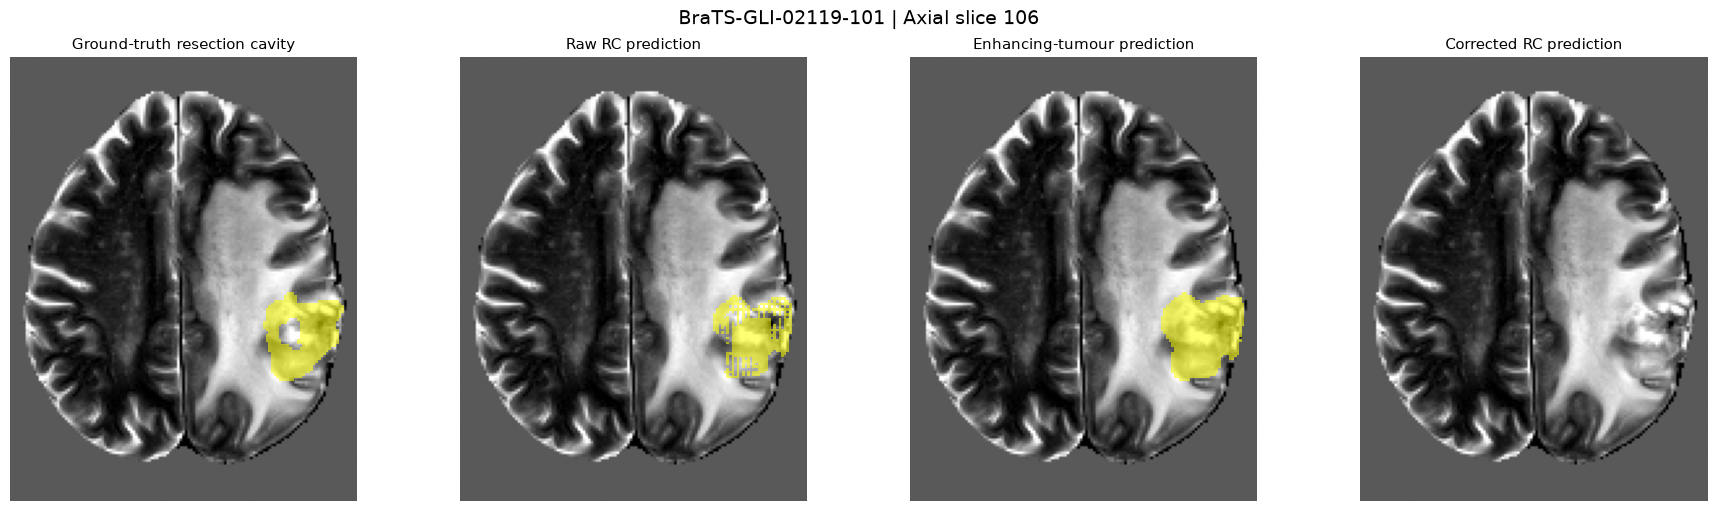

REPRODUCED WHOLE-VOLUME RC METRICS
Case: BraTS-GLI-02119-101
Axial slice: 106
Raw RC Dice: 0.534511
Corrected RC Dice: 0.004626

Predictions match the original held-out evaluation.
No model parameters or thresholds were changed.


In [98]:
# -------------------------------------------------------------
# CELL 194 — VISUALISE SEVERE RC POST-PROCESSING FAILURE
# -------------------------------------------------------------
#
# Reproduce predictions for one previously evaluated case.
#
# Compare:
#   1. Ground-truth resection cavity
#   2. Raw predicted resection cavity
#   3. Predicted enhancing tumour
#   4. Corrected predicted resection cavity
#
# The axial slice is selected by the largest ground-truth
# RC area, independently of prediction performance.
#
# No model training, tuning or file modifications.
# -------------------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt
import torch
from monai.inferers import sliding_window_inference

# STEP 1 — Preprocess the selected examination using
# the identical deterministic test pipeline.

failure_sample = held_out_test_dataset[
    next(
        index
        for index, case in enumerate(held_out_test_cases)
        if str(case["case_id"]) == worst_case_id
    )
]

failure_image = failure_sample["image"]
failure_label = failure_sample["label"]

# STEP 2 — Reproduce full-volume inference using
# the frozen checkpoint and settings.

final_test_model.eval()

with torch.inference_mode():

    failure_logits = sliding_window_inference(
        inputs=failure_image.unsqueeze(0).to(final_test_device),
        roi_size=(96, 96, 96),
        sw_batch_size=1,
        predictor=final_test_model,
        overlap=0.25,
    )

    failure_probabilities = (
        torch.sigmoid(failure_logits)
        .squeeze(0)
        .cpu()
        .numpy()
    )

# STEP 3 — Apply the two pre-specified methods.

failure_raw_prediction = failure_probabilities >= 0.5

failure_corrected_prediction = failure_raw_prediction.copy()

failure_corrected_prediction[3] = (
    failure_raw_prediction[3]
    & (
        ~failure_raw_prediction[2]
        | (
            failure_probabilities[3]
            >= failure_probabilities[2]
        )
    )
)

# STEP 4 — Select the axial slice with the largest
# ground-truth cavity area.
#
# MONAI Orientationd standardises the orientation to RAS.
# The final spatial axis therefore corresponds to the
# superior-inferior direction.

ground_truth_rc = failure_label[3].cpu().numpy() > 0

rc_voxels_per_slice = ground_truth_rc.sum(axis=(0, 1))

assert rc_voxels_per_slice.max() > 0

axial_slice = int(np.argmax(rc_voxels_per_slice))

# STEP 5 — Prepare a consistent T2-weighted background.
#
# Modality order is t1n, t1c, t2w, t2f.
# Index 2 therefore selects T2-weighted MRI.

t2_image = failure_image[2].cpu().numpy()

background = np.rot90(t2_image[:, :, axial_slice])

masks = [
    ground_truth_rc[:, :, axial_slice],
    failure_raw_prediction[3, :, :, axial_slice],
    failure_raw_prediction[2, :, :, axial_slice],
    failure_corrected_prediction[3, :, :, axial_slice],
]

panel_titles = [
    "Ground-truth resection cavity",
    "Raw RC prediction",
    "Enhancing-tumour prediction",
    "Corrected RC prediction",
]

# STEP 6 — Plot overlays with identical orientation
# and image intensity scaling.

fig, axes = plt.subplots(
    1, 4,
    figsize=(18, 5),
    constrained_layout=True,
)

vmin, vmax = np.percentile(
    background,
    [1, 99],
)

for axis, mask, panel_title in zip(
    axes, masks, panel_titles
):

    axis.imshow(
        background,
        cmap="gray",
        vmin=vmin,
        vmax=vmax,
    )

    rotated_mask = np.rot90(mask)

    overlay = np.ma.masked_where(
        ~rotated_mask,
        rotated_mask.astype(float),
    )

    axis.imshow(
        overlay,
        cmap="autumn",
        alpha=0.55,
        vmin=0,
        vmax=1,
        interpolation="nearest",
    )

    axis.set_title(panel_title, fontsize=11)
    axis.axis("off")

fig.suptitle(
    f"{worst_case_id} | Axial slice {axial_slice}",
    fontsize=14,
)

plt.show()

# STEP 7 — Verify reproduced whole-volume Dice scores
# against the previously saved test results.

def rc_dice_for_review(prediction, target):

    tp = np.count_nonzero(prediction & target)

    denominator = (
        np.count_nonzero(prediction)
        + np.count_nonzero(target)
    )

    return 2 * tp / denominator if denominator else np.nan

raw_review_dice = rc_dice_for_review(
    failure_raw_prediction[3],
    ground_truth_rc,
)

corrected_review_dice = rc_dice_for_review(
    failure_corrected_prediction[3],
    ground_truth_rc,
)

print("REPRODUCED WHOLE-VOLUME RC METRICS")
print("=" * 70)

print("Case:", worst_case_id)
print("Axial slice:", axial_slice)
print("Raw RC Dice:", round(raw_review_dice, 6))
print("Corrected RC Dice:", round(corrected_review_dice, 6))

assert np.isclose(
    raw_review_dice,
    worst_rc_case["dice_raw_baseline"],
    atol=1e-6,
)

assert np.isclose(
    corrected_review_dice,
    worst_rc_case["dice_relative_confidence_rc"],
    atol=1e-6,
)

print("\nPredictions match the original held-out evaluation.")
print("No model parameters or thresholds were changed.")

### Review of reference segmentation provided by BraTS
- resection cavity marked out in region with what appears to be soft tissue, possibly residual tumour VS recurrence
- will need to review other sequences

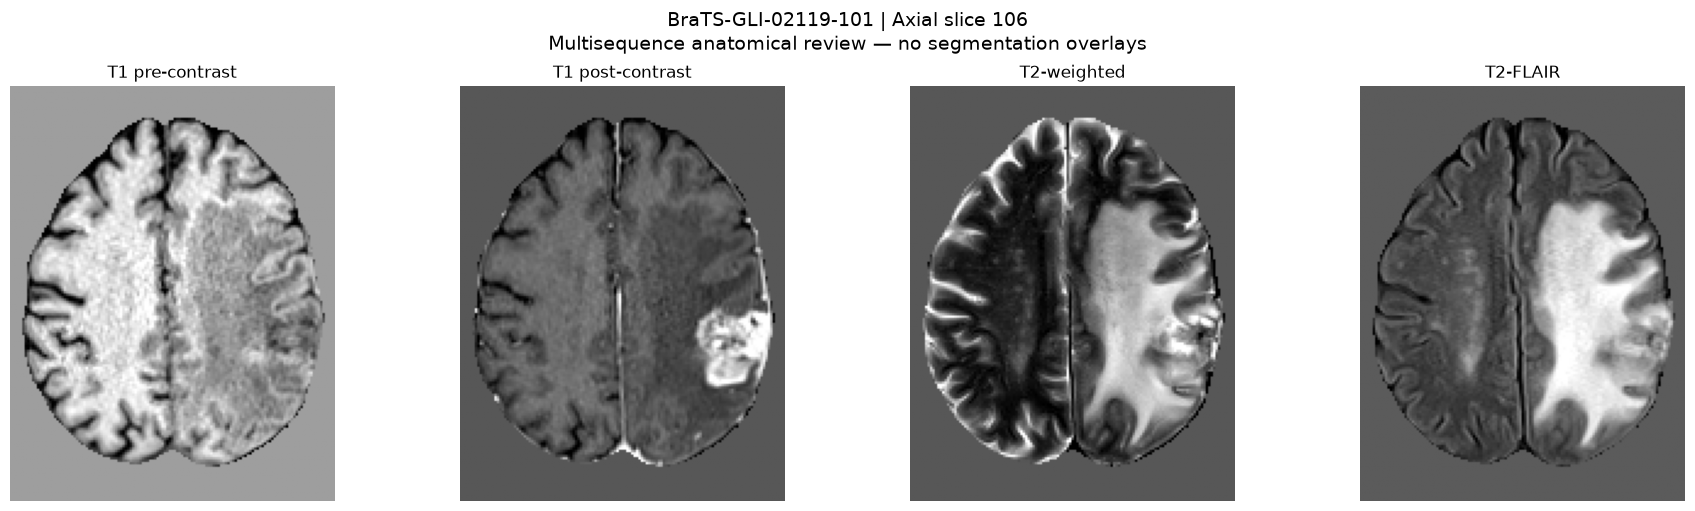

MULTISEQUENCE REVIEW READY
Examination: BraTS-GLI-02119-101
Axial slice: 106
Sequences: T1 pre-contrast, T1 post-contrast, T2-weighted, T2-FLAIR
No ground-truth or prediction overlays displayed.


In [99]:
# -------------------------------------------------------------
# CELL 195 — MULTISEQUENCE ANATOMICAL REVIEW
# -------------------------------------------------------------
#
# Display the four MRI sequences side by side:
#   1. T1 pre-contrast
#   2. T1 post-contrast
#   3. T2-weighted
#   4. T2-FLAIR
#
# Use the same axial slice for anatomical comparison.
#
# Deliberately exclude ground-truth and model overlays
# to allow an independent clinical interpretation.
#
# No GPU inference, training or file modifications.
# -------------------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt

# STEP 1 — Use the previously selected axial slice.

review_slice = axial_slice

# STEP 2 — Define the MRI sequences in their known order.

modality_names = [
    "T1 pre-contrast",
    "T1 post-contrast",
    "T2-weighted",
    "T2-FLAIR",
]

# STEP 3 — Display each sequence using its own
# intensity window, while keeping the anatomical
# orientation and slice position identical.

fig, axes = plt.subplots(
    1, 4,
    figsize=(18, 5),
    constrained_layout=True,
)

for modality_index, axis in enumerate(axes):

    volume = failure_image[
        modality_index
    ].cpu().numpy()

    image_slice = np.rot90(
        volume[:, :, review_slice]
    )

    # Use foreground voxels for display windowing
    # to reduce the influence of background padding.
    foreground_values = image_slice[
        np.isfinite(image_slice)
        & (image_slice != 0)
    ]

    if foreground_values.size > 0:
        vmin, vmax = np.percentile(
            foreground_values,
            [1, 99],
        )
    else:
        vmin, vmax = np.percentile(
            image_slice,
            [1, 99],
        )

    axis.imshow(
        image_slice,
        cmap="gray",
        vmin=vmin,
        vmax=vmax,
    )

    axis.set_title(
        modality_names[modality_index],
        fontsize=12,
    )

    axis.axis("off")

fig.suptitle(
    f"{worst_case_id} | Axial slice {review_slice}\n"
    "Multisequence anatomical review — no segmentation overlays",
    fontsize=14,
)

plt.show()

print("MULTISEQUENCE REVIEW READY")
print("=" * 70)
print("Examination:", worst_case_id)
print("Axial slice:", review_slice)
print("Sequences:", ", ".join(modality_names))
print("No ground-truth or prediction overlays displayed.")

### review of other sequences
- previously marked resection cavity represents contrast enhancing tissue - unlikely to be a true resection cavity
- if this was a resection cavity, it is unlikely to show any enhancement other than at the cavity walls

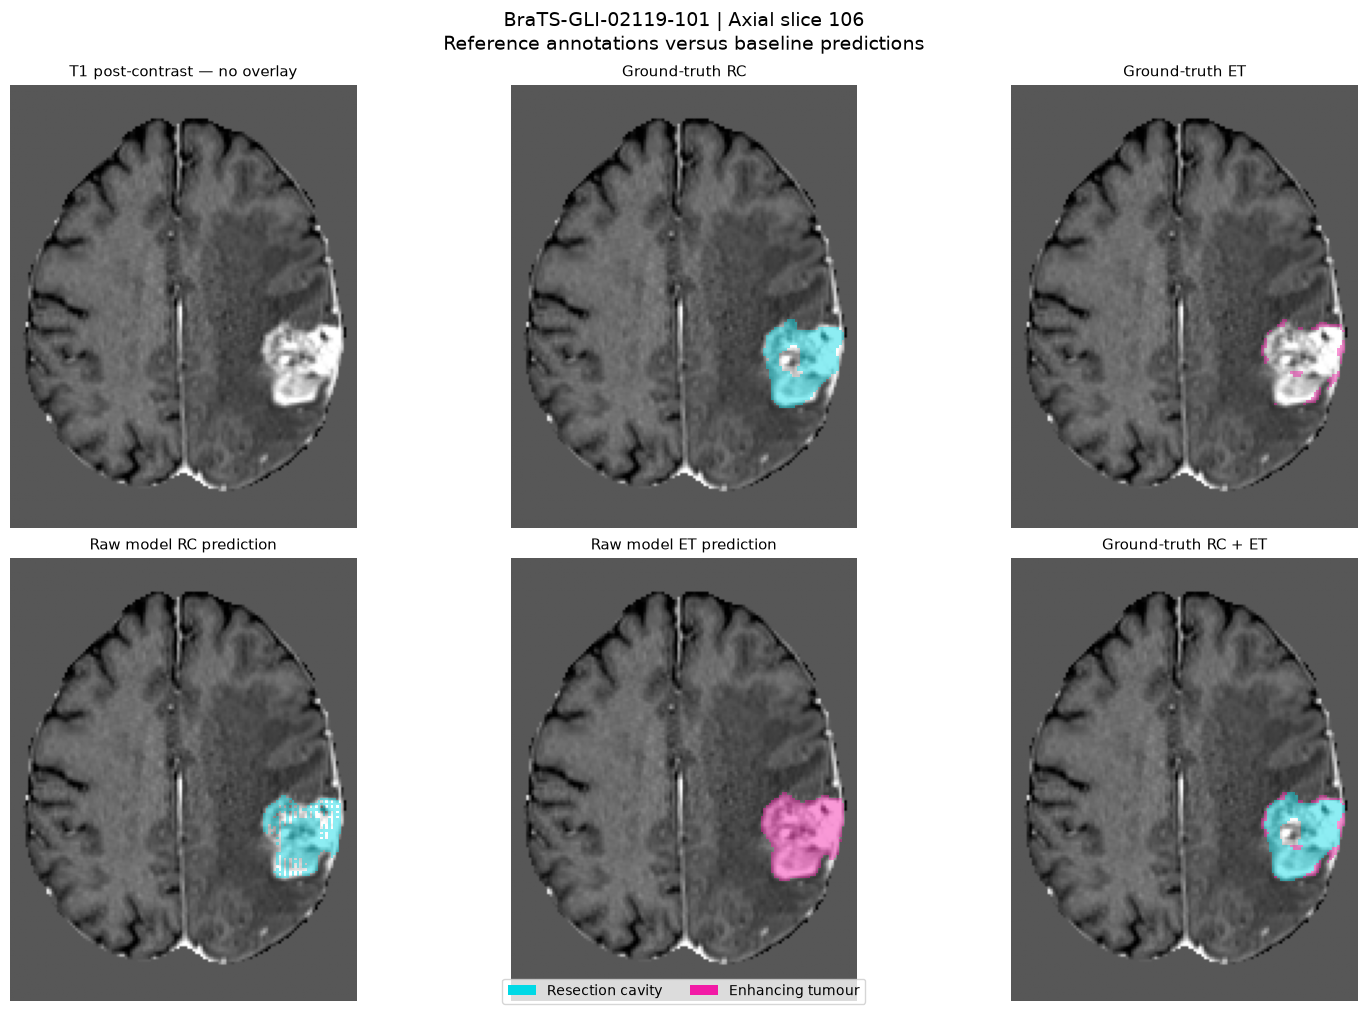

REFERENCE ANNOTATION REVIEW
Examination: BraTS-GLI-02119-101
Axial slice: 106
Ground-truth RC voxels on slice: 650
Ground-truth ET voxels on slice: 96
Raw predicted RC voxels on slice: 537
Raw predicted ET voxels on slice: 809
Ground-truth ET–RC overlap: 0

No reference annotations or predictions were modified.


In [100]:
# -------------------------------------------------------------
# CELL 196 — REVIEW RC AND ET ON CONTRAST-ENHANCED T1 MRI
# -------------------------------------------------------------
#
# Compare the official BraTS annotations against the
# baseline model's predictions.
#
# This is a qualitative anatomical review, not a
# modification of the test-set ground truth.
#
# Colours:
#   Cyan    = Resection cavity (RC)
#   Magenta = Enhancing tumour (ET)
#
# No additional GPU inference or training.
# -------------------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# STEP 1 — Retrieve the post-contrast T1 image.
#
# Modality order:
#   0 = T1 pre-contrast
#   1 = T1 post-contrast
#   2 = T2-weighted
#   3 = T2-FLAIR

review_slice = axial_slice

t1c_volume = failure_image[1].cpu().numpy()

t1c_slice = np.rot90(
    t1c_volume[:, :, review_slice]
)

# STEP 2 — Retrieve reference and prediction masks.
#
# Segmentation channel order:
#   0 = WT
#   1 = TC
#   2 = ET
#   3 = RC

ground_truth = failure_label.cpu().numpy() > 0

reference_rc = np.rot90(
    ground_truth[3, :, :, review_slice]
)

reference_et = np.rot90(
    ground_truth[2, :, :, review_slice]
)

predicted_rc = np.rot90(
    failure_raw_prediction[3, :, :, review_slice]
)

predicted_et = np.rot90(
    failure_raw_prediction[2, :, :, review_slice]
)

# STEP 3 — Set consistent display intensity limits.

foreground = t1c_slice[
    np.isfinite(t1c_slice)
    & (t1c_slice != 0)
]

vmin, vmax = np.percentile(
    foreground,
    [1, 99]
)

# STEP 4 — Define a reusable overlay function.

def show_segmentation_overlay(
    axis,
    image,
    masks,
    title,
):
    """
    Display a grayscale MRI with one or more
    transparent segmentation overlays.

    Each mask is supplied as:
        (binary_mask, colour)
    """

    axis.imshow(
        image,
        cmap="gray",
        vmin=vmin,
        vmax=vmax,
    )

    for mask, colour in masks:

        # RGBA overlay allows consistent colours
        # and transparency for each segmentation.
        overlay = np.zeros(
            (*mask.shape, 4),
            dtype=float,
        )

        overlay[..., :3] = colour
        overlay[..., 3] = mask.astype(float) * 0.45

        axis.imshow(
            overlay,
            interpolation="nearest",
        )

    axis.set_title(title, fontsize=11)
    axis.axis("off")


# STEP 5 — Prepare six panels.

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 10),
    constrained_layout=True,
)

cyan = (0.0, 0.85, 0.9)
magenta = (0.95, 0.1, 0.65)

panels = [
    (
        "T1 post-contrast — no overlay",
        [],
    ),
    (
        "Ground-truth RC",
        [(reference_rc, cyan)],
    ),
    (
        "Ground-truth ET",
        [(reference_et, magenta)],
    ),
    (
        "Raw model RC prediction",
        [(predicted_rc, cyan)],
    ),
    (
        "Raw model ET prediction",
        [(predicted_et, magenta)],
    ),
    (
        "Ground-truth RC + ET",
        [
            (reference_rc, cyan),
            (reference_et, magenta),
        ],
    ),
]

for axis, (title, masks) in zip(
    axes.flat,
    panels,
):
    show_segmentation_overlay(
        axis,
        t1c_slice,
        masks,
        title,
    )

# STEP 6 — Add a legend and examination information.

fig.legend(
    handles=[
        Patch(
            facecolor=cyan,
            label="Resection cavity",
        ),
        Patch(
            facecolor=magenta,
            label="Enhancing tumour",
        ),
    ],
    loc="lower center",
    ncol=2,
)

fig.suptitle(
    f"{worst_case_id} | Axial slice {review_slice}\n"
    "Reference annotations versus baseline predictions",
    fontsize=14,
)

plt.show()

# STEP 7 — Report reference-label voxel counts
# on this specific slice.

print("REFERENCE ANNOTATION REVIEW")
print("=" * 75)

print("Examination:", worst_case_id)
print("Axial slice:", review_slice)

print(
    "Ground-truth RC voxels on slice:",
    int(reference_rc.sum())
)

print(
    "Ground-truth ET voxels on slice:",
    int(reference_et.sum())
)

print(
    "Raw predicted RC voxels on slice:",
    int(predicted_rc.sum())
)

print(
    "Raw predicted ET voxels on slice:",
    int(predicted_et.sum())
)

print(
    "Ground-truth ET–RC overlap:",
    int(np.count_nonzero(reference_et & reference_rc))
)

print("\nNo reference annotations or predictions were modified.")

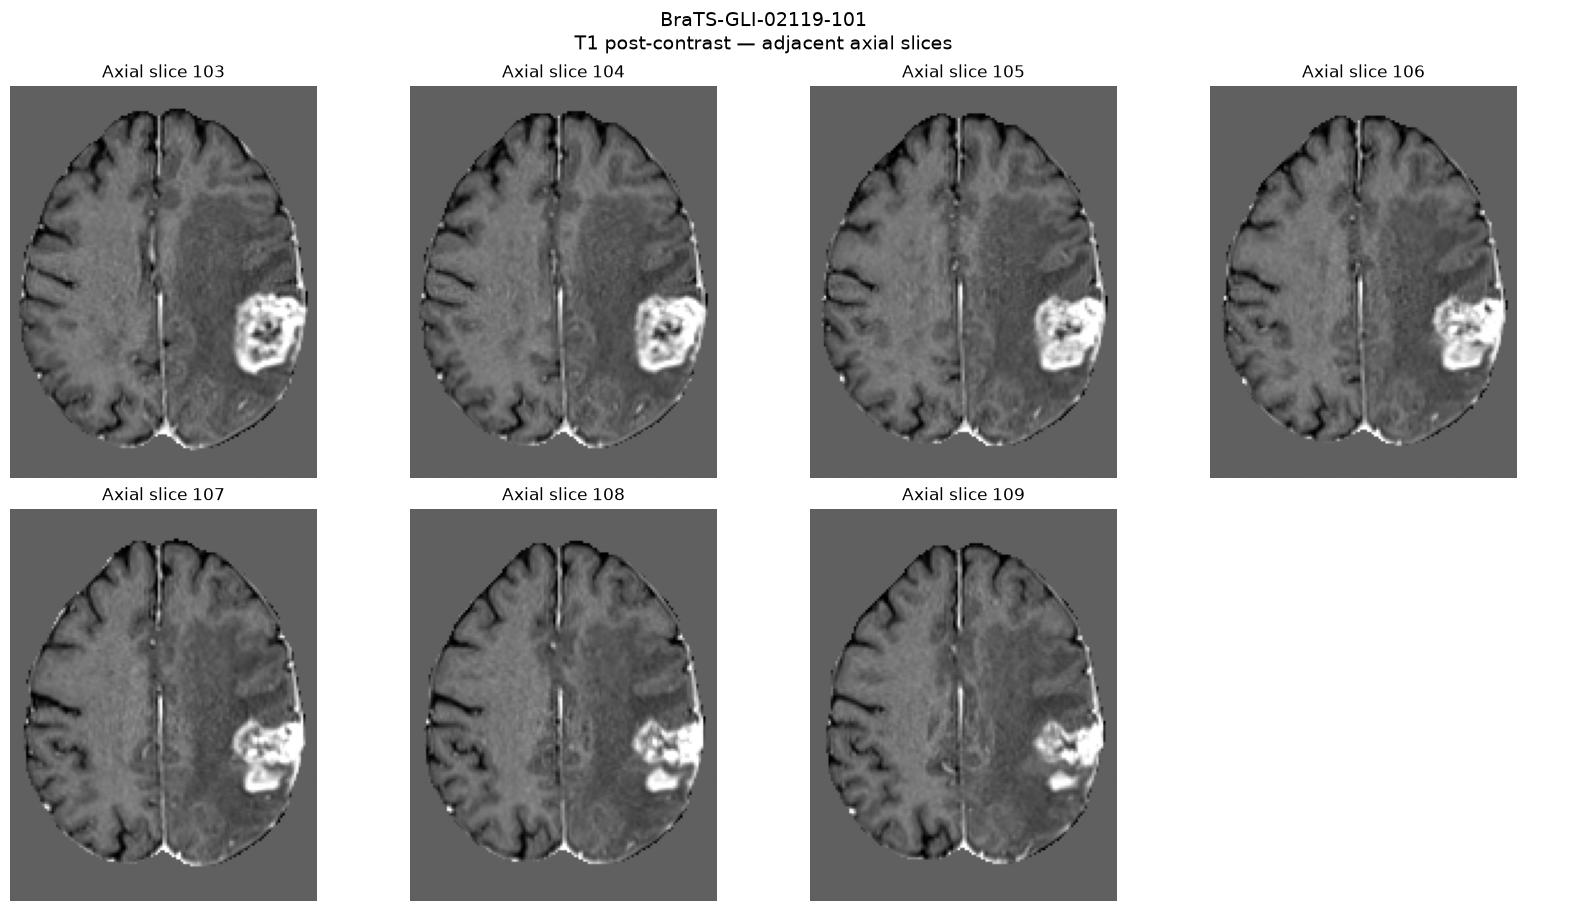

MULTISLICE ANATOMICAL REVIEW COMPLETE
Slices: [103, 104, 105, 106, 107, 108, 109]
No model inference or annotations modified.


In [101]:
# -------------------------------------------------------------
# CELL 197 — MULTISLICE POST-CONTRAST T1 REVIEW
# -------------------------------------------------------------
#
# Examine seven adjacent axial slices to distinguish
# peripheral cavity-wall enhancement from more extensive
# enhancing tissue.
#
# No segmentation overlays, additional inference,
# training or file modifications.
# -------------------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt

# STEP 1 — Retrieve the preprocessed T1 post-contrast MRI.

t1c_volume = failure_image[1].cpu().numpy()

# STEP 2 — Select three slices below and above slice 106.

centre_slice = axial_slice

slice_indices = [
    index
    for index in range(
        centre_slice - 3,
        centre_slice + 4,
    )
    if 0 <= index < t1c_volume.shape[2]
]

# STEP 3 — Use a common intensity window across slices.

foreground = t1c_volume[
    np.isfinite(t1c_volume)
    & (t1c_volume != 0)
]

vmin, vmax = np.percentile(
    foreground,
    [1, 99],
)

# STEP 4 — Display adjacent axial slices.

fig, axes = plt.subplots(
    2, 4,
    figsize=(16, 9),
    constrained_layout=True,
)

for axis, slice_index in zip(
    axes.flat,
    slice_indices,
):

    image_slice = np.rot90(
        t1c_volume[:, :, slice_index]
    )

    axis.imshow(
        image_slice,
        cmap="gray",
        vmin=vmin,
        vmax=vmax,
    )

    axis.set_title(
        f"Axial slice {slice_index}",
        fontsize=12,
    )

    axis.axis("off")

# Hide unused panels.

for axis in axes.flat[len(slice_indices):]:
    axis.axis("off")

fig.suptitle(
    f"{worst_case_id}\n"
    "T1 post-contrast — adjacent axial slices",
    fontsize=14,
)

plt.show()

print("MULTISLICE ANATOMICAL REVIEW COMPLETE")
print("Slices:", slice_indices)
print("No model inference or annotations modified.")

In [102]:
# -------------------------------------------------------------
# CELL 198 — QUANTIFY REFERENCE RC / PREDICTED ET CONFLICT
# -------------------------------------------------------------
#
# Investigate whether the model systematically assigns
# enhancing-tumour predictions to voxels annotated as
# resection cavity.
#
# This measures disagreement, not annotation correctness.
#
# No additional GPU inference or model modification.
# -------------------------------------------------------------

import numpy as np

# STEP 1 — Extract the ground-truth and model masks.

reference_rc_3d = (
    failure_label[3].cpu().numpy() > 0
)

reference_et_3d = (
    failure_label[2].cpu().numpy() > 0
)

predicted_rc_3d = failure_raw_prediction[3]
predicted_et_3d = failure_raw_prediction[2]

# STEP 2 — Identify voxels annotated as cavity
# but predicted as enhancing tumour.

rc_reference_et_prediction = (
    reference_rc_3d & predicted_et_3d
)

# STEP 3 — Quantify the disagreement.

reference_rc_count = int(reference_rc_3d.sum())

reference_et_count = int(reference_et_3d.sum())

conflicting_voxels = int(
    rc_reference_et_prediction.sum()
)

conflicting_fraction = (
    conflicting_voxels / reference_rc_count
    if reference_rc_count > 0
    else np.nan
)

# STEP 4 — Measure the confidence difference within
# the conflicting voxels.

et_probabilities = failure_probabilities[2]
rc_probabilities = failure_probabilities[3]

if conflicting_voxels > 0:

    mean_et_confidence = float(
        et_probabilities[
            rc_reference_et_prediction
        ].mean()
    )

    mean_rc_confidence = float(
        rc_probabilities[
            rc_reference_et_prediction
        ].mean()
    )

    et_priority_fraction = float(
        (
            et_probabilities[
                rc_reference_et_prediction
            ]
            >
            rc_probabilities[
                rc_reference_et_prediction
            ]
        ).mean()
    )

else:

    mean_et_confidence = np.nan
    mean_rc_confidence = np.nan
    et_priority_fraction = np.nan

# STEP 5 — Report the findings.

print("REFERENCE RC / PREDICTED ET DISAGREEMENT")
print("=" * 75)

print("Examination:", worst_case_id)

print(
    "Ground-truth RC voxels:",
    f"{reference_rc_count:,}"
)

print(
    "Ground-truth ET voxels:",
    f"{reference_et_count:,}"
)

print(
    "Reference RC voxels predicted as ET:",
    f"{conflicting_voxels:,}"
)

print(
    "Percentage of reference RC predicted as ET:",
    f"{100 * conflicting_fraction:.2f}%"
)

print("\nMODEL CONFIDENCE WITHIN DISAGREEMENT REGION")
print("=" * 75)

print(
    "Mean ET probability:",
    f"{mean_et_confidence:.4f}"
)

print(
    "Mean RC probability:",
    f"{mean_rc_confidence:.4f}"
)

print(
    "Fraction favouring ET over RC:",
    f"{100 * et_priority_fraction:.2f}%"
)

print("\nAnalysis complete.")
print("Reference labels and model predictions remain unchanged.")

REFERENCE RC / PREDICTED ET DISAGREEMENT
Examination: BraTS-GLI-02119-101
Ground-truth RC voxels: 15,600
Ground-truth ET voxels: 2,409
Reference RC voxels predicted as ET: 14,444
Percentage of reference RC predicted as ET: 92.59%

MODEL CONFIDENCE WITHIN DISAGREEMENT REGION
Mean ET probability: 0.9694
Mean RC probability: 0.4771
Fraction favouring ET over RC: 99.88%

Analysis complete.
Reference labels and model predictions remain unchanged.


In [103]:
# -------------------------------------------------------------
# CELL 198 — QUANTIFY REFERENCE RC / PREDICTED ET CONFLICT
# -------------------------------------------------------------
#
# Investigate whether the model systematically assigns
# enhancing-tumour predictions to voxels annotated as
# resection cavity.
#
# This measures disagreement, not annotation correctness.
#
# No additional GPU inference or model modification.
# -------------------------------------------------------------

import numpy as np

# STEP 1 — Extract the ground-truth and model masks.

reference_rc_3d = (
    failure_label[3].cpu().numpy() > 0
)

reference_et_3d = (
    failure_label[2].cpu().numpy() > 0
)

predicted_rc_3d = failure_raw_prediction[3]
predicted_et_3d = failure_raw_prediction[2]

# STEP 2 — Identify voxels annotated as cavity
# but predicted as enhancing tumour.

rc_reference_et_prediction = (
    reference_rc_3d & predicted_et_3d
)

# STEP 3 — Quantify the disagreement.

reference_rc_count = int(reference_rc_3d.sum())

reference_et_count = int(reference_et_3d.sum())

conflicting_voxels = int(
    rc_reference_et_prediction.sum()
)

conflicting_fraction = (
    conflicting_voxels / reference_rc_count
    if reference_rc_count > 0
    else np.nan
)

# STEP 4 — Measure the confidence difference within
# the conflicting voxels.

et_probabilities = failure_probabilities[2]
rc_probabilities = failure_probabilities[3]

if conflicting_voxels > 0:

    mean_et_confidence = float(
        et_probabilities[
            rc_reference_et_prediction
        ].mean()
    )

    mean_rc_confidence = float(
        rc_probabilities[
            rc_reference_et_prediction
        ].mean()
    )

    et_priority_fraction = float(
        (
            et_probabilities[
                rc_reference_et_prediction
            ]
            >
            rc_probabilities[
                rc_reference_et_prediction
            ]
        ).mean()
    )

else:

    mean_et_confidence = np.nan
    mean_rc_confidence = np.nan
    et_priority_fraction = np.nan

# STEP 5 — Report the findings.

print("REFERENCE RC / PREDICTED ET DISAGREEMENT")
print("=" * 75)

print("Examination:", worst_case_id)

print(
    "Ground-truth RC voxels:",
    f"{reference_rc_count:,}"
)

print(
    "Ground-truth ET voxels:",
    f"{reference_et_count:,}"
)

print(
    "Reference RC voxels predicted as ET:",
    f"{conflicting_voxels:,}"
)

print(
    "Percentage of reference RC predicted as ET:",
    f"{100 * conflicting_fraction:.2f}%"
)

print("\nMODEL CONFIDENCE WITHIN DISAGREEMENT REGION")
print("=" * 75)

print(
    "Mean ET probability:",
    f"{mean_et_confidence:.4f}"
)

print(
    "Mean RC probability:",
    f"{mean_rc_confidence:.4f}"
)

print(
    "Fraction favouring ET over RC:",
    f"{100 * et_priority_fraction:.2f}%"
)

print("\nAnalysis complete.")
print("Reference labels and model predictions remain unchanged.")

REFERENCE RC / PREDICTED ET DISAGREEMENT
Examination: BraTS-GLI-02119-101
Ground-truth RC voxels: 15,600
Ground-truth ET voxels: 2,409
Reference RC voxels predicted as ET: 14,444
Percentage of reference RC predicted as ET: 92.59%

MODEL CONFIDENCE WITHIN DISAGREEMENT REGION
Mean ET probability: 0.9694
Mean RC probability: 0.4771
Fraction favouring ET over RC: 99.88%

Analysis complete.
Reference labels and model predictions remain unchanged.
